# Domestic Violence in South Asia: DHS Data Audit and Professional EDA

**Kaggle-ready | reproducible | weighted | memory-safe**

This notebook audits the complete structure of every supplied DHS archive and scans all records in chunks. It separates what these files can support from what they cannot.

> **Substantive finding before analysis:** the supplied archives are Household Recode (`HR`) and Household Member Recode (`PR`) files. They contain household selection variable `HV044`, but they do **not** contain individual women’s domestic-violence responses or the domestic-violence weight. Consequently, these files cannot estimate domestic-violence prevalence. Reporting `HV044` as violence would be a serious measurement error.

The notebook therefore has two tracks:

1. A complete schema/suitability audit and professional weighted EDA of the household and population context actually present.
2. A guarded domestic-violence module that activates only if appropriate Individual Recode (`IR`) archives are added to `/kaggle/input/`.

All estimates are descriptive. Cross-country comparisons should account for survey year, questionnaire differences, eligibility, nonresponse, and complex survey design.

## Research questions and analytical standard

- What files, record types, years, countries, variables, and sample sizes are available?
- Are domestic-violence outcomes and the correct DV weight available?
- What are the weighted household and population characteristics by country?
- How complete and internally consistent are the core variables?
- If `IR` data are supplied, what are weighted ever/past-year emotional, physical, sexual, and any spousal-violence estimates?

**Ethics:** Domestic violence is sensitive. Use only de-identified public-use data, never attempt re-identification, suppress unstable small cells, avoid victim-blaming interpretations, and follow the DHS terms of use. This notebook does not expose household IDs in outputs.

In [1]:
# ================================================================================================
# RECODE SOURCE
#   * No recode file is read here (configuration / library setup only)
#   * Declares the /kaggle/input paths for all HR, PR and IR packages used later
# WHAT THIS CELL USES: no survey variables; only paths, seeds and display options
# (Annotation added only - every original line of this cell is kept unchanged.)
# ================================================================================================

# 1. Imports and reproducibility
from pathlib import Path
from zipfile import ZipFile, is_zipfile
from io import TextIOWrapper
from contextlib import contextmanager
import re, warnings, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 120)
sns.set_theme(style="whitegrid", context="notebook")
PALETTE = sns.color_palette("colorblind")
RANDOM_SEED = 42

# Exact Kaggle dataset paths supplied for this project.
KAGGLE_DATASET_ROOT = Path("/kaggle/input/datasets/maomislive/dhs-domestic-violence-in-south-asian-countries")
KAGGLE_INPUT_PATHS = [
    KAGGLE_DATASET_ROOT / "IAIR7EFL",
    KAGGLE_DATASET_ROOT / "MMIR71FL",
    KAGGLE_DATASET_ROOT / "DHS HM-H Recode",
    KAGGLE_DATASET_ROOT / "NPIR82FL",
    KAGGLE_DATASET_ROOT / "PKIR71FL",
    KAGGLE_DATASET_ROOT / "LKIR02FL",
    KAGGLE_DATASET_ROOT / "AFIR71FL",
    KAGGLE_DATASET_ROOT / "BDIR81FL",
]

# Local fallback only makes the same notebook testable outside Kaggle; Kaggle always takes precedence.
LOCAL_FALLBACK = Path("upload")
DATA_ROOT = KAGGLE_DATASET_ROOT if KAGGLE_DATASET_ROOT.exists() else LOCAL_FALLBACK
REQUESTED_DATA_PATHS = KAGGLE_INPUT_PATHS if KAGGLE_DATASET_ROOT.exists() else [LOCAL_FALLBACK]

# True = scan every record in every supplied DAT file, in memory-safe chunks.
RUN_FULL_SCAN = True
CHUNK_SIZE = 150_000
MIN_UNWEIGHTED_CELL = 25

print(f"Data root: {DATA_ROOT.resolve()}")
print("Configured data paths:")
for p in REQUESTED_DATA_PATHS:
    print(" -", p)
print(f"Full-record scan: {RUN_FULL_SCAN:,} | chunk size: {CHUNK_SIZE:,}")

Data root: /kaggle/input/datasets/maomislive/dhs-domestic-violence-in-south-asian-countries
Configured data paths:
 - /kaggle/input/datasets/maomislive/dhs-domestic-violence-in-south-asian-countries/IAIR7EFL
 - /kaggle/input/datasets/maomislive/dhs-domestic-violence-in-south-asian-countries/MMIR71FL
 - /kaggle/input/datasets/maomislive/dhs-domestic-violence-in-south-asian-countries/DHS HM-H Recode
 - /kaggle/input/datasets/maomislive/dhs-domestic-violence-in-south-asian-countries/NPIR82FL
 - /kaggle/input/datasets/maomislive/dhs-domestic-violence-in-south-asian-countries/PKIR71FL
 - /kaggle/input/datasets/maomislive/dhs-domestic-violence-in-south-asian-countries/LKIR02FL
 - /kaggle/input/datasets/maomislive/dhs-domestic-violence-in-south-asian-countries/AFIR71FL
 - /kaggle/input/datasets/maomislive/dhs-domestic-violence-in-south-asian-countries/BDIR81FL
Full-record scan: 1 | chunk size: 150,000


## 2. File discovery and archive inventory

The exact Kaggle dataset root and eight supplied subpaths are configured above. The loader accepts either DHS ZIP packages or Kaggle-extracted folders containing matching `.DAT`, `.SAS`, and `.FRQ` files. The expected archives are listed explicitly so missing or duplicate uploads are visible.

In [2]:
# ================================================================================================
# RECODE SOURCE
#   * Household Recode (HR)  - XXHRnnFL - one record per HOUSEHOLD  (AFHR71FL, BDHR81FL, ... inside 'DHS HM-H Recode')
#   * Household Member Recode (PR) - XXPRnnFL - one record per LISTED HOUSEHOLD MEMBER  (IAPR7EFL, MMPR71FL, NPPR82FL, PKPR71FL, ...)
#   * Individual Recode (IR) - XXIRnnFL - one record per INTERVIEWED WOMAN 15-49  (AFIR71FL, BDIR81FL, IAIR7EFL, LKIR02FL, MMIR71FL, NPIR82FL, PKIR71FL)
# WHAT THIS CELL USES: file names only (.DAT/.SAS/.FRQ); the recode type is taken from characters 3-4 of the stem
# NOTE: the 'recode' column is what every later section switches on: HR / PR / IR
# (Annotation added only - every original line of this cell is kept unchanged.)
# ================================================================================================

EXPECTED = {
    "AFHR71FL": {"country": "Afghanistan", "survey": "2015", "recode": "HR"},
    "BDHR81FL": {"country": "Bangladesh",  "survey": "2022", "recode": "HR"},
    "IAPR7EFL": {"country": "India",       "survey": "2019–21", "recode": "PR"},
    "MMPR71FL": {"country": "Myanmar",     "survey": "2015–16", "recode": "PR"},
    "NPPR82FL": {"country": "Nepal",       "survey": "2022", "recode": "PR"},
    "PKPR71FL": {"country": "Pakistan",    "survey": "2017–18", "recode": "PR"},
}
COUNTRY_CODE = {
    "AF": "Afghanistan", "BD": "Bangladesh", "IA": "India",
    "MM": "Myanmar", "NP": "Nepal", "PK": "Pakistan", "LK": "Sri Lanka",
}
SURVEY_BY_CODE = {stem[:2]: meta["survey"] for stem, meta in EXPECTED.items()}

def archive_stem(path):
    return path.stem.upper()

def discover_data_packages(configured_paths):
    # Return ZIP packages or SAS layout files representing extracted DHS packages.
    candidates = []
    for configured in configured_paths:
        if configured.is_file():
            if is_zipfile(configured):
                candidates.append(configured)
            elif configured.suffix.upper() == ".SAS":
                candidates.append(configured)
        elif configured.is_dir():
            candidates.extend(sorted(
                p for p in configured.rglob("*")
                if p.is_file() and p.suffix.lower() == ".zip" and is_zipfile(p)
            ))
            for sas_path in sorted(configured.rglob("*")):
                if not sas_path.is_file() or sas_path.suffix.upper() != ".SAS":
                    continue
                has_dat = any(
                    p.is_file() and p.stem.upper() == sas_path.stem.upper() and p.suffix.upper() == ".DAT"
                    for p in sas_path.parent.iterdir()
                )
                if has_dat:
                    candidates.append(sas_path)
    # Prefer a ZIP if the same DHS package is present both zipped and extracted.
    by_stem = {}
    for source in candidates:
        stem = archive_stem(source)
        if stem not in by_stem or is_zipfile(source):
            by_stem[stem] = source
    return sorted(by_stem.values(), key=lambda p: archive_stem(p))

zip_paths = discover_data_packages(REQUESTED_DATA_PATHS)
if not zip_paths:
    raise FileNotFoundError(
        "No DHS ZIP packages or extracted DAT/SAS packages were found in the configured Kaggle paths."
    )

def package_member_names(source):
    if is_zipfile(source):
        with ZipFile(source) as z:
            return z.namelist()
    return [p.name for p in source.parent.iterdir() if p.is_file() and p.stem.upper() == source.stem.upper()]

def package_member_name(source, suffix):
    return next((n for n in package_member_names(source) if n.upper().endswith(suffix.upper())), None)

def direct_member_path(source, member_name_value):
    return next(p for p in source.parent.iterdir() if p.is_file() and p.name.upper() == Path(member_name_value).name.upper())

def package_member_size(source, member_name_value):
    if is_zipfile(source):
        with ZipFile(source) as z:
            return z.getinfo(member_name_value).file_size
    return direct_member_path(source, member_name_value).stat().st_size

@contextmanager
def open_package_member(source, member_name_value):
    if is_zipfile(source):
        with ZipFile(source) as z:
            with z.open(member_name_value) as fh:
                yield fh
    else:
        with direct_member_path(source, member_name_value).open("rb") as fh:
            yield fh

def read_package_member(source, member_name_value):
    with open_package_member(source, member_name_value) as fh:
        return fh.read()

rows = []
for zp in zip_paths:
    stem = archive_stem(zp)
    names = package_member_names(zp)
    dat = next((n for n in names if n.upper().endswith(".DAT")), None)
    sas = next((n for n in names if n.upper().endswith(".SAS")), None)
    frq = next((n for n in names if n.upper().endswith(".FRQ")), None)
    dat_bytes = package_member_size(zp, dat) if dat else np.nan
    meta = EXPECTED.get(stem, {})
    rows.append({
        "archive": zp.name if is_zipfile(zp) else stem, "stem": stem, "country": meta.get("country", COUNTRY_CODE.get(stem[:2], "Unknown")),
        "survey": meta.get("survey", SURVEY_BY_CODE.get(stem[:2], "Check survey documentation")),
        "recode": meta.get("recode", stem[2:4] if len(stem) >= 4 else "?"),
        "DAT_GB": dat_bytes / 1e9 if pd.notna(dat_bytes) else np.nan,
        "has_DAT": bool(dat), "has_SAS": bool(sas), "has_FRQ": bool(frq), "path": str(zp),
    })

inventory = pd.DataFrame(rows)
display(inventory.drop(columns="path").style.format({"DAT_GB": "{:.3f}"}))

missing_expected = sorted(set(EXPECTED) - set(inventory.stem))
if missing_expected:
    print("Expected but not found:", missing_expected)

,archive,stem,country,survey,recode,DAT_GB,has_DAT,has_SAS,has_FRQ
0,AFHR71FL,AFHR71FL,Afghanistan,2015,HR,0.093,True,True,True
1,AFIR71FL,AFIR71FL,Afghanistan,2015,IR,0.256,True,True,True
2,AFPR71FL,AFPR71FL,Afghanistan,2015,PR,0.137,True,True,True
3,BDHR81FL,BDHR81FL,Bangladesh,2022,HR,0.082,True,True,True
4,BDIR81FL,BDIR81FL,Bangladesh,2022,IR,0.256,True,True,True
5,BDPR81FL,BDPR81FL,Bangladesh,2022,PR,0.064,True,True,True
6,IAHR7EFL,IAHR7EFL,India,2019–21,HR,7.396,True,True,True
7,IAIR7EFL,IAIR7EFL,India,2019–21,IR,6.827,True,True,True
8,IAPR7EFL,IAPR7EFL,India,2019–21,PR,2.986,True,True,True
9,LKIR02FL,LKIR02FL,Sri Lanka,Check survey documentation,IR,0.014,True,True,True


## 3. Read the complete dataset structures

Each archive contains a SAS import program with every fixed-width field's name, position, width, type, format, and label. The parser below reads **all** variable definitions, rather than guessing column positions or loading a partial CSV export. It also reads the frequency-report header to recover the official unweighted record count where available.

In [3]:
# ================================================================================================
# RECODE SOURCE
#   * Household Recode (HR)  - XXHRnnFL - one record per HOUSEHOLD - schema only
#   * Household Member Recode (PR) - XXPRnnFL - one record per LISTED HOUSEHOLD MEMBER - schema only
#   * Individual Recode (IR) - XXIRnnFL - one record per INTERVIEWED WOMAN 15-49 - schema only
# WHAT THIS CELL USES: the SAS layout (@position name width) and the .FRQ record count of EVERY package
# NOTE: no data rows are read here, so this cell is cheap for all three recode types
# (Annotation added only - every original line of this cell is kept unchanged.)
# ================================================================================================

INPUT_RE = re.compile(r"^\s*@(?P<start>\d+)\s+(?P<name>[A-Za-z][A-Za-z0-9_]*)\s+(?P<char>\$?)(?P<width>\d+)\.(?P<dec>\d*)", re.M)
LABEL_RE = re.compile(r'\battrib\s+(?P<name>[A-Za-z][A-Za-z0-9_]*)\b[^;]*?label="(?P<label>[^"]*)"', re.I | re.S)
LRECL_RE = re.compile(r"\bLRECL\s*=\s*(\d+)", re.I)
RECORDS_RE = re.compile(r"([\d,]+)\s+Records Read", re.I)
TOTAL_RE = re.compile(r"^\s*TOTAL\s+([\d,]+)\s+", re.I | re.M)
LEVEL1_RE = re.compile(r"\|\s*1\s*\|\s*([\d,]+)\s*\|", re.I)

def member_name(source, suffix):
    return package_member_name(source, suffix)

def decode_bytes(raw):
    for enc in ("utf-8", "cp1252", "latin-1"):
        try:
            return raw.decode(enc)
        except UnicodeDecodeError:
            pass
    return raw.decode("latin-1", errors="replace")

def parse_archive_schema(zip_path):
    sas_name = member_name(zip_path, ".SAS")
    if not sas_name:
        raise ValueError(f"No SAS layout file in {zip_path.name}")
    sas_text = decode_bytes(read_package_member(zip_path, sas_name))
    labels = {m.group("name").upper(): m.group("label") for m in LABEL_RE.finditer(sas_text)}
    specs = []
    for m in INPUT_RE.finditer(sas_text):
        name = m.group("name").upper()
        start = int(m.group("start")) - 1  # SAS is 1-based; pandas colspec is 0-based
        width = int(m.group("width"))
        specs.append({
            "name": name, "start": start, "end": start + width, "width": width,
            "decimals": int(m.group("dec") or 0), "type": "string" if m.group("char") else "numeric",
            "label": labels.get(name, ""),
        })
    lrecl = int(LRECL_RE.search(sas_text).group(1)) if LRECL_RE.search(sas_text) else None
    frq_name = member_name(zip_path, ".FRQ")
    records = None
    if frq_name:
        # Only the small report header is needed for the official count.
        with open_package_member(zip_path, frq_name) as fh:
            head = decode_bytes(fh.read(80_000))
        # The first item-frequency TOTAL equals rows in the flat export. For HR files,
        # CSPro's overall "Records Read" can include lower-level source records and is not comparable.
        mm = TOTAL_RE.search(head) or RECORDS_RE.search(head)
        records = int(mm.group(1).replace(",", "")) if mm else None
    return pd.DataFrame(specs), lrecl, records

schemas, structure_rows = {}, []
for _, row in inventory.iterrows():
    schema, lrecl, n_records = parse_archive_schema(Path(row.path))
    schemas[row.stem] = schema
    structure_rows.append({
        "stem": row.stem, "country": row.country, "recode": row.recode,
        "variables": len(schema), "record_length": lrecl,
        "official_unweighted_records": n_records,
        "string_fields": int((schema.type == "string").sum()),
        "numeric_fields": int((schema.type == "numeric").sum()),
    })

structure_summary = pd.DataFrame(structure_rows)
display(structure_summary.style.format({"official_unweighted_records": "{:,.0f}"}))
assert all(len(s) > 0 for s in schemas.values()), "At least one schema could not be parsed."

,stem,country,recode,variables,record_length,official_unweighted_records,string_fields,numeric_fields
0,AFHR71FL,Afghanistan,HR,3206,4716.000000,"24,395",52,3154
1,AFIR71FL,Afghanistan,IR,5176,8802.000000,"29,461",11,5165
2,AFPR71FL,Afghanistan,PR,336,688.000000,"203,708",4,332
3,BDHR81FL,Bangladesh,HR,3751,7284.000000,"30,018",19,3732
4,BDIR81FL,Bangladesh,IR,5425,8712.000000,"30,078",4,5421
5,BDPR81FL,Bangladesh,PR,549,1134.000000,"132,463",4,545
6,IAHR7EFL,India,HR,6482,12416.000000,"636,699",72,6410
7,IAIR7EFL,India,IR,5972,9637.000000,"724,115",9,5963
8,IAPR7EFL,India,PR,530,1071.000000,"2,843,917",5,525
9,LKIR02FL,Sri Lanka,IR,1393,nan,nan,2,1391


In [4]:
# ================================================================================================
# RECODE SOURCE
#   * Household Recode (HR)  - XXHRnnFL - one record per HOUSEHOLD, Household Member Recode (PR) - XXPRnnFL - one record per LISTED HOUSEHOLD MEMBER, Individual Recode (IR) - XXIRnnFL - one record per INTERVIEWED WOMAN 15-49 - pooled data dictionary
# WHAT THIS CELL USES: all field definitions from all recodes, written to complete_data_dictionary.csv
# (Annotation added only - every original line of this cell is kept unchanged.)
# ================================================================================================

# Searchable complete data dictionary (all fields from all supplied archives)
full_dictionary = pd.concat(
    [df.assign(stem=stem, country=EXPECTED.get(stem, {}).get("country", COUNTRY_CODE.get(stem[:2], "Unknown")), recode=EXPECTED.get(stem, {}).get("recode", stem[2:4]))
     for stem, df in schemas.items()], ignore_index=True
)[["country", "stem", "recode", "name", "label", "type", "start", "end", "width", "decimals"]]

print(f"Total field definitions across archives: {len(full_dictionary):,}")
display(full_dictionary.head(20))

# Export useful audit tables into the Kaggle working directory.
OUTPUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
full_dictionary.to_csv(OUTPUT_DIR / "complete_data_dictionary.csv", index=False)
structure_summary.to_csv(OUTPUT_DIR / "dataset_structure_summary.csv", index=False)
print("Saved:", OUTPUT_DIR / "complete_data_dictionary.csv")

Total field definitions across archives: 60,236


,country,stem,recode,name,label,type,start,end,width,decimals
0,Afghanistan,AFHR71FL,HR,HHID,Case Identification,string,0,12,12,0
1,Afghanistan,AFHR71FL,HR,HV000,Country code and phase,string,12,15,3,0
2,Afghanistan,AFHR71FL,HR,HV001,Cluster number,numeric,15,21,6,0
3,Afghanistan,AFHR71FL,HR,HV002,Household number,numeric,21,27,6,0
4,Afghanistan,AFHR71FL,HR,HV003,Respondent's line number (answering Household ...,numeric,27,30,3,0
5,Afghanistan,AFHR71FL,HR,HV004,Ultimate area unit,numeric,30,34,4,0
6,Afghanistan,AFHR71FL,HR,HV005,Household sample weight (6 decimals),numeric,34,42,8,0
7,Afghanistan,AFHR71FL,HR,HV006,Month of interview,numeric,42,44,2,0
8,Afghanistan,AFHR71FL,HR,HV007,Year of interview,numeric,44,48,4,0
9,Afghanistan,AFHR71FL,HR,HV008,Date of interview (CMC),numeric,48,52,4,0


Saved: /kaggle/working/complete_data_dictionary.csv


## 4. Domestic-violence suitability audit

`HR` means one record per household; `PR` means one record per listed household member. A valid DHS spousal-violence analysis normally requires an eligible respondent from an `IR` file, domestic-violence item variables (commonly `D...`), and the special DV weight (`D005`). `HV044` only indicates household selection for the module; it is **not** an experience of violence.

In [5]:
# ================================================================================================
# RECODE SOURCE
#   * Household Recode (HR)  - XXHRnnFL - one record per HOUSEHOLD - checks for HV044 only
#   * Household Member Recode (PR) - XXPRnnFL - one record per LISTED HOUSEHOLD MEMBER - checks for HV044 only
#   * Individual Recode (IR) - XXIRnnFL - one record per INTERVIEWED WOMAN 15-49 - checks for D005 and D1xx domestic-violence items
# WHAT THIS CELL USES: variable NAMES and LABELS only; HV044 is a household selection flag, never an outcome
# (Annotation added only - every original line of this cell is kept unchanged.)
# ================================================================================================

DV_NAME_RE = re.compile(r"^(?:D0|D1|D2|D3|D4|D5|D6|D7|D8|D9|D005)", re.I)
DV_LABEL_RE = re.compile(r"domestic violence|spousal violence|husband.*(?:slap|push|kick|force|threat)|forced sex|sexual violence|emotional violence", re.I)

audit_rows = []
for _, row in inventory.iterrows():
    s = schemas[row.stem]
    names = set(s.name)
    outcome_candidates = s[s.name.str.match(DV_NAME_RE) | s.label.str.contains(DV_LABEL_RE, na=False)]
    # HV044 is intentionally excluded from outcome candidates.
    outcome_candidates = outcome_candidates[outcome_candidates.name != "HV044"]
    audit_rows.append({
        "country": row.country, "archive": row.archive, "recode": row.recode,
        "has_HV044_selection_only": "HV044" in names,
        "has_D005_DV_weight": "D005" in names,
        "candidate_DV_response_fields": len(outcome_candidates),
        "valid_for_DV_prevalence": row.recode == "IR" and "D005" in names and len(outcome_candidates) > 0,
    })

suitability = pd.DataFrame(audit_rows)
display(suitability)

if not suitability.valid_for_DV_prevalence.any():
    display(Markdown(
        "### Suitability conclusion: DV prevalence is not estimable from the supplied files\n"
        "All downstream plots in the first track describe household/population context only. "
        "They must not be labeled as domestic-violence prevalence. Add the matching DHS `IR` ZIP files "
        "to activate the guarded violence-analysis section."
    ))

,country,archive,recode,has_HV044_selection_only,has_D005_DV_weight,candidate_DV_response_fields,valid_for_DV_prevalence
0,Afghanistan,AFHR71FL,HR,True,False,0,False
1,Afghanistan,AFIR71FL,IR,False,True,174,True
2,Afghanistan,AFPR71FL,PR,True,False,0,False
3,Bangladesh,BDHR81FL,HR,True,False,0,False
4,Bangladesh,BDIR81FL,IR,False,False,1,False
5,Bangladesh,BDPR81FL,PR,True,False,0,False
6,India,IAHR7EFL,HR,True,False,0,False
7,India,IAIR7EFL,IR,False,True,178,True
8,India,IAPR7EFL,PR,True,False,0,False
9,Sri Lanka,LKIR02FL,IR,False,False,0,False


## 5. Memory-safe full-record reader

The India person file contains millions of records. Loading every field at once can exceed Kaggle RAM. The reader below still scans **every row**, but reads only the analysis fields and aggregates in chunks. This is statistically complete, not a sample. Set `RUN_FULL_SCAN=False` only for a quick code test.

In [6]:
# ================================================================================================
# RECODE SOURCE
#   * Household Recode (HR)  - XXHRnnFL - one record per HOUSEHOLD - COMMON_HH list (HV0xx household variables)
#   * Household Member Recode (PR) - XXPRnnFL - one record per LISTED HOUSEHOLD MEMBER - COMMON_PERSON list (HV1xx member variables) + repeated HV0xx household variables
# WHAT THIS CELL USES: COMMON_HH: HHID HV001 HV002 HV005 HV009 HV010 HV012 HV013 HV024 HV025 HV026 HV044 HV270; COMMON_PERSON: HVIDX HV101 HV102 HV103 HV104 HV105 HV106 HV109 HV115 HV117
# NOTE: the same reader (iter_fwf) is reused for IR files in the added sections 15-22
# (Annotation added only - every original line of this cell is kept unchanged.)
# ================================================================================================

def iter_fwf(zip_path, schema, columns, chunksize=CHUNK_SIZE, nrows=None):
    # Yield fixed-width chunks directly from a ZIP using its parsed SAS layout.
    wanted = [c.upper() for c in columns if c.upper() in set(schema.name)]
    sub = schema.set_index("name").loc[wanted].reset_index()
    if sub.empty:
        return
    colspecs = list(zip(sub.start.astype(int), sub.end.astype(int)))
    names = sub.name.tolist()
    str_cols = set(sub.loc[sub.type.eq("string"), "name"])
    dat_name = member_name(zip_path, ".DAT")
    if not dat_name:
        raise ValueError(f"No DAT file in {zip_path.name}")
    with open_package_member(zip_path, dat_name) as raw, TextIOWrapper(raw, encoding="latin-1", newline="") as txt:
        reader = pd.read_fwf(txt, colspecs=colspecs, names=names, chunksize=chunksize, nrows=nrows)
        for chunk in reader:
            for c in names:
                if c in str_cols:
                    chunk[c] = chunk[c].astype("string").str.strip()
                else:
                    chunk[c] = pd.to_numeric(chunk[c], errors="coerce")
            yield chunk

def weighted_mean(x, w):
    mask = x.notna() & w.notna() & (w > 0)
    return np.average(x[mask], weights=w[mask]) if mask.any() else np.nan

def weighted_percent(series, weights):
    mask = series.notna() & weights.notna() & (weights > 0)
    if not mask.any():
        return pd.Series(dtype=float)
    out = weights[mask].groupby(series[mask]).sum()
    return 100 * out / out.sum()

def effective_n(weights):
    w = pd.Series(weights).dropna()
    w = w[w > 0]
    return (w.sum() ** 2 / (w.pow(2).sum())) if len(w) else np.nan

COMMON_HH = ["HHID", "HV001", "HV002", "HV005", "HV009", "HV010", "HV012", "HV013", "HV024", "HV025", "HV026", "HV044", "HV270"]
COMMON_PERSON = ["HHID", "HVIDX", "HV005", "HV024", "HV025", "HV044", "HV270", "HV101", "HV102", "HV103", "HV104", "HV105", "HV106", "HV109", "HV115", "HV117"]

## 6. Full-scan data quality and harmonized analysis tables

For `PR` files, household attributes repeat for every member. The code keeps all members for person-level EDA and exactly one row per household for household EDA. For `HR` files it reads one household record directly. Survey weights are divided by 1,000,000 as specified by DHS.

Country-specific categories (especially region) are not pooled into false common labels. Residence, sex, age, education, household size, and wealth quintile use standard recode meanings; labels should still be checked against each survey report.

In [7]:
# ================================================================================================
# RECODE SOURCE
#   * Household Recode (HR)  - XXHRnnFL - one record per HOUSEHOLD - read directly, one row kept per household
#   * Household Member Recode (PR) - XXPRnnFL - one record per LISTED HOUSEHOLD MEMBER - all member rows kept for person EDA, de-duplicated to one row per household for household EDA
# WHAT THIS CELL USES: HV005/1e6 household weight, HV009/HV010 composition, HV024/HV025 geography, HV044 DV selection, HV270 wealth
# NOTE: IR files are deliberately NOT loaded here (inventory.stem.isin(EXPECTED) keeps only the 6 HR/PR packages)
# (Annotation added only - every original line of this cell is kept unchanged.)
# ================================================================================================

hh_parts, person_parts, quality_rows = [], [], []

for _, meta in inventory[inventory.stem.isin(EXPECTED)].iterrows():
    zp, stem, country, recode = Path(meta.path), meta.stem, meta.country, meta.recode
    schema = schemas[stem]
    # PR records carry both person and repeated household fields; retain both sets.
    selected = list(dict.fromkeys(COMMON_PERSON + COMMON_HH)) if recode == "PR" else COMMON_HH
    n_limit = None if RUN_FULL_SCAN else 100_000
    country_people, country_hh = [], []
    seen_hh = set()
    row_count = 0
    for chunk in iter_fwf(zp, schema, selected, nrows=n_limit):
        row_count += len(chunk)
        chunk["country"] = country
        chunk["survey"] = EXPECTED[stem]["survey"]
        if "HV005" in chunk:
            chunk["weight"] = chunk["HV005"] / 1_000_000
        else:
            chunk["weight"] = np.nan

        if recode == "PR":
            # Keep all persons, but only observed columns to control memory.
            person_keep = [c for c in COMMON_PERSON + ["weight", "country", "survey"] if c in chunk and c != "HV005"]
            country_people.append(chunk[person_keep].copy())
            # Household IDs are not displayed; this set only prevents duplicate households across chunks.
            is_new = ~chunk["HHID"].isin(seen_hh)
            hh_chunk = chunk.loc[is_new, [c for c in COMMON_HH + ["weight", "country", "survey"] if c in chunk]].drop_duplicates("HHID")
            seen_hh.update(hh_chunk["HHID"].dropna().tolist())
            country_hh.append(hh_chunk)
        else:
            country_hh.append(chunk.drop(columns=[c for c in ["HV005"] if c in chunk]))

    hh_country = pd.concat(country_hh, ignore_index=True) if country_hh else pd.DataFrame()
    pp_country = pd.concat(country_people, ignore_index=True) if country_people else pd.DataFrame()
    if not hh_country.empty:
        hh_parts.append(hh_country)
    if not pp_country.empty:
        person_parts.append(pp_country)

    quality_rows.append({
        "country": country, "recode": recode, "rows_scanned": row_count,
        "expected_records": structure_summary.loc[structure_summary.stem.eq(stem), "official_unweighted_records"].iloc[0],
        "households_retained": len(hh_country), "persons_retained": len(pp_country),
        "duplicate_person_keys": int(pp_country.duplicated(["HHID", "HVIDX"]).sum()) if {"HHID", "HVIDX"}.issubset(pp_country) else np.nan,
    })

households = pd.concat(hh_parts, ignore_index=True, sort=False) if hh_parts else pd.DataFrame()
persons = pd.concat(person_parts, ignore_index=True, sort=False) if person_parts else pd.DataFrame()
quality = pd.DataFrame(quality_rows)
quality["record_count_match"] = quality.expected_records.eq(quality.rows_scanned) if RUN_FULL_SCAN else np.nan
display(quality.style.format({"rows_scanned": "{:,.0f}", "expected_records": "{:,.0f}", "households_retained": "{:,.0f}", "persons_retained": "{:,.0f}"}))

# Remove direct identifiers immediately after integrity checks.
households.drop(columns=[c for c in ["HHID"] if c in households], inplace=True)
persons.drop(columns=[c for c in ["HHID"] if c in persons], inplace=True)

,country,recode,rows_scanned,expected_records,households_retained,persons_retained,duplicate_person_keys,record_count_match
0,Afghanistan,HR,"24,395","24,395","24,395",0,nan,True
1,Bangladesh,HR,"30,018","30,018","30,018",0,nan,True
2,India,PR,"2,843,917","2,843,917","636,699","2,843,917",0.000000,True
3,Myanmar,PR,"55,584","55,584","12,500","55,584",0.000000,True
4,Nepal,PR,"57,278","57,278","13,786","57,278",0.000000,True
5,Pakistan,PR,"100,869","100,869","14,540","100,869",0.000000,True


In [8]:
# ================================================================================================
# RECODE SOURCE
#   * Household Recode (HR)  - XXHRnnFL - one record per HOUSEHOLD - 'household' table
#   * Household Member Recode (PR) - XXPRnnFL - one record per LISTED HOUSEHOLD MEMBER - 'person' table
# WHAT THIS CELL USES: missingness and range checks for HV025 HV104 HV105 HV270 HV009
# (Annotation added only - every original line of this cell is kept unchanged.)
# ================================================================================================

# Missingness and range audit of analysis fields
def missingness_table(df, dataset_name):
    if df.empty:
        return pd.DataFrame()
    cols = [c for c in df.columns if c not in ["country", "survey"]]
    return (df.groupby("country")[cols].agg(lambda x: 100 * x.isna().mean())
              .T.rename_axis("variable").reset_index()
              .melt(id_vars="variable", var_name="country", value_name="missing_pct")
              .assign(dataset=dataset_name))

missingness = pd.concat([
    missingness_table(households, "household"),
    missingness_table(persons, "person")
], ignore_index=True)
display(missingness.sort_values("missing_pct", ascending=False).head(30).style.format({"missing_pct": "{:.1f}%"}))

range_checks = []
for df_name, df in [("household", households), ("person", persons)]:
    for c, lo, hi in [("HV025", 1, 2), ("HV104", 1, 2), ("HV105", 0, 98), ("HV270", 1, 5), ("HV009", 0, 90)]:
        if c in df:
            bad = df[c].notna() & ~df[c].between(lo, hi)
            range_checks.append({"table": df_name, "variable": c, "outside_expected_range": int(bad.sum()), "n_nonmissing": int(df[c].notna().sum())})
display(pd.DataFrame(range_checks))

,variable,country,missing_pct,dataset
8,HV026,Afghanistan,100.0%,household
12,HV005,Afghanistan,100.0%,household
34,HV026,India,100.0%,household
47,HV026,Myanmar,100.0%,household
73,HV026,Pakistan,100.0%,household
60,HV026,Nepal,100.0%,household
25,HV005,Bangladesh,100.0%,household
22,HV044,Bangladesh,100.0%,household
135,HV115,Pakistan,38.6%,person
105,HV115,Myanmar,31.0%,person


,table,variable,outside_expected_range,n_nonmissing
0,household,HV025,0,731938
1,household,HV270,0,731938
2,household,HV009,0,731938
3,person,HV025,0,3057648
4,person,HV104,183,3057648
5,person,HV105,2,3057648
6,person,HV270,0,3057648


## 7. Professional descriptive EDA: household context

The estimates below use the household sampling weight `HV005 / 1,000,000`. They describe the household context of the available surveys—not domestic violence.

In [9]:
# ================================================================================================
# RECODE SOURCE
#   * Household Recode (HR)  - XXHRnnFL - one record per HOUSEHOLD - Afghanistan and Bangladesh rows
#   * Household Member Recode (PR) - XXPRnnFL - one record per LISTED HOUSEHOLD MEMBER - India, Myanmar, Nepal and Pakistan household rows rebuilt from member records
# WHAT THIS CELL USES: HV009 household size, HV010 eligible women, HV025 residence, HV044 DV selection, HV005 weight
# (Annotation added only - every original line of this cell is kept unchanged.)
# ================================================================================================

RESIDENCE = {1: "Urban", 2: "Rural"}
WEALTH = {1: "Poorest", 2: "Poorer", 3: "Middle", 4: "Richer", 5: "Richest"}

hh_summary = []
for country, g in households.groupby("country", observed=True):
    w = g["weight"]
    hh_summary.append({
        "country": country,
        "unweighted_households": len(g),
        "effective_sample_size": effective_n(w),
        "weighted_mean_household_members": weighted_mean(g["HV009"], w) if "HV009" in g else np.nan,
        "weighted_mean_eligible_women": weighted_mean(g["HV010"], w) if "HV010" in g else np.nan,
        "weighted_urban_pct": 100 * weighted_mean(g["HV025"].eq(1).astype(float), w) if "HV025" in g else np.nan,
        "weighted_selected_for_DV_pct": 100 * weighted_mean(g["HV044"].eq(1).astype(float), w) if "HV044" in g else np.nan,
    })
hh_summary = pd.DataFrame(hh_summary)
display(hh_summary.style.format({
    "unweighted_households": "{:,.0f}", "effective_sample_size": "{:,.0f}",
    "weighted_mean_household_members": "{:.2f}", "weighted_mean_eligible_women": "{:.2f}",
    "weighted_urban_pct": "{:.1f}%", "weighted_selected_for_DV_pct": "{:.1f}%",
}))

,country,unweighted_households,effective_sample_size,weighted_mean_household_members,weighted_mean_eligible_women,weighted_urban_pct,weighted_selected_for_DV_pct
0,Afghanistan,"24,395","8,233",8.10,1.23,25.7%,100.0%
1,Bangladesh,"30,018","24,019",4.37,1.01,28.4%,0.0%
2,India,"636,699","314,767",4.45,1.17,33.2%,100.0%
3,Myanmar,"12,500","8,842",4.34,1.09,26.5%,49.9%
4,Nepal,"13,786","10,581",4.15,1.12,67.1%,38.9%
5,Pakistan,"14,540","6,504",6.75,1.08,38.2%,35.9%


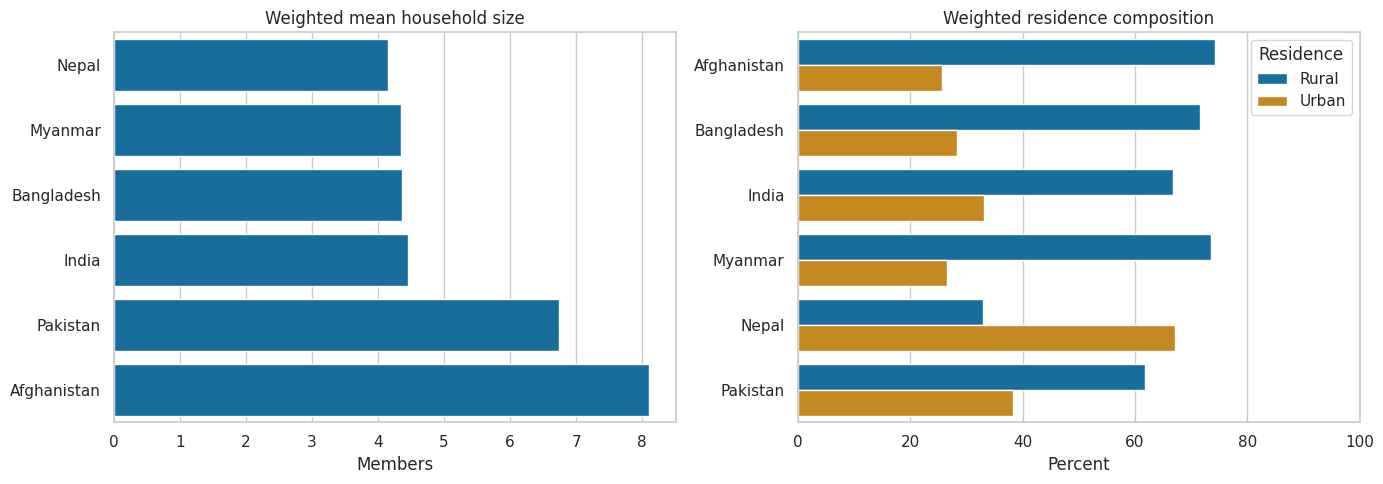

In [10]:
# ================================================================================================
# RECODE SOURCE
#   * Household Recode (HR)  - XXHRnnFL - one record per HOUSEHOLD / Household Member Recode (PR) - XXPRnnFL - one record per LISTED HOUSEHOLD MEMBER - the harmonised 'households' table built in section 6
# WHAT THIS CELL USES: HV009 weighted mean household size and HV025 weighted urban/rural composition
# (Annotation added only - every original line of this cell is kept unchanged.)
# ================================================================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_df = hh_summary.sort_values("weighted_mean_household_members")
sns.barplot(data=plot_df, y="country", x="weighted_mean_household_members", ax=axes[0], color=PALETTE[0])
axes[0].set(title="Weighted mean household size", xlabel="Members", ylabel="")

urban = []
for country, g in households.groupby("country", observed=True):
    if "HV025" in g:
        p = weighted_percent(g.HV025.map(RESIDENCE), g.weight)
        urban.extend({"country": country, "residence": k, "percent": v} for k, v in p.items())
urban = pd.DataFrame(urban)
sns.barplot(data=urban, y="country", x="percent", hue="residence", ax=axes[1], palette=PALETTE[:2])
axes[1].set(title="Weighted residence composition", xlabel="Percent", ylabel="", xlim=(0, 100))
axes[1].legend(title="Residence")
plt.tight_layout()
plt.show()

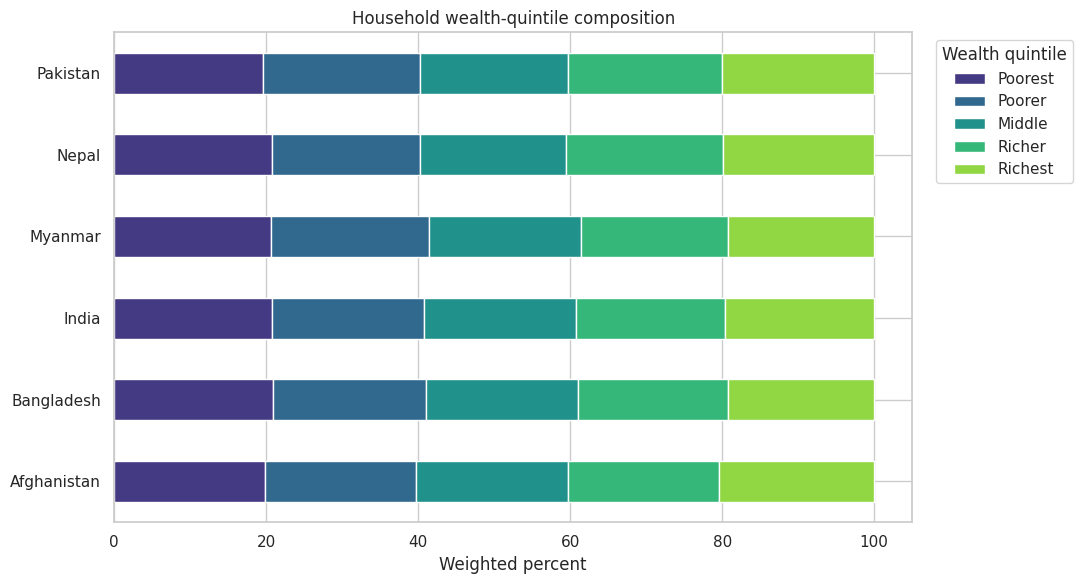

In [11]:
# ================================================================================================
# RECODE SOURCE
#   * Household Recode (HR)  - XXHRnnFL - one record per HOUSEHOLD / Household Member Recode (PR) - XXPRnnFL - one record per LISTED HOUSEHOLD MEMBER - the harmonised 'households' table built in section 6
# WHAT THIS CELL USES: HV270 household wealth quintile
# (Annotation added only - every original line of this cell is kept unchanged.)
# ================================================================================================

# Wealth distribution—shown only where the standard variable is present.
wealth_rows = []
if "HV270" in households:
    for country, g in households.groupby("country", observed=True):
        p = weighted_percent(g.HV270.map(WEALTH), g.weight)
        wealth_rows.extend({"country": country, "wealth": k, "percent": v} for k, v in p.items())
wealth_df = pd.DataFrame(wealth_rows)
if not wealth_df.empty:
    order = list(WEALTH.values())
    pivot = wealth_df.pivot(index="country", columns="wealth", values="percent").reindex(columns=order)
    pivot.plot(kind="barh", stacked=True, figsize=(11, 6), color=sns.color_palette("viridis", 5))
    plt.xlabel("Weighted percent")
    plt.ylabel("")
    plt.title("Household wealth-quintile composition")
    plt.legend(title="Wealth quintile", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout(); plt.show()
else:
    print("HV270 is not available in the household analysis table.")

## 8. Professional descriptive EDA: household members (`PR` countries)

Only countries supplied as `PR` can support member-level distributions. Values 98/99 and other survey-specific special codes are excluded from age summaries. Household weights are used for population-member descriptive tabulations; consult the survey documentation for specialized analyses.

In [12]:
# ================================================================================================
# RECODE SOURCE
#   * Household Member Recode (PR) - XXPRnnFL - one record per LISTED HOUSEHOLD MEMBER - only PR countries can produce member-level distributions
# WHAT THIS CELL USES: HV104 sex, HV105 age of every listed household member
# (Annotation added only - every original line of this cell is kept unchanged.)
# ================================================================================================

SEX = {1: "Male", 2: "Female"}
person_summary = []
if not persons.empty:
    valid_age = persons["HV105"].between(0, 95) if "HV105" in persons else pd.Series(False, index=persons.index)
    for country, g in persons.groupby("country", observed=True):
        ga = g[g["HV105"].between(0, 95)] if "HV105" in g else g.iloc[0:0]
        person_summary.append({
            "country": country, "unweighted_members": len(g),
            "weighted_mean_age": weighted_mean(ga.HV105, ga.weight) if len(ga) else np.nan,
            "weighted_female_pct": 100 * weighted_mean(g.HV104.eq(2).astype(float), g.weight) if "HV104" in g else np.nan,
            "weighted_age_15_49_pct": 100 * weighted_mean(g.HV105.between(15, 49).astype(float), g.weight) if "HV105" in g else np.nan,
        })
person_summary = pd.DataFrame(person_summary)
display(person_summary.style.format({"unweighted_members": "{:,.0f}", "weighted_mean_age": "{:.1f}", "weighted_female_pct": "{:.1f}%", "weighted_age_15_49_pct": "{:.1f}%"}))

,country,unweighted_members,weighted_mean_age,weighted_female_pct,weighted_age_15_49_pct
0,India,"2,843,917",30.8,50.5%,52.3%
1,Myanmar,"55,584",31.0,53.1%,49.2%
2,Nepal,"57,278",29.6,53.7%,49.4%
3,Pakistan,"100,869",24.3,50.8%,48.6%


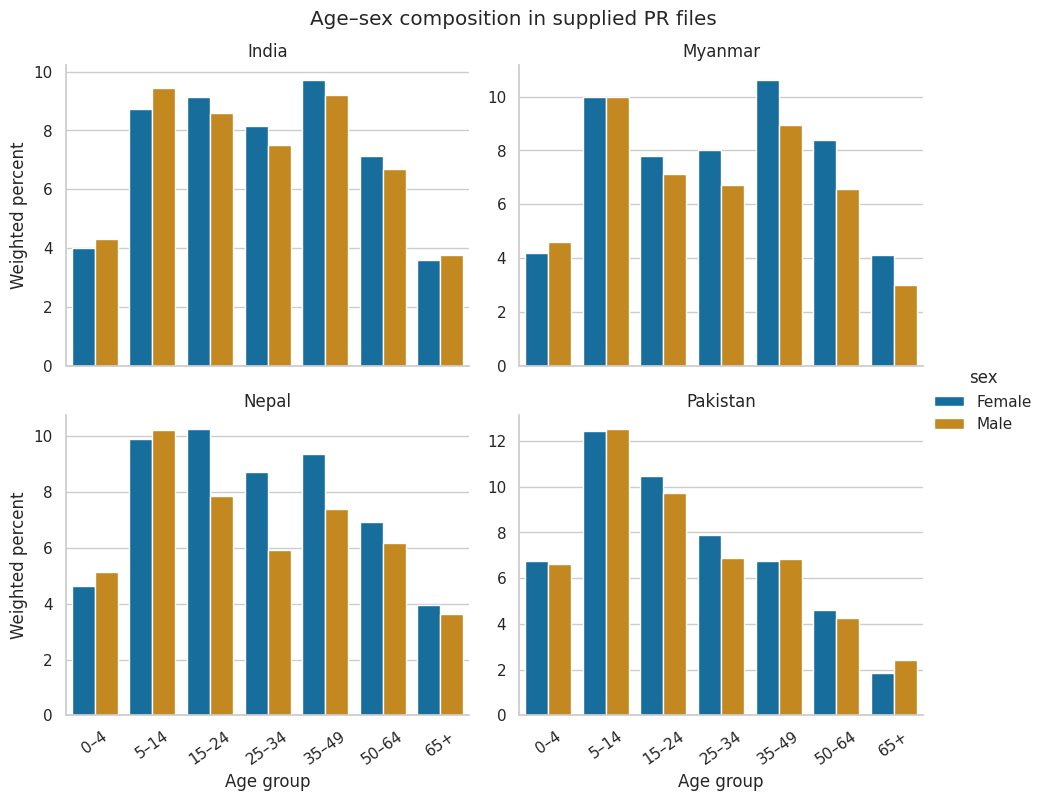

In [13]:
# ================================================================================================
# RECODE SOURCE
#   * Household Member Recode (PR) - XXPRnnFL - one record per LISTED HOUSEHOLD MEMBER
# WHAT THIS CELL USES: HV104 x HV105 weighted age-sex composition
# (Annotation added only - every original line of this cell is kept unchanged.)
# ================================================================================================

if not persons.empty and {"HV105", "HV104"}.issubset(persons):
    age = persons[persons.HV105.between(0, 95)].copy()
    age["age_group"] = pd.cut(age.HV105, bins=[-1, 4, 14, 24, 34, 49, 64, 200], labels=["0–4", "5–14", "15–24", "25–34", "35–49", "50–64", "65+"])
    age["sex"] = age.HV104.map(SEX)
    grouped = (age.groupby(["country", "age_group", "sex"], observed=True).weight.sum().rename("weighted_n").reset_index())
    grouped["percent_within_country"] = 100 * grouped.weighted_n / grouped.groupby("country").weighted_n.transform("sum")
    g = sns.catplot(data=grouped, x="age_group", y="percent_within_country", hue="sex", col="country", col_wrap=2,
                    kind="bar", height=3.8, aspect=1.25, palette=PALETTE[:2], sharey=False)
    g.set_axis_labels("Age group", "Weighted percent")
    g.set_titles("{col_name}")
    for ax in g.axes.flat: ax.tick_params(axis="x", rotation=35)
    g.figure.suptitle("Age–sex composition in supplied PR files", y=1.02)
    plt.show()

## 9. Female-focused study population and questionnaire availability

The `PR` files let us identify listed female household members, their age, education, marital status, whether they were eligible for the women's interview (`HV117`), and whether their household was selected for the DV module (`HV044`). These are **sampling-frame and background variables**, not proof that a woman completed the interview or answered a violence question.

The analytical pipeline below keeps four concepts separate:

| Concept | Evidence in supplied files | Interpretation |
|---|---|---|
| Female household member | `HV104 = 2` in `PR` | Listed as female in the household roster |
| Woman aged 15–49 | `HV104 = 2` and `15 ≤ HV105 ≤ 49` | Standard reproductive-age study population |
| Eligible for female interview | `HV117 = 1` | Roster flag only; completion is not established |
| Household selected for DV | `HV044 = 1` | Sampling flag only; no violence answer is present |
| Completed woman's interview | Requires `V015`/IR interview record | Not available in supplied files |
| Answered DV items | Requires nonmissing `D...` responses in `IR` | Not available in supplied files |
| Valid weighted DV respondent | Requires positive `D005` | Not available in supplied files |

In [14]:
# ================================================================================================
# RECODE SOURCE
#   * Household Recode (HR)  - XXHRnnFL - one record per HOUSEHOLD - schema check
#   * Household Member Recode (PR) - XXPRnnFL - one record per LISTED HOUSEHOLD MEMBER - schema check
#   * Individual Recode (IR) - XXIRnnFL - one record per INTERVIEWED WOMAN 15-49 - schema check (V015 / D005 / D1xx availability)
# WHAT THIS CELL USES: variable-name availability only, to separate roster flags from real interview answers
# (Annotation added only - every original line of this cell is kept unchanged.)
# ================================================================================================

female_availability = []
for _, meta in inventory[inventory.stem.isin(EXPECTED)].iterrows():
    names = set(schemas[meta.stem].name)
    female_availability.append({
        "country": meta.country, "recode": meta.recode,
        "female_roster_characteristics": meta.recode == "PR" and {"HV104", "HV105"}.issubset(names),
        "female_interview_eligibility_flag": "HV117" in names,
        "household_DV_selection_flag": "HV044" in names and "NA -" not in " ".join(schemas[meta.stem].loc[schemas[meta.stem].name.eq("HV044"), "label"]),
        "female_interview_answers": meta.recode == "IR" and "V015" in names,
        "DV_response_items": any(n.startswith("D") and n != "D005" for n in names),
        "DV_weight_D005": "D005" in names,
    })
display(pd.DataFrame(female_availability))

,country,recode,female_roster_characteristics,female_interview_eligibility_flag,household_DV_selection_flag,female_interview_answers,DV_response_items,DV_weight_D005
0,Afghanistan,HR,False,False,True,False,False,False
1,Bangladesh,HR,False,False,False,False,False,False
2,India,PR,True,True,True,False,False,False
3,Myanmar,PR,True,True,True,False,False,False
4,Nepal,PR,True,True,True,False,False,False
5,Pakistan,PR,True,True,True,False,False,False


In [15]:
# ================================================================================================
# RECODE SOURCE
#   * Household Member Recode (PR) - XXPRnnFL - one record per LISTED HOUSEHOLD MEMBER - the female study frame is built from the member roster
# WHAT THIS CELL USES: HV104=2 female, 15<=HV105<=49, HV117 female-interview eligibility flag, HV044 DV household selection
# NOTE: HV117 and HV044 are SAMPLING flags; a completed interview needs V015 from the Individual Recode
# (Annotation added only - every original line of this cell is kept unchanged.)
# ================================================================================================

# Construct the female study-frame table from PR records.
if not persons.empty and {"HV104", "HV105"}.issubset(persons):
    women_15_49 = persons.loc[(persons.HV104 == 2) & persons.HV105.between(15, 49)].copy()
    women_15_49["female_interview_eligible"] = women_15_49["HV117"].eq(1) if "HV117" in women_15_49 else False
    women_15_49["DV_household_selected"] = women_15_49["HV044"].eq(1) if "HV044" in women_15_49 else False
    women_15_49["potential_DV_sample_frame"] = women_15_49.female_interview_eligible & women_15_49.DV_household_selected
else:
    women_15_49 = pd.DataFrame()

female_flow_rows = []
for country, all_members in persons.groupby("country", observed=True):
    females = all_members[all_members.HV104.eq(2)]
    w1549 = females[females.HV105.between(15, 49)]
    stages = [
        ("All listed members", all_members, len(all_members)),
        ("Female members", females, len(all_members)),
        ("Women aged 15–49", w1549, len(females)),
        ("Flagged eligible for female interview", w1549[w1549.HV117.eq(1)], len(w1549)),
        ("In DV-selected household", w1549[w1549.HV044.eq(1)], len(w1549)),
        ("Eligible + DV-selected (potential frame only)", w1549[w1549.HV117.eq(1) & w1549.HV044.eq(1)], len(w1549)),
    ]
    for stage, d, denominator_n in stages:
        female_flow_rows.append({
            "country": country, "stage": stage, "unweighted_n": len(d),
            "denominator_n": denominator_n,
            "unweighted_pct_of_stage_denominator": 100 * len(d) / denominator_n if denominator_n else np.nan,
            "weighted_sum": d.weight.sum(),
        })

female_flow = pd.DataFrame(female_flow_rows)
display(female_flow.style.format({"unweighted_n": "{:,.0f}", "denominator_n": "{:,.0f}", "unweighted_pct_of_stage_denominator": "{:.1f}%", "weighted_sum": "{:,.0f}"}))

,country,stage,unweighted_n,denominator_n,unweighted_pct_of_stage_denominator,weighted_sum
0,India,All listed members,"2,843,917","2,843,917",100.0%,"2,834,297"
1,India,Female members,"1,433,580","2,843,917",50.4%,"1,431,375"
2,India,Women aged 15–49,"765,096","1,433,580",53.4%,"765,805"
3,India,Flagged eligible for female interview,"747,176","765,096",97.7%,"746,249"
4,India,In DV-selected household,"765,096","765,096",100.0%,"765,805"
5,India,Eligible + DV-selected (potential frame only),"747,176","765,096",97.7%,"746,249"
6,Myanmar,All listed members,"55,584","55,584",100.0%,"54,257"
7,Myanmar,Female members,"29,355","55,584",52.8%,"28,812"
8,Myanmar,Women aged 15–49,"14,188","29,355",48.3%,"14,325"
9,Myanmar,Flagged eligible for female interview,"13,454","14,188",94.8%,"13,629"


In [16]:
# ================================================================================================
# RECODE SOURCE
#   * Household Member Recode (PR) - XXPRnnFL - one record per LISTED HOUSEHOLD MEMBER
# WHAT THIS CELL USES: HV117 vs HV104 / HV105 internal-consistency checks
# (Annotation added only - every original line of this cell is kept unchanged.)
# ================================================================================================

# Internal consistency: eligibility should not be silently treated as a completed interview.
eligibility_checks = []
for country, g in persons.groupby("country", observed=True):
    flagged = g.HV117.eq(1) if "HV117" in g else pd.Series(False, index=g.index)
    eligibility_checks.append({
        "country": country,
        "female_eligible_flags": int(flagged.sum()),
        "flagged_male": int((flagged & g.HV104.ne(2)).sum()),
        "flagged_outside_age_15_49": int((flagged & ~g.HV105.between(15, 49)).sum()),
        "women_15_49_missing_eligibility": int(((g.HV104.eq(2) & g.HV105.between(15, 49)) & g.HV117.isna()).sum()),
    })
display(pd.DataFrame(eligibility_checks))

,country,female_eligible_flags,flagged_male,flagged_outside_age_15_49,women_15_49_missing_eligibility
0,India,747176,0,0,0
1,Myanmar,13454,0,0,0
2,Nepal,15238,0,0,0
3,Pakistan,15930,0,0,0


### Female background EDA

The following charts profile women aged 15–49 in the available `PR` surveys. They are useful for defining planned DV subgroups, identifying compositional differences, and checking whether crude country comparisons could be confounded by age, education, marital status, residence, or wealth.

In [17]:
# ================================================================================================
# RECODE SOURCE
#   * Household Member Recode (PR) - XXPRnnFL - one record per LISTED HOUSEHOLD MEMBER - women aged 15-49 extracted from the member roster
# WHAT THIS CELL USES: HV105 age, HV106 education, HV115 marital status, HV025 residence, HV117, HV044
# (Annotation added only - every original line of this cell is kept unchanged.)
# ================================================================================================

EDUCATION = {0: "No education", 1: "Primary", 2: "Secondary", 3: "Higher"}
MARITAL = {0: "Never married", 1: "Married", 2: "Living together", 3: "Widowed", 4: "Divorced", 5: "Separated/not living together"}

female_profile_rows = []
for country, g in women_15_49.groupby("country", observed=True):
    female_profile_rows.append({
        "country": country, "unweighted_women_15_49": len(g),
        "weighted_mean_age": weighted_mean(g.HV105, g.weight),
        "weighted_no_education_pct": 100 * weighted_mean(g.HV106.eq(0).astype(float), g.weight),
        "weighted_currently_married_or_union_pct": 100 * weighted_mean(g.HV115.isin([1, 2]).astype(float), g.weight),
        "weighted_urban_pct": 100 * weighted_mean(g.HV025.eq(1).astype(float), g.weight),
        "weighted_female_interview_eligible_pct": 100 * weighted_mean(g.female_interview_eligible.astype(float), g.weight),
        "weighted_DV_household_selected_pct": 100 * weighted_mean(g.DV_household_selected.astype(float), g.weight),
    })
female_profile = pd.DataFrame(female_profile_rows)
display(female_profile.style.format({
    "unweighted_women_15_49": "{:,.0f}", "weighted_mean_age": "{:.1f}",
    "weighted_no_education_pct": "{:.1f}%", "weighted_currently_married_or_union_pct": "{:.1f}%",
    "weighted_urban_pct": "{:.1f}%", "weighted_female_interview_eligible_pct": "{:.1f}%",
    "weighted_DV_household_selected_pct": "{:.1f}%",
}))

,country,unweighted_women_15_49,weighted_mean_age,weighted_no_education_pct,weighted_currently_married_or_union_pct,weighted_urban_pct,weighted_female_interview_eligible_pct,weighted_DV_household_selected_pct
0,India,"765,096",30.3,21.4%,72.1%,32.3%,97.4%,100.0%
1,Myanmar,"14,188",31.4,12.7%,58.8%,28.8%,95.1%,49.9%
2,Nepal,"16,052",29.6,24.5%,75.3%,68.2%,95.1%,47.7%
3,Pakistan,"25,426",28.1,41.5%,64.2%,38.1%,63.9%,36.2%


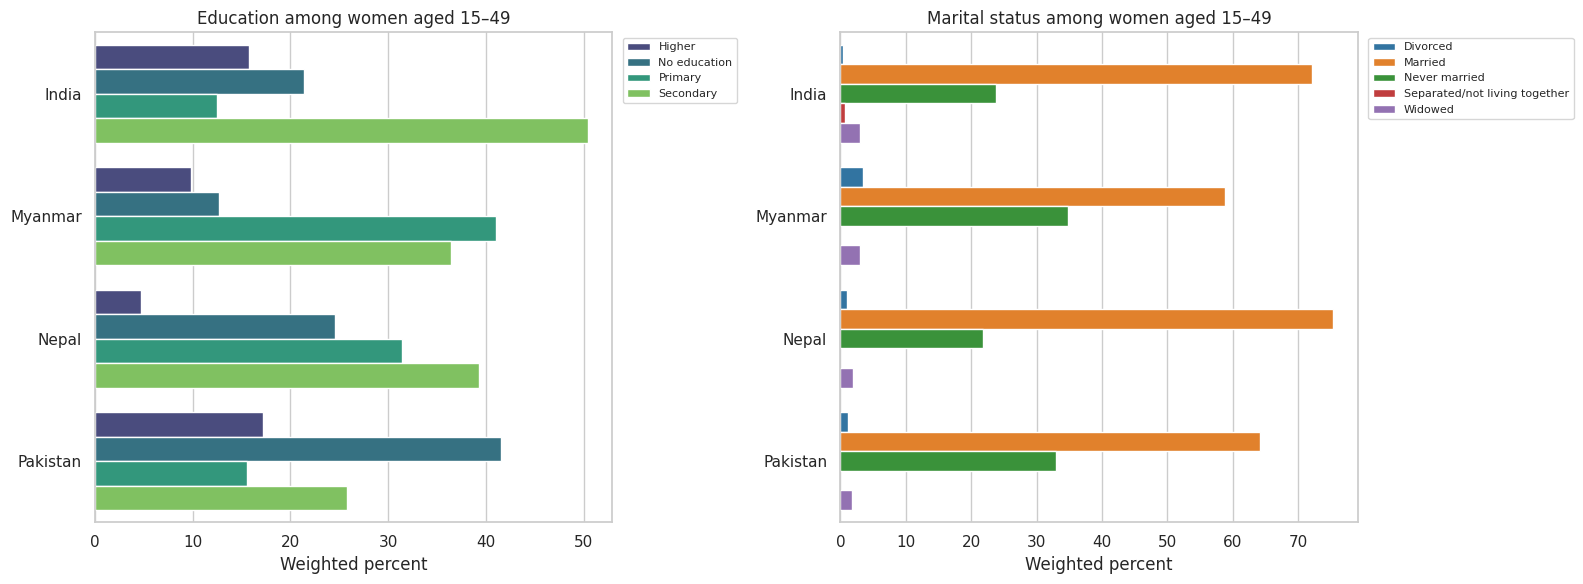

In [18]:
# ================================================================================================
# RECODE SOURCE
#   * Household Member Recode (PR) - XXPRnnFL - one record per LISTED HOUSEHOLD MEMBER
# WHAT THIS CELL USES: HV106 education and HV115 marital status of women 15-49
# (Annotation added only - every original line of this cell is kept unchanged.)
# ================================================================================================

def weighted_category_frame(df, variable, labels, value_name):
    rows = []
    if variable not in df: return pd.DataFrame()
    for country, g in df.groupby("country", observed=True):
        p = weighted_percent(g[variable].map(labels), g.weight)
        rows.extend({"country": country, value_name: k, "weighted_pct": v} for k, v in p.items())
    return pd.DataFrame(rows)

female_education = weighted_category_frame(women_15_49, "HV106", EDUCATION, "education")
female_marital = weighted_category_frame(women_15_49, "HV115", MARITAL, "marital_status")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
if not female_education.empty:
    sns.barplot(data=female_education, y="country", x="weighted_pct", hue="education", ax=axes[0], palette="viridis")
    axes[0].set(title="Education among women aged 15–49", xlabel="Weighted percent", ylabel="")
if not female_marital.empty:
    sns.barplot(data=female_marital, y="country", x="weighted_pct", hue="marital_status", ax=axes[1], palette="tab10")
    axes[1].set(title="Marital status among women aged 15–49", xlabel="Weighted percent", ylabel="")
for ax in axes:
    if ax.get_legend(): ax.legend(title="", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

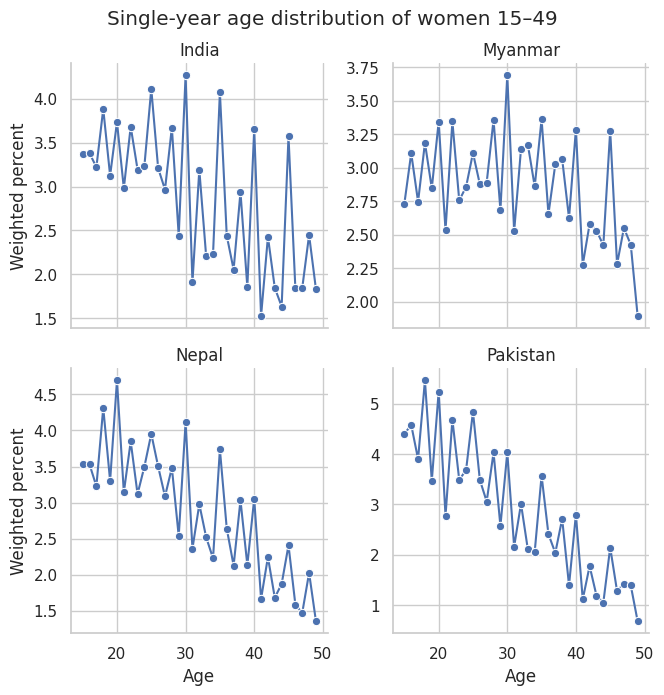

,country,residence,wealth,unweighted_n,DV_selected_pct,female_interview_eligible_pct
7,India,Rural,Middle,"127,779",100.0%,97.3%
6,India,Rural,Poorer,"154,155",100.0%,97.2%
5,India,Rural,Poorest,"152,357",100.0%,97.2%
8,India,Rural,Richer,"90,843",100.0%,97.2%
9,India,Rural,Richest,"49,331",100.0%,97.1%
2,India,Urban,Middle,"31,691",100.0%,98.0%
1,India,Urban,Poorer,"14,373",100.0%,98.0%
0,India,Urban,Poorest,"5,684",100.0%,97.6%
3,India,Urban,Richer,"56,414",100.0%,98.1%
4,India,Urban,Richest,"82,469",100.0%,97.8%


In [19]:
# ================================================================================================
# RECODE SOURCE
#   * Household Member Recode (PR) - XXPRnnFL - one record per LISTED HOUSEHOLD MEMBER
# WHAT THIS CELL USES: HV105 single-year age, HV025 x HV270 DV-selection coverage
# (Annotation added only - every original line of this cell is kept unchanged.)
# ================================================================================================

# Age profile and DV-selection coverage by residence/wealth.
if not women_15_49.empty:
    female_age = (women_15_49.groupby(["country", "HV105"], observed=True).weight.sum().rename("weighted_n").reset_index())
    female_age["weighted_pct"] = 100 * female_age.weighted_n / female_age.groupby("country").weighted_n.transform("sum")
    g = sns.relplot(data=female_age, x="HV105", y="weighted_pct", col="country", col_wrap=2,
                    kind="line", marker="o", height=3.4, facet_kws={"sharey": False})
    g.set_axis_labels("Age", "Weighted percent")
    g.set_titles("{col_name}")
    g.figure.suptitle("Single-year age distribution of women 15–49", y=1.02)
    plt.show()

selection_coverage = []
for (country, residence, wealth), g in women_15_49.groupby(["country", "HV025", "HV270"], observed=True, dropna=False):
    selection_coverage.append({
        "country": country, "residence": RESIDENCE.get(residence, str(residence)),
        "wealth": WEALTH.get(wealth, str(wealth)), "unweighted_n": len(g),
        "DV_selected_pct": 100 * weighted_mean(g.DV_household_selected.astype(float), g.weight),
        "female_interview_eligible_pct": 100 * weighted_mean(g.female_interview_eligible.astype(float), g.weight),
    })
selection_coverage = pd.DataFrame(selection_coverage)
display(selection_coverage.sort_values(["country", "residence", "wealth"]).style.format({
    "unweighted_n": "{:,.0f}", "DV_selected_pct": "{:.1f}%", "female_interview_eligible_pct": "{:.1f}%"
}))

## 10. Country-wise women’s EDA dashboard

This section compares the female study frame country by country. In the current files, “women’s information” means household-roster characteristics and sampling flags. The `actual_DV_answers` column remains unavailable until matching `IR` records are supplied.

In [20]:
# ================================================================================================
# RECODE SOURCE
#   * Household Member Recode (PR) - XXPRnnFL - one record per LISTED HOUSEHOLD MEMBER - female profile
#   * Individual Recode (IR) - XXIRnnFL - one record per INTERVIEWED WOMAN 15-49 - schema-level 'actual_DV_answers' availability column
# WHAT THIS CELL USES: the section-9 availability audit joined to the section-9 weighted female profile
# (Annotation added only - every original line of this cell is kept unchanged.)
# ================================================================================================

country_women_dashboard = (inventory[inventory.stem.isin(EXPECTED)]
    [["country", "survey", "recode", "stem"]]
    .merge(pd.DataFrame(female_availability), on=["country", "recode"], how="left")
    .merge(female_profile, on="country", how="left"))
country_women_dashboard["actual_DV_answers"] = np.where(
    country_women_dashboard.DV_response_items.fillna(False) & country_women_dashboard.DV_weight_D005.fillna(False),
    "Available in IR", "Not available in supplied file"
)
display(country_women_dashboard.style.format({
    "unweighted_women_15_49": "{:,.0f}", "weighted_mean_age": "{:.1f}",
    "weighted_no_education_pct": "{:.1f}%", "weighted_currently_married_or_union_pct": "{:.1f}%",
    "weighted_urban_pct": "{:.1f}%", "weighted_female_interview_eligible_pct": "{:.1f}%",
    "weighted_DV_household_selected_pct": "{:.1f}%",
}))

,country,survey,recode,stem,female_roster_characteristics,female_interview_eligibility_flag,household_DV_selection_flag,female_interview_answers,DV_response_items,DV_weight_D005,unweighted_women_15_49,weighted_mean_age,weighted_no_education_pct,weighted_currently_married_or_union_pct,weighted_urban_pct,weighted_female_interview_eligible_pct,weighted_DV_household_selected_pct,actual_DV_answers
0,Afghanistan,2015,HR,AFHR71FL,False,False,True,False,False,False,nan,nan,nan%,nan%,nan%,nan%,nan%,Not available in supplied file
1,Bangladesh,2022,HR,BDHR81FL,False,False,False,False,False,False,nan,nan,nan%,nan%,nan%,nan%,nan%,Not available in supplied file
2,India,2019–21,PR,IAPR7EFL,True,True,True,False,False,False,"765,096",30.3,21.4%,72.1%,32.3%,97.4%,100.0%,Not available in supplied file
3,Myanmar,2015–16,PR,MMPR71FL,True,True,True,False,False,False,"14,188",31.4,12.7%,58.8%,28.8%,95.1%,49.9%,Not available in supplied file
4,Nepal,2022,PR,NPPR82FL,True,True,True,False,False,False,"16,052",29.6,24.5%,75.3%,68.2%,95.1%,47.7%,Not available in supplied file
5,Pakistan,2017–18,PR,PKPR71FL,True,True,True,False,False,False,"25,426",28.1,41.5%,64.2%,38.1%,63.9%,36.2%,Not available in supplied file


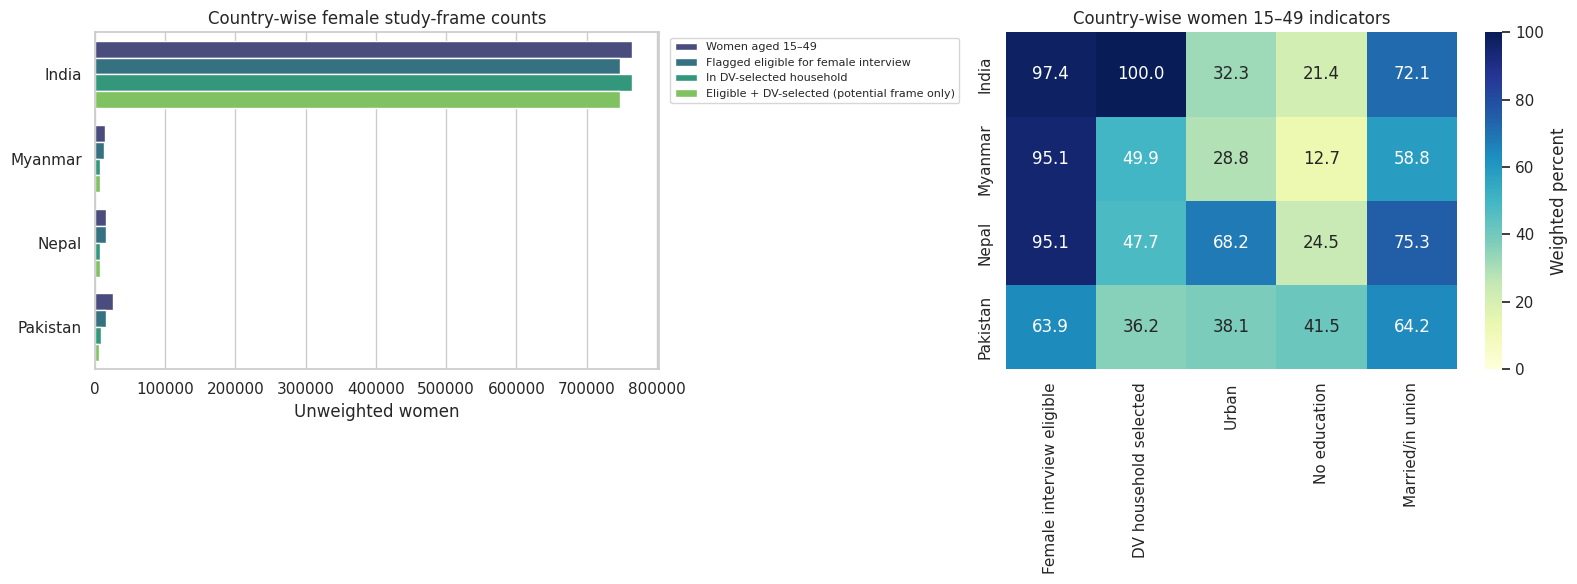

In [21]:
# ================================================================================================
# RECODE SOURCE
#   * Household Member Recode (PR) - XXPRnnFL - one record per LISTED HOUSEHOLD MEMBER
# WHAT THIS CELL USES: country-wise female study-frame stage counts and weighted indicator heatmap
# (Annotation added only - every original line of this cell is kept unchanged.)
# ================================================================================================

# Country-wise stage counts: never label potential-frame women as respondents.
stage_order = [
    "Women aged 15–49", "Flagged eligible for female interview",
    "In DV-selected household", "Eligible + DV-selected (potential frame only)"
]
female_country_flow = female_flow[female_flow.stage.isin(stage_order)].copy()
female_country_flow["pct_of_women_15_49"] = female_country_flow.groupby("country").unweighted_n.transform(
    lambda x: 100 * x / x.iloc[0] if len(x) and x.iloc[0] else np.nan
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(data=female_country_flow, y="country", x="unweighted_n", hue="stage", ax=axes[0], palette="viridis")
axes[0].set(title="Country-wise female study-frame counts", xlabel="Unweighted women", ylabel="")
axes[0].ticklabel_format(axis="x", style="plain")
axes[0].legend(title="", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)

kpi_cols = [
    "weighted_female_interview_eligible_pct", "weighted_DV_household_selected_pct",
    "weighted_urban_pct", "weighted_no_education_pct", "weighted_currently_married_or_union_pct"
]
kpi_labels = ["Female interview eligible", "DV household selected", "Urban", "No education", "Married/in union"]
kpi = female_profile.set_index("country")[kpi_cols].rename(columns=dict(zip(kpi_cols, kpi_labels)))
sns.heatmap(kpi, annot=True, fmt=".1f", cmap="YlGnBu", vmin=0, vmax=100, cbar_kws={"label": "Weighted percent"}, ax=axes[1])
axes[1].set(title="Country-wise women 15–49 indicators", xlabel="", ylabel="")
plt.tight_layout(); plt.show()

In [22]:
# ================================================================================================
# RECODE SOURCE
#   * Household Member Recode (PR) - XXPRnnFL - one record per LISTED HOUSEHOLD MEMBER
# WHAT THIS CELL USES: HV105 age group, HV106 education, HV115 marital status, HV025 residence, HV270 wealth
# (Annotation added only - every original line of this cell is kept unchanged.)
# ================================================================================================

# Country-wise distributions for major female background variables.
women_15_49["age_group_5y"] = pd.cut(
    women_15_49.HV105, bins=[14, 19, 24, 29, 34, 39, 44, 49],
    labels=["15–19", "20–24", "25–29", "30–34", "35–39", "40–44", "45–49"]
)
dimension_specs = {
    "Age group": ("age_group_5y", None),
    "Education": ("HV106", EDUCATION),
    "Marital status": ("HV115", MARITAL),
    "Residence": ("HV025", RESIDENCE),
    "Wealth quintile": ("HV270", WEALTH),
}
country_women_distributions = []
for dimension, (variable, labels) in dimension_specs.items():
    for country, g in women_15_49.groupby("country", observed=True):
        category = g[variable].map(labels) if labels else g[variable].astype("string")
        p = weighted_percent(category, g.weight)
        country_women_distributions.extend({
            "country": country, "dimension": dimension, "category": category_name, "weighted_pct": pct
        } for category_name, pct in p.items())
country_women_distributions = pd.DataFrame(country_women_distributions)
display(country_women_distributions.sort_values(["dimension", "country", "category"]).style.format({"weighted_pct": "{:.1f}%"}))

,country,dimension,category,weighted_pct
0,India,Age group,15–19,17.0%
1,India,Age group,20–24,16.8%
2,India,Age group,25–29,16.4%
3,India,Age group,30–34,13.8%
4,India,Age group,35–39,13.4%
5,India,Age group,40–44,11.1%
6,India,Age group,45–49,11.5%
7,Myanmar,Age group,15–19,14.6%
8,Myanmar,Age group,20–24,14.8%
9,Myanmar,Age group,25–29,14.9%


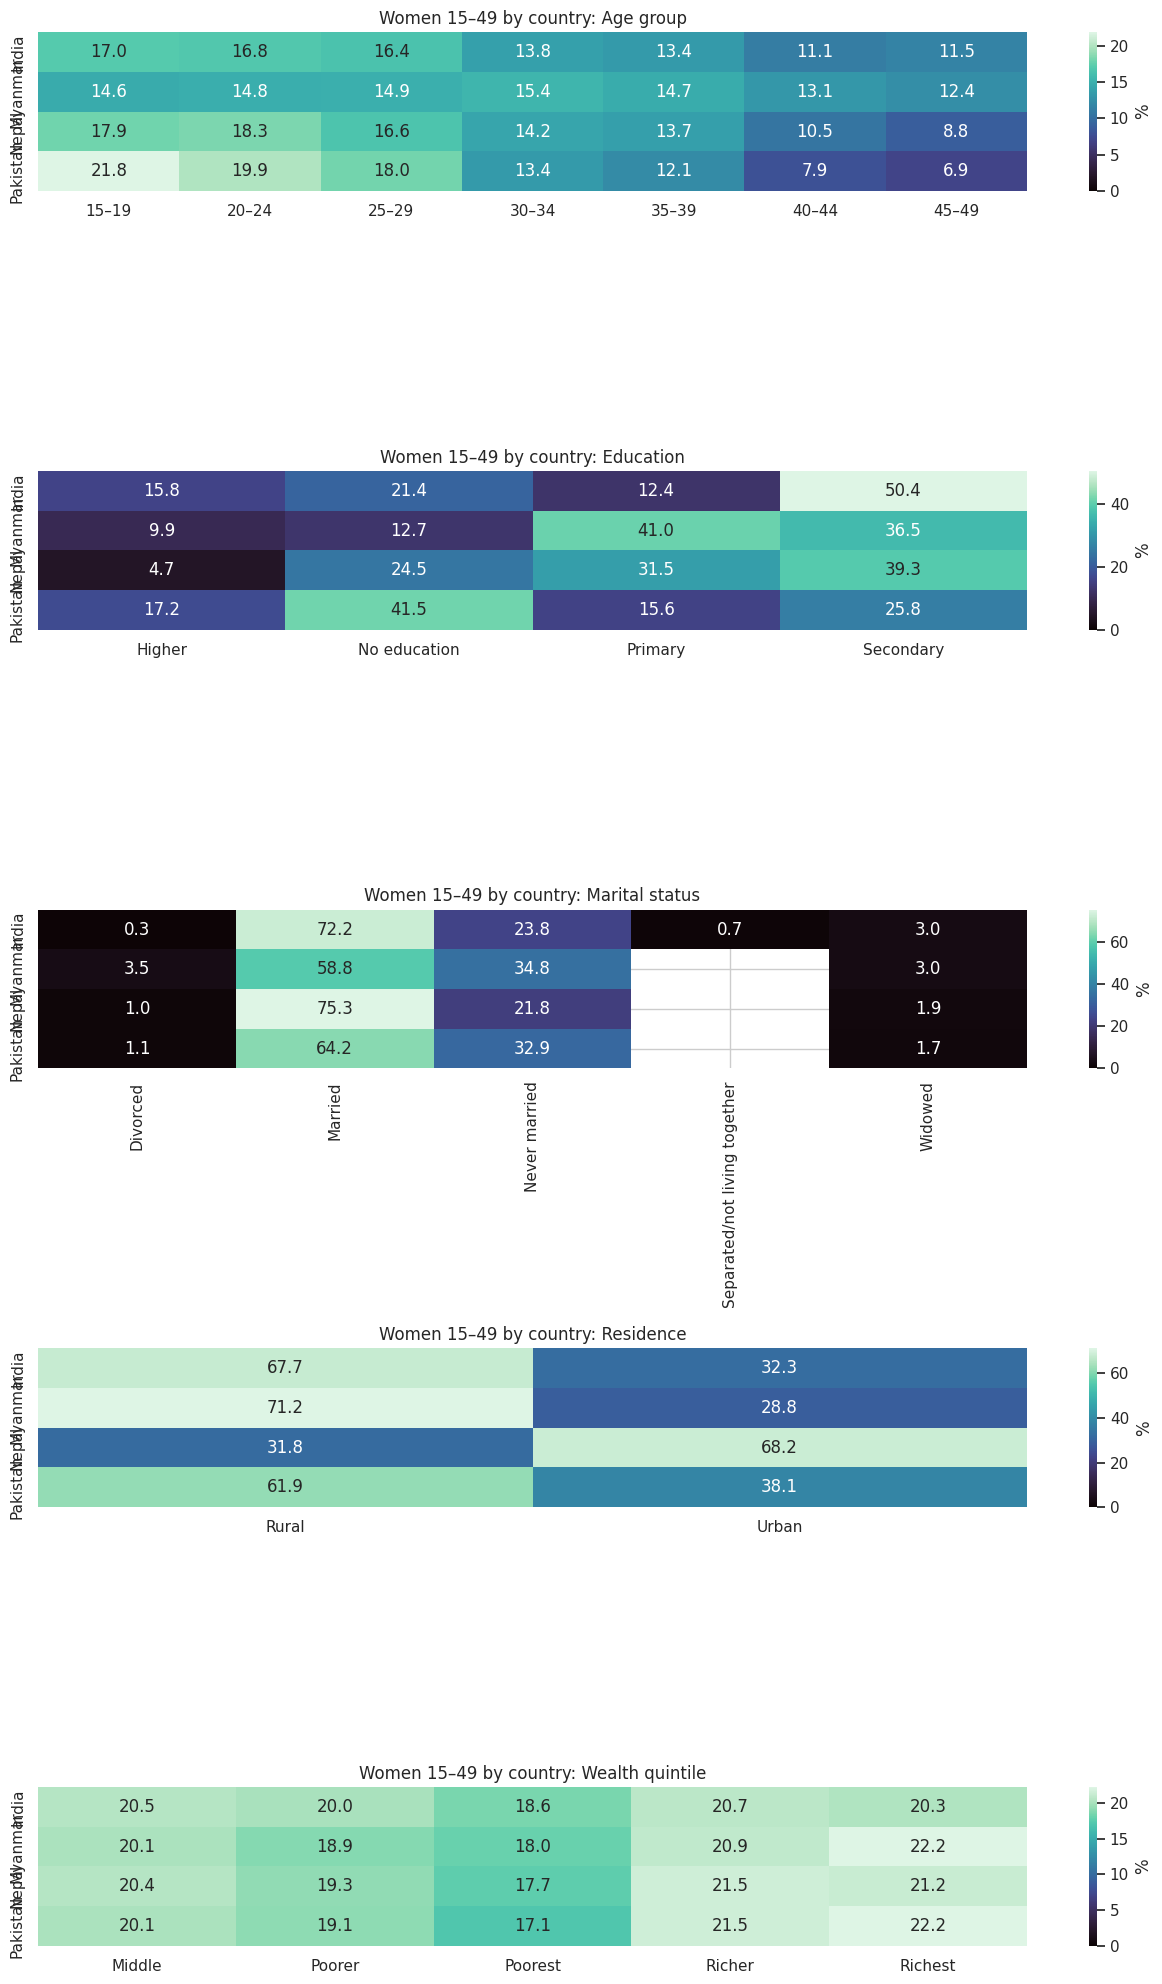

In [23]:
# ================================================================================================
# RECODE SOURCE
#   * Household Member Recode (PR) - XXPRnnFL - one record per LISTED HOUSEHOLD MEMBER
# WHAT THIS CELL USES: the five weighted background dimensions built in the previous cell
# (Annotation added only - every original line of this cell is kept unchanged.)
# ================================================================================================

dimensions = list(dimension_specs)
fig, axes = plt.subplots(len(dimensions), 1, figsize=(13, 4 * len(dimensions)))
for ax, dimension in zip(axes, dimensions):
    d = country_women_distributions[country_women_distributions.dimension.eq(dimension)]
    table = d.pivot(index="country", columns="category", values="weighted_pct")
    sns.heatmap(table, annot=True, fmt=".1f", cmap="mako", vmin=0, cbar_kws={"label": "%"}, ax=ax)
    ax.set(title=f"Women 15–49 by country: {dimension}", xlabel="", ylabel="")
plt.tight_layout(); plt.show()

,country,variable,field,nonmissing_n,total_women_15_49,nonmissing_pct
0,India,HV105,Age,"765,096","765,096",100.0%
1,India,HV106,Education,"765,096","765,096",100.0%
2,India,HV115,Marital status,"765,096","765,096",100.0%
3,India,HV025,Residence,"765,096","765,096",100.0%
4,India,HV270,Wealth,"765,096","765,096",100.0%
5,India,HV117,Female eligibility flag,"765,096","765,096",100.0%
6,India,HV044,DV selection flag,"765,096","765,096",100.0%
7,Myanmar,HV105,Age,"14,188","14,188",100.0%
8,Myanmar,HV106,Education,"14,188","14,188",100.0%
9,Myanmar,HV115,Marital status,"14,188","14,188",100.0%


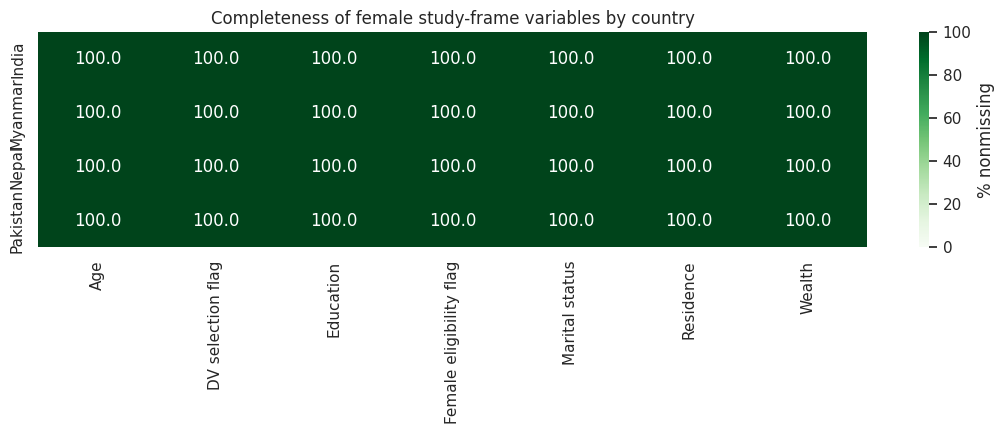

In [24]:
# ================================================================================================
# RECODE SOURCE
#   * Household Member Recode (PR) - XXPRnnFL - one record per LISTED HOUSEHOLD MEMBER
# WHAT THIS CELL USES: non-missing rates of HV105 HV106 HV115 HV025 HV270 HV117 HV044 among women 15-49
# (Annotation added only - every original line of this cell is kept unchanged.)
# ================================================================================================

# Field completeness among women 15–49, by country.
female_field_labels = {
    "HV105": "Age", "HV106": "Education", "HV115": "Marital status",
    "HV025": "Residence", "HV270": "Wealth", "HV117": "Female eligibility flag", "HV044": "DV selection flag"
}
country_female_completeness = []
for country, g in women_15_49.groupby("country", observed=True):
    for variable, label in female_field_labels.items():
        if variable in g:
            country_female_completeness.append({
                "country": country, "variable": variable, "field": label,
                "nonmissing_n": int(g[variable].notna().sum()), "total_women_15_49": len(g),
                "nonmissing_pct": 100 * g[variable].notna().mean(),
            })
country_female_completeness = pd.DataFrame(country_female_completeness)
display(country_female_completeness.style.format({
    "nonmissing_n": "{:,.0f}", "total_women_15_49": "{:,.0f}", "nonmissing_pct": "{:.1f}%"
}))
if not country_female_completeness.empty:
    completeness_pivot = country_female_completeness.pivot(index="country", columns="field", values="nonmissing_pct")
    plt.figure(figsize=(11, 4.5))
    sns.heatmap(completeness_pivot, annot=True, fmt=".1f", cmap="Greens", vmin=0, vmax=100, cbar_kws={"label": "% nonmissing"})
    plt.title("Completeness of female study-frame variables by country")
    plt.xlabel(""); plt.ylabel(""); plt.tight_layout(); plt.show()

## 11. Domestic-violence questionnaire study map

This planning table shows what a professional woman-level DV study normally needs. Exact variable names and wording vary by country and DHS phase, so the notebook discovers experience items from the `IR` variable labels and requires manual confirmation.

| Study domain | Typical female respondent concept | Expected source | Analytical use |
|---|---|---|---|
| Interview status | Woman completed/partly completed individual interview | `IR`, commonly `V015` | Establish interviewed denominator |
| DV selection/weight | Selected eligible woman with positive DV subsample weight | `IR`, `D005 > 0` | Define valid DV denominator and weights |
| Emotional violence | Partner humiliated, threatened harm, or insulted/made her feel bad | Country-specific `D...` items | Ever and past-12-month emotional violence |
| Physical violence | Partner pushed, slapped, twisted arm/pulled hair, punched, kicked/dragged/beat, choked/burned, or threatened/attacked with a weapon | Country-specific `D...` items | Severity-specific and composite physical violence |
| Sexual violence | Partner physically forced sex or other unwanted sexual acts | Country-specific `D...` items | Ever and past-12-month sexual violence |
| Injury | Cuts/bruises, severe injury, or medical consequences | Country-specific `D...` items | Consequences among exposed women |
| Help seeking | Told someone, sought help, and source of help | Country-specific `D...` items | Service and disclosure analysis |
| Partner control | Jealousy, accusations, limiting contacts, monitoring, or restricting access | Country-specific `D...` items | Coercive-control context; not merged with violence without justification |
| Attitudes | Whether wife beating is justified in specified situations | Often `V744A–V744E` | Norms/attitudes; **not** experienced violence |

Common experience-item response codes are often `0 = never`, `1 = often`, `2 = sometimes`, and `3 = yes, but not in the past 12 months`. Special codes must be treated as missing. The actual value labels in each survey remain authoritative.

## 12. Guarded domestic-violence analysis (activates with `IR` files)

This section deliberately fails closed. It discovers `IR` ZIPs, checks for `D005`, and uses variable labels to identify violence items. No prevalence is computed from `HR`/`PR` files or from `HV044`.

Before publication, compare the identified items and denominators with each country's DHS final report and recode manual. Questionnaire routing and universes differ. The simple confidence intervals below are descriptive; publication-grade inference should use strata (`V022/V023`) and PSU (`V021`) with a survey-analysis package.

In [25]:
# ================================================================================================
# RECODE SOURCE
#   * Individual Recode (IR) - XXIRnnFL - one record per INTERVIEWED WOMAN 15-49 - this is where the notebook switches from households to WOMEN
# WHAT THIS CELL USES: the IR rows of the inventory; nothing is estimated unless D005 is present
# (Annotation added only - every original line of this cell is kept unchanged.)
# ================================================================================================

ir_inventory = inventory[inventory.recode.eq("IR")].copy()

def classify_dv_item(name, label):
    if not name.upper().startswith("D") or name.upper() == "D005":
        return None
    text = label.lower()
    # Transparent label-based classification; review the resulting table before estimation.
    if any(k in text for k in ["humiliat", "insult", "make her feel bad", "threaten her with harm"]):
        return "emotional"
    if any(k in text for k in ["forced sex", "physically force", "sexual act", "sexual violence"]):
        return "sexual"
    if any(k in text for k in ["push", "shake", "slap", "punch", "kick", "drag", "strangl", "burn", "weapon", "twist her arm", "physical violence"]):
        return "physical"
    return None

if ir_inventory.empty:
    display(Markdown(
        "**DV module not run:** no Individual Recode (`IR`) ZIP was found under `/kaggle/input/`. "
        "For each country, add the matching `XXIR..FL.zip` file from the same survey wave."
    ))
else:
    print("IR archives found:")
    display(ir_inventory[["archive", "country", "survey", "path"]])

IR archives found:


,archive,country,survey,path
1,AFIR71FL,Afghanistan,2015,/kaggle/input/datasets/maomislive/dhs-domestic...
4,BDIR81FL,Bangladesh,2022,/kaggle/input/datasets/maomislive/dhs-domestic...
7,IAIR7EFL,India,2019–21,/kaggle/input/datasets/maomislive/dhs-domestic...
9,LKIR02FL,Sri Lanka,Check survey documentation,/kaggle/input/datasets/maomislive/dhs-domestic...
11,MMIR71FL,Myanmar,2015–16,/kaggle/input/datasets/maomislive/dhs-domestic...
14,NPIR82FL,Nepal,2022,/kaggle/input/datasets/maomislive/dhs-domestic...
17,PKIR71FL,Pakistan,2017–18,/kaggle/input/datasets/maomislive/dhs-domestic...


In [26]:
# ================================================================================================
# RECODE SOURCE
#   * Individual Recode (IR) - XXIRnnFL - one record per INTERVIEWED WOMAN 15-49
# WHAT THIS CELL USES: IR variable LABELS to auto-discover D1xx emotional / physical / sexual items
# NOTE: the added section 16 replaces this label search with an explicit, curated DHS item list
# (Annotation added only - every original line of this cell is kept unchanged.)
# ================================================================================================

dv_item_registry = []
if not ir_inventory.empty:
    for _, meta in ir_inventory.iterrows():
        schema = schemas.get(meta.stem)
        if schema is None:
            schema, _, _ = parse_archive_schema(Path(meta.path))
            schemas[meta.stem] = schema
        for _, v in schema.iterrows():
            domain = classify_dv_item(v["name"], v["label"])
            if domain:
                dv_item_registry.append({"stem": meta.stem, "country": meta.country, "name": v["name"], "label": v["label"], "domain": domain})

dv_item_registry = pd.DataFrame(dv_item_registry)
if not dv_item_registry.empty:
    display(dv_item_registry)
    print("STOP AND REVIEW: confirm this item registry against each survey questionnaire before interpreting results.")

,stem,country,name,label,domain
0,AFIR71FL,Afghanistan,D103A,Ever been humiliated by husband/partner,emotional
1,AFIR71FL,Afghanistan,D103C,Ever been insulted or made to feel bad by husb...,emotional
2,AFIR71FL,Afghanistan,D105A,"Ever been pushed, shook or had something throw...",physical
3,AFIR71FL,Afghanistan,D105B,Ever been slapped by husband/partner,physical
4,AFIR71FL,Afghanistan,D105C,Ever been punched with fist or hit by somethin...,physical
5,AFIR71FL,Afghanistan,D105D,Ever been kicked or dragged by husband/partner,physical
6,AFIR71FL,Afghanistan,D105E,Ever been strangled or burnt by husband/partner,physical
7,AFIR71FL,Afghanistan,D105F,Ever been threatened with knife/gun or other w...,physical
8,AFIR71FL,Afghanistan,D105G,NA - Ever CS physical violence by husband/partner,physical
9,AFIR71FL,Afghanistan,D105H,Ever been physically forced into unwanted sex ...,sexual


STOP AND REVIEW: confirm this item registry against each survey questionnaire before interpreting results.


Skipping Bangladesh: D005 DV weight is absent.
Skipping Sri Lanka: D005 DV weight is absent.


,country,indicator,weighted_pct,approx_ci_low,approx_ci_high,unweighted_n,effective_n
0,Afghanistan,ever_emotional,36.5%,35.3%,37.7%,21285,"5,959"
1,Afghanistan,past12_emotional,33.7%,32.5%,34.9%,21285,"5,959"
2,Afghanistan,ever_physical,50.2%,48.9%,51.5%,21307,"5,967"
3,Afghanistan,past12_physical,45.8%,44.5%,47.1%,21307,"5,967"
4,Afghanistan,ever_sexual,7.5%,6.9%,8.2%,21279,"5,953"
5,Afghanistan,past12_sexual,7.5%,6.8%,8.2%,21279,"5,953"
6,Afghanistan,ever_any,55.1%,53.9%,56.4%,21308,"5,967"
7,Afghanistan,past12_any,51.7%,50.4%,53.0%,21308,"5,967"
8,India,ever_emotional,12.9%,12.4%,13.4%,63851,"17,140"
9,India,past12_emotional,11.1%,10.6%,11.6%,63851,"17,140"


### Which women actually answered at least one identified DV question

,country,all_IR_records,positive_D005_valid_DV_weight,positive_D005_and_answered_any_identified_item,answer_coverage_pct_among_positive_D005
0,Afghanistan,"29,461","21,324","21,308",99.9%
1,India,"724,115","72,320","72,277",99.9%
2,Myanmar,"12,885","4,530","4,529",100.0%
3,Nepal,"14,845","5,178","5,177",100.0%
4,Pakistan,"15,068","3,303","3,303",100.0%


### Female answers to each identified violence question

...

,country,item,label,domain,weighted_total,unweighted_answered_n,weighted_ever,weighted_ever_pct
0,Afghanistan,D103A,Ever been humiliated by husband/partner,emotional,21262.970498,"21,266",7125.890506,33.5%
1,Afghanistan,D103C,Ever been insulted or made to feel bad by husband/partner,emotional,21279.270710,"21,270",5407.531618,25.4%
3,Afghanistan,D105B,Ever been slapped by husband/partner,physical,21275.705387,"21,270",9760.846867,45.9%
2,Afghanistan,D105A,"Ever been pushed, shook or had something thrown by husband/partner",physical,21277.237044,"21,280",8735.810679,41.1%
20,Afghanistan,D130A,"Previous husband: ever hit, slap, kick or physically hurt respondent",physical,248.439853,233,67.472091,27.2%
4,Afghanistan,D105C,Ever been punched with fist or hit by something harmful by husband/partner,physical,21266.008719,"21,270",4716.732822,22.2%
5,Afghanistan,D105D,Ever been kicked or dragged by husband/partner,physical,21268.201905,"21,273",3675.237178,17.3%
16,Afghanistan,D110B,"Ever had eye injuries, sprains, dislocations or burns because of husband/partner's actions",physical,10759.945968,"9,958",1388.527080,12.9%
6,Afghanistan,D105E,Ever been strangled or burnt by husband/partner,physical,21254.917836,"21,277",676.461957,3.2%
7,Afghanistan,D105F,Ever been threatened with knife/gun or other weapon by husband/partner,physical,21246.009204,"21,270",617.628732,2.9%


### Any-violence estimates by female background subgroup (small cells suppressed)

,country,indicator,subgroup,category,weighted_pct,approx_ci_low,approx_ci_high,unweighted_n,effective_n,suppressed
0,Afghanistan,ever_any,residence,Urban,48.3%,45.5%,51.2%,"5,303","1,181",False
1,Afghanistan,ever_any,residence,Rural,57.1%,55.7%,58.5%,"16,005","4,810",False
2,Afghanistan,ever_any,education,No education,57.5%,56.3%,58.8%,"18,146","5,897",False
3,Afghanistan,ever_any,education,Primary,48.0%,41.7%,54.3%,"1,460",241,False
4,Afghanistan,ever_any,education,Secondary,40.0%,33.8%,46.2%,"1,320",240,False
5,Afghanistan,ever_any,education,Higher,31.9%,21.2%,42.7%,382,73,False
6,Afghanistan,ever_any,wealth,Poorest,55.5%,53.2%,57.8%,"4,206","1,859",False
7,Afghanistan,ever_any,wealth,Poorer,56.5%,53.9%,59.0%,"4,811","1,486",False
8,Afghanistan,ever_any,wealth,Middle,59.7%,57.1%,62.3%,"4,557","1,356",False
9,Afghanistan,ever_any,wealth,Richer,55.1%,52.1%,58.2%,"4,466","1,029",False


### Country-wise number of identified DV questions answered per woman

,country,answered_item_count,unweighted_n,weighted_n,weighted_pct
0,Afghanistan,0,16,18.1,0.1%
1,Afghanistan,2,2,1.7,0.0%
2,Afghanistan,4,3,1.9,0.0%
3,Afghanistan,5,6,8.3,0.0%
4,Afghanistan,6,8,13.1,0.1%
5,Afghanistan,7,12,25.4,0.1%
6,Afghanistan,8,1,0.6,0.0%
7,Afghanistan,9,8,5.6,0.0%
8,Afghanistan,10,16,16.4,0.1%
9,Afghanistan,11,50,43.4,0.2%


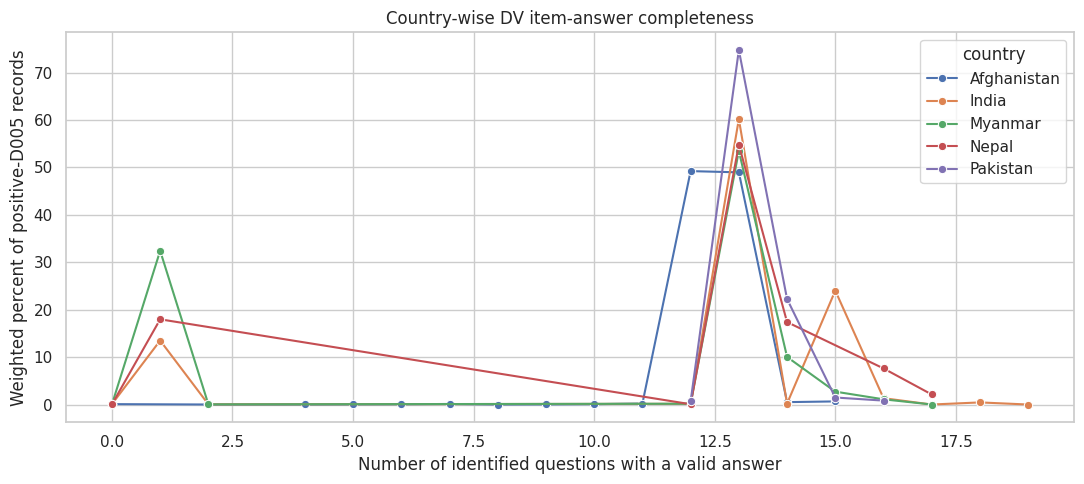

### Country-wise women answering each identified DV question

,country,item,label,domain,weighted_total,unweighted_answered_n,weighted_ever,weighted_ever_pct,positive_D005_valid_DV_weight,unweighted_answer_coverage_pct
0,Afghanistan,D103A,Ever been humiliated by husband/partner,emotional,21262.970498,"21,266",7125.890506,33.5%,"21,324",99.7%
1,Afghanistan,D103C,Ever been insulted or made to feel bad by husband/partner,emotional,21279.270710,"21,270",5407.531618,25.4%,"21,324",99.7%
2,Afghanistan,D105A,"Ever been pushed, shook or had something thrown by husband/partner",physical,21277.237044,"21,280",8735.810679,41.1%,"21,324",99.8%
3,Afghanistan,D105B,Ever been slapped by husband/partner,physical,21275.705387,"21,270",9760.846867,45.9%,"21,324",99.7%
4,Afghanistan,D105C,Ever been punched with fist or hit by something harmful by husband/partner,physical,21266.008719,"21,270",4716.732822,22.2%,"21,324",99.7%
5,Afghanistan,D105D,Ever been kicked or dragged by husband/partner,physical,21268.201905,"21,273",3675.237178,17.3%,"21,324",99.8%
6,Afghanistan,D105E,Ever been strangled or burnt by husband/partner,physical,21254.917836,"21,277",676.461957,3.2%,"21,324",99.8%
7,Afghanistan,D105F,Ever been threatened with knife/gun or other weapon by husband/partner,physical,21246.009204,"21,270",617.628732,2.9%,"21,324",99.7%
8,Afghanistan,D105G,NA - Ever CS physical violence by husband/partner,physical,0.000000,0,0.000000,nan%,"21,324",0.0%
12,Afghanistan,D105L,NA - Ever CS physical violence by husband/partner,physical,0.000000,0,0.000000,nan%,"21,324",0.0%


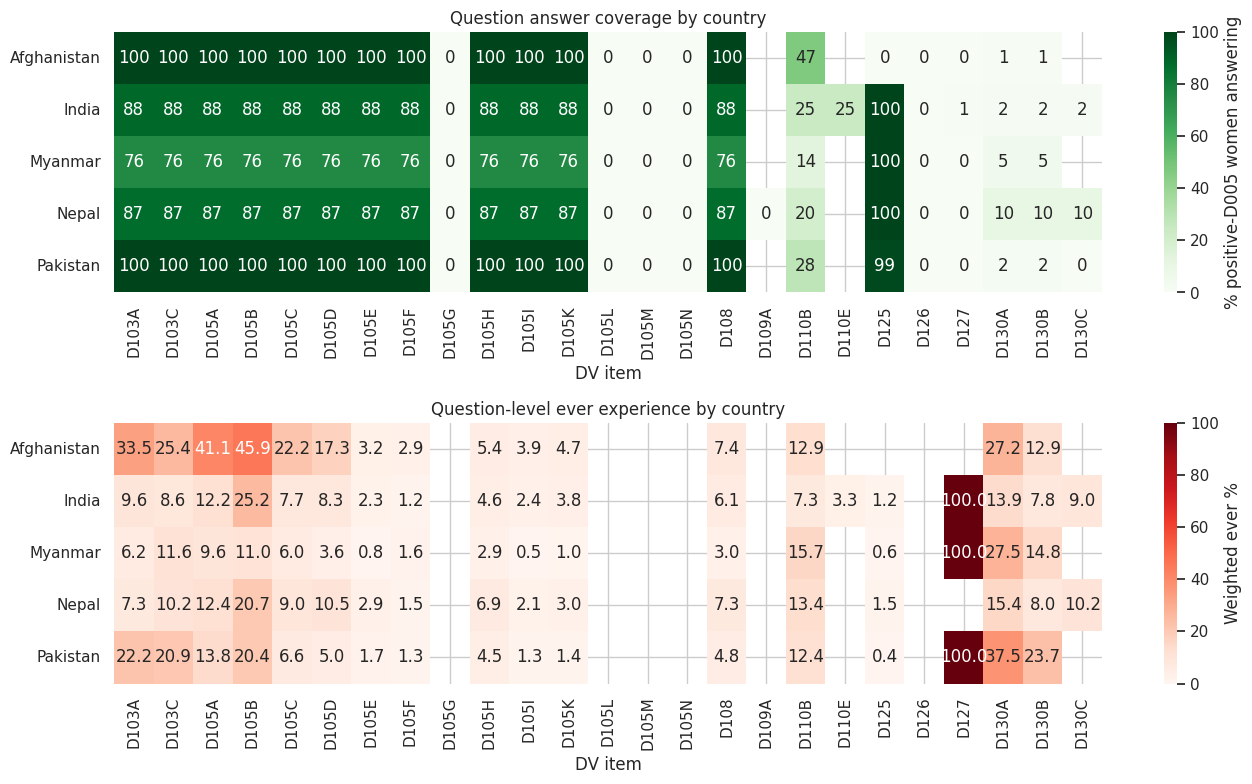

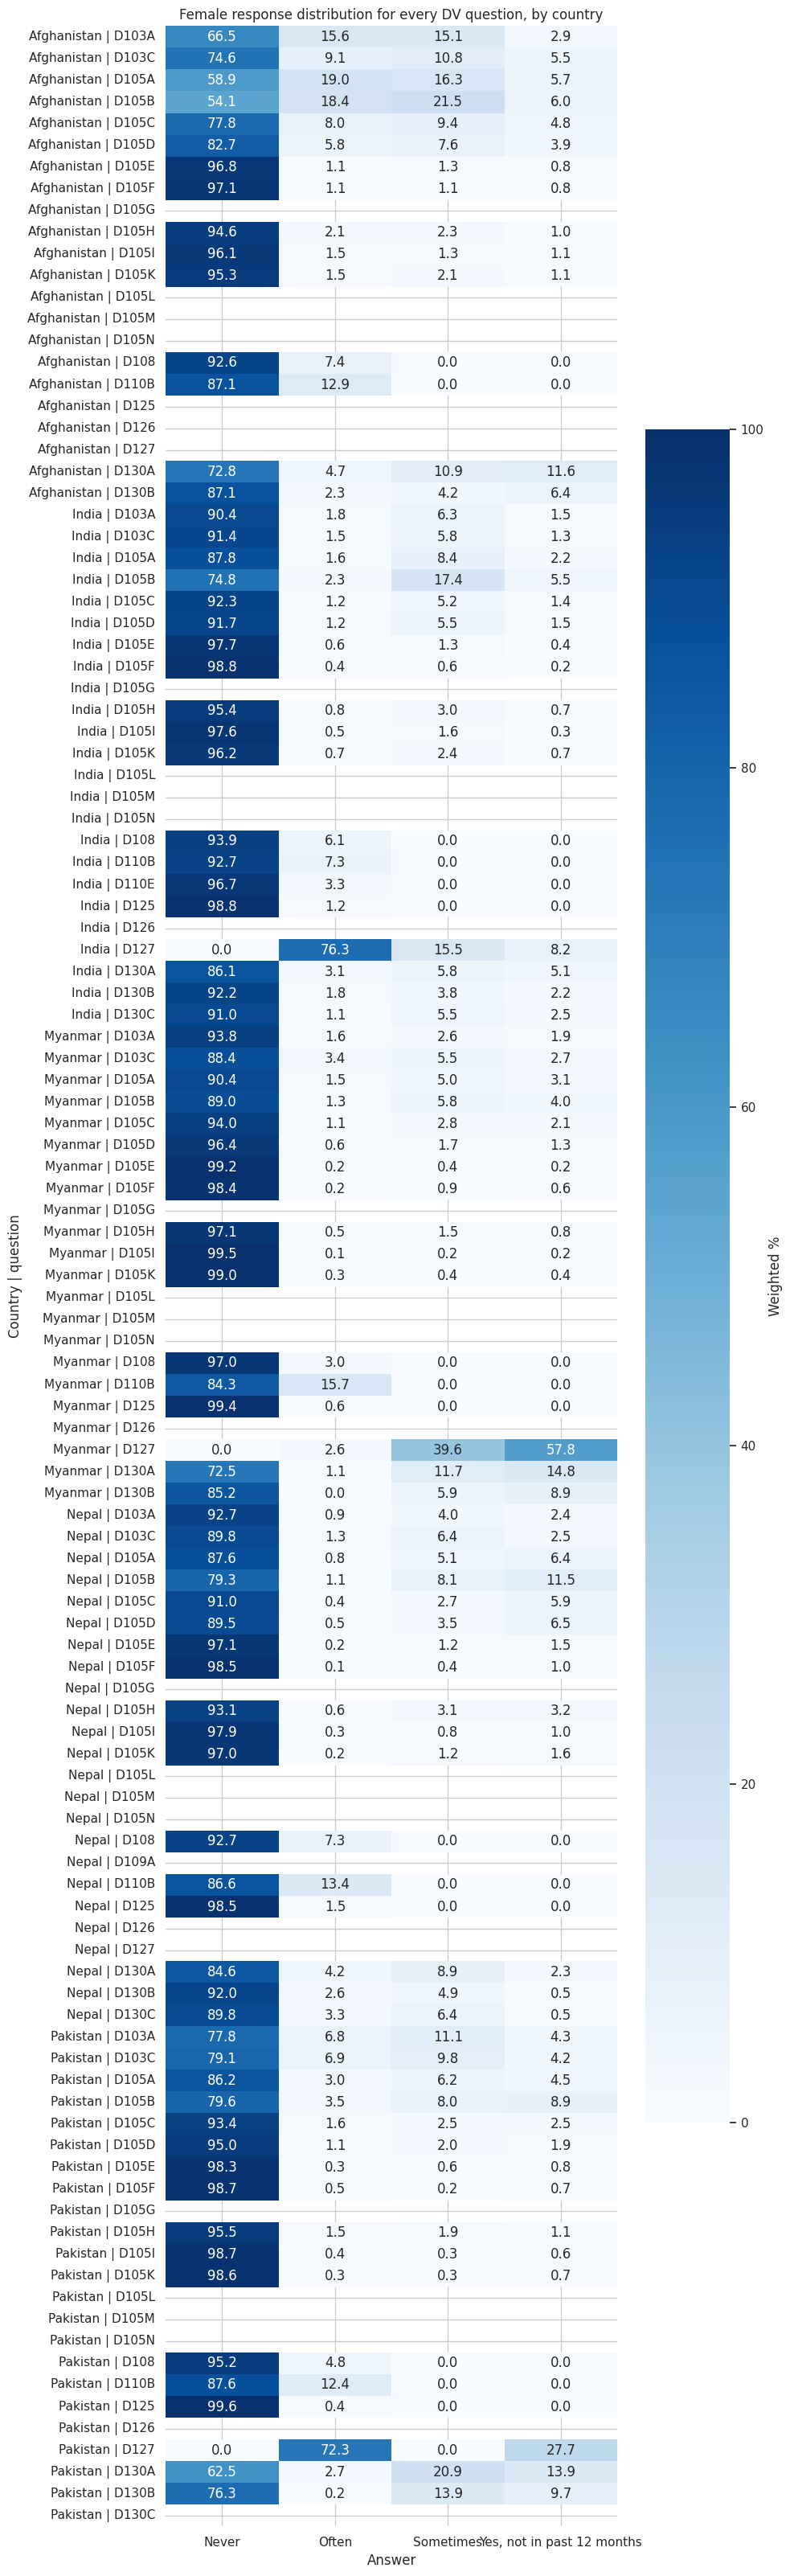

### Country-wise women reporting violence by domain

,country,indicator,weighted_pct,approx_ci_low,approx_ci_high,unweighted_n,effective_n
0,Afghanistan,ever_emotional,36.5%,35.3%,37.7%,"21,285","5,959"
1,Afghanistan,past12_emotional,33.7%,32.5%,34.9%,"21,285","5,959"
2,Afghanistan,ever_physical,50.2%,48.9%,51.5%,"21,307","5,967"
3,Afghanistan,past12_physical,45.8%,44.5%,47.1%,"21,307","5,967"
4,Afghanistan,ever_sexual,7.5%,6.9%,8.2%,"21,279","5,953"
5,Afghanistan,past12_sexual,7.5%,6.8%,8.2%,"21,279","5,953"
6,Afghanistan,ever_any,55.1%,53.9%,56.4%,"21,308","5,967"
7,Afghanistan,past12_any,51.7%,50.4%,53.0%,"21,308","5,967"
8,India,ever_emotional,12.9%,12.4%,13.4%,"63,851","17,140"
9,India,past12_emotional,11.1%,10.6%,11.6%,"63,851","17,140"


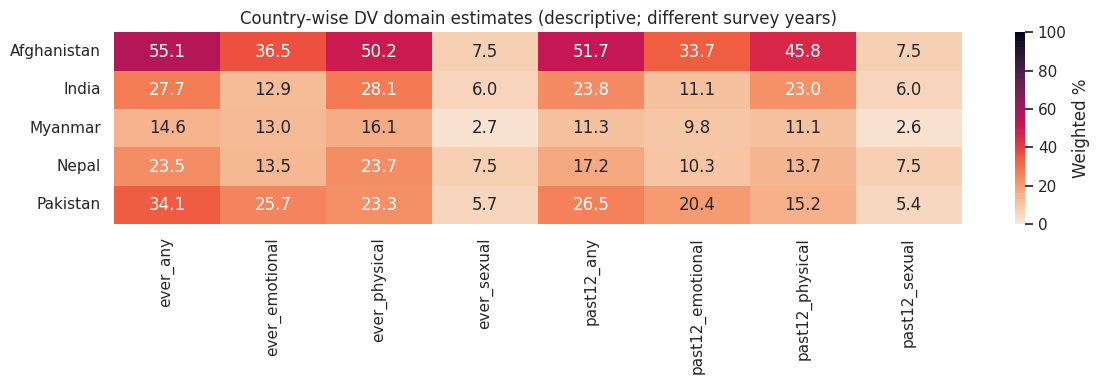

In [27]:
# ================================================================================================
# RECODE SOURCE
#   * Individual Recode (IR) - XXIRnnFL - one record per INTERVIEWED WOMAN 15-49 - D005 domestic-violence weight is mandatory here
# WHAT THIS CELL USES: D005 weight, discovered D1xx items, V012 V015 V021-V025 V106 V190 V501 background variables
# NOTE: HV044 / V044 are never used as an outcome in this cell
# (Annotation added only - every original line of this cell is kept unchanged.)
# ================================================================================================

def proportion_ci_unclustered(y, w, z=1.96):
    # Weighted proportion with an explicitly approximate effective-n CI (not design-correct).
    mask = y.notna() & w.notna() & (w > 0)
    if not mask.any(): return np.nan, np.nan, np.nan, 0, np.nan
    yy, ww = y[mask].astype(float), w[mask].astype(float)
    p = np.average(yy, weights=ww)
    neff = effective_n(ww)
    se = math.sqrt(max(p * (1 - p) / neff, 0)) if neff > 0 else np.nan
    return p, max(0, p-z*se), min(1, p+z*se), int(mask.sum()), neff

dv_results = []
dv_question_response_rows = []
dv_answer_count_rows = []
dv_denominator_flow = []
dv_subgroup_rows = []
if not ir_inventory.empty and not dv_item_registry.empty:
    for _, meta in ir_inventory.iterrows():
        schema = schemas[meta.stem]
        names = set(schema.name)
        reg = dv_item_registry[dv_item_registry.stem.eq(meta.stem)]
        item_cols = reg.name.tolist()
        if "D005" not in names:
            print(f"Skipping {meta.country}: D005 DV weight is absent.")
            continue
        base_cols = [c for c in ["V001", "V002", "V003", "V005", "D005", "V012", "V015", "V021", "V022", "V023", "V024", "V025", "V106", "V190", "V501"] if c in names]
        parts = []
        flow_total = flow_positive_weight = flow_answered_any = 0
        for chunk in iter_fwf(Path(meta.path), schema, base_cols + item_cols, nrows=None if RUN_FULL_SCAN else 100_000):
            chunk["dv_weight"] = chunk["D005"] / 1_000_000
            # Standard DHS DV items generally code often=1, sometimes=2, yes but not in last 12 months=3, never=0.
            # Special/missing codes are set missing, never treated as no.
            for c in item_cols:
                chunk[c] = chunk[c].where(chunk[c].isin([0, 1, 2, 3]))
            positive_weight = chunk.dv_weight.gt(0)
            answered_any_item = chunk[item_cols].notna().any(axis=1)
            answered_item_count = chunk[item_cols].notna().sum(axis=1)
            flow_total += len(chunk)
            flow_positive_weight += int(positive_weight.sum())
            flow_answered_any += int((positive_weight & answered_any_item).sum())
            for answered_count, gg in chunk.loc[positive_weight].groupby(answered_item_count[positive_weight], observed=True):
                dv_answer_count_rows.append({
                    "country": meta.country, "answered_item_count": int(answered_count),
                    "unweighted_n": len(gg), "weighted_n": gg.dv_weight.sum(),
                })
            for c in item_cols:
                domain = reg.loc[reg.name.eq(c), "domain"].iloc[0]
                label = reg.loc[reg.name.eq(c), "label"].iloc[0]
                for response_code in [0, 1, 2, 3]:
                    mask = positive_weight & chunk[c].eq(response_code)
                    dv_question_response_rows.append({
                        "country": meta.country, "item": c, "label": label, "domain": domain,
                        "response_code": response_code, "unweighted_n": int(mask.sum()),
                        "weighted_n": chunk.loc[mask, "dv_weight"].sum(),
                    })
            for domain in ["emotional", "physical", "sexual"]:
                cols = reg.loc[reg.domain.eq(domain), "name"].tolist()
                if cols:
                    valid = chunk[cols].notna().any(axis=1)
                    chunk[f"ever_{domain}"] = chunk[cols].isin([1, 2, 3]).any(axis=1).where(valid)
                    chunk[f"past12_{domain}"] = chunk[cols].isin([1, 2]).any(axis=1).where(valid)
            ever_cols = [c for c in chunk if c.startswith("ever_")]
            p12_cols = [c for c in chunk if c.startswith("past12_")]
            if ever_cols:
                valid = chunk[ever_cols].notna().any(axis=1)
                chunk["ever_any"] = chunk[ever_cols].eq(True).any(axis=1).where(valid)
            if p12_cols:
                valid = chunk[p12_cols].notna().any(axis=1)
                chunk["past12_any"] = chunk[p12_cols].eq(True).any(axis=1).where(valid)
            keep = ([c for c in chunk if c.startswith("ever_") or c.startswith("past12_")]
                    + [c for c in ["dv_weight", "V012", "V015", "V025", "V106", "V190", "V501"] if c in chunk])
            parts.append(chunk[keep])
        dv_denominator_flow.append({
            "country": meta.country, "all_IR_records": flow_total,
            "positive_D005_valid_DV_weight": flow_positive_weight,
            "positive_D005_and_answered_any_identified_item": flow_answered_any,
            "answer_coverage_pct_among_positive_D005": 100 * flow_answered_any / flow_positive_weight if flow_positive_weight else np.nan,
        })
        dv = pd.concat(parts, ignore_index=True)
        for indicator in [c for c in dv if c.startswith("ever_") or c.startswith("past12_")]:
            p, lo, hi, n, neff = proportion_ci_unclustered(dv[indicator], dv.dv_weight)
            dv_results.append({"country": meta.country, "indicator": indicator, "weighted_pct": 100*p,
                               "approx_ci_low": 100*lo, "approx_ci_high": 100*hi,
                               "unweighted_n": n, "effective_n": neff})

        subgroup_maps = {
            "residence": ("V025", {1: "Urban", 2: "Rural"}),
            "education": ("V106", {0: "No education", 1: "Primary", 2: "Secondary", 3: "Higher"}),
            "wealth": ("V190", {1: "Poorest", 2: "Poorer", 3: "Middle", 4: "Richer", 5: "Richest"}),
            "marital_status": ("V501", {0: "Never married", 1: "Married", 2: "Living together", 3: "Widowed", 4: "Divorced", 5: "Separated"}),
        }
        for indicator in [c for c in ["ever_any", "past12_any"] if c in dv]:
            for subgroup, (variable, labels) in subgroup_maps.items():
                if variable not in dv: continue
                for value, gg in dv.groupby(variable, observed=True):
                    p, lo, hi, n, neff = proportion_ci_unclustered(gg[indicator], gg.dv_weight)
                    dv_subgroup_rows.append({
                        "country": meta.country, "indicator": indicator, "subgroup": subgroup,
                        "category": labels.get(value, str(value)), "weighted_pct": 100*p,
                        "approx_ci_low": 100*lo, "approx_ci_high": 100*hi,
                        "unweighted_n": n, "effective_n": neff,
                    })

dv_results = pd.DataFrame(dv_results)
if not dv_results.empty:
    display(dv_results.style.format({"weighted_pct": "{:.1f}%", "approx_ci_low": "{:.1f}%", "approx_ci_high": "{:.1f}%", "effective_n": "{:,.0f}"}))

dv_denominator_flow = pd.DataFrame(dv_denominator_flow)
if not dv_denominator_flow.empty:
    display(Markdown("### Which women actually answered at least one identified DV question"))
    display(dv_denominator_flow.style.format({
        "all_IR_records": "{:,.0f}", "positive_D005_valid_DV_weight": "{:,.0f}",
        "positive_D005_and_answered_any_identified_item": "{:,.0f}",
        "answer_coverage_pct_among_positive_D005": "{:.1f}%",
    }))

dv_question_responses = pd.DataFrame(dv_question_response_rows)
if not dv_question_responses.empty:
    RESPONSE_LABELS = {0: "Never", 1: "Often", 2: "Sometimes", 3: "Yes, not in past 12 months"}
    dv_question_responses = (dv_question_responses
        .groupby(["country", "item", "label", "domain", "response_code"], as_index=False, observed=True)
        .agg(unweighted_n=("unweighted_n", "sum"), weighted_n=("weighted_n", "sum")))
    dv_question_responses["response"] = dv_question_responses.response_code.map(RESPONSE_LABELS)
    dv_question_responses["weighted_response_pct"] = 100 * dv_question_responses.weighted_n / dv_question_responses.groupby(["country", "item"]).weighted_n.transform("sum")
    display(Markdown("### Female answers to each identified violence question"))
    display(dv_question_responses.sort_values(["country", "domain", "item", "response_code"]).style.format({
        "unweighted_n": "{:,.0f}", "weighted_n": "{:,.1f}", "weighted_response_pct": "{:.1f}%"
    }))

    item_keys = ["country", "item", "label", "domain"]
    item_total = (dv_question_responses.groupby(item_keys, as_index=False, observed=True)
                  .agg(weighted_total=("weighted_n", "sum"), unweighted_answered_n=("unweighted_n", "sum")))
    item_yes = (dv_question_responses[dv_question_responses.response_code.isin([1, 2, 3])]
                .groupby(item_keys, as_index=False, observed=True).weighted_n.sum()
                .rename(columns={"weighted_n": "weighted_ever"}))
    item_ever = item_total.merge(item_yes, on=item_keys, how="left").fillna({"weighted_ever": 0})
    item_ever["weighted_ever_pct"] = 100 * item_ever.weighted_ever / item_ever.weighted_total
    display(Markdown("### Question-level weighted ever-experience estimates"))
    display(item_ever.sort_values(["country", "domain", "weighted_ever_pct"], ascending=[True, True, False]).style.format({
        "weighted_ever_pct": "{:.1f}%", "unweighted_answered_n": "{:,.0f}"
    }))

dv_subgroup_results = pd.DataFrame(dv_subgroup_rows)
if not dv_subgroup_results.empty:
    dv_subgroup_results["suppressed"] = dv_subgroup_results.unweighted_n < MIN_UNWEIGHTED_CELL
    for c in ["weighted_pct", "approx_ci_low", "approx_ci_high"]:
        dv_subgroup_results.loc[dv_subgroup_results.suppressed, c] = np.nan
    display(Markdown("### Any-violence estimates by female background subgroup (small cells suppressed)"))
    display(dv_subgroup_results.style.format({
        "weighted_pct": "{:.1f}%", "approx_ci_low": "{:.1f}%", "approx_ci_high": "{:.1f}%",
        "unweighted_n": "{:,.0f}", "effective_n": "{:,.0f}"
    }))

# Country-wise count of identified DV questions answered per valid DV-weight record.
dv_answer_count_distribution = pd.DataFrame(dv_answer_count_rows)
if not dv_answer_count_distribution.empty:
    dv_answer_count_distribution = (dv_answer_count_distribution
        .groupby(["country", "answered_item_count"], as_index=False, observed=True)
        .agg(unweighted_n=("unweighted_n", "sum"), weighted_n=("weighted_n", "sum")))
    dv_answer_count_distribution["weighted_pct"] = (
        100 * dv_answer_count_distribution.weighted_n /
        dv_answer_count_distribution.groupby("country").weighted_n.transform("sum")
    )
    display(Markdown("### Country-wise number of identified DV questions answered per woman"))
    display(dv_answer_count_distribution.style.format({
        "unweighted_n": "{:,.0f}", "weighted_n": "{:,.1f}", "weighted_pct": "{:.1f}%"
    }))
    plt.figure(figsize=(11, 5))
    sns.lineplot(data=dv_answer_count_distribution, x="answered_item_count", y="weighted_pct", hue="country", marker="o")
    plt.title("Country-wise DV item-answer completeness")
    plt.xlabel("Number of identified questions with a valid answer")
    plt.ylabel("Weighted percent of positive-D005 records")
    plt.tight_layout(); plt.show()

# Question-by-country answer coverage and ever-experience heatmaps.
question_country_dashboard = pd.DataFrame()
if not dv_question_responses.empty and not dv_denominator_flow.empty:
    denom = dv_denominator_flow[["country", "positive_D005_valid_DV_weight"]]
    question_country_dashboard = item_ever.merge(denom, on="country", how="left")
    question_country_dashboard["unweighted_answer_coverage_pct"] = (
        100 * question_country_dashboard.unweighted_answered_n /
        question_country_dashboard.positive_D005_valid_DV_weight.replace(0, np.nan)
    )
    display(Markdown("### Country-wise women answering each identified DV question"))
    display(question_country_dashboard.sort_values(["country", "domain", "item"]).style.format({
        "unweighted_answered_n": "{:,.0f}", "positive_D005_valid_DV_weight": "{:,.0f}",
        "unweighted_answer_coverage_pct": "{:.1f}%", "weighted_ever_pct": "{:.1f}%"
    }))

    coverage_heat = question_country_dashboard.pivot(index="country", columns="item", values="unweighted_answer_coverage_pct")
    ever_heat = question_country_dashboard.pivot(index="country", columns="item", values="weighted_ever_pct")
    fig, axes = plt.subplots(2, 1, figsize=(max(12, 0.55 * len(coverage_heat.columns)), 8))
    sns.heatmap(coverage_heat, annot=True, fmt=".0f", cmap="Greens", vmin=0, vmax=100,
                cbar_kws={"label": "% positive-D005 women answering"}, ax=axes[0])
    axes[0].set(title="Question answer coverage by country", xlabel="DV item", ylabel="")
    sns.heatmap(ever_heat, annot=True, fmt=".1f", cmap="Reds", vmin=0, vmax=100,
                cbar_kws={"label": "Weighted ever %"}, ax=axes[1])
    axes[1].set(title="Question-level ever experience by country", xlabel="DV item", ylabel="")
    plt.tight_layout(); plt.show()

    response_matrix = (dv_question_responses
        .assign(country_item=lambda x: x.country + " | " + x.item)
        .pivot(index="country_item", columns="response", values="weighted_response_pct"))
    plt.figure(figsize=(10, max(5, 0.28 * len(response_matrix))))
    sns.heatmap(response_matrix, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100, cbar_kws={"label": "Weighted %"})
    plt.title("Female response distribution for every DV question, by country")
    plt.xlabel("Answer"); plt.ylabel("Country | question"); plt.tight_layout(); plt.show()

# Country-wise domain-composite comparison; survey years differ, so this is descriptive rather than a ranking.
country_domain_comparison = pd.DataFrame()
if not dv_results.empty:
    country_domain_comparison = dv_results[dv_results.indicator.isin([
        "ever_emotional", "ever_physical", "ever_sexual", "ever_any",
        "past12_emotional", "past12_physical", "past12_sexual", "past12_any"
    ])].copy()
    display(Markdown("### Country-wise women reporting violence by domain"))
    display(country_domain_comparison.style.format({
        "weighted_pct": "{:.1f}%", "approx_ci_low": "{:.1f}%", "approx_ci_high": "{:.1f}%",
        "unweighted_n": "{:,.0f}", "effective_n": "{:,.0f}"
    }))
    domain_heat = country_domain_comparison.pivot(index="country", columns="indicator", values="weighted_pct")
    plt.figure(figsize=(12, max(4, 0.7 * len(domain_heat))))
    sns.heatmap(domain_heat, annot=True, fmt=".1f", cmap="rocket_r", vmin=0, vmax=100, cbar_kws={"label": "Weighted %"})
    plt.title("Country-wise DV domain estimates (descriptive; different survey years)")
    plt.xlabel(""); plt.ylabel(""); plt.tight_layout(); plt.show()

## 13. Small-cell protection, exports, and interpretation checklist

Use these rules before sharing any subgroup result:

- Suppress estimates with unweighted denominator below `MIN_UNWEIGHTED_CELL` (default 25); consider stricter DHS reporting thresholds.
- Use `D005`, not `V005` or `HV005`, for the domestic-violence subsample.
- Restrict to the exact eligible/selected/interviewed DV universe documented for that survey.
- Distinguish “ever” from “past 12 months.” Never combine special codes with “no.”
- Treat confidence intervals in the guarded section as approximate until PSU/strata design is implemented and verified.
- Do not interpret differences across survey years as contemporaneous country rankings.
- Discuss under-reporting, disclosure safety, questionnaire mode, and social desirability bias.

In [28]:
# ================================================================================================
# RECODE SOURCE
#   * Household Recode (HR)  - XXHRnnFL - one record per HOUSEHOLD, Household Member Recode (PR) - XXPRnnFL - one record per LISTED HOUSEHOLD MEMBER, Individual Recode (IR) - XXIRnnFL - one record per INTERVIEWED WOMAN 15-49 - all summary tables produced above
# WHAT THIS CELL USES: export of every audit / EDA table to OUTPUT_DIR as CSV
# (Annotation added only - every original line of this cell is kept unchanged.)
# ================================================================================================

# Export analysis-ready summaries; no direct identifiers are included.
inventory.drop(columns="path").to_csv(OUTPUT_DIR / "archive_inventory.csv", index=False)
suitability.to_csv(OUTPUT_DIR / "dv_suitability_audit.csv", index=False)
quality.to_csv(OUTPUT_DIR / "data_quality_summary.csv", index=False)
missingness.to_csv(OUTPUT_DIR / "analysis_missingness.csv", index=False)
hh_summary.to_csv(OUTPUT_DIR / "weighted_household_summary.csv", index=False)
person_summary.to_csv(OUTPUT_DIR / "weighted_person_summary.csv", index=False)
pd.DataFrame(female_availability).to_csv(OUTPUT_DIR / "female_question_availability.csv", index=False)
female_flow.to_csv(OUTPUT_DIR / "female_sample_flow.csv", index=False)
female_profile.to_csv(OUTPUT_DIR / "weighted_female_15_49_profile.csv", index=False)
female_education.to_csv(OUTPUT_DIR / "weighted_female_education.csv", index=False)
female_marital.to_csv(OUTPUT_DIR / "weighted_female_marital_status.csv", index=False)
selection_coverage.to_csv(OUTPUT_DIR / "female_DV_selection_coverage.csv", index=False)
country_women_dashboard.to_csv(OUTPUT_DIR / "country_wise_women_dashboard.csv", index=False)
female_country_flow.to_csv(OUTPUT_DIR / "country_wise_female_sample_flow.csv", index=False)
country_women_distributions.to_csv(OUTPUT_DIR / "country_wise_women_background_distributions.csv", index=False)
country_female_completeness.to_csv(OUTPUT_DIR / "country_wise_female_field_completeness.csv", index=False)
if not dv_results.empty:
    export_dv = dv_results.copy()
    export_dv.loc[export_dv.unweighted_n < MIN_UNWEIGHTED_CELL, ["weighted_pct", "approx_ci_low", "approx_ci_high"]] = np.nan
    export_dv.to_csv(OUTPUT_DIR / "weighted_dv_summary_SUPPRESSED.csv", index=False)
if not dv_question_responses.empty:
    dv_question_responses.to_csv(OUTPUT_DIR / "female_DV_question_response_distribution.csv", index=False)
    item_ever.to_csv(OUTPUT_DIR / "female_DV_question_ever_estimates.csv", index=False)
if not dv_denominator_flow.empty:
    dv_denominator_flow.to_csv(OUTPUT_DIR / "female_DV_answer_denominator_flow.csv", index=False)
if not dv_subgroup_results.empty:
    dv_subgroup_results.to_csv(OUTPUT_DIR / "female_DV_subgroup_estimates_SUPPRESSED.csv", index=False)
if not dv_answer_count_distribution.empty:
    dv_answer_count_distribution.to_csv(OUTPUT_DIR / "country_wise_DV_items_answered_distribution.csv", index=False)
if not question_country_dashboard.empty:
    question_country_dashboard.to_csv(OUTPUT_DIR / "country_wise_DV_question_answer_dashboard.csv", index=False)
if not country_domain_comparison.empty:
    country_domain_comparison.to_csv(OUTPUT_DIR / "country_wise_DV_domain_comparison.csv", index=False)

print("Output files:")
for p in sorted(OUTPUT_DIR.glob("*.csv")):
    print(" -", p)

Output files:
 - /kaggle/working/analysis_missingness.csv
 - /kaggle/working/archive_inventory.csv
 - /kaggle/working/complete_data_dictionary.csv
 - /kaggle/working/country_wise_DV_domain_comparison.csv
 - /kaggle/working/country_wise_DV_items_answered_distribution.csv
 - /kaggle/working/country_wise_DV_question_answer_dashboard.csv
 - /kaggle/working/country_wise_female_field_completeness.csv
 - /kaggle/working/country_wise_female_sample_flow.csv
 - /kaggle/working/country_wise_women_background_distributions.csv
 - /kaggle/working/country_wise_women_dashboard.csv
 - /kaggle/working/data_quality_summary.csv
 - /kaggle/working/dataset_structure_summary.csv
 - /kaggle/working/dv_suitability_audit.csv
 - /kaggle/working/female_DV_answer_denominator_flow.csv
 - /kaggle/working/female_DV_question_ever_estimates.csv
 - /kaggle/working/female_DV_question_response_distribution.csv
 - /kaggle/working/female_DV_selection_coverage.csv
 - /kaggle/working/female_DV_subgroup_estimates_SUPPRESSED.cs

---

# Part II — Added analysis (sections 14–23)

Everything above is unchanged. The sections below are **additions** that close the three gaps in Part I:

| Gap in Part I | Added in |
|---|---|
| Every code cell used a recode file without saying which one | Recode-source comment banners on all original code cells, plus the machine-readable map in **§14** |
| The **Individual Recode (IR)** — the actual women's file — was only used in the guarded DV block; there was no IR EDA | **§15** IR structure audit, **§16** full weighted IR EDA (women 15–49, all seven countries) |
| No analysis dataset and no models | **§17** dataset construction → CSV, **§18** profiles (PCA + clustering), **§19** traditional ML model zoo, **§20** interactions, **§21** cross-country variation, **§22** secondary target, **§23** synthesis |

### Research question driving §17–§23

> **What distinct demographic and socioeconomic profiles of women and households can be identified across South Asian countries, how do these profiles interact, and to what extent are their combinations associated with household selection for the DHS domestic-violence module?**

It decomposes into four estimable parts:

1. **Profiles** — unsupervised segmentation of women/households (PCA + K-Means + Gaussian mixture) on harmonised IR variables.
2. **Interactions** — explicit product terms, tree-based interaction detection, two-way partial dependence, and interaction odds ratios.
3. **Cross-country variation** — per-country models, leave-one-country-out generalisation, country-specific importance profiles.
4. **DV-module selection** — supervised prediction of `V044` (*Selected for Domestic Violence module*).

### What `V044` is, and why the modelling is framed as a design audit

`V044` is the IR counterpart of `HV044`. Codes: `0 = woman not selected`, `1 = selected and interviewed`, `2 = selected but privacy not possible`, `3 = selected but not interviewed`.

DHS selects **one eligible woman per selected household** for the module. So selection is, by design, a two-stage random mechanism:

```
P(selected) = P(household in the DV sub-sample) x 1 / (number of eligible women in the household)
```

That makes `V138` (*number of eligible women in the household*) a mechanical predictor, and it makes the sub-sample fraction a country-level design constant. The analytically honest question is therefore **not** "can we predict selection?" but:

> **Does any woman/household profile carry information about selection beyond what the sampling design already implies?**

If profiles add nothing beyond `V138` + country, the randomisation held and DV estimates are internally valid. If they add signal, DV respondents are a profile-skewed subset of eligible women and every published DV prevalence inherits that skew. §20 answers this with nested feature blocks; the same machinery answers the profile / interaction / cross-country parts of the research question.

Two targets are modelled:

| Target | Definition | Interpretation |
|---|---|---|
| `y_selected` (primary) | `V044 ∈ {1, 2, 3}` | Woman drawn for the DV module |
| `y_completed` (secondary) | `V044 = 1` | Drawn **and** the module was actually administered (adds sub-sampling, privacy and non-response) |

**No cell below treats `V044` or `HV044` as an experience of violence.** DV prevalence is estimated only from `D1xx` items with the `D005` weight (§16).

In [29]:
# ================================================================================================
# RECODE SOURCE
#   * Documentation cell - builds the machine-readable map of WHICH RECODE every section reads.
#     HR = Household Recode (one row per household)
#     PR = Household Member Recode (one row per listed household member)
#     IR = Individual Recode (one row per interviewed woman 15-49)   <- added sections 15-23
# WHAT THIS CELL USES: no survey data; only the section -> recode -> variable mapping.
# ================================================================================================
# 14. Recode-usage map: which recode file each section of this notebook reads
import gc

RECODE_LEGEND = pd.DataFrame([
    {"recode": "HR", "file_pattern": "XXHRnnFL", "unit_of_analysis": "Household",
     "variable_prefix": "HV0xx / HV2xx", "in_this_project": "AFHR71FL, BDHR81FL (+ extra HR packages in 'DHS HM-H Recode')",
     "supports": "household composition, assets, wealth, HV044 DV-module selection flag",
     "cannot_support": "any woman-level answer, any violence answer"},
    {"recode": "PR", "file_pattern": "XXPRnnFL", "unit_of_analysis": "Listed household member",
     "variable_prefix": "HV1xx (+ repeated HV0xx)", "in_this_project": "IAPR7EFL, MMPR71FL, NPPR82FL, PKPR71FL",
     "supports": "age-sex structure, roster-based female study frame, HV117 eligibility flag",
     "cannot_support": "interview completion, violence answers, DV weight"},
    {"recode": "IR", "file_pattern": "XXIRnnFL", "unit_of_analysis": "Interviewed woman 15-49",
     "variable_prefix": "V0xx-V8xx and D1xx", "in_this_project": "AFIR71FL, BDIR81FL, IAIR7EFL, LKIR02FL, MMIR71FL, NPIR82FL, PKIR71FL",
     "supports": "woman + household socio-economics, V015 interview result, V044 DV selection, D1xx violence items with D005 weight",
     "cannot_support": "non-interviewed women, men, household members who are not eligible women"},
])
display(Markdown("### Recode legend"))
display(RECODE_LEGEND)

RECODE_SECTION_MAP = pd.DataFrame([
    ("1",  "Imports and reproducibility",                    "none",     "-",                                              "configuration only"),
    ("2",  "File discovery and archive inventory",           "HR+PR+IR", "file stems only",                                "recode type = characters 3-4 of the stem"),
    ("3",  "Read the complete dataset structures",           "HR+PR+IR", "SAS layout + FRQ record counts",                 "schema only, no data rows"),
    ("4",  "Domestic-violence suitability audit",            "HR+PR+IR", "HV044, D005, D1xx names/labels",                 "HV044 is a selection flag, not an outcome"),
    ("5",  "Memory-safe full-record reader",                 "HR+PR",    "COMMON_HH, COMMON_PERSON",                       "iter_fwf is reused for IR in sections 15-22"),
    ("6",  "Full-scan quality and harmonised tables",        "HR+PR",    "HV005 HV009 HV010 HV024 HV025 HV044 HV270 HV1xx", "IR files intentionally excluded here"),
    ("7",  "EDA: household context",                         "HR+PR",    "HV009 HV010 HV025 HV044 HV270",                  "weighted by HV005/1e6"),
    ("8",  "EDA: household members",                         "PR",       "HV104 HV105",                                    "PR countries only"),
    ("9",  "Female study population and availability",       "PR (+IR schema)", "HV104 HV105 HV117 HV044",                 "roster flags only"),
    ("10", "Country-wise women's EDA dashboard",             "PR",       "HV105 HV106 HV115 HV025 HV270",                  "roster characteristics, not interview answers"),
    ("11", "Domestic-violence questionnaire study map",      "IR (plan)", "D1xx, V744A-E, V015, D005",                     "planning table only"),
    ("12", "Guarded domestic-violence analysis",             "IR",       "D005 + auto-discovered D1xx items",              "fails closed without D005"),
    ("13", "Small-cell protection and exports",              "HR+PR+IR", "all summary tables",                             "suppression threshold MIN_UNWEIGHTED_CELL"),
    ("14", "Recode-usage map  (ADDED)",                      "none",     "-",                                              "this cell"),
    ("15", "IR structure and availability audit  (ADDED)",   "IR",       "SAS layouts of the 7 IR packages",               "no data rows"),
    ("16", "IR EDA: weighted profile of women 15-49  (ADDED)", "IR",     "V0xx-V8xx background + curated D1xx + D005",     "the IR EDA missing from Part I"),
    ("17", "ML dataset construction  (ADDED)",               "IR",       "harmonised features + V044 targets",             "writes the modelling CSV"),
    ("18", "Profiles: PCA + clustering  (ADDED)",            "IR",       "standardised numeric feature matrix",            "answers the 'profiles' part of the RQ"),
    ("19", "Traditional ML model zoo  (ADDED)",              "IR",       "feature matrix + y_selected",                    "NB, DT, RF, ET, AdaBoost, GBM, HGB, KNN, SVM, PCA+SVM, XGBoost, LightGBM"),
    ("20", "Design vs profile, interactions  (ADDED)",       "IR",       "nested feature blocks + interaction terms",       "answers the 'interactions' part of the RQ"),
    ("21", "Cross-country variation  (ADDED)",               "IR",       "per-country and leave-one-country-out models",    "answers the 'cross-country' part of the RQ"),
    ("22", "Secondary target: module completion  (ADDED)",   "IR",       "y_completed and interviewed|selected",            "sub-sampling, privacy and non-response"),
    ("23", "Synthesis and exports  (ADDED)",                 "IR",       "all model and profile tables",                    "answer to the research question"),
], columns=["section", "title", "recode_used", "key_variables", "note"])

display(Markdown("### Section -> recode map (Part I unchanged, Part II added)"))
display(RECODE_SECTION_MAP)

# --- shared helpers used by every added section ---------------------------------------------------
# groupby(...).apply() changed its handling of the grouping columns across pandas versions, so the
# added sections build per-group summaries with an explicit loop instead. Same result, no warnings.
def summarise_groups(frame, by, fn, sort=True):
    """fn(sub_frame) -> dict, evaluated for each group. Returns a DataFrame indexed by the key."""
    keys, records = [], []
    for key, sub in frame.groupby(by, sort=sort, observed=True):
        keys.append(key)
        records.append(fn(sub))
    out = pd.DataFrame(records)
    if isinstance(by, str):
        out.index = pd.Index(keys, name=by)
    else:
        out.index = pd.MultiIndex.from_tuples(keys, names=list(by))
    return out


# NOTE ON NAMING. Section 5 already defines weighted_percent(series, weights), which returns the
# weighted percentage of EVERY category as a Series, and proportion_ci_unclustered(y, w), which
# returns a 5-tuple from WEIGHTED inputs. Both stay exactly as they are. The added sections need two
# different shapes - a single scalar percentage, and an unweighted Wilson interval - so they get
# their own names rather than changing the existing helpers.
def weighted_share(indicator, weights, value=1):
    """Weighted percentage of rows where `indicator == value`, ignoring missing values."""
    mask = indicator.notna() & weights.notna() & weights.gt(0)
    if not mask.any():
        return np.nan
    total = weights[mask].sum()
    if not total:
        return np.nan
    return 100.0 * weights[mask & indicator.eq(value)].sum() / total


def wilson_ci(successes, n, z=1.96):
    """Unweighted Wilson score interval. Honest about being unweighted and design-naive."""
    if not n:
        return np.nan, np.nan
    p = successes / n
    denom = 1 + z ** 2 / n
    centre = (p + z ** 2 / (2 * n)) / denom
    half = z * math.sqrt(max(p * (1 - p) / n + z ** 2 / (4 * n ** 2), 0)) / denom
    return max(0.0, centre - half), min(1.0, centre + half)


RECODE_LEGEND.to_csv(OUTPUT_DIR / "recode_legend.csv", index=False)
RECODE_SECTION_MAP.to_csv(OUTPUT_DIR / "recode_section_map.csv", index=False)
print("Saved:", OUTPUT_DIR / "recode_section_map.csv")

### Recode legend

,recode,file_pattern,unit_of_analysis,variable_prefix,in_this_project,supports,cannot_support
0,HR,XXHRnnFL,Household,HV0xx / HV2xx,"AFHR71FL, BDHR81FL (+ extra HR packages in 'DH...","household composition, assets, wealth, HV044 D...","any woman-level answer, any violence answer"
1,PR,XXPRnnFL,Listed household member,HV1xx (+ repeated HV0xx),"IAPR7EFL, MMPR71FL, NPPR82FL, PKPR71FL","age-sex structure, roster-based female study f...","interview completion, violence answers, DV weight"
2,IR,XXIRnnFL,Interviewed woman 15-49,V0xx-V8xx and D1xx,"AFIR71FL, BDIR81FL, IAIR7EFL, LKIR02FL, MMIR71...","woman + household socio-economics, V015 interv...","non-interviewed women, men, household members ..."


### Section -> recode map (Part I unchanged, Part II added)

,section,title,recode_used,key_variables,note
0,1,Imports and reproducibility,none,-,configuration only
1,2,File discovery and archive inventory,HR+PR+IR,file stems only,recode type = characters 3-4 of the stem
2,3,Read the complete dataset structures,HR+PR+IR,SAS layout + FRQ record counts,"schema only, no data rows"
3,4,Domestic-violence suitability audit,HR+PR+IR,"HV044, D005, D1xx names/labels","HV044 is a selection flag, not an outcome"
4,5,Memory-safe full-record reader,HR+PR,"COMMON_HH, COMMON_PERSON",iter_fwf is reused for IR in sections 15-22
5,6,Full-scan quality and harmonised tables,HR+PR,HV005 HV009 HV010 HV024 HV025 HV044 HV270 HV1xx,IR files intentionally excluded here
6,7,EDA: household context,HR+PR,HV009 HV010 HV025 HV044 HV270,weighted by HV005/1e6
7,8,EDA: household members,PR,HV104 HV105,PR countries only
8,9,Female study population and availability,PR (+IR schema),HV104 HV105 HV117 HV044,roster flags only
9,10,Country-wise women's EDA dashboard,PR,HV105 HV106 HV115 HV025 HV270,"roster characteristics, not interview answers"


Saved: /kaggle/working/recode_section_map.csv


## 15. Individual Recode (IR) structure and variable-availability audit

**Recode used: Individual Recode (IR) — one record per interviewed woman aged 15–49.**

Part I audited the HR and PR schemas in detail but never audited the IR schemas, even though the IR files are the only ones that contain women's own answers. This section fixes that. It reads **layouts only** (no data rows), so it is cheap.

Three things are established before any IR data are read:

1. **Structure** — record length, official unweighted record count, number of fields.
2. **Analysis-variable availability** — DHS keeps a variable in the layout even when it was not asked, and labels it `NA - ...`. A column that is present-but-`NA` is *not* usable, so availability is scored as **Available / NA (not asked) / Absent**.
3. **DV-module capability** — whether `V044` is real (not `NA`), whether `D005` exists, and how many `D1xx` items were fielded.

Expected outcome for the supplied archives: Afghanistan, India, Myanmar, Nepal and Pakistan carry a fielded DV module; Bangladesh 2022 carries `V044` as `NA` and no `D1xx` items; Sri Lanka 1987 is a DHS-I file that predates the module entirely. Those three facts decide which countries enter the models in §17–§22.

In [30]:
# ================================================================================================
# RECODE SOURCE
#   * Individual Recode (IR) - XXIRnnFL - one record per interviewed woman 15-49
# WHAT THIS CELL USES: the parsed SAS layouts only (no .DAT rows are read).
# ================================================================================================
# 15a. IR structure table

# Survey-year labels for IR waves that are not represented among the HR/PR EXPECTED stems.
IR_SURVEY_OVERRIDE = {
    "AFIR71FL": "2015",
    "BDIR81FL": "2022",
    "IAIR7EFL": "2019-21",
    "LKIR02FL": "1987",
    "MMIR71FL": "2015-16",
    "NPIR82FL": "2022",
    "PKIR71FL": "2017-18",
}
IR_SURVEY_YEAR = {  # numeric mid-point of fieldwork, used later as a model feature
    "AFIR71FL": 2015, "BDIR81FL": 2022, "IAIR7EFL": 2020,
    "LKIR02FL": 1987, "MMIR71FL": 2016, "NPIR82FL": 2022, "PKIR71FL": 2018,
}

ir_archives = inventory[inventory.recode.eq("IR")].copy()
ir_archives["survey"] = ir_archives.stem.map(IR_SURVEY_OVERRIDE).fillna(ir_archives.survey)
ir_archives["survey_year"] = ir_archives.stem.map(IR_SURVEY_YEAR)
ir_archives = ir_archives.sort_values("country").reset_index(drop=True)

if ir_archives.empty:
    raise FileNotFoundError(
        "No Individual Recode (IR) package was discovered. Sections 15-23 need the XXIRnnFL "
        "folders/zips under KAGGLE_DATASET_ROOT."
    )


def label_of(stem, var):
    """Return the SAS label of a variable in one archive ('' when the variable is absent)."""
    s = schemas[stem]
    hit = s.loc[s.name.eq(var.upper()), "label"]
    return hit.iloc[0] if len(hit) else ""


def variable_status(stem, var):
    """Available / NA (present in layout but never asked) / Absent."""
    s = schemas[stem]
    if var.upper() not in set(s.name):
        return "Absent"
    return "NA" if label_of(stem, var).strip().upper().startswith("NA -") else "Available"


ir_structure_rows = []
for _, meta in ir_archives.iterrows():
    schema = schemas[meta.stem]
    names = set(schema.name)
    d_items = sorted(n for n in names if re.fullmatch(r"D\d{3}[A-Z]?", n) and n != "D005"
                     and not label_of(meta.stem, n).strip().upper().startswith("NA -"))
    struct = structure_summary.loc[structure_summary.stem.eq(meta.stem)]
    ir_structure_rows.append({
        "country": meta.country,
        "survey": meta.survey,
        "survey_year": meta.survey_year,
        "stem": meta.stem,
        "record_length": struct.record_length.iloc[0] if len(struct) else np.nan,
        "official_unweighted_women": struct.official_unweighted_records.iloc[0] if len(struct) else np.nan,
        "layout_fields": len(schema),
        "V044_status": variable_status(meta.stem, "V044"),
        "V015_status": variable_status(meta.stem, "V015"),
        "D005_status": variable_status(meta.stem, "D005"),
        "fielded_D1xx_items": len(d_items),
        "DV_module_fielded": variable_status(meta.stem, "D005") == "Available" and len(d_items) > 0,
        "usable_for_V044_modelling": variable_status(meta.stem, "V044") == "Available",
    })

ir_structure = pd.DataFrame(ir_structure_rows)
display(Markdown("### IR archive structure and DV-module capability"))
display(ir_structure.style.format({
    "official_unweighted_women": "{:,.0f}", "record_length": "{:,.0f}", "layout_fields": "{:,.0f}",
    "fielded_D1xx_items": "{:,.0f}",
}))

MODEL_COUNTRIES = ir_structure.loc[ir_structure.usable_for_V044_modelling, "country"].tolist()
DV_PREVALENCE_COUNTRIES = ir_structure.loc[ir_structure.DV_module_fielded, "country"].tolist()
print("Countries usable for V044 selection modelling (sections 17-22):", MODEL_COUNTRIES)
print("Countries usable for D1xx violence prevalence (section 16):    ", DV_PREVALENCE_COUNTRIES)
excluded = sorted(set(ir_structure.country) - set(MODEL_COUNTRIES))
if excluded:
    print("Excluded from modelling (V044 absent or NA):                  ", excluded)

ir_structure.to_csv(OUTPUT_DIR / "ir_structure_audit.csv", index=False)

### IR archive structure and DV-module capability

,country,survey,survey_year,stem,record_length,official_unweighted_women,layout_fields,V044_status,V015_status,D005_status,fielded_D1xx_items,DV_module_fielded,usable_for_V044_modelling
0,Afghanistan,2015,2015,AFIR71FL,"8,802","29,461","5,176",Available,Available,Available,74,True,True
1,Bangladesh,2022,2022,BDIR81FL,"8,712","30,078","5,425",NA,Available,Absent,0,False,False
2,India,2019-21,2020,IAIR7EFL,"9,637","724,115","5,972",Available,Available,Available,80,True,True
3,Myanmar,2015-16,2016,MMIR71FL,"8,579","12,885","4,993",Available,Available,Available,82,True,True
4,Nepal,2022,2022,NPIR82FL,"9,303","14,845","5,968",Available,Available,Available,98,True,True
5,Pakistan,2017-18,2018,PKIR71FL,"9,071","15,068","5,331",Available,Available,Available,82,True,True
6,Sri Lanka,1987,1987,LKIR02FL,nan,nan,"1,393",Absent,Absent,Absent,0,False,False


Countries usable for V044 selection modelling (sections 17-22): ['Afghanistan', 'India', 'Myanmar', 'Nepal', 'Pakistan']
Countries usable for D1xx violence prevalence (section 16):     ['Afghanistan', 'India', 'Myanmar', 'Nepal', 'Pakistan']
Excluded from modelling (V044 absent or NA):                   ['Bangladesh', 'Sri Lanka']


### Availability of every planned IR variable (Available / NA = in layout but never asked / Absent)

country,group,variable,description,Afghanistan,Bangladesh,India,Myanmar,Nepal,Pakistan,Sri Lanka
0,attitudes,V744A,Beating justified: goes out without telling hu...,Available,Available,Available,Available,Available,Available,Absent
1,attitudes,V744B,Beating justified: neglects the children,Available,Available,Available,Available,Available,Available,Absent
2,attitudes,V744C,Beating justified: argues with husband,Available,Available,Available,Available,Available,Available,Absent
3,attitudes,V744D,Beating justified: refuses sex,Available,Available,Available,Available,Available,Available,Absent
4,attitudes,V744E,Beating justified: burns the food,Available,Available,Available,Available,Available,Available,Absent
...,...,...,...,...,...,...,...,...,...,...
136,wealth,V190,Wealth index quintile,Available,Available,Available,Available,Available,Available,Absent
137,wealth,V191,Wealth index factor score (5 dp),Available,Available,Available,Available,Available,Available,Absent
138,work,V714,Respondent currently working,Available,Available,Available,Available,Available,Available,Available
139,work,V717,Respondent's occupation (grouped),Available,Available,Available,Available,Available,Available,Absent


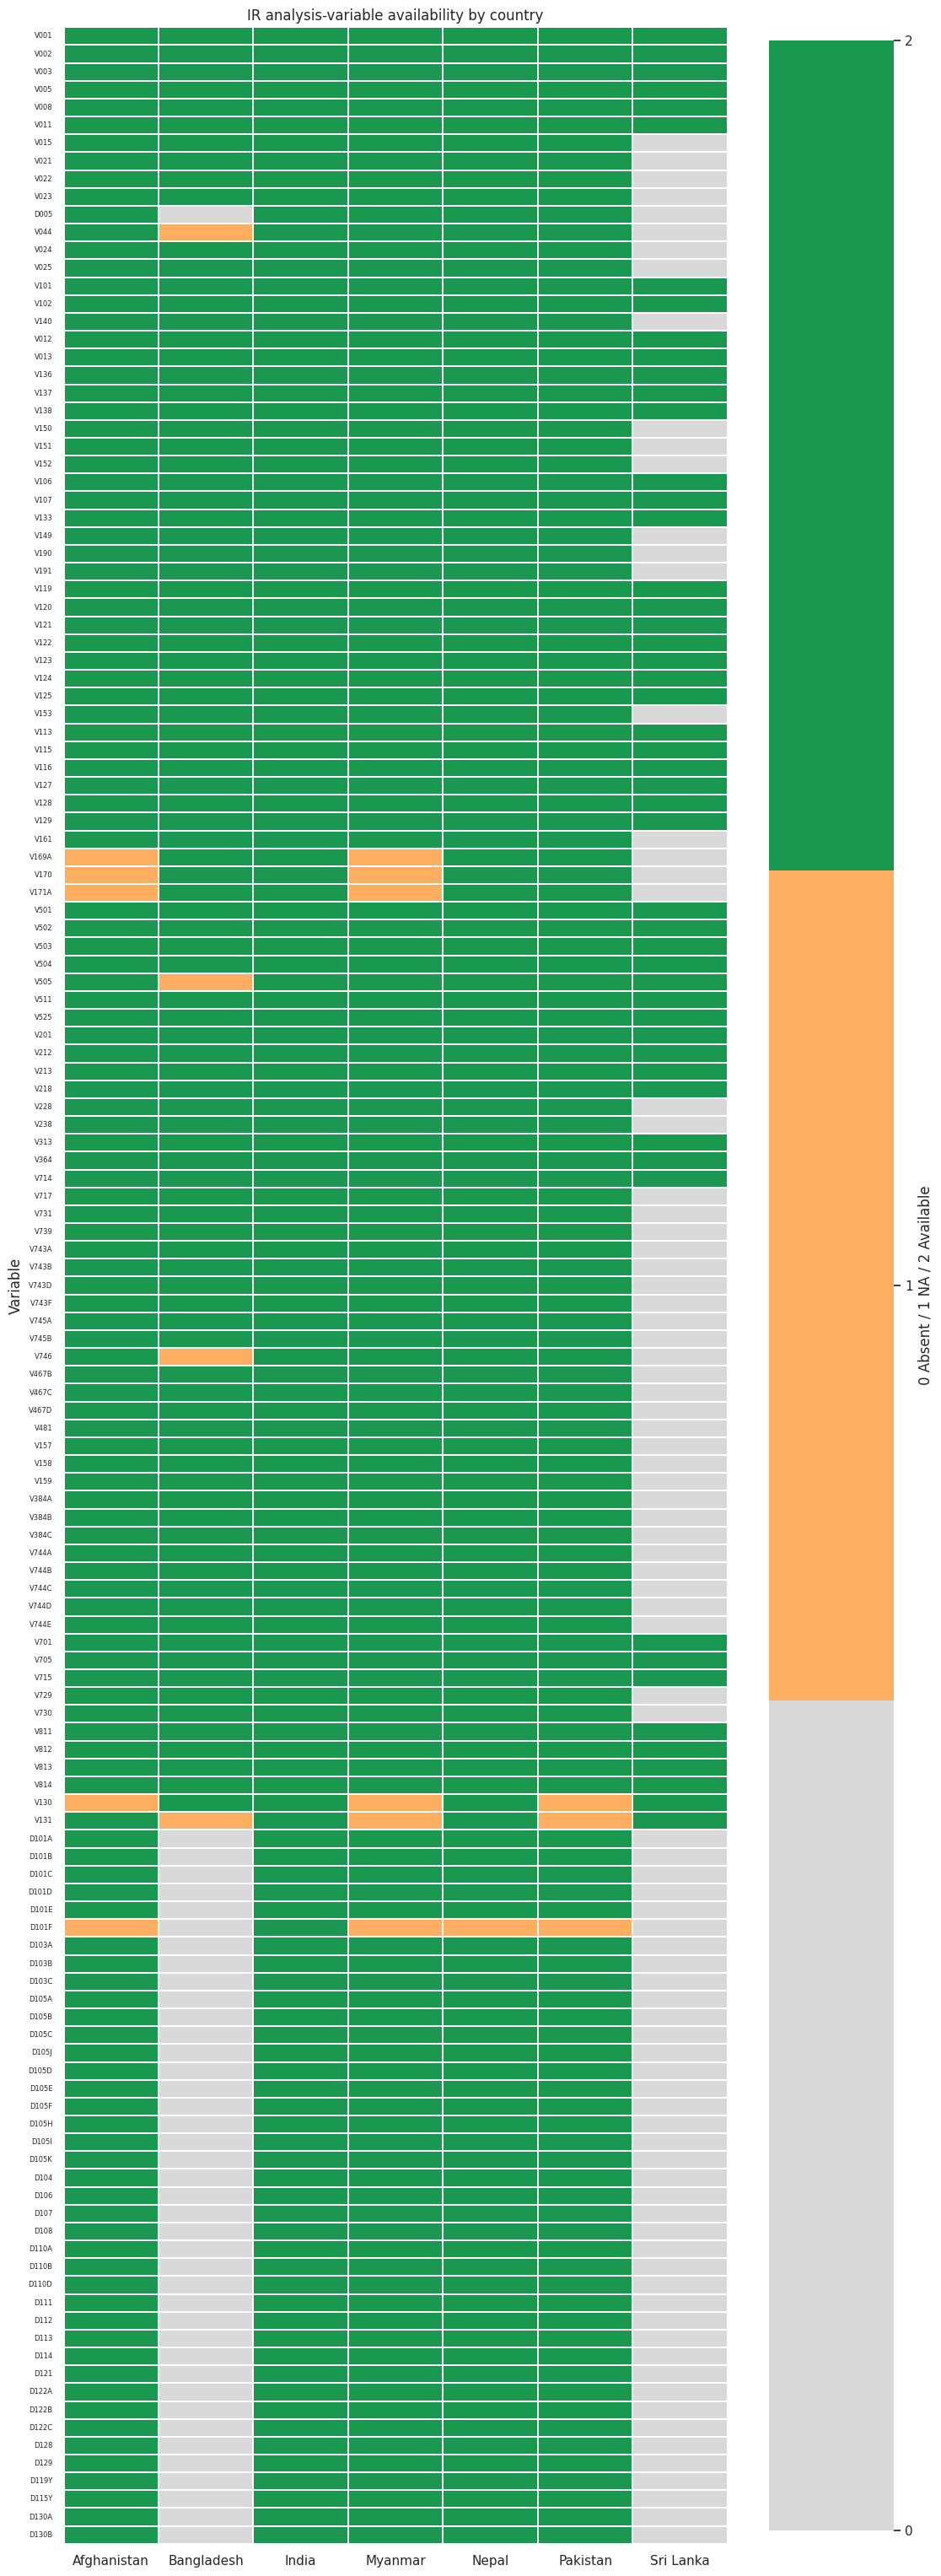

### Number of usable planned variables per country and block

group,attitudes,composite_dhs,connectivity,control,demography,design,education,emotional,empowerment,family_history,fear,fertility,geography,help_seeking,her_violence,household,injury,interview,interview_privacy,marriage,media,non_partner,partner,partner_alcohol,physical_less,physical_severe,previous_partner,sexual,socio_cultural,target,wealth,work
country,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Afghanistan,5,5,0,5,2,11,4,3,12,1,1,8,5,2,1,6,3,4,3,7,6,1,5,2,4,3,2,3,1,1,17,3
Bangladesh,5,0,3,0,2,10,4,0,11,0,0,8,5,0,0,6,0,4,0,6,6,0,5,0,0,0,0,0,1,0,17,3
India,5,5,3,6,2,11,4,3,12,1,1,8,5,2,1,6,3,4,3,7,6,1,5,2,4,3,2,3,2,1,17,3
Myanmar,5,5,0,5,2,11,4,3,12,1,1,8,5,2,1,6,3,4,3,7,6,1,5,2,4,3,2,3,0,1,17,3
Nepal,5,5,3,5,2,11,4,3,12,1,1,8,5,2,1,6,3,4,3,7,6,1,5,2,4,3,2,3,2,1,17,3
Pakistan,5,5,3,5,2,11,4,3,12,1,1,8,5,2,1,6,3,4,3,7,6,1,5,2,4,3,2,3,0,1,17,3
Sri Lanka,0,0,0,0,2,6,3,0,0,0,0,6,2,0,0,3,0,4,0,7,0,0,3,0,0,0,0,0,2,0,13,1


Planned IR background variables: 101 | curated DV items: 40


In [31]:
# ================================================================================================
# RECODE SOURCE
#   * Individual Recode (IR) - XXIRnnFL - one record per interviewed woman 15-49
# WHAT THIS CELL USES: variable NAMES and LABELS of the IR layouts to score availability.
# ================================================================================================
# 15b. The IR analysis plan and its cross-country availability matrix

# (variable, block, kind, description)
#   kind: id | weight | design | target | cont (continuous) | count | ord (ordinal) | nom (nominal) | bin
IR_VARIABLE_PLAN = [
    # --- identifiers, weights and complex-survey design -------------------------------------------
    ("V001",  "design",        "id",     "Cluster number"),
    ("V002",  "design",        "id",     "Household number"),
    ("V003",  "design",        "id",     "Respondent's line number"),
    ("V005",  "design",        "weight", "Woman's individual sample weight (6 dp)"),
    ("V008",  "design",        "cont",   "Date of interview (CMC)"),
    ("V011",  "design",        "cont",   "Date of birth (CMC)"),
    ("V015",  "design",        "design", "Result of individual interview"),
    ("V021",  "design",        "design", "Primary sampling unit"),
    ("V022",  "design",        "design", "Sample strata for sampling errors"),
    ("V023",  "design",        "design", "Stratification used in sample design"),
    ("D005",  "design",        "weight", "Domestic-violence sub-sample weight (6 dp)"),
    # --- the modelling target --------------------------------------------------------------------
    ("V044",  "target",        "target", "Selected for Domestic Violence module"),
    # --- geography -------------------------------------------------------------------------------
    ("V024",  "geography",     "nom",    "Region (country-specific)"),
    ("V025",  "geography",     "bin",    "Type of place of residence"),
    ("V101",  "geography",     "nom",    "Region (fallback for early waves)"),
    ("V102",  "geography",     "bin",    "Type of place of residence (de facto)"),
    ("V140",  "geography",     "nom",    "De jure type of place of residence"),
    # --- woman's demography and household composition --------------------------------------------
    ("V012",  "demography",    "cont",   "Respondent's current age"),
    ("V013",  "demography",    "ord",    "Age in 5-year groups"),
    ("V136",  "household",     "count",  "Number of household members (listed)"),
    ("V137",  "household",     "count",  "Number of children 5 and under in household"),
    ("V138",  "household",     "count",  "Number of eligible women in household"),
    ("V150",  "household",     "nom",    "Relationship to household head"),
    ("V151",  "household",     "bin",    "Sex of household head"),
    ("V152",  "household",     "cont",   "Age of household head"),
    # --- education -------------------------------------------------------------------------------
    ("V106",  "education",     "ord",    "Highest educational level"),
    ("V107",  "education",     "count",  "Highest year of education"),
    ("V133",  "education",     "count",  "Education in single years"),
    ("V149",  "education",     "ord",    "Educational attainment"),
    # --- wealth, assets and dwelling quality -----------------------------------------------------
    ("V190",  "wealth",        "ord",    "Wealth index quintile"),
    ("V191",  "wealth",        "cont",   "Wealth index factor score (5 dp)"),
    ("V119",  "wealth",        "bin",    "Household has electricity"),
    ("V120",  "wealth",        "bin",    "Household has radio"),
    ("V121",  "wealth",        "bin",    "Household has television"),
    ("V122",  "wealth",        "bin",    "Household has refrigerator"),
    ("V123",  "wealth",        "bin",    "Household has bicycle"),
    ("V124",  "wealth",        "bin",    "Household has motorcycle/scooter"),
    ("V125",  "wealth",        "bin",    "Household has car/truck"),
    ("V153",  "wealth",        "bin",    "Household has telephone (land line)"),
    ("V113",  "wealth",        "nom",    "Source of drinking water"),
    ("V115",  "wealth",        "cont",   "Time to get to water source (minutes)"),
    ("V116",  "wealth",        "nom",    "Type of toilet facility"),
    ("V127",  "wealth",        "nom",    "Main floor material"),
    ("V128",  "wealth",        "nom",    "Main wall material"),
    ("V129",  "wealth",        "nom",    "Main roof material"),
    ("V161",  "wealth",        "nom",    "Type of cooking fuel"),
    ("V169A", "connectivity",  "bin",    "Owns a mobile telephone"),
    ("V170",  "connectivity",  "bin",    "Has a bank/financial account"),
    ("V171A", "connectivity",  "ord",    "Use of internet"),
    # --- marriage, union and fertility -----------------------------------------------------------
    ("V501",  "marriage",      "nom",    "Current marital status"),
    ("V502",  "marriage",      "nom",    "Currently/formerly/never in union"),
    ("V503",  "marriage",      "ord",    "Number of unions"),
    ("V504",  "marriage",      "bin",    "Currently residing with husband/partner"),
    ("V505",  "marriage",      "count",  "Number of other wives (co-wives)"),
    ("V511",  "marriage",      "cont",   "Age at first cohabitation"),
    ("V525",  "marriage",      "cont",   "Age at first sex"),
    ("V201",  "fertility",     "count",  "Total children ever born"),
    ("V212",  "fertility",     "cont",   "Age of respondent at first birth"),
    ("V213",  "fertility",     "bin",    "Currently pregnant"),
    ("V218",  "fertility",     "count",  "Number of living children"),
    ("V228",  "fertility",     "bin",    "Ever had a terminated pregnancy"),
    ("V238",  "fertility",     "count",  "Births in last three years"),
    ("V313",  "fertility",     "ord",    "Current use by method type"),
    ("V364",  "fertility",     "nom",    "Contraceptive use and intention"),
    # --- work, autonomy and empowerment ----------------------------------------------------------
    ("V714",  "work",          "bin",    "Respondent currently working"),
    ("V717",  "work",          "nom",    "Respondent's occupation (grouped)"),
    ("V731",  "work",          "ord",    "Respondent worked in last 12 months"),
    ("V739",  "empowerment",   "nom",    "Who decides how to spend respondent's earnings"),
    ("V743A", "empowerment",   "nom",    "Who decides on respondent's health care"),
    ("V743B", "empowerment",   "nom",    "Who decides on large household purchases"),
    ("V743D", "empowerment",   "nom",    "Who decides on visits to family/relatives"),
    ("V743F", "empowerment",   "nom",    "Who decides what to do with husband's earnings"),
    ("V745A", "empowerment",   "nom",    "Owns a house alone or jointly"),
    ("V745B", "empowerment",   "nom",    "Owns land alone or jointly"),
    ("V746",  "empowerment",   "nom",    "Respondent earns more than husband"),
    ("V467B", "empowerment",   "ord",    "Problem getting medical help: permission"),
    ("V467C", "empowerment",   "ord",    "Problem getting medical help: money"),
    ("V467D", "empowerment",   "ord",    "Problem getting medical help: distance"),
    ("V481",  "empowerment",   "bin",    "Covered by health insurance"),
    # --- media exposure --------------------------------------------------------------------------
    ("V157",  "media",         "ord",    "Frequency of reading newspaper/magazine"),
    ("V158",  "media",         "ord",    "Frequency of listening to radio"),
    ("V159",  "media",         "ord",    "Frequency of watching television"),
    ("V384A", "media",         "bin",    "Heard family planning on radio"),
    ("V384B", "media",         "bin",    "Heard family planning on TV"),
    ("V384C", "media",         "bin",    "Heard family planning in newspaper"),
    # --- attitudes to wife beating (norms, NOT experience) ---------------------------------------
    ("V744A", "attitudes",     "bin",    "Beating justified: goes out without telling husband"),
    ("V744B", "attitudes",     "bin",    "Beating justified: neglects the children"),
    ("V744C", "attitudes",     "bin",    "Beating justified: argues with husband"),
    ("V744D", "attitudes",     "bin",    "Beating justified: refuses sex"),
    ("V744E", "attitudes",     "bin",    "Beating justified: burns the food"),
    # --- husband / partner -----------------------------------------------------------------------
    ("V701",  "partner",       "ord",    "Husband/partner's education level"),
    ("V705",  "partner",       "nom",    "Husband/partner's occupation (grouped)"),
    ("V715",  "partner",       "count",  "Husband/partner's years of education"),
    ("V729",  "partner",       "ord",    "Husband/partner's educational attainment"),
    ("V730",  "partner",       "cont",   "Husband/partner's age"),
    # --- interview context (privacy of the attitude questions) ------------------------------------
    ("V811",  "interview",     "nom",    "Presence of children <10 at attitude questions"),
    ("V812",  "interview",     "nom",    "Presence of husband at attitude questions"),
    ("V813",  "interview",     "nom",    "Presence of other males at attitude questions"),
    ("V814",  "interview",     "nom",    "Presence of other females at attitude questions"),
    # --- socio-cultural (country-specific coding: never pooled across countries) ------------------
    ("V130",  "socio_cultural", "nom",   "Religion (country-specific)"),
    ("V131",  "socio_cultural", "nom",   "Ethnicity/caste (country-specific)"),
]
IR_PLAN = pd.DataFrame(IR_VARIABLE_PLAN, columns=["variable", "block", "kind", "description"])

# --- curated DHS domestic-violence item list (explicit, not label-guessed) -----------------------
# Frequency items (D101x, D103x, D105x, D130x): 0=never, 1=often, 2=sometimes,
# 3=yes but not in last 12 months, 4=yes but frequency in last 12 months missing.
#   -> ever   = {1,2,3,4}
#   -> last12 = {1,2,4}
# Binary items (D104, D106-D108, D110x, D111, D112, D113, D115Y, D119Y, D121, D128): 0=no, 1=yes.
DV_ITEM_PLAN = [
    ("D101A", "control",            "freq", "Partner jealous if she talks with other men"),
    ("D101B", "control",            "freq", "Partner accuses her of unfaithfulness"),
    ("D101C", "control",            "freq", "Partner does not permit her to meet female friends"),
    ("D101D", "control",            "freq", "Partner limits her contact with family"),
    ("D101E", "control",            "freq", "Partner insists on knowing where she is"),
    ("D101F", "control",            "freq", "Partner does not trust her with money"),
    ("D103A", "emotional",          "freq", "Ever humiliated by partner"),
    ("D103B", "emotional",          "freq", "Ever threatened with harm by partner"),
    ("D103C", "emotional",          "freq", "Ever insulted or made to feel bad by partner"),
    ("D105A", "physical_less",      "freq", "Ever pushed/shaken/had something thrown"),
    ("D105B", "physical_less",      "freq", "Ever slapped"),
    ("D105C", "physical_less",      "freq", "Ever punched with fist or hit with something harmful"),
    ("D105J", "physical_less",      "freq", "Ever had arm twisted or hair pulled"),
    ("D105D", "physical_severe",    "freq", "Ever kicked or dragged"),
    ("D105E", "physical_severe",    "freq", "Ever strangled or burnt"),
    ("D105F", "physical_severe",    "freq", "Ever threatened with knife/gun/other weapon"),
    ("D105H", "sexual",             "freq", "Ever physically forced into unwanted sex"),
    ("D105I", "sexual",             "freq", "Ever forced into other unwanted sexual acts"),
    ("D105K", "sexual",             "freq", "Ever physically forced to perform unwanted sexual acts"),
    ("D104",  "composite_dhs",      "bin",  "DHS composite: any emotional violence"),
    ("D106",  "composite_dhs",      "bin",  "DHS composite: any less severe physical violence"),
    ("D107",  "composite_dhs",      "bin",  "DHS composite: any severe physical violence"),
    ("D108",  "composite_dhs",      "bin",  "DHS composite: any sexual violence"),
    ("D110A", "injury",             "bin",  "Ever had bruises from partner's actions"),
    ("D110B", "injury",             "bin",  "Ever had eye injuries/sprains/dislocations/burns"),
    ("D110D", "injury",             "bin",  "Ever had wounds/broken bones/broken teeth/serious injury"),
    ("D111",  "composite_dhs",      "bin",  "DHS composite: any injury"),
    ("D112",  "her_violence",       "bin",  "Respondent ever physically hurt partner unprovoked"),
    ("D113",  "partner_alcohol",    "bin",  "Partner drinks alcohol"),
    ("D114",  "partner_alcohol",    "ord",  "Frequency of partner being drunk"),
    ("D121",  "family_history",     "bin",  "Her father ever beat her mother"),
    ("D122A", "interview_privacy",  "ord",  "Interview interrupted: husband present"),
    ("D122B", "interview_privacy",  "ord",  "Interview interrupted: other adult male present"),
    ("D122C", "interview_privacy",  "ord",  "Interview interrupted: adult female present"),
    ("D128",  "help_seeking",       "bin",  "Ever told anyone about the violence"),
    ("D129",  "fear",               "ord",  "Afraid of partner (never/sometimes/most of the time)"),
    ("D119Y", "help_seeking",       "bin",  "Did not seek help from anyone"),
    ("D115Y", "non_partner",        "bin",  "Nobody other than partner ever physically hurt her"),
    ("D130A", "previous_partner",   "freq", "Previous husband ever hit/slapped/kicked/hurt her"),
    ("D130B", "previous_partner",   "freq", "Previous husband forced sex or sexual acts"),
]
DV_PLAN = pd.DataFrame(DV_ITEM_PLAN, columns=["variable", "domain", "coding", "description"])

# --- availability matrix across the seven IR archives -------------------------------------------
availability_rows = []
for _, plan_row in pd.concat([
        IR_PLAN.rename(columns={"block": "group"})[["variable", "group", "description"]],
        DV_PLAN.rename(columns={"domain": "group"})[["variable", "group", "description"]]],
        ignore_index=True).iterrows():
    for _, meta in ir_archives.iterrows():
        availability_rows.append({
            "variable": plan_row.variable, "group": plan_row.group,
            "description": plan_row.description, "country": meta.country,
            "status": variable_status(meta.stem, plan_row.variable),
        })
ir_availability = pd.DataFrame(availability_rows)

ir_availability_wide = ir_availability.pivot_table(
    index=["group", "variable", "description"], columns="country", values="status", aggfunc="first"
).reset_index()
display(Markdown("### Availability of every planned IR variable (Available / NA = in layout but never asked / Absent)"))
display(ir_availability_wide)

STATUS_CODE = {"Available": 2, "NA": 1, "Absent": 0}
heat = (ir_availability.assign(code=lambda d: d.status.map(STATUS_CODE))
        .pivot_table(index="variable", columns="country", values="code", aggfunc="first"))
heat = heat.loc[[v for v in ir_availability.variable.unique() if v in heat.index]]
plt.figure(figsize=(1.6 * max(6, heat.shape[1]), 0.20 * len(heat) + 2.5))
sns.heatmap(heat, cmap=sns.color_palette(["#d9d9d9", "#fdae61", "#1a9850"], as_cmap=False),
            vmin=0, vmax=2, cbar_kws={"ticks": [0, 1, 2], "label": "0 Absent / 1 NA / 2 Available"},
            linewidths=0.3, linecolor="white")
plt.title("IR analysis-variable availability by country")
plt.xlabel(""); plt.ylabel("Variable"); plt.yticks(fontsize=6)
plt.tight_layout(); plt.show()

usable_counts = (ir_availability[ir_availability.status.eq("Available")]
                 .groupby(["country", "group"]).size().unstack(fill_value=0))
display(Markdown("### Number of usable planned variables per country and block"))
display(usable_counts)

ir_availability.to_csv(OUTPUT_DIR / "ir_variable_availability_long.csv", index=False)
ir_availability_wide.to_csv(OUTPUT_DIR / "ir_variable_availability_matrix.csv", index=False)
IR_PLAN.to_csv(OUTPUT_DIR / "ir_variable_plan.csv", index=False)
DV_PLAN.to_csv(OUTPUT_DIR / "ir_curated_dv_item_plan.csv", index=False)
print("Planned IR background variables:", len(IR_PLAN), "| curated DV items:", len(DV_PLAN))

## 16. Individual Recode (IR) EDA — the weighted profile of women aged 15–49

**Recode used: Individual Recode (IR).** This is the section that was missing from Part I.

Part I could only describe women as **rows on a household roster** (`HV104`, `HV105`, `HV117`). The IR file describes them as **respondents**: their own education, marital history, fertility, work, autonomy, media exposure, attitudes, partner characteristics, and — where the module was fielded — their answers to the violence questions.

### What this section does

| Step | Content |
|---|---|
| 16a | One memory-safe pass over all seven IR `.DAT` files, reading only the planned fields, in chunks |
| 16b | Harmonised / derived analysis variables and composite indices |
| 16c | Weighted country profile of women 15–49 (`V005 / 1 000 000`) |
| 16d | Distributions: age, education, marital status, wealth, region, work |
| 16e | Interview outcome (`V015`) and field-level completeness |
| 16f | Autonomy, decision-making and wife-beating attitudes |
| 16g | Correlation structure of the numeric feature space |
| 16h | `V044` DV-module selection EDA — including the design relationship with `V138` |
| 16i | Curated DV-item prevalence with the `D005` weight, and a reconciliation against the label-discovered registry of §12 |

### Weights

- `V005 / 1 000 000` — women's individual weight. Used for everything except the violence items.
- `D005 / 1 000 000` — domestic-violence sub-sample weight. Used **only** for `D1xx` estimates, and only where `D005 > 0`.
- `V191 / 100 000` — wealth index factor score (the flat file stores implied decimals).

### Cost control

`IR_ROW_LIMIT_PER_COUNTRY` caps rows per country. It is `None` when `RUN_FULL_SCAN` is `True`, i.e. every record of every IR file is scanned — including the 724 115 Indian records in a 6.8 GB flat file. Set `RUN_FULL_SCAN = False` in the configuration cell for a fast smoke test.

In [32]:
# ================================================================================================
# RECODE SOURCE
#   * Individual Recode (IR) - XXIRnnFL - one record per interviewed woman 15-49
# WHAT THIS CELL USES: one chunked pass over every IR .DAT, reading only the planned fields.
# NOTE: the same iter_fwf reader defined for HR/PR in section 5 is reused here.
# ================================================================================================
# 16a. Memory-safe full scan of every Individual Recode file

IR_ROW_LIMIT_PER_COUNTRY = None if RUN_FULL_SCAN else 60_000

# ---- special / don't-know / not-applicable codes -----------------------------------------------
_BIN01 = frozenset({0, 1})
IR_VALID_CODES = {v: _BIN01 for v in [
    "V119", "V120", "V121", "V122", "V123", "V124", "V125", "V153", "V169A", "V170",
    "V213", "V228", "V384A", "V384B", "V384C", "V481", "V504", "V714",
    "V744A", "V744B", "V744C", "V744D", "V744E",
]}
IR_VALID_CODES.update({
    "V044": frozenset({0, 1, 2, 3}),
    "V015": frozenset({1, 2, 3, 4, 5, 6, 7}),
    "V013": frozenset({1, 2, 3, 4, 5, 6, 7}),
    "V025": frozenset({1, 2}), "V102": frozenset({1, 2}), "V140": frozenset({0, 1, 2}),
    "V106": frozenset({0, 1, 2, 3}), "V149": frozenset({0, 1, 2, 3, 4, 5}),
    "V151": frozenset({1, 2}),
    "V190": frozenset({1, 2, 3, 4, 5}),
    "V171A": frozenset({0, 1, 2, 3}),
    "V501": frozenset({0, 1, 2, 3, 4, 5}), "V502": frozenset({0, 1, 2}),
    "V503": frozenset({1, 2, 3, 4}),
    "V313": frozenset({0, 1, 2, 3}), "V364": frozenset({1, 2, 3, 4, 5, 6, 7, 8, 9}),
    "V731": frozenset({0, 1, 2, 3}),
    "V739": frozenset({1, 2, 3, 4, 5, 6}),
    "V743A": frozenset({1, 2, 3, 4, 5, 6}), "V743B": frozenset({1, 2, 3, 4, 5, 6}),
    "V743D": frozenset({1, 2, 3, 4, 5, 6}), "V743F": frozenset({1, 2, 3, 4, 5, 6}),
    "V745A": frozenset({0, 1, 2, 3, 4, 5}), "V745B": frozenset({0, 1, 2, 3, 4, 5}),
    "V746": frozenset({1, 2, 3, 4}),
    "V467B": frozenset({0, 1, 2}), "V467C": frozenset({0, 1, 2}), "V467D": frozenset({0, 1, 2}),
    "V157": frozenset({0, 1, 2, 3}), "V158": frozenset({0, 1, 2, 3}), "V159": frozenset({0, 1, 2, 3}),
    "V701": frozenset({0, 1, 2, 3, 4, 5}), "V729": frozenset({0, 1, 2, 3, 4, 5}),
    "V811": frozenset({0, 1, 2}), "V812": frozenset({0, 1, 2}),
    "V813": frozenset({0, 1, 2}), "V814": frozenset({0, 1, 2}),
})
IR_DROP_CODES = {
    "V107": {98, 99}, "V133": {97, 98, 99},
    "V150": {98, 99}, "V152": {97, 98, 99},
    "V113": {97, 98, 99}, "V116": {97, 98, 99},
    "V127": {97, 98, 99}, "V128": {97, 98, 99}, "V129": {97, 98, 99}, "V161": {97, 98, 99},
    "V130": {98, 99}, "V131": {98, 99},
    "V024": {99}, "V101": {99},
    "V505": {98, 99}, "V511": {97, 98, 99}, "V525": {96, 97, 98, 99},
    "V212": {97, 98, 99},
    "V715": {98, 99}, "V730": {98, 99},
    "V717": {98, 99}, "V705": {98, 99},
    "V115": {998, 999},
}
# DHS frequency items: 0 never, 1 often, 2 sometimes, 3 yes-not-in-last-12-months,
#                      4 yes-but-frequency-in-last-12-months-missing.
DV_VALID_BY_CODING = {"freq": frozenset({0, 1, 2, 3, 4}), "bin": _BIN01, "ord": frozenset({0, 1, 2})}
DV_CODING = dict(zip(DV_PLAN.variable, DV_PLAN.coding))

IMPLIED_DECIMALS = {"V005": 1_000_000.0, "D005": 1_000_000.0, "V191": 100_000.0}

IR_SCAN_VARS = list(dict.fromkeys(list(IR_PLAN.variable) + list(DV_PLAN.variable)))


def clean_ir_chunk(chunk):
    """Set DHS don't-know / not-applicable / missing codes to NaN. Never recode them to 'no'."""
    if "V115" in chunk:                                    # 996 = water source on premises
        chunk["V115"] = chunk["V115"].mask(chunk["V115"].eq(996), 0)
    for var, valid in IR_VALID_CODES.items():
        if var in chunk:
            chunk[var] = chunk[var].where(chunk[var].isin(valid))
    for var, drop in IR_DROP_CODES.items():
        if var in chunk:
            chunk[var] = chunk[var].where(~chunk[var].isin(drop))
    for var, coding in DV_CODING.items():
        if var in chunk:
            chunk[var] = chunk[var].where(chunk[var].isin(DV_VALID_BY_CODING[coding]))
    return chunk


ir_parts, ir_scan_log = [], []
for _, meta in ir_archives.iterrows():
    stem, country = meta.stem, meta.country
    schema = schemas[stem]
    usable = [v for v in IR_SCAN_VARS if variable_status(stem, v) == "Available"]
    rows_scanned, country_parts = 0, []
    for chunk in iter_fwf(Path(meta.path), schema, usable, nrows=IR_ROW_LIMIT_PER_COUNTRY):
        rows_scanned += len(chunk)
        chunk = clean_ir_chunk(chunk)
        for var, scale in IMPLIED_DECIMALS.items():        # flat file stores implied decimals
            if var in chunk:
                chunk[var] = chunk[var] / scale
        country_parts.append(chunk.astype("float32"))
    frame = (pd.concat(country_parts, ignore_index=True)
             if country_parts else pd.DataFrame(columns=usable, dtype="float32"))
    del country_parts
    frame["country"] = country
    frame["country_code"] = stem[:2]
    frame["stem"] = stem
    frame["survey"] = meta.survey
    frame["survey_year"] = np.int16(meta.survey_year)
    # Weights. V005 is the women's weight; D005 is positive only for DV sub-sample respondents.
    frame["w_ind"] = frame["V005"] if "V005" in frame else np.nan
    frame["w_dv"] = frame["D005"] if "D005" in frame else np.nan
    # De-identified grouping key for cluster-aware cross-validation (PSU, else cluster number).
    psu = frame["V021"] if "V021" in frame else (frame["V001"] if "V001" in frame else pd.Series(0, index=frame.index))
    frame["group_key"] = stem[:2] + "-" + psu.fillna(-1).astype("int64").astype(str)
    ir_parts.append(frame)
    ir_scan_log.append({
        "country": country, "stem": stem, "survey": meta.survey,
        "rows_scanned": rows_scanned,
        "official_unweighted_women": ir_structure.loc[ir_structure.stem.eq(stem), "official_unweighted_women"].iloc[0],
        "planned_fields_available": len(usable),
        "planned_fields_missing": len(IR_SCAN_VARS) - len(usable),
        "weighted_women": float(frame["w_ind"].sum(skipna=True)),
        "dv_subsample_rows": int(frame["w_dv"].gt(0).sum()) if "w_dv" in frame else 0,
    })
    print(f"  scanned {country:12s} {stem}: {rows_scanned:>8,} rows | {len(usable):>3} of {len(IR_SCAN_VARS)} planned fields")
    del frame
    gc.collect()

ir_women = pd.concat(ir_parts, ignore_index=True, sort=False)
del ir_parts
gc.collect()

# Household/line identifiers are not needed downstream; drop them immediately (de-identification).
ir_women.drop(columns=[c for c in ["V001", "V002", "V003"] if c in ir_women], inplace=True)

ir_scan_summary = pd.DataFrame(ir_scan_log)
ir_scan_summary["record_count_match"] = (
    ir_scan_summary.rows_scanned.eq(ir_scan_summary.official_unweighted_women) if RUN_FULL_SCAN else np.nan
)
display(Markdown("### IR full-scan log"))
display(ir_scan_summary.style.format({
    "rows_scanned": "{:,.0f}", "official_unweighted_women": "{:,.0f}",
    "weighted_women": "{:,.0f}", "dv_subsample_rows": "{:,.0f}",
}))
print(f"\nir_women: {ir_women.shape[0]:,} women x {ir_women.shape[1]:,} columns "
      f"({ir_women.memory_usage(deep=True).sum() / 1e6:,.0f} MB)")
ir_scan_summary.to_csv(OUTPUT_DIR / "ir_scan_summary.csv", index=False)

/tmp/ipykernel_116/1259518011.py:97: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  frame["country"] = country
/tmp/ipykernel_116/1259518011.py:98: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  frame["country_code"] = stem[:2]
/tmp/ipykernel_116/1259518011.py:99: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.co

  scanned Afghanistan  AFIR71FL:   29,461 rows | 136 of 141 planned fields


/tmp/ipykernel_116/1259518011.py:101: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  frame["survey_year"] = np.int16(meta.survey_year)
/tmp/ipykernel_116/1259518011.py:103: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  frame["w_ind"] = frame["V005"] if "V005" in frame else np.nan
/tmp/ipykernel_116/1259518011.py:104: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead.

  scanned Bangladesh   BDIR81FL:   30,078 rows |  96 of 141 planned fields


/tmp/ipykernel_116/1259518011.py:97: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  frame["country"] = country
/tmp/ipykernel_116/1259518011.py:98: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  frame["country_code"] = stem[:2]
/tmp/ipykernel_116/1259518011.py:99: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.co

...

/tmp/ipykernel_116/1259518011.py:97: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  frame["country"] = country
/tmp/ipykernel_116/1259518011.py:98: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  frame["country_code"] = stem[:2]
/tmp/ipykernel_116/1259518011.py:99: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.co

  scanned Pakistan     PKIR71FL:   15,068 rows | 138 of 141 planned fields
  scanned Sri Lanka    LKIR02FL:    5,865 rows |  52 of 141 planned fields


### IR full-scan log

,country,stem,survey,rows_scanned,official_unweighted_women,planned_fields_available,planned_fields_missing,weighted_women,dv_subsample_rows,record_count_match
0,Afghanistan,AFIR71FL,2015,"29,461","29,461",136,5,"29,461","21,324",True
1,Bangladesh,BDIR81FL,2022,"30,078","30,078",96,45,"30,078",0,True
2,India,IAIR7EFL,2019-21,"724,115","724,115",141,0,"724,115","72,320",True
3,Myanmar,MMIR71FL,2015-16,"12,885","12,885",135,6,"12,885","4,530",True
4,Nepal,NPIR82FL,2022,"14,845","14,845",140,1,"14,845","5,178",True
5,Pakistan,PKIR71FL,2017-18,"15,068","15,068",138,3,"12,364","3,303",True
6,Sri Lanka,LKIR02FL,1987,"5,865",nan,52,89,"5,864",0,False



ir_women: 832,317 women x 146 columns (697 MB)


In [33]:
# ================================================================================================
# RECODE SOURCE
#   * Individual Recode (IR) - XXIRnnFL - one record per interviewed woman 15-49
# WHAT THIS CELL USES: the scanned IR frame `ir_women` built in 16a.
# NOTE: derived columns are ADDED to ir_women; no scanned column is dropped or overwritten.
# ================================================================================================
# 16b. Harmonised and derived analysis variables

# ---- small helpers -----------------------------------------------------------------------------
def col(df, name):
    """Return a column if present, else an all-NaN float32 series of the right length."""
    return df[name] if name in df.columns else pd.Series(np.nan, index=df.index, dtype="float32")


def any_of(df, names, valid=(1,)):
    """Row-wise 'any of these variables takes one of `valid`', NaN only when all inputs are NaN."""
    present = [n for n in names if n in df.columns]
    if not present:
        return pd.Series(np.nan, index=df.index, dtype="float32")
    block = df[present]
    hits = block.isin(valid).where(block.notna())
    return hits.max(axis=1).astype("float32")


def mean_of(df, names):
    """Row-wise mean over available columns (NaN when the whole block is missing)."""
    present = [n for n in names if n in df.columns]
    if not present:
        return pd.Series(np.nan, index=df.index, dtype="float32")
    return df[present].mean(axis=1, skipna=True).astype("float32")


# DHS coding groups used for the dwelling-quality recodes.
IMPROVED_WATER = set(range(10, 15)) | {21, 31, 41, 51, 61, 62, 65, 71, 72, 73}
IMPROVED_TOILET = set(range(10, 16)) | {20, 21, 22, 41}
SHARED_OR_OPEN_TOILET = {30, 31, 42, 43, 96}
CLEAN_FUEL = {1, 2, 3, 4, 5}                     # electricity, LPG, natural gas, biogas, kerosene
FINISHED_FLOOR = set(range(30, 40))
FINISHED_WALL = set(range(30, 40))
FINISHED_ROOF = set(range(30, 40))
DECIDES_SELF_OR_JOINT = {1, 2}                   # 1 respondent alone, 2 jointly with husband
OWNS_ANY = {1, 2, 3}                             # alone / jointly / both

d = ir_women                                     # short alias; all assignments are additions

# ---- 1. targets --------------------------------------------------------------------------------
# V044: 0 not selected, 1 selected+interviewed, 2 selected but no privacy, 3 selected not interviewed.
d["y_selected"] = col(d, "V044").isin([1, 2, 3]).where(col(d, "V044").notna()).astype("float32")
d["y_completed"] = col(d, "V044").eq(1).where(col(d, "V044").notna()).astype("float32")
d["v044_label"] = col(d, "V044").map({
    0: "0 Not selected", 1: "1 Selected, interviewed",
    2: "2 Selected, no privacy", 3: "3 Selected, not interviewed",
})
d["interview_completed"] = col(d, "V015").eq(1).where(col(d, "V015").notna()).astype("float32")

# ---- 2. the design variable that mechanically drives selection ---------------------------------
# Only one eligible woman per household answers the DV module, so P(selected) ~ 1 / V138.
d["n_eligible_women"] = col(d, "V138")
d["inv_eligible_women"] = (1.0 / col(d, "V138").where(col(d, "V138") > 0)).astype("float32")
d["single_eligible_woman"] = col(d, "V138").eq(1).where(col(d, "V138").notna()).astype("float32")
d["eligible_women_capped"] = col(d, "V138").clip(upper=5).astype("float32")

# ---- 3. geography and residence ---------------------------------------------------------------
d["region_code"] = col(d, "V024").fillna(col(d, "V101"))
d["region_key"] = d["country_code"] + "-" + d["region_code"].fillna(-1).astype("int64").astype(str)
d["urban"] = col(d, "V025").fillna(col(d, "V102")).map({1: 1.0, 2: 0.0}).astype("float32")

# ---- 4. woman's demography --------------------------------------------------------------------
d["age"] = col(d, "V012")
d["age_group"] = col(d, "V013")
d["age_sq"] = (col(d, "V012") ** 2).astype("float32")
d["adolescent"] = col(d, "V012").lt(20).where(col(d, "V012").notna()).astype("float32")

# ---- 5. education -----------------------------------------------------------------------------
d["edu_level"] = col(d, "V106")
d["edu_years"] = col(d, "V133").fillna(col(d, "V107"))
d["edu_attainment"] = col(d, "V149")
d["no_education"] = col(d, "V106").eq(0).where(col(d, "V106").notna()).astype("float32")
d["secondary_or_higher"] = col(d, "V106").ge(2).where(col(d, "V106").notna()).astype("float32")

# ---- 6. household composition -----------------------------------------------------------------
d["hh_size"] = col(d, "V136")
d["n_children_under5"] = col(d, "V137")
d["female_head"] = col(d, "V151").map({1: 0.0, 2: 1.0}).astype("float32")
d["head_age"] = col(d, "V152")
d["is_head_or_spouse"] = col(d, "V150").isin([1, 2]).where(col(d, "V150").notna()).astype("float32")
d["crowding"] = (col(d, "V136") / col(d, "V138").where(col(d, "V138") > 0)).astype("float32")

# ---- 7. wealth, assets and dwelling quality ---------------------------------------------------
d["wealth_quintile"] = col(d, "V190")
d["wealth_score"] = col(d, "V191")
ASSETS = ["V119", "V120", "V121", "V122", "V123", "V124", "V125", "V153"]
d["asset_count"] = d[[a for a in ASSETS if a in d.columns]].sum(axis=1, min_count=1).astype("float32") \
    if any(a in d.columns for a in ASSETS) else np.nan
d["asset_index"] = mean_of(d, ASSETS)
d["improved_water"] = col(d, "V113").isin(IMPROVED_WATER).where(col(d, "V113").notna()).astype("float32")
d["improved_toilet"] = col(d, "V116").isin(IMPROVED_TOILET).where(col(d, "V116").notna()).astype("float32")
d["open_defecation"] = col(d, "V116").isin(SHARED_OR_OPEN_TOILET).where(col(d, "V116").notna()).astype("float32")
d["clean_cooking_fuel"] = col(d, "V161").isin(CLEAN_FUEL).where(col(d, "V161").notna()).astype("float32")
d["finished_floor"] = col(d, "V127").isin(FINISHED_FLOOR).where(col(d, "V127").notna()).astype("float32")
d["finished_wall"] = col(d, "V128").isin(FINISHED_WALL).where(col(d, "V128").notna()).astype("float32")
d["finished_roof"] = col(d, "V129").isin(FINISHED_ROOF).where(col(d, "V129").notna()).astype("float32")
d["dwelling_quality"] = mean_of(d, ["finished_floor", "finished_wall", "finished_roof"])
d["water_time_min"] = col(d, "V115")
d["water_on_premises"] = col(d, "V115").eq(0).where(col(d, "V115").notna()).astype("float32")

# ---- 8. connectivity --------------------------------------------------------------------------
d["owns_mobile"] = col(d, "V169A")
d["has_bank_account"] = col(d, "V170")
d["uses_internet"] = col(d, "V171A").ge(1).where(col(d, "V171A").notna()).astype("float32")
d["connectivity_index"] = mean_of(d, ["owns_mobile", "has_bank_account", "uses_internet"])

# ---- 9. marriage and union --------------------------------------------------------------------
d["marital_status"] = col(d, "V501")
d["in_union"] = col(d, "V502").eq(1).where(col(d, "V502").notna()).astype("float32")
d["ever_married"] = col(d, "V502").isin([1, 2]).where(col(d, "V502").notna()).astype("float32")
d["never_married"] = col(d, "V502").eq(0).where(col(d, "V502").notna()).astype("float32")
d["married_more_than_once"] = col(d, "V503").ge(2).where(col(d, "V503").notna()).astype("float32")
d["living_with_partner"] = col(d, "V504")
d["polygynous_union"] = col(d, "V505").ge(1).where(col(d, "V505").notna()).astype("float32")
d["age_at_cohabitation"] = col(d, "V511")
d["child_marriage"] = col(d, "V511").lt(18).where(col(d, "V511").notna()).astype("float32")
d["years_since_union"] = (col(d, "V012") - col(d, "V511")).astype("float32")
d["partner_age"] = col(d, "V730")
d["spousal_age_gap"] = (col(d, "V730") - col(d, "V012")).astype("float32")
d["large_age_gap"] = d["spousal_age_gap"].ge(10).where(d["spousal_age_gap"].notna()).astype("float32")
d["partner_edu_level"] = col(d, "V701").fillna(col(d, "V729"))
d["partner_edu_years"] = col(d, "V715")
d["spousal_edu_gap"] = (col(d, "V133") - col(d, "V715")).astype("float32")
d["woman_better_educated"] = d["spousal_edu_gap"].gt(0).where(d["spousal_edu_gap"].notna()).astype("float32")

# ---- 10. fertility ----------------------------------------------------------------------------
d["children_ever_born"] = col(d, "V201")
d["living_children"] = col(d, "V218")
d["currently_pregnant"] = col(d, "V213")
d["age_at_first_birth"] = col(d, "V212")
d["early_first_birth"] = col(d, "V212").lt(20).where(col(d, "V212").notna()).astype("float32")
d["recent_birth"] = col(d, "V238").ge(1).where(col(d, "V238").notna()).astype("float32")
d["nulliparous"] = col(d, "V201").eq(0).where(col(d, "V201").notna()).astype("float32")
d["uses_contraception"] = col(d, "V313").ge(1).where(col(d, "V313").notna()).astype("float32")
d["uses_modern_method"] = col(d, "V313").eq(3).where(col(d, "V313").notna()).astype("float32")

# ---- 11. work ---------------------------------------------------------------------------------
d["currently_working"] = col(d, "V714")
d["worked_last_12m"] = col(d, "V731").ge(1).where(col(d, "V731").notna()).astype("float32")
d["occupation_group"] = col(d, "V717")
d["partner_occupation_group"] = col(d, "V705")
d["earns_more_than_partner"] = col(d, "V746").eq(1).where(col(d, "V746").notna()).astype("float32")
d["controls_own_earnings"] = col(d, "V739").isin(DECIDES_SELF_OR_JOINT).where(col(d, "V739").notna()).astype("float32")

# ---- 12. decision-making, ownership, autonomy -------------------------------------------------
DECISIONS = ["V743A", "V743B", "V743D", "V743F"]
for v in DECISIONS:
    if v in d.columns:
        d[f"decides_{v.lower()}"] = col(d, v).isin(DECIDES_SELF_OR_JOINT).where(col(d, v).notna()).astype("float32")
d["decision_index"] = mean_of(d, [f"decides_{v.lower()}" for v in DECISIONS])
d["owns_house"] = col(d, "V745A").isin(OWNS_ANY).where(col(d, "V745A").notna()).astype("float32")
d["owns_land"] = col(d, "V745B").isin(OWNS_ANY).where(col(d, "V745B").notna()).astype("float32")
d["owns_asset_any"] = any_of(d, ["owns_house", "owns_land"])
BARRIERS = ["V467B", "V467C", "V467D"]
for v in BARRIERS:
    if v in d.columns:
        d[f"barrier_{v.lower()}"] = col(d, v).eq(1).where(col(d, v).notna()).astype("float32")
d["healthcare_barrier_index"] = mean_of(d, [f"barrier_{v.lower()}" for v in BARRIERS])
d["health_insurance"] = col(d, "V481")
d["empowerment_index"] = mean_of(d, ["decision_index", "owns_asset_any", "controls_own_earnings",
                                     "owns_mobile", "has_bank_account"])

# ---- 13. media exposure -----------------------------------------------------------------------
for v, nice in [("V157", "reads_newspaper"), ("V158", "listens_radio"), ("V159", "watches_tv")]:
    if v in d.columns:
        d[nice] = col(d, v).ge(1).where(col(d, v).notna()).astype("float32")
d["media_index"] = mean_of(d, ["reads_newspaper", "listens_radio", "watches_tv"])
d["heard_fp_media"] = any_of(d, ["V384A", "V384B", "V384C"])

# ---- 14. attitudes to wife beating (a NORM, not an experience) ---------------------------------
ATTITUDES = ["V744A", "V744B", "V744C", "V744D", "V744E"]
d["justifies_beating_count"] = (d[[a for a in ATTITUDES if a in d.columns]].sum(axis=1, min_count=1).astype("float32")
                                if any(a in d.columns for a in ATTITUDES) else np.nan)
d["justifies_beating_any"] = any_of(d, ATTITUDES)
d["attitude_index"] = mean_of(d, ATTITUDES)

# ---- 15. interview privacy context -------------------------------------------------------------
PRESENCE = ["V811", "V812", "V813", "V814"]
d["others_present_at_attitudes"] = any_of(d, PRESENCE)
d["husband_present_at_attitudes"] = col(d, "V812").eq(1).where(col(d, "V812").notna()).astype("float32")

# ---- 16. socio-cultural (country-specific codes; kept as strings, never pooled numerically) ----
d["religion_key"] = d["country_code"] + "-" + col(d, "V130").fillna(-1).astype("int64").astype(str)
d["ethnicity_key"] = d["country_code"] + "-" + col(d, "V131").fillna(-1).astype("int64").astype(str)

DERIVED_FEATURES = [
    "urban", "age", "age_sq", "age_group", "adolescent", "edu_level", "edu_years", "edu_attainment",
    "no_education", "secondary_or_higher", "hh_size", "n_children_under5", "n_eligible_women",
    "inv_eligible_women", "single_eligible_woman", "eligible_women_capped", "crowding",
    "female_head", "head_age", "is_head_or_spouse",
    "wealth_quintile", "wealth_score", "asset_count", "asset_index", "improved_water",
    "improved_toilet", "open_defecation", "clean_cooking_fuel", "dwelling_quality",
    "water_time_min", "water_on_premises",
    "owns_mobile", "has_bank_account", "uses_internet", "connectivity_index",
    "marital_status", "in_union", "ever_married", "never_married", "married_more_than_once",
    "living_with_partner", "polygynous_union", "age_at_cohabitation", "child_marriage",
    "years_since_union", "partner_age", "spousal_age_gap", "large_age_gap",
    "partner_edu_level", "partner_edu_years", "spousal_edu_gap", "woman_better_educated",
    "children_ever_born", "living_children", "currently_pregnant", "age_at_first_birth",
    "early_first_birth", "recent_birth", "nulliparous", "uses_contraception", "uses_modern_method",
    "currently_working", "worked_last_12m", "occupation_group", "partner_occupation_group",
    "earns_more_than_partner", "controls_own_earnings",
    "decision_index", "owns_house", "owns_land", "owns_asset_any",
    "healthcare_barrier_index", "health_insurance", "empowerment_index",
    "reads_newspaper", "listens_radio", "watches_tv", "media_index", "heard_fp_media",
    "justifies_beating_count", "justifies_beating_any", "attitude_index",
    "others_present_at_attitudes", "husband_present_at_attitudes",
]
DERIVED_FEATURES = [c for c in DERIVED_FEATURES if c in d.columns]

derived_coverage = pd.DataFrame({
    "feature": DERIVED_FEATURES,
    "non_missing": [int(d[c].notna().sum()) for c in DERIVED_FEATURES],
}).assign(coverage_pct=lambda x: 100 * x.non_missing / len(d)).sort_values("coverage_pct")
display(Markdown("### Coverage of the derived IR features (pooled across countries)"))
display(derived_coverage.style.format({"non_missing": "{:,.0f}", "coverage_pct": "{:.1f}"}))

derived_by_country = (d.groupby("country")[DERIVED_FEATURES].apply(lambda g: g.notna().mean() * 100).T
                      .round(1))
display(Markdown("### Derived-feature coverage (%) by country"))
display(derived_by_country)
derived_by_country.to_csv(OUTPUT_DIR / "ir_derived_feature_coverage.csv")
print(f"ir_women now has {ir_women.shape[1]:,} columns ({len(DERIVED_FEATURES)} derived features added)")
gc.collect()

/tmp/ipykernel_116/2325473388.py:48: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  d["y_selected"] = col(d, "V044").isin([1, 2, 3]).where(col(d, "V044").notna()).astype("float32")
/tmp/ipykernel_116/2325473388.py:49: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  d["y_completed"] = col(d, "V044").eq(1).where(col(d, "V044").notna()).astype("float32")
/tmp/ipykernel_116/2325473388.py:50: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance. 

### Coverage of the derived IR features (pooled across countries)

,feature,non_missing,coverage_pct
65,earns_more_than_partner,"32,743",3.9
66,controls_own_earnings,"39,440",4.7
67,decision_index,"158,127",19.0
45,partner_age,"158,210",19.0
47,large_age_gap,"158,210",19.0
46,spousal_age_gap,"158,210",19.0
32,has_bank_account,"158,678",19.1
33,uses_internet,"158,684",19.1
34,connectivity_index,"168,775",20.3
31,owns_mobile,"168,775",20.3


### Derived-feature coverage (%) by country

country,Afghanistan,Bangladesh,India,Myanmar,Nepal,Pakistan,Sri Lanka
urban,100.0,100.0,100.0,100.0,100.0,100.0,100.0
age,100.0,100.0,100.0,100.0,100.0,100.0,100.0
age_sq,100.0,100.0,100.0,100.0,100.0,100.0,100.0
age_group,100.0,100.0,100.0,100.0,100.0,100.0,100.0
adolescent,100.0,100.0,100.0,100.0,100.0,100.0,100.0
edu_level,100.0,100.0,100.0,100.0,100.0,100.0,99.9
edu_years,99.9,100.0,100.0,100.0,100.0,100.0,99.9
edu_attainment,100.0,100.0,100.0,100.0,100.0,100.0,0.0
no_education,100.0,100.0,100.0,100.0,100.0,100.0,99.9
secondary_or_higher,100.0,100.0,100.0,100.0,100.0,100.0,99.9


ir_women now has 248 columns (84 derived features added)


31

### Weighted profile of women 15-49 by country (weight = V005 / 1 000 000)

,country,survey,unweighted_women,weighted_women,effective_n,pct_urban,mean_age,pct_no_education,mean_years_education,pct_currently_married,pct_never_married,mean_children_ever_born,pct_working,pct_owns_mobile,pct_justifies_beating_any,mean_hh_size,mean_eligible_women,pct_female_head,pct_selected_for_dv
0,Afghanistan,2015,"29,461","29,461","9,699",23.3,31.2,83.5,1.2,97.3,0.0,4.22,11.7,n/a,82.7,9.28,1.56,1.4,77.0
1,Bangladesh,2022,"30,078","30,078","23,988",28.5,31.9,14.1,6.7,95.1,0.0,2.15,32.0,69.4,13.8,4.98,1.36,14.7,n/a
2,India,2019-21,"724,115","724,115","361,093",32.5,30.4,22.4,7.6,72.0,23.8,1.75,25.2,53.9,38.3,5.44,1.80,16.1,68.0
3,Myanmar,2015-16,"12,885","12,885","9,193",29.2,31.7,12.5,6.0,60.2,33.2,1.64,66.5,n/a,52.1,5.32,1.78,21.4,35.0
4,Nepal,2022,"14,845","14,845","11,456",68.6,29.8,25.6,6.3,75.3,21.6,1.77,59.5,79.6,18.6,5.07,1.73,34.4,34.8
5,Pakistan,2017-18,"15,068","12,364","6,800",36.8,32.3,49.2,4.4,95.7,0.0,3.30,17.3,39.2,41.6,8.16,1.56,12.0,28.3
6,Sri Lanka,1987,"5,865","5,864","5,321",16.1,33.7,11.2,6.3,92.8,0.0,3.01,15.8,n/a,n/a,5.89,1.16,n/a,n/a


/tmp/ipykernel_116/1975449583.py:65: UserWarning: The palette list has more values (10) than needed (7), which may not be intended.
  sns.barplot(data=sub, y="country", x=measure, ax=ax, palette=PALETTE, hue="country",
/tmp/ipykernel_116/1975449583.py:65: UserWarning: The palette list has more values (10) than needed (7), which may not be intended.
  sns.barplot(data=sub, y="country", x=measure, ax=ax, palette=PALETTE, hue="country",
/tmp/ipykernel_116/1975449583.py:65: UserWarning: The palette list has more values (10) than needed (7), which may not be intended.
  sns.barplot(data=sub, y="country", x=measure, ax=ax, palette=PALETTE, hue="country",
/tmp/ipykernel_116/1975449583.py:65: UserWarning: The palette list has more values (10) than needed (7), which may not be intended.
  sns.barplot(data=sub, y="country", x=measure, ax=ax, palette=PALETTE, hue="country",
/tmp/ipykernel_116/1975449583.py:65: UserWarning: The palette list has more values (10) than needed (7), which may not be in

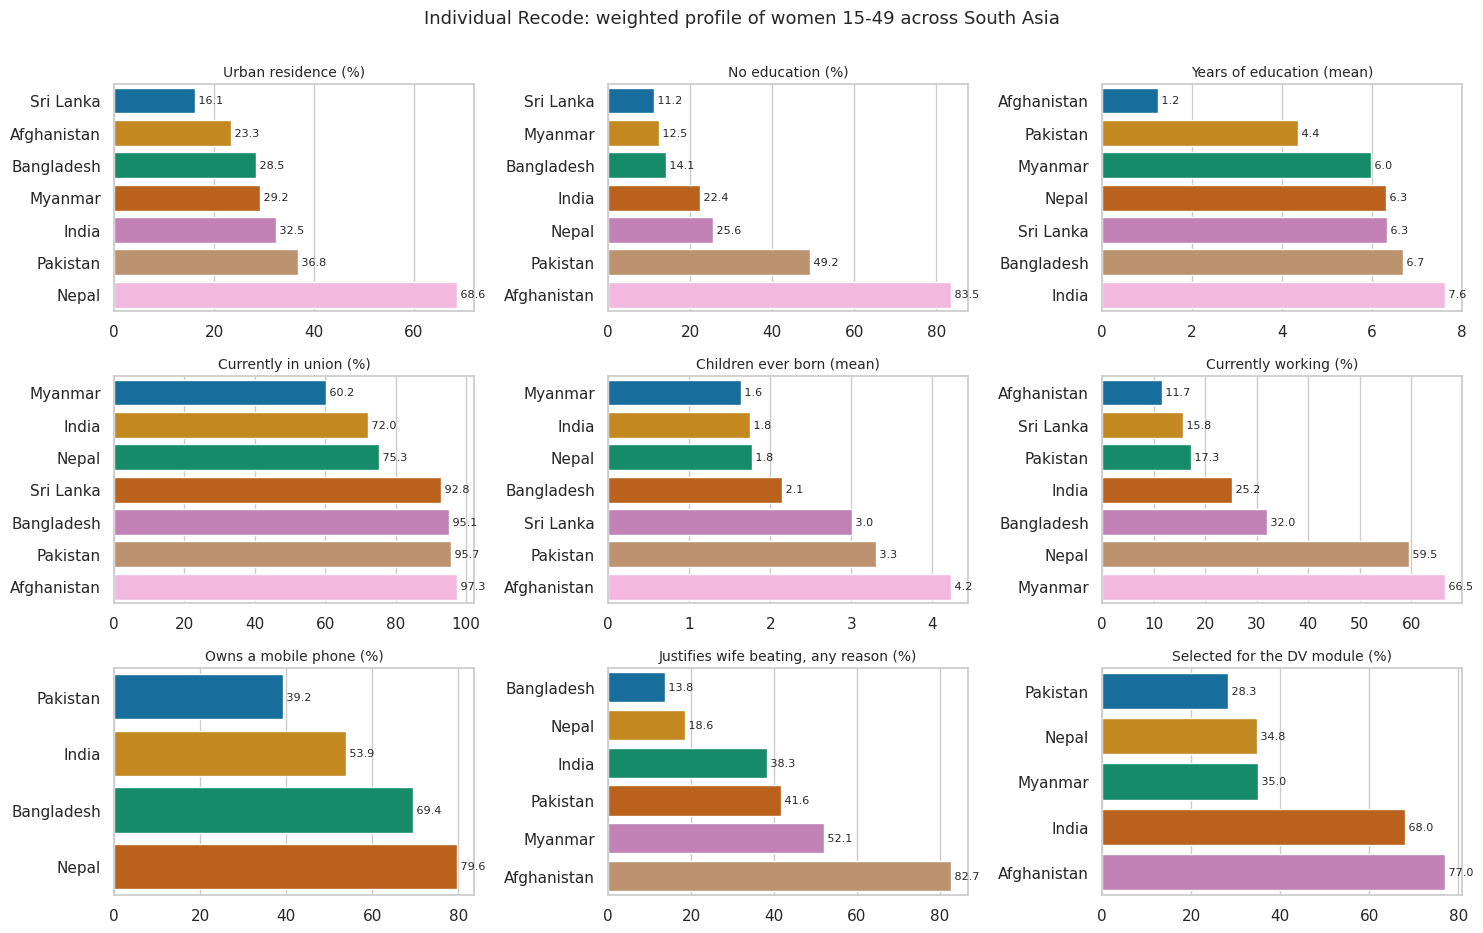

In [34]:
# ================================================================================================
# RECODE SOURCE
#   * Individual Recode (IR) - XXIRnnFL - one record per interviewed woman 15-49
# WHAT THIS CELL USES: ir_women + the woman's weight V005/1e6 (w_ind).
# NOTE: weighted_mean / weighted_percent / effective_n are the helpers defined in section 5.
# ================================================================================================
# 16c. Weighted country profile of women aged 15-49

ir_profile_rows = []
for country, g in ir_women.groupby("country", sort=True):
    w = g["w_ind"]
    row = {
        "country": country,
        "survey": g["survey"].iloc[0],
        "unweighted_women": len(g),
        "weighted_women": float(w.sum(skipna=True)),
        "effective_n": effective_n(w),
        "pct_urban": weighted_share(g["urban"], w, 1),
        "mean_age": weighted_mean(g["age"], w),
        "pct_no_education": weighted_share(g["no_education"], w, 1),
        "mean_years_education": weighted_mean(g["edu_years"], w),
        "pct_currently_married": weighted_share(g["in_union"], w, 1),
        "pct_never_married": weighted_share(g["never_married"], w, 1),
        "mean_children_ever_born": weighted_mean(g["children_ever_born"], w),
        "pct_working": weighted_share(g["currently_working"], w, 1),
        "pct_owns_mobile": weighted_share(g["owns_mobile"], w, 1),
        "pct_justifies_beating_any": weighted_share(g["justifies_beating_any"], w, 1),
        "mean_hh_size": weighted_mean(g["hh_size"], w),
        "mean_eligible_women": weighted_mean(g["n_eligible_women"], w),
        "pct_female_head": weighted_share(g["female_head"], w, 1),
        "pct_selected_for_dv": weighted_share(g["y_selected"], w, 1),
    }
    ir_profile_rows.append(row)

ir_country_profile = pd.DataFrame(ir_profile_rows)
display(Markdown("### Weighted profile of women 15-49 by country (weight = V005 / 1 000 000)"))
display(ir_country_profile.style.format({
    "unweighted_women": "{:,.0f}", "weighted_women": "{:,.0f}", "effective_n": "{:,.0f}",
    "pct_urban": "{:.1f}", "mean_age": "{:.1f}", "pct_no_education": "{:.1f}",
    "mean_years_education": "{:.1f}", "pct_currently_married": "{:.1f}",
    "pct_never_married": "{:.1f}", "mean_children_ever_born": "{:.2f}", "pct_working": "{:.1f}",
    "pct_owns_mobile": "{:.1f}", "pct_justifies_beating_any": "{:.1f}", "mean_hh_size": "{:.2f}",
    "mean_eligible_women": "{:.2f}", "pct_female_head": "{:.1f}", "pct_selected_for_dv": "{:.1f}",
}, na_rep="n/a"))
ir_country_profile.to_csv(OUTPUT_DIR / "ir_country_profile.csv", index=False)

PROFILE_PANELS = [
    ("pct_urban", "Urban residence (%)"),
    ("pct_no_education", "No education (%)"),
    ("mean_years_education", "Years of education (mean)"),
    ("pct_currently_married", "Currently in union (%)"),
    ("mean_children_ever_born", "Children ever born (mean)"),
    ("pct_working", "Currently working (%)"),
    ("pct_owns_mobile", "Owns a mobile phone (%)"),
    ("pct_justifies_beating_any", "Justifies wife beating, any reason (%)"),
    ("pct_selected_for_dv", "Selected for the DV module (%)"),
]
available_panels = [(c, t) for c, t in PROFILE_PANELS if ir_country_profile[c].notna().any()]
ncols = 3
nrows = int(np.ceil(len(available_panels) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5.0 * ncols, 3.1 * nrows))
axes = np.atleast_1d(axes).ravel()
for ax, (measure, title) in zip(axes, available_panels):
    sub = ir_country_profile.dropna(subset=[measure]).sort_values(measure)
    sns.barplot(data=sub, y="country", x=measure, ax=ax, palette=PALETTE, hue="country",
                legend=False, dodge=False)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel(""); ax.set_ylabel("")
    for patch, value in zip(ax.patches, sub[measure]):
        ax.text(patch.get_width(), patch.get_y() + patch.get_height() / 2,
                f" {value:,.1f}", va="center", fontsize=8)
for ax in axes[len(available_panels):]:
    ax.axis("off")
fig.suptitle("Individual Recode: weighted profile of women 15-49 across South Asia", y=1.002, fontsize=13)
plt.tight_layout(); plt.show()

### Weighted composition of women 15-49 (cells with fewer than 25 unweighted cases are flagged)

country                                           Afghanistan  Bangladesh  \
block                      category                                         
Age group                  15-19                     6.200000    8.600000   
                           20-24                    20.700001   16.299999   
                           25-29                    21.400000   17.500000   
                           30-34                    14.600000   17.000000   
                           35-39                    15.100000   17.000000   
                           40-44                    10.600000   12.700000   
                           45-49                    11.400000   10.800000   
Current marital status     Divorced                  0.100000    1.300000   
                           Living together           0.000000    0.000000   
                           Married                  97.300003   95.099998   
                           Never married             0.000000    0.000000   
                           Separated                 0.100000    0.800000   
                           Widowed                   2.500000    2.800000   
Highest education level    Higher                    1.900000   13.700000   
                           No education             83.500000   14.100000   
                           Primary                   7.900000   26.100000   
                           Secondary                 6.700000   46.200001   
Household wealth quintile  Middle                   20.000000   20.500000   
                           Poorer                   20.400000   20.000000   
                           Poorest                  20.000000   18.400000   
                           Richer                   20.400000   20.600000   
                           Richest                  19.200001   20.400000   
Work in the last 12 months Currently working        11.600000   31.700001   
                           Has a job, on leave       0.100000    0.300000   
                           In the past year          1.500000    5.300000   
                           Not in last 12 months    86.800003   62.700001   

country                                               India    Myanmar  \
block                      category                                      
Age group                  15-19                  16.900000  14.000000   
                           20-24                  16.500000  14.500000   
                           25-29                  16.200001  14.500000   
                           30-34                  13.900000  15.800000   
                           35-39                  13.500000  15.200000   
                           40-44                  11.300000  13.500000   
                           45-49                  11.800000  12.600000   
Current marital status     Divorced                0.300000   3.000000   
                           Living together         0.000000   0.000000   
                           Married                72.000000  60.200001   
                           Never married          23.799999  33.200001   
                           Separated               0.800000   0.300000   
                           Widowed                 3.100000   3.200000   
Highest education level    Higher                 15.700000  10.300000   
                           No education           22.400000  12.500000   
                           Primary                11.700000  41.200001   
                           Secondary              50.200001  36.099998   
Household wealth quintile  Middle                 20.500000  20.400000   
                           Poorer                 20.000000  18.700001   
                           Poorest                18.500000  17.700001   
                           Richer                 20.799999  21.000000   
                           Richest                20.200001  22.299999   
Work in the last 12 months Currently working      24.700001  65.300

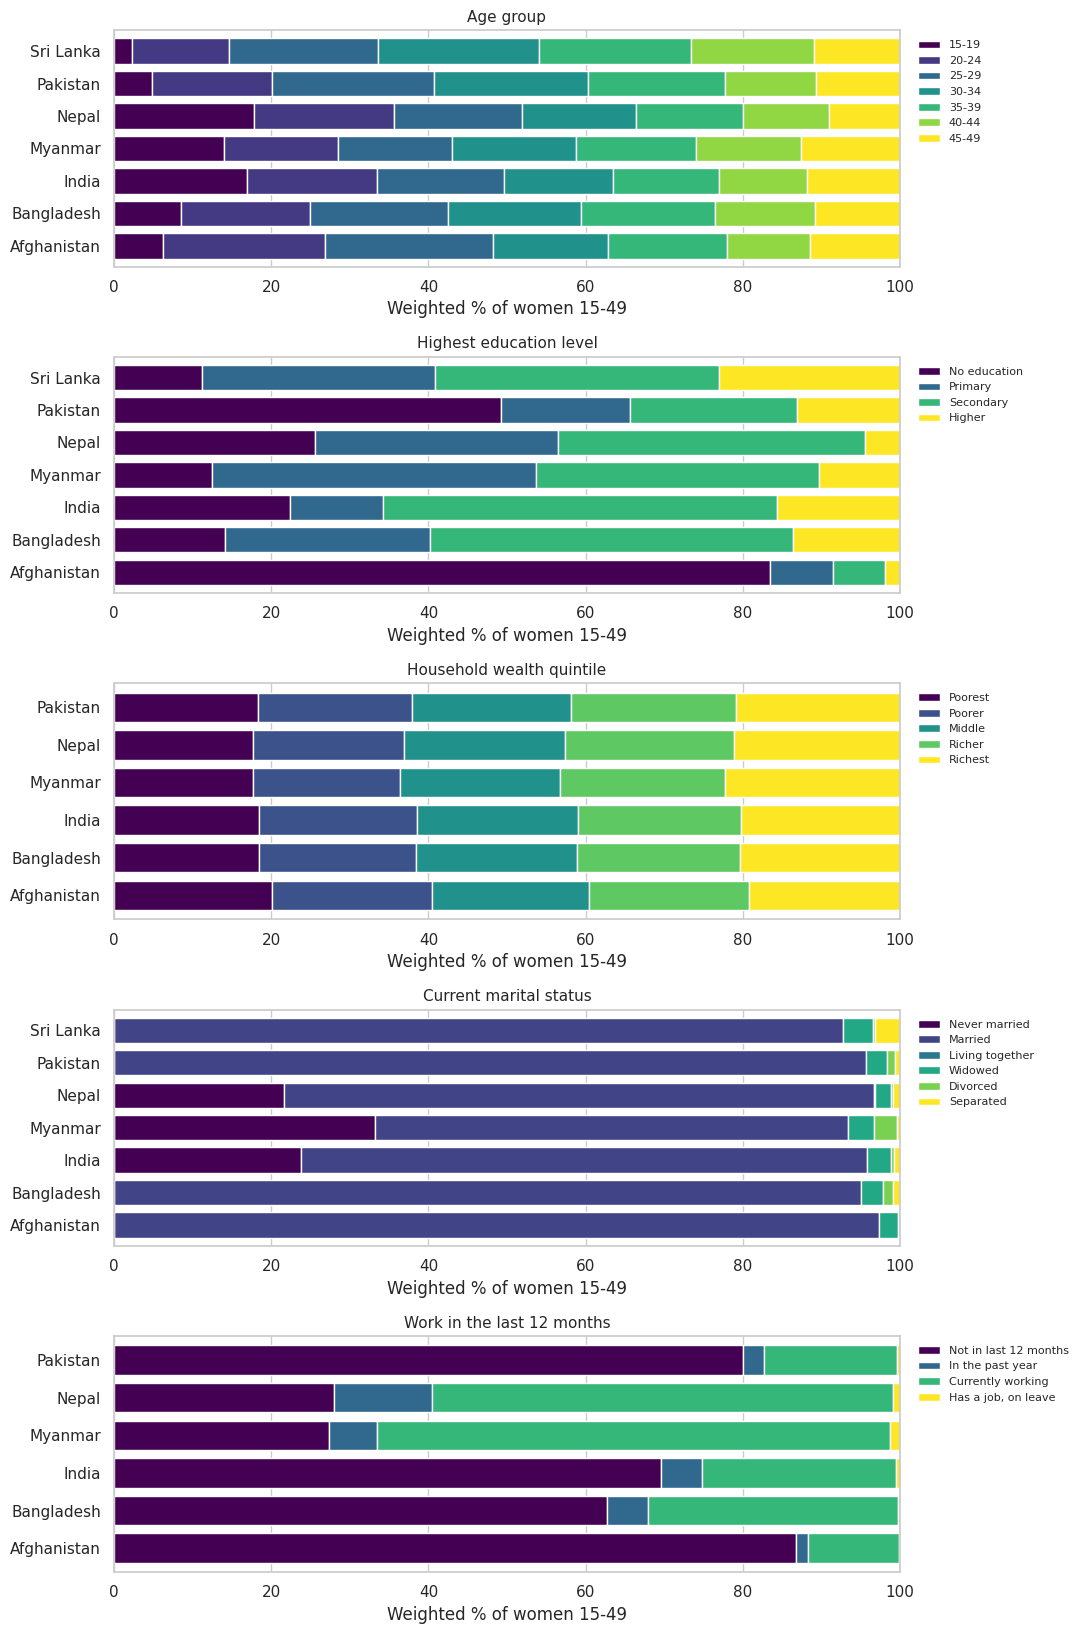

### Weighted distribution of the continuous IR measures

,country,measure,p10,p25,median,p75,p90,mean,coverage_pct
0,Afghanistan,age,20.00,24.00,30.00,38.00,45.00,31.16,100.00
1,Afghanistan,edu_years,0.00,0.00,0.00,0.00,6.00,1.24,99.92
2,Afghanistan,children_ever_born,1.00,2.00,4.00,6.00,8.00,4.22,100.00
3,Afghanistan,hh_size,5.00,6.00,8.00,11.00,15.00,9.28,100.00
4,Afghanistan,n_eligible_women,1.00,1.00,1.00,2.00,3.00,1.56,100.00
5,Afghanistan,wealth_score,-0.95,-0.56,-0.10,0.51,1.39,0.06,100.00
6,Afghanistan,age_at_cohabitation,14.00,15.00,17.00,20.00,22.00,17.91,100.00
7,Afghanistan,spousal_age_gap,1.00,2.00,4.00,7.00,12.00,5.51,96.81
8,Afghanistan,spousal_edu_gap,-11.00,-5.00,0.00,0.00,0.00,-2.35,98.44
9,Bangladesh,age,20.00,25.00,32.00,39.00,45.00,31.87,100.00


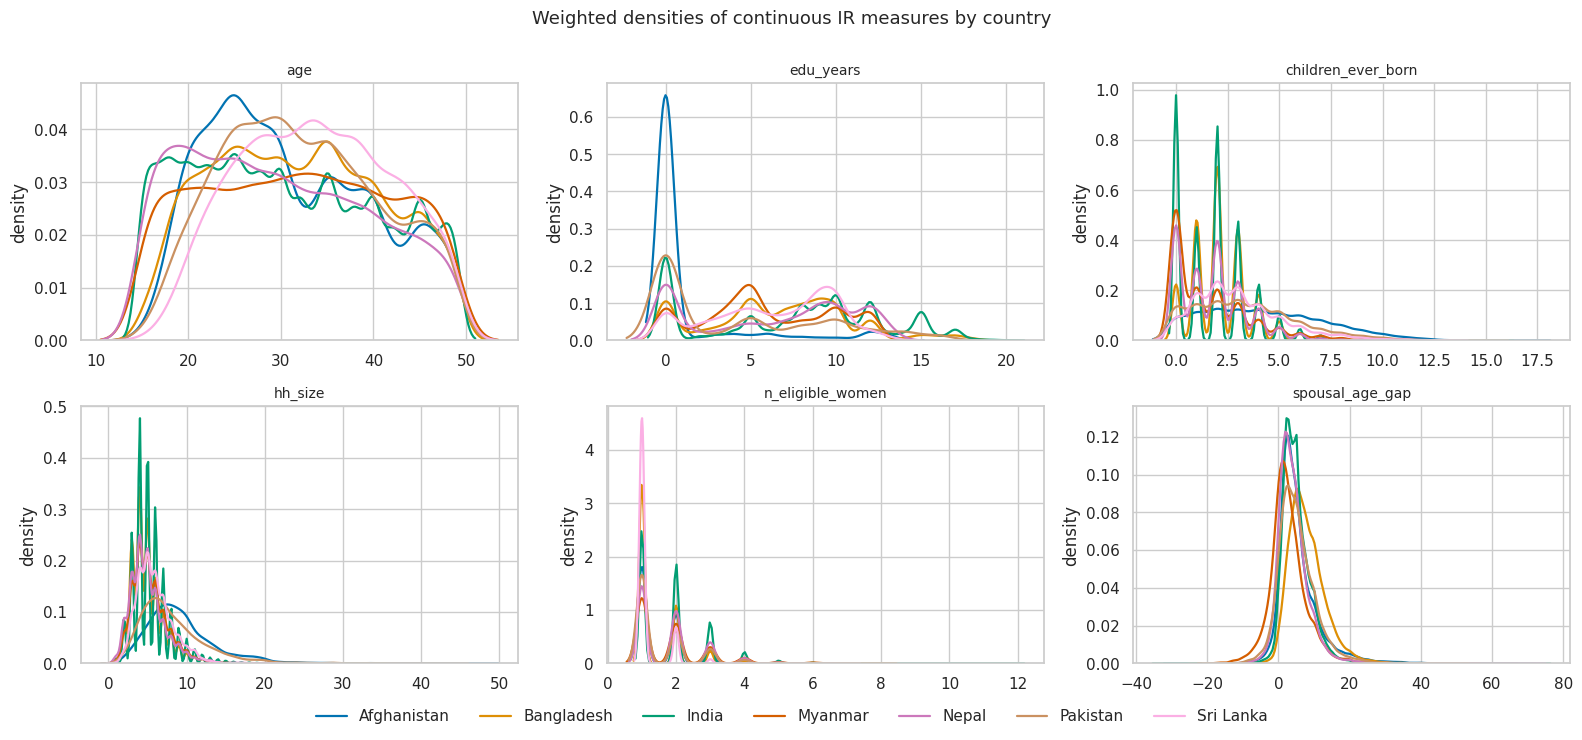

In [35]:
# ================================================================================================
# RECODE SOURCE
#   * Individual Recode (IR) - XXIRnnFL - one record per interviewed woman 15-49
# WHAT THIS CELL USES: ir_women + w_ind. Category labels reuse the EDUCATION / WEALTH / RESIDENCE
#   dictionaries defined for the Household Recode, because V106/V190/V025 share the coding of
#   HV106/HV270/HV025 in the standard DHS recode.
# ================================================================================================
# 16d. Weighted composition: age, education, wealth, marital status, work

IR_AGE_GROUP = {1: "15-19", 2: "20-24", 3: "25-29", 4: "30-34", 5: "35-39", 6: "40-44", 7: "45-49"}
IR_MARITAL = {0: "Never married", 1: "Married", 2: "Living together", 3: "Widowed",
              4: "Divorced", 5: "Separated"}
IR_WORK = {0: "Not in last 12 months", 1: "In the past year", 2: "Currently working",
           3: "Has a job, on leave"}

CATEGORY_BLOCKS = [
    ("age_group", IR_AGE_GROUP, "Age group"),
    ("edu_level", EDUCATION, "Highest education level"),
    ("wealth_quintile", WEALTH, "Household wealth quintile"),
    ("marital_status", IR_MARITAL, "Current marital status"),
    ("V731", IR_WORK, "Work in the last 12 months"),
]

ir_composition_rows = []
for variable, labels, title in CATEGORY_BLOCKS:
    if variable not in ir_women.columns:
        continue
    for country, g in ir_women.groupby("country", sort=True):
        w, series = g["w_ind"], g[variable]
        keep = series.notna() & w.notna()
        if not keep.any():
            continue
        total = w[keep].sum()
        for code, label in labels.items():
            mask = keep & series.eq(code)
            unweighted = int(mask.sum())
            ir_composition_rows.append({
                "block": title, "variable": variable, "code": code, "category": label,
                "country": country, "unweighted_n": unweighted,
                "weighted_pct": 100 * w[mask].sum() / total if total else np.nan,
                "suppressed": unweighted < MIN_UNWEIGHTED_CELL,
            })

ir_composition = pd.DataFrame(ir_composition_rows)
display(Markdown(f"### Weighted composition of women 15-49 "
                 f"(cells with fewer than {MIN_UNWEIGHTED_CELL} unweighted cases are flagged)"))
display(ir_composition.pivot_table(index=["block", "category"], columns="country",
                                   values="weighted_pct", aggfunc="first").round(1))
ir_composition.to_csv(OUTPUT_DIR / "ir_weighted_composition.csv", index=False)

blocks = [b for b in ir_composition.block.unique()]
fig, axes = plt.subplots(len(blocks), 1, figsize=(11, 3.3 * len(blocks)))
axes = np.atleast_1d(axes)
for ax, block in zip(axes, blocks):
    sub = ir_composition[ir_composition.block.eq(block)]
    order = [labels[c] for v, labels, t in CATEGORY_BLOCKS if t == block
             for c in labels if labels[c] in set(sub.category)]
    wide = sub.pivot_table(index="country", columns="category", values="weighted_pct",
                           aggfunc="first").reindex(columns=order)
    wide.plot(kind="barh", stacked=True, ax=ax, colormap="viridis", width=0.78, legend=True)
    ax.set_title(block, fontsize=11)
    ax.set_xlabel("Weighted % of women 15-49"); ax.set_ylabel("")
    ax.set_xlim(0, 100)
    ax.legend(bbox_to_anchor=(1.01, 1.0), loc="upper left", fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

# --- continuous distributions (weighted quantiles) -----------------------------------------------
def weighted_quantile(values, weights, q):
    keep = values.notna() & weights.notna() & weights.gt(0)
    if not keep.any():
        return np.nan
    v = values[keep].to_numpy(dtype="float64")
    w = weights[keep].to_numpy(dtype="float64")
    order = np.argsort(v)
    v, w = v[order], w[order]
    cum = np.cumsum(w) - 0.5 * w
    return float(np.interp(q * w.sum(), cum, v))


CONTINUOUS = ["age", "edu_years", "children_ever_born", "hh_size", "n_eligible_women",
              "wealth_score", "age_at_cohabitation", "spousal_age_gap", "spousal_edu_gap"]
CONTINUOUS = [c for c in CONTINUOUS if c in ir_women.columns]
quantile_rows = []
for country, g in ir_women.groupby("country", sort=True):
    for measure in CONTINUOUS:
        quantile_rows.append({
            "country": country, "measure": measure,
            "p10": weighted_quantile(g[measure], g["w_ind"], 0.10),
            "p25": weighted_quantile(g[measure], g["w_ind"], 0.25),
            "median": weighted_quantile(g[measure], g["w_ind"], 0.50),
            "p75": weighted_quantile(g[measure], g["w_ind"], 0.75),
            "p90": weighted_quantile(g[measure], g["w_ind"], 0.90),
            "mean": weighted_mean(g[measure], g["w_ind"]),
            "coverage_pct": 100 * g[measure].notna().mean(),
        })
ir_continuous_summary = pd.DataFrame(quantile_rows)
display(Markdown("### Weighted distribution of the continuous IR measures"))
display(ir_continuous_summary.style.format(
    {c: "{:.2f}" for c in ["p10", "p25", "median", "p75", "p90", "mean", "coverage_pct"]}, na_rep="n/a"))
ir_continuous_summary.to_csv(OUTPUT_DIR / "ir_continuous_summary.csv", index=False)

PLOT_CONT = [c for c in ["age", "edu_years", "children_ever_born", "hh_size",
                         "n_eligible_women", "spousal_age_gap"] if c in ir_women.columns]
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
axes = axes.ravel()
for ax, measure in zip(axes, PLOT_CONT):
    for i, (country, g) in enumerate(ir_women.groupby("country", sort=True)):
        keep = g[measure].notna() & g["w_ind"].notna()
        if keep.sum() < MIN_UNWEIGHTED_CELL:
            continue
        sns.kdeplot(x=g.loc[keep, measure], weights=g.loc[keep, "w_ind"], ax=ax,
                    label=country, color=PALETTE[i % len(PALETTE)], linewidth=1.6,
                    common_norm=False, warn_singular=False)
    ax.set_title(measure, fontsize=10); ax.set_xlabel(""); ax.set_ylabel("density")
for ax in axes[len(PLOT_CONT):]:
    ax.axis("off")
handles, labels_ = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_, loc="lower center", ncol=min(7, len(labels_)), frameon=False,
           bbox_to_anchor=(0.5, -0.04))
fig.suptitle("Weighted densities of continuous IR measures by country", y=1.0, fontsize=13)
plt.tight_layout(); plt.show()

### Result of the individual interview (V015)

country,Afghanistan,Bangladesh,India,Myanmar,Nepal,Pakistan
outcome,,,,,,
1 Completed,100.0,100.0,100.0,100.0,100.0,100.0
2 Not at home,0.0,0.0,0.0,0.0,0.0,0.0
3 Postponed,0.0,0.0,0.0,0.0,0.0,0.0
4 Refused,0.0,0.0,0.0,0.0,0.0,0.0
5 Partly completed,0.0,0.0,0.0,0.0,0.0,0.0
6 Incapacitated,0.0,0.0,0.0,0.0,0.0,0.0
7 Other,0.0,0.0,0.0,0.0,0.0,0.0


Every IR record in every archive has V015 = 1 (completed).


### Item completeness (%) of the scanned raw IR variables, after special-code cleaning

country,Afghanistan,Bangladesh,India,Myanmar,Nepal,Pakistan,Sri Lanka,block
V744D,88.6,66.2,14.8,87.0,99.8,96.4,0.0,attitudes
V744E,90.7,66.3,14.9,96.0,99.9,97.4,0.0,attitudes
V744B,92.4,66.2,14.9,96.1,99.9,97.6,0.0,attitudes
V744C,93.5,66.2,14.9,94.0,99.9,97.5,0.0,attitudes
V744A,93.9,65.8,14.9,95.4,99.9,97.8,0.0,attitudes
...,...,...,...,...,...,...,...,...
V190,100.0,100.0,100.0,100.0,100.0,100.0,0.0,wealth
V191,100.0,100.0,100.0,100.0,100.0,100.0,0.0,wealth
V714,99.7,66.5,15.0,100.0,100.0,100.0,99.8,work
V731,99.8,66.5,15.0,100.0,100.0,100.0,0.0,work


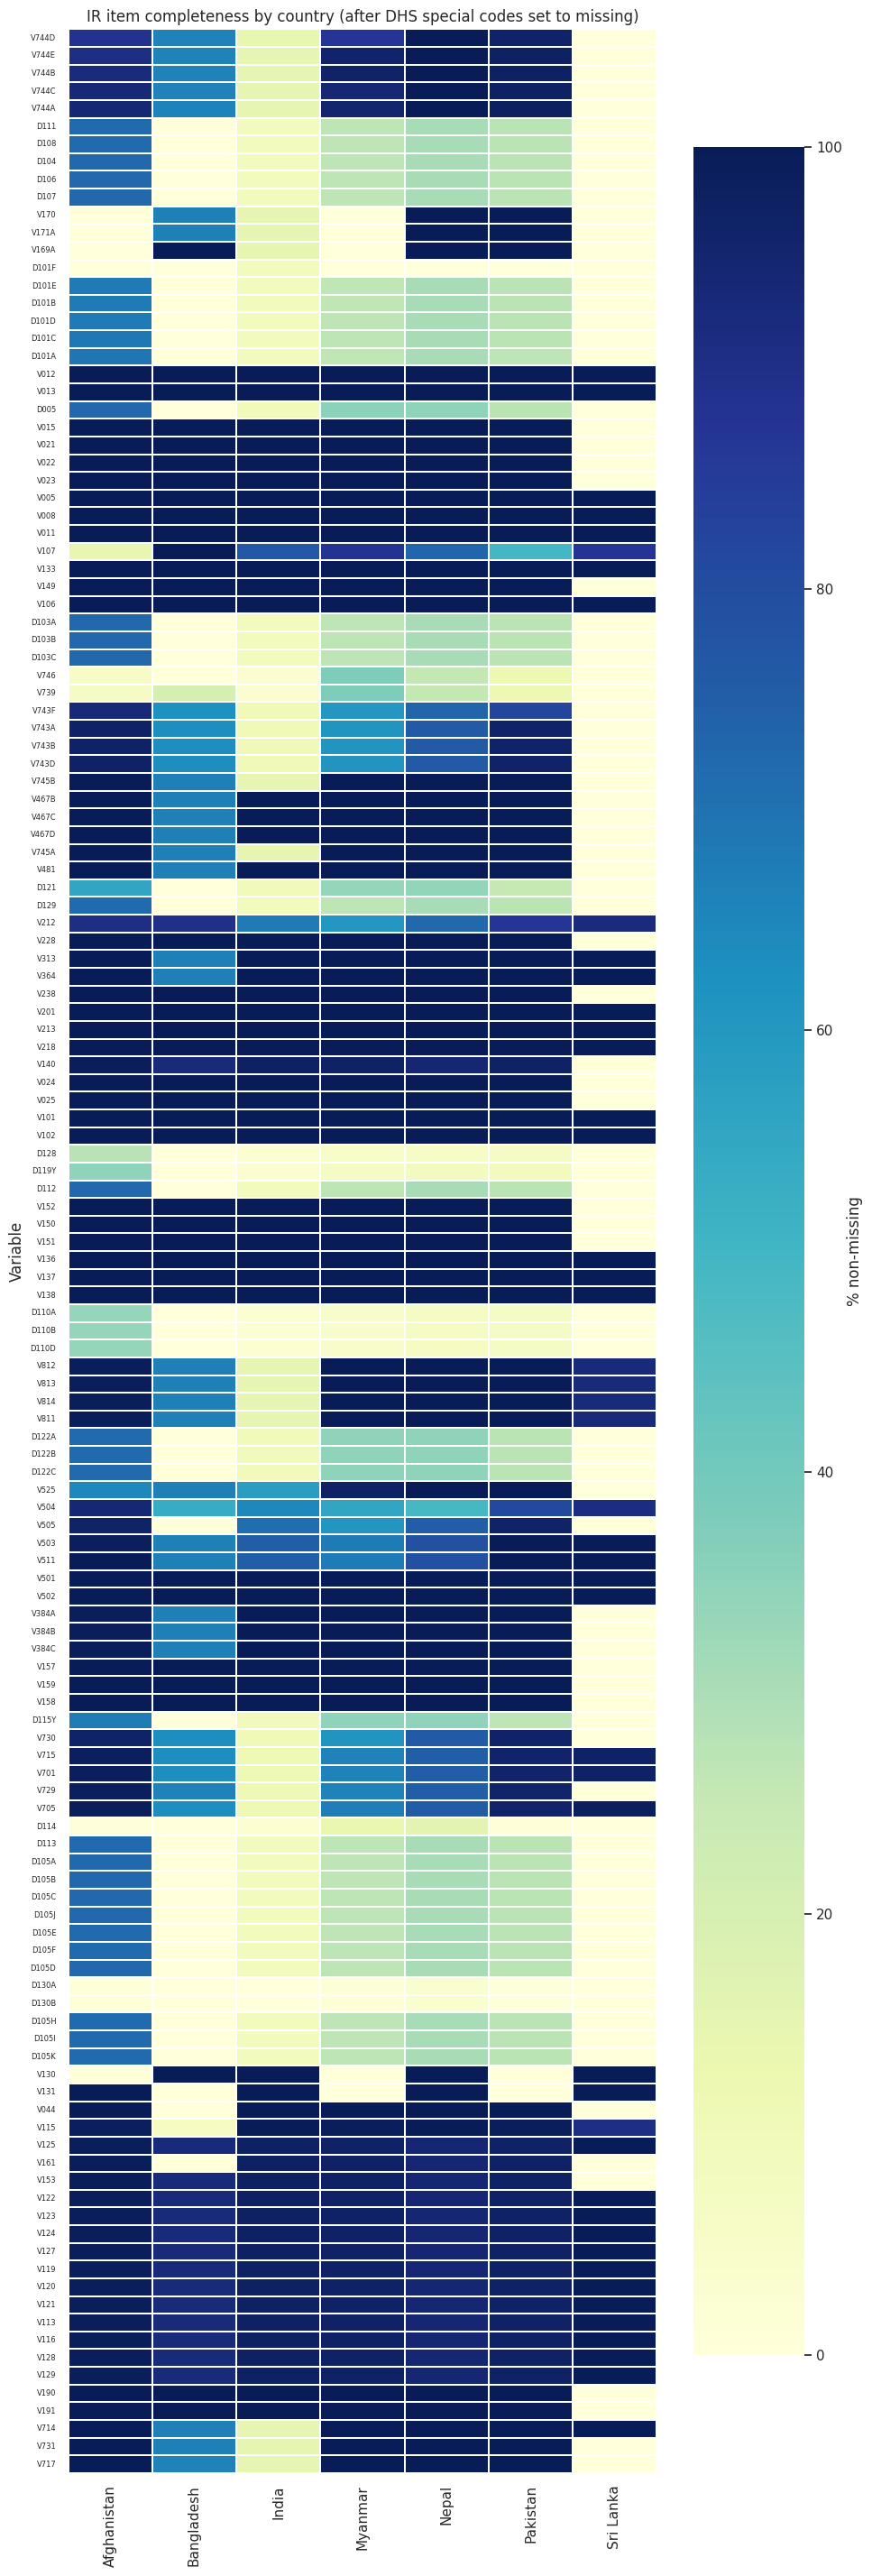

In [36]:
# ================================================================================================
# RECODE SOURCE
#   * Individual Recode (IR) - XXIRnnFL - one record per interviewed woman 15-49
# WHAT THIS CELL USES: V015 (result of the individual interview) and item-level completeness.
# ================================================================================================
# 16e. Interview outcome and field-level completeness

V015_LABELS = {1: "1 Completed", 2: "2 Not at home", 3: "3 Postponed", 4: "4 Refused",
               5: "5 Partly completed", 6: "6 Incapacitated", 7: "7 Other"}

if "V015" in ir_women.columns:
    outcome_rows = []
    for country, g in ir_women.groupby("country", sort=True):
        keep = g["V015"].notna()
        total_unweighted = int(keep.sum())
        total_weighted = g.loc[keep, "w_ind"].sum()
        for code, label in V015_LABELS.items():
            mask = keep & g["V015"].eq(code)
            outcome_rows.append({
                "country": country, "code": code, "outcome": label,
                "unweighted_n": int(mask.sum()),
                "unweighted_pct": 100 * mask.sum() / total_unweighted if total_unweighted else np.nan,
                "weighted_pct": 100 * g.loc[mask, "w_ind"].sum() / total_weighted if total_weighted else np.nan,
            })
    ir_interview_outcome = pd.DataFrame(outcome_rows)
    display(Markdown("### Result of the individual interview (V015)"))
    display(ir_interview_outcome.pivot_table(index="outcome", columns="country",
                                            values="unweighted_pct", aggfunc="first").round(2))
    ir_interview_outcome.to_csv(OUTPUT_DIR / "ir_interview_outcome.csv", index=False)

    non_completed = ir_interview_outcome[ir_interview_outcome.code.ne(1) &
                                         ir_interview_outcome.unweighted_n.gt(0)]
    if len(non_completed):
        plt.figure(figsize=(11, 3.6))
        sns.barplot(data=non_completed, x="country", y="unweighted_pct", hue="outcome",
                    palette="rocket")
        plt.title("Non-completed individual interviews by country (unweighted %)")
        plt.ylabel("% of IR records"); plt.xlabel("")
        plt.legend(bbox_to_anchor=(1.01, 1.0), loc="upper left", fontsize=8, frameon=False)
        plt.tight_layout(); plt.show()
    else:
        print("Every IR record in every archive has V015 = 1 (completed).")
else:
    print("V015 is absent from all IR layouts; interview-outcome analysis skipped.")

# --- completeness of the scanned raw IR variables ------------------------------------------------
scanned_vars = [v for v in IR_SCAN_VARS if v in ir_women.columns]
completeness = (ir_women.groupby("country")[scanned_vars]
                .apply(lambda g: g.notna().mean() * 100).T.round(1))
completeness["block"] = (pd.concat([IR_PLAN[["variable", "block"]],
                                    DV_PLAN[["variable", "domain"]].rename(columns={"domain": "block"})])
                         .drop_duplicates("variable").set_index("variable")["block"]
                         .reindex(completeness.index))
completeness = completeness.sort_values(["block"] + [c for c in completeness.columns if c != "block"])
display(Markdown("### Item completeness (%) of the scanned raw IR variables, after special-code cleaning"))
display(completeness)
completeness.to_csv(OUTPUT_DIR / "ir_item_completeness.csv")

heat = completeness.drop(columns="block")
plt.figure(figsize=(1.4 * max(6, heat.shape[1]), 0.19 * len(heat) + 2.5))
sns.heatmap(heat, cmap="YlGnBu", vmin=0, vmax=100, linewidths=0.25, linecolor="white",
            cbar_kws={"label": "% non-missing"})
plt.title("IR item completeness by country (after DHS special codes set to missing)")
plt.xlabel(""); plt.ylabel("Variable"); plt.yticks(fontsize=6)
plt.tight_layout(); plt.show()

### 'Wife beating is justified if ...' — weighted % of women agreeing

country,Afghanistan,Bangladesh,India,Myanmar,Nepal,Pakistan
reason,,,,,,
Argues with him,63.900002,9.0,22.100000,10.800000,4.7,32.299999
Burns the food,20.400000,1.4,13.800000,13.300000,1.2,18.700001
Goes out without telling him,71.500000,5.9,19.299999,22.600000,5.6,32.200001
Neglects the children,52.500000,7.4,27.700001,43.799999,15.3,28.400000
Refuses to have sex,38.200001,3.3,11.100000,12.100000,1.6,28.299999


/tmp/ipykernel_116/348621164.py:46: UserWarning: The palette list has more values (10) than needed (6), which may not be intended.
  sns.barplot(data=ir_attitudes, y="reason", x="pct_agrees", hue="country", ax=axes[0],


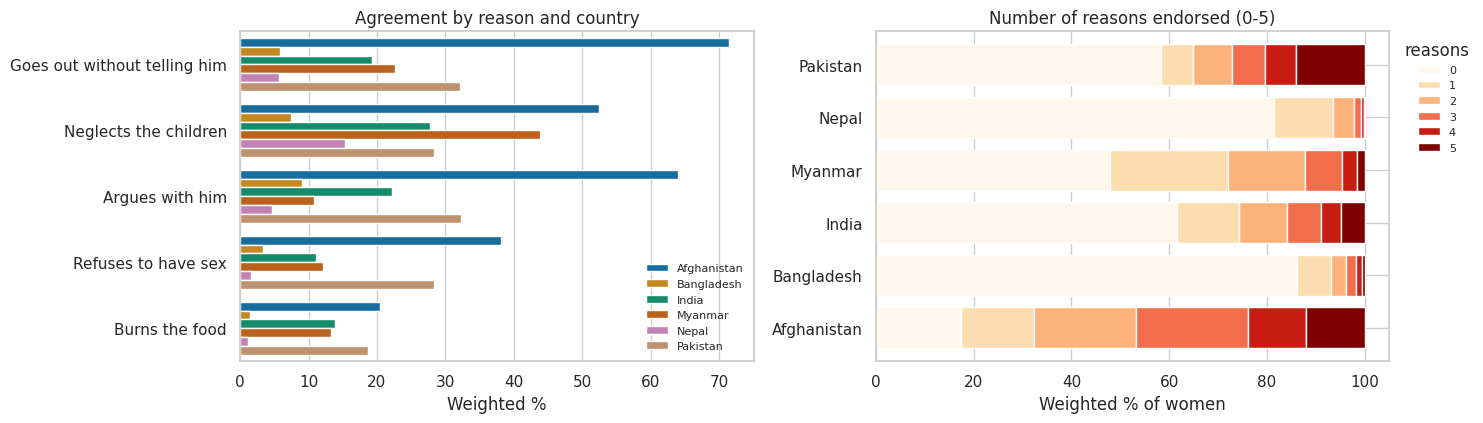

### Autonomy, asset ownership and media exposure (weighted % of women)

country,Afghanistan,Bangladesh,India,Myanmar,Nepal,Pakistan
measure,,,,,,
Covered by health insurance,0.100000,0.300000,29.799999,0.900000,12.000000,1.400000
Has a bank/financial account,NaN,20.000000,78.599998,NaN,49.099998,6.000000
Has a say over her own earnings,75.400002,91.300003,85.099998,91.800003,93.400002,89.400002
Has ever used the internet,NaN,30.100000,33.299999,NaN,66.400002,12.600000
Her own health care,47.799999,75.300003,81.099998,83.400002,71.699997,50.500000
How his earnings are used,33.099998,69.000000,77.000000,87.699997,72.199997,54.200001
Large household purchases,42.299999,69.199997,79.500000,74.400002,59.900002,44.099998
Listens to the radio at least occasionally,38.400002,3.000000,13.300000,44.400002,48.700001,8.200000
Owns a house (alone or jointly),39.099998,5.700000,42.299999,54.000000,8.000000,3.300000


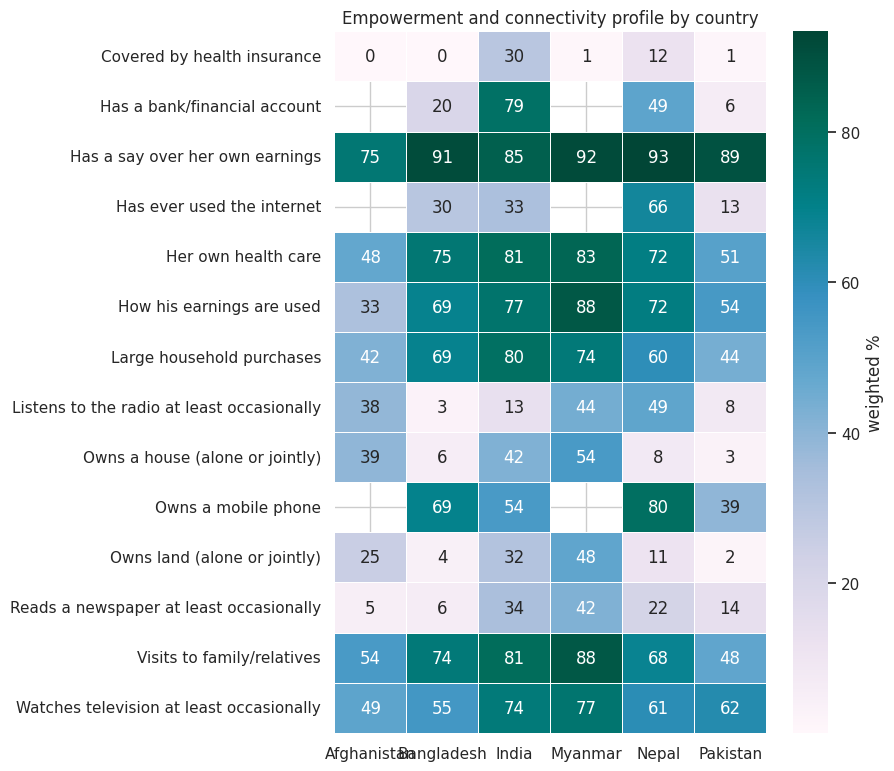

### Weighted means of the composite indices

,empowerment_index,decision_index,attitude_index,media_index,connectivity_index,asset_index,dwelling_quality,healthcare_barrier_index
country,,,,,,,,
Afghanistan,0.438,0.444,0.501,0.310,NaN,0.349,0.439,0.617
Bangladesh,0.531,0.720,0.054,0.215,0.496,0.315,0.805,0.397
India,0.626,0.796,0.189,0.403,0.553,0.416,0.772,0.194
Myanmar,0.616,0.833,0.210,0.543,NaN,0.363,0.470,0.206
Nepal,0.528,0.680,0.057,0.438,0.650,0.351,0.707,0.295
Pakistan,0.260,0.479,0.281,0.282,0.193,0.394,0.720,0.312
Sri Lanka,NaN,NaN,NaN,NaN,NaN,0.240,0.000,NaN


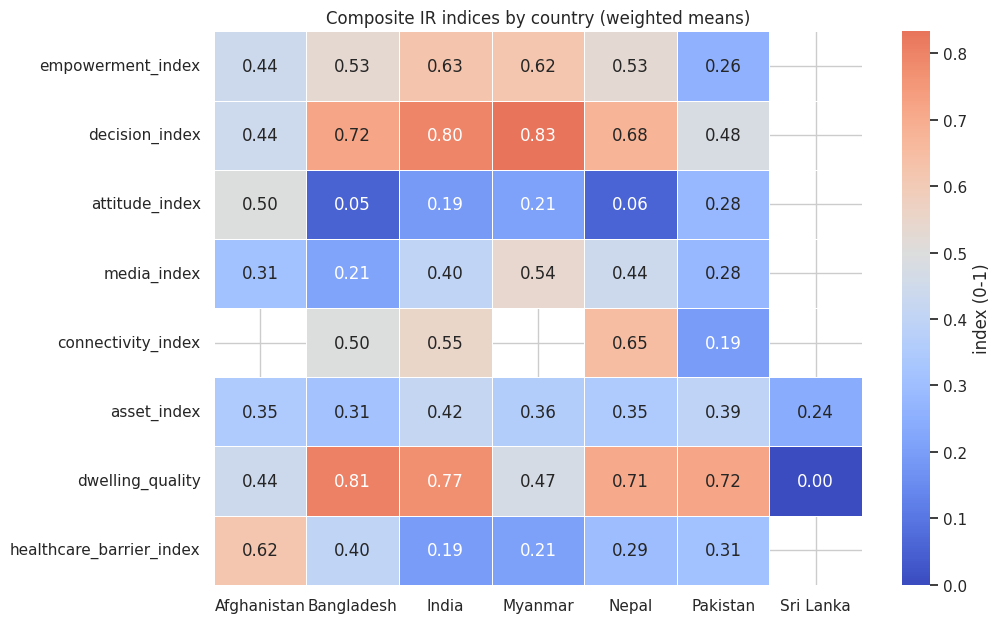

In [37]:
# ================================================================================================
# RECODE SOURCE
#   * Individual Recode (IR) - XXIRnnFL - one record per interviewed woman 15-49
# WHAT THIS CELL USES: the empowerment (V739/V743x/V745x/V746), media (V157-V159) and
#   wife-beating attitude (V744A-E) blocks of the Individual Recode, with the V005 weight.
# ================================================================================================
# 16f. Autonomy, media exposure and attitudes to wife beating

ATTITUDE_LABELS = {
    "V744A": "Goes out without telling him",
    "V744B": "Neglects the children",
    "V744C": "Argues with him",
    "V744D": "Refuses to have sex",
    "V744E": "Burns the food",
}
DECISION_LABELS = {
    "decides_v743a": "Her own health care",
    "decides_v743b": "Large household purchases",
    "decides_v743d": "Visits to family/relatives",
    "decides_v743f": "How his earnings are used",
}

# --- attitudes ------------------------------------------------------------------------------------
attitude_rows = []
for country, g in ir_women.groupby("country", sort=True):
    for var, label in ATTITUDE_LABELS.items():
        if var not in g.columns:
            continue
        keep = g[var].notna()
        if keep.sum() < MIN_UNWEIGHTED_CELL:
            continue
        attitude_rows.append({
            "country": country, "variable": var, "reason": label,
            "unweighted_n": int(keep.sum()),
            "pct_agrees": weighted_share(g[var], g["w_ind"], 1),
        })
ir_attitudes = pd.DataFrame(attitude_rows)

if len(ir_attitudes):
    display(Markdown("### 'Wife beating is justified if ...' — weighted % of women agreeing"))
    display(ir_attitudes.pivot_table(index="reason", columns="country", values="pct_agrees",
                                    aggfunc="first").round(1))
    ir_attitudes.to_csv(OUTPUT_DIR / "ir_attitudes_wife_beating.csv", index=False)

    fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
    sns.barplot(data=ir_attitudes, y="reason", x="pct_agrees", hue="country", ax=axes[0],
                palette=PALETTE)
    axes[0].set_title("Agreement by reason and country"); axes[0].set_xlabel("Weighted %")
    axes[0].set_ylabel(""); axes[0].legend(fontsize=8, frameon=False)

    count_rows = []
    for country, g in ir_women.groupby("country", sort=True):
        keep = g["justifies_beating_count"].notna()
        if keep.sum() < MIN_UNWEIGHTED_CELL:
            continue
        total = g.loc[keep, "w_ind"].sum()
        for k in range(0, 6):
            mask = keep & g["justifies_beating_count"].eq(k)
            count_rows.append({"country": country, "n_reasons": k,
                               "weighted_pct": 100 * g.loc[mask, "w_ind"].sum() / total if total else np.nan})
    ir_attitude_counts = pd.DataFrame(count_rows)
    wide = ir_attitude_counts.pivot_table(index="country", columns="n_reasons",
                                         values="weighted_pct", aggfunc="first")
    wide.plot(kind="barh", stacked=True, ax=axes[1], colormap="OrRd", width=0.78)
    axes[1].set_title("Number of reasons endorsed (0-5)")
    axes[1].set_xlabel("Weighted % of women"); axes[1].set_ylabel("")
    axes[1].legend(title="reasons", bbox_to_anchor=(1.01, 1.0), loc="upper left", fontsize=8,
                   frameon=False)
    plt.tight_layout(); plt.show()
    ir_attitude_counts.to_csv(OUTPUT_DIR / "ir_attitude_reason_counts.csv", index=False)
else:
    print("The wife-beating attitude module (V744A-E) is not available in any supplied IR archive.")

# --- decision-making, ownership, media -----------------------------------------------------------
EMPOWER_MEASURES = {
    **DECISION_LABELS,
    "controls_own_earnings": "Has a say over her own earnings",
    "owns_house": "Owns a house (alone or jointly)",
    "owns_land": "Owns land (alone or jointly)",
    "owns_mobile": "Owns a mobile phone",
    "has_bank_account": "Has a bank/financial account",
    "uses_internet": "Has ever used the internet",
    "reads_newspaper": "Reads a newspaper at least occasionally",
    "listens_radio": "Listens to the radio at least occasionally",
    "watches_tv": "Watches television at least occasionally",
    "health_insurance": "Covered by health insurance",
}
empower_rows = []
for country, g in ir_women.groupby("country", sort=True):
    for var, label in EMPOWER_MEASURES.items():
        if var not in g.columns:
            continue
        keep = g[var].notna()
        if keep.sum() < MIN_UNWEIGHTED_CELL:
            continue
        empower_rows.append({
            "country": country, "measure": label, "variable": var,
            "unweighted_n": int(keep.sum()),
            "pct_yes": weighted_share(g[var], g["w_ind"], 1),
        })
ir_empowerment = pd.DataFrame(empower_rows)
display(Markdown("### Autonomy, asset ownership and media exposure (weighted % of women)"))
display(ir_empowerment.pivot_table(index="measure", columns="country", values="pct_yes",
                                  aggfunc="first").round(1))
ir_empowerment.to_csv(OUTPUT_DIR / "ir_empowerment_measures.csv", index=False)

heat = ir_empowerment.pivot_table(index="measure", columns="country", values="pct_yes", aggfunc="first")
plt.figure(figsize=(1.5 * max(5, heat.shape[1]), 0.42 * len(heat) + 2.0))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="PuBuGn", linewidths=0.4, linecolor="white",
            cbar_kws={"label": "weighted %"})
plt.title("Empowerment and connectivity profile by country")
plt.xlabel(""); plt.ylabel("")
plt.tight_layout(); plt.show()

# --- composite indices ----------------------------------------------------------------------------
INDEX_COLS = [c for c in ["empowerment_index", "decision_index", "attitude_index", "media_index",
                          "connectivity_index", "asset_index", "dwelling_quality",
                          "healthcare_barrier_index"] if c in ir_women.columns]
index_summary = summarise_groups(
    ir_women, "country",
    lambda g: {c: weighted_mean(g[c], g["w_ind"]) for c in INDEX_COLS}).round(3)
display(Markdown("### Weighted means of the composite indices"))
display(index_summary)
index_summary.to_csv(OUTPUT_DIR / "ir_composite_indices.csv")

plt.figure(figsize=(1.5 * max(5, index_summary.shape[0]), 0.55 * index_summary.shape[1] + 2.0))
sns.heatmap(index_summary.T, annot=True, fmt=".2f", cmap="coolwarm", center=0.5,
            linewidths=0.4, linecolor="white", cbar_kws={"label": "index (0-1)"})
plt.title("Composite IR indices by country (weighted means)")
plt.xlabel(""); plt.ylabel("")
plt.tight_layout(); plt.show()

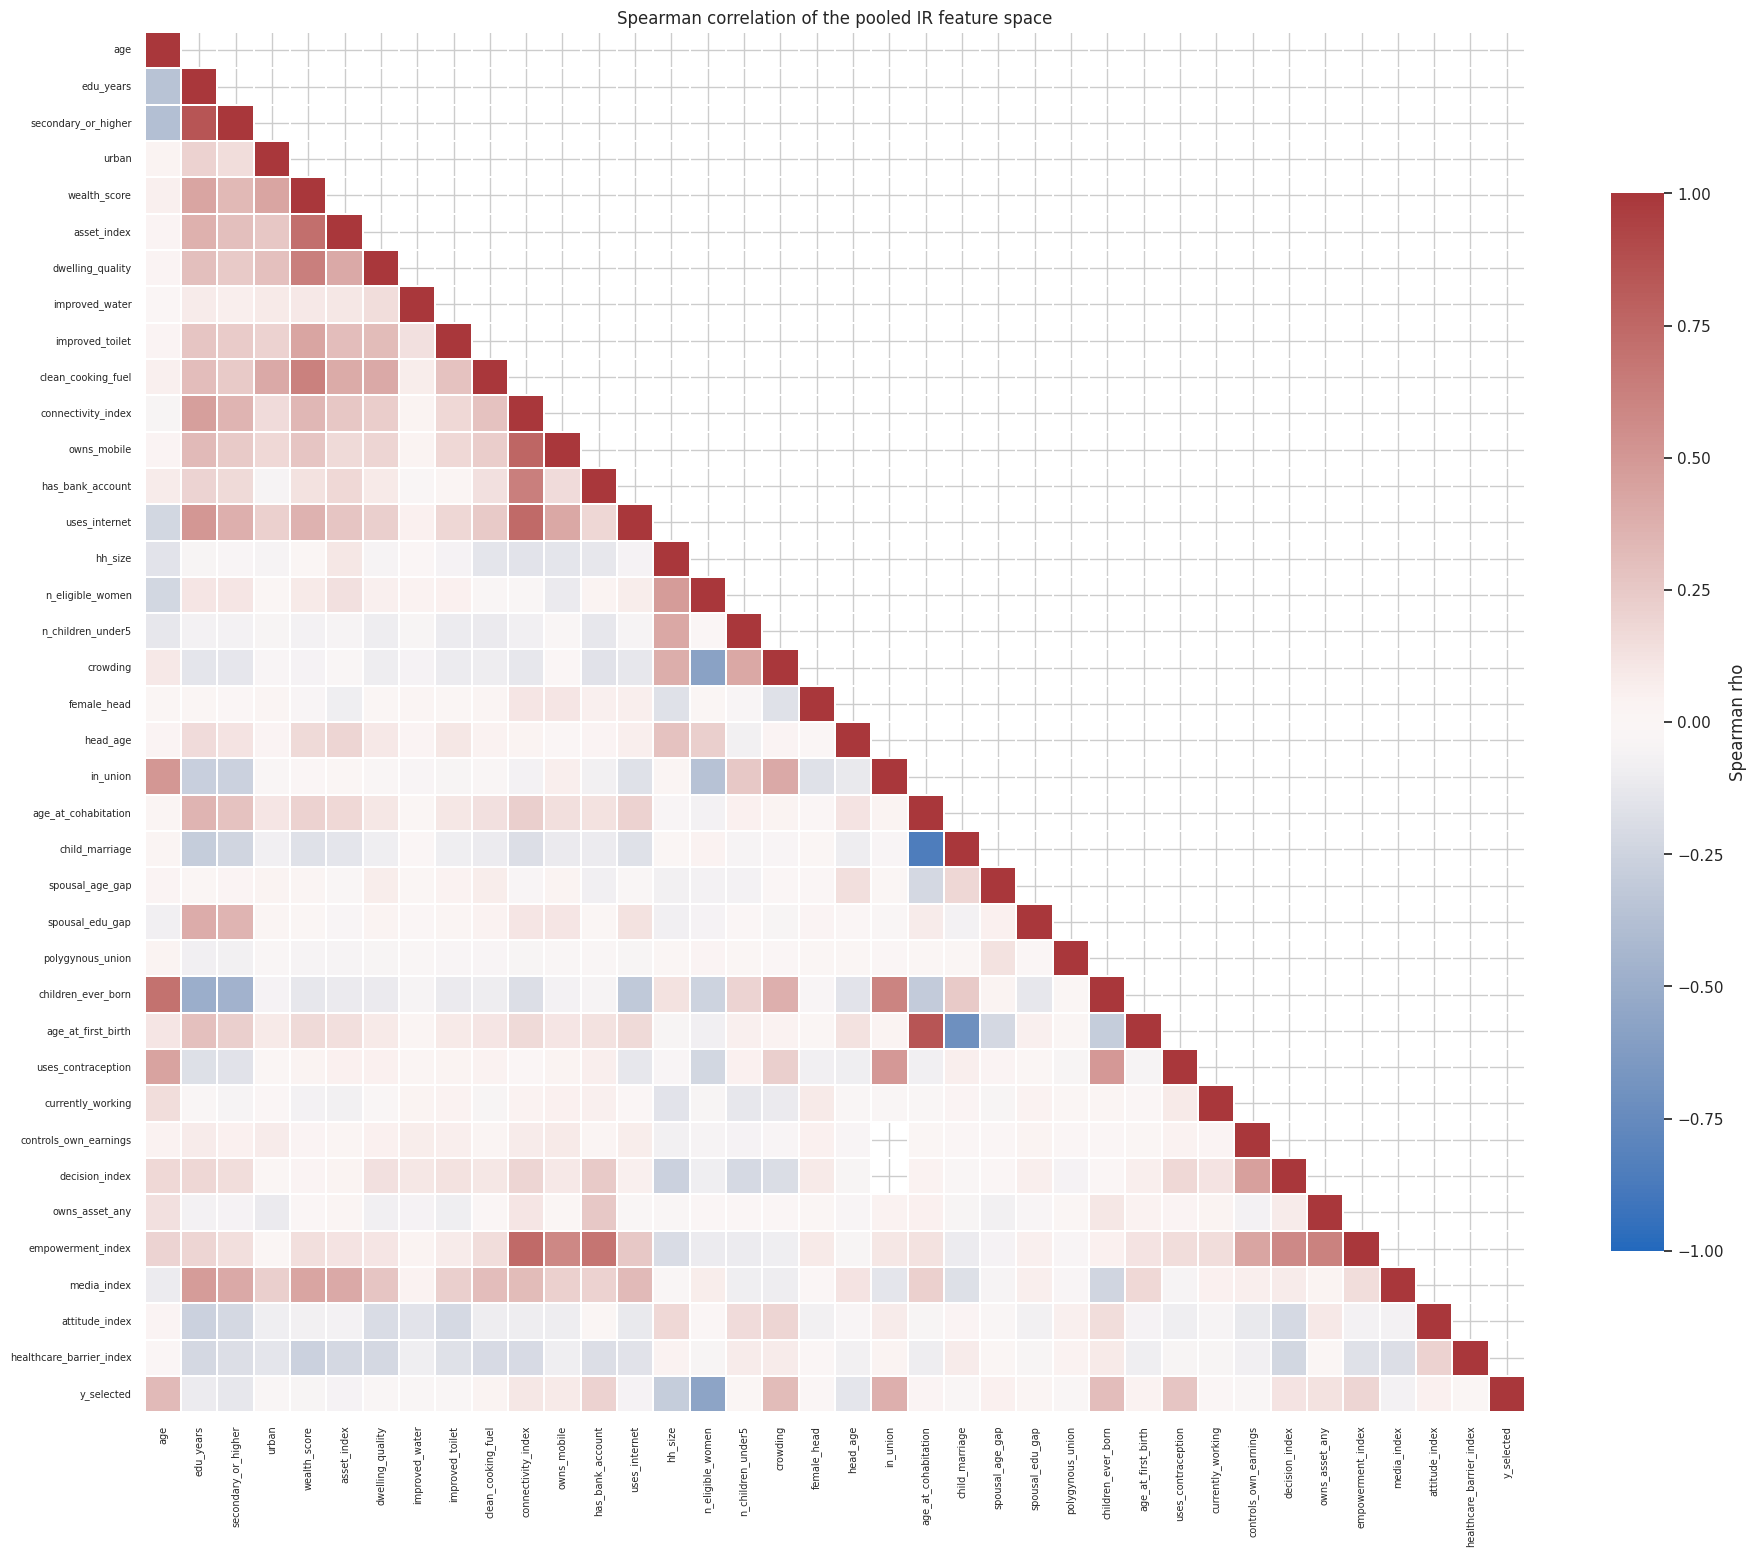

### Feature pairs with |Spearman rho| >= 0.55 (collinearity watch list)

,feature_a,feature_b,rho
0,child_marriage,age_at_cohabitation,-0.853
1,secondary_or_higher,edu_years,+0.850
2,age_at_first_birth,age_at_cohabitation,+0.849
3,owns_mobile,connectivity_index,+0.765
4,empowerment_index,connectivity_index,+0.742
5,uses_internet,connectivity_index,+0.741
6,asset_index,wealth_score,+0.717
7,age_at_first_birth,child_marriage,-0.714
8,children_ever_born,age,+0.696
9,empowerment_index,has_bank_account,+0.685


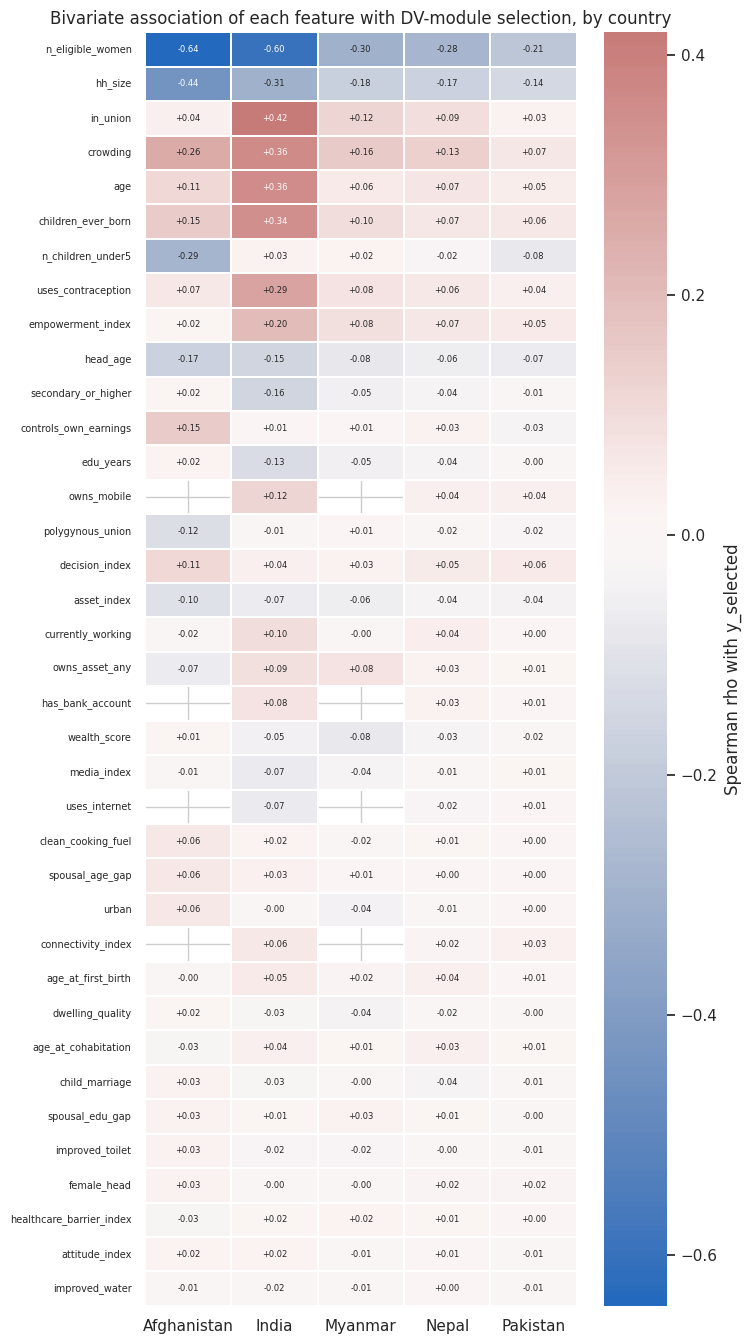

**Reading this chart:** `n_eligible_women` (and its reciprocal) dominates every column. That is the sampling design, not a demographic finding — the DV module is administered to one randomly chosen eligible woman per selected household.

In [38]:
# ================================================================================================
# RECODE SOURCE
#   * Individual Recode (IR) - XXIRnnFL - one record per interviewed woman 15-49
# WHAT THIS CELL USES: the derived numeric IR feature space (DERIVED_FEATURES).
# ================================================================================================
# 16g. Correlation structure of the IR feature space

CORR_FEATURES = [c for c in [
    "age", "edu_years", "secondary_or_higher", "urban", "wealth_score", "asset_index",
    "dwelling_quality", "improved_water", "improved_toilet", "clean_cooking_fuel",
    "connectivity_index", "owns_mobile", "has_bank_account", "uses_internet",
    "hh_size", "n_eligible_women", "n_children_under5", "crowding", "female_head", "head_age",
    "in_union", "age_at_cohabitation", "child_marriage", "spousal_age_gap", "spousal_edu_gap",
    "polygynous_union", "children_ever_born", "age_at_first_birth", "uses_contraception",
    "currently_working", "controls_own_earnings", "decision_index", "owns_asset_any",
    "empowerment_index", "media_index", "attitude_index", "healthcare_barrier_index",
    "y_selected",
] if c in ir_women.columns]

corr_pool = ir_women[CORR_FEATURES]
corr_matrix = corr_pool.corr(method="spearman", min_periods=500)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
plt.figure(figsize=(0.42 * len(CORR_FEATURES) + 3, 0.40 * len(CORR_FEATURES) + 3))
sns.heatmap(corr_matrix, mask=mask, cmap="vlag", center=0, vmin=-1, vmax=1,
            linewidths=0.2, linecolor="white", square=True,
            cbar_kws={"shrink": 0.6, "label": "Spearman rho"})
plt.title("Spearman correlation of the pooled IR feature space")
plt.xticks(fontsize=7, rotation=90); plt.yticks(fontsize=7)
plt.tight_layout(); plt.show()
corr_matrix.round(3).to_csv(OUTPUT_DIR / "ir_feature_correlations.csv")

# --- pairs strong enough to matter for collinearity in the linear models --------------------------
pairs = (corr_matrix.where(mask.T)
         .stack().rename("rho").reset_index()
         .rename(columns={"level_0": "feature_a", "level_1": "feature_b"}))
strong_pairs = (pairs[pairs.rho.abs().ge(0.55) & pairs.feature_a.ne(pairs.feature_b)]
                .assign(abs_rho=lambda x: x.rho.abs())
                .sort_values("abs_rho", ascending=False)
                .drop(columns="abs_rho").reset_index(drop=True))
display(Markdown("### Feature pairs with |Spearman rho| >= 0.55 (collinearity watch list)"))
display(strong_pairs.style.format({"rho": "{:+.3f}"}))
strong_pairs.to_csv(OUTPUT_DIR / "ir_strong_feature_pairs.csv", index=False)

# --- how each feature relates to DV-module selection, per country --------------------------------
if "y_selected" in ir_women.columns and ir_women.y_selected.notna().any():
    corr_rows = []
    for country, g in ir_women.groupby("country", sort=True):
        if g.y_selected.notna().sum() < MIN_UNWEIGHTED_CELL:
            continue
        for feature in CORR_FEATURES:
            if feature == "y_selected":
                continue
            keep = g[feature].notna() & g.y_selected.notna()
            if keep.sum() < 500 or g.loc[keep, feature].nunique() < 2:
                continue
            corr_rows.append({
                "country": country, "feature": feature,
                "rho": float(g.loc[keep, feature].corr(g.loc[keep, "y_selected"], method="spearman")),
                "n": int(keep.sum()),
            })
    ir_selection_corr = pd.DataFrame(corr_rows)
    sel_heat = ir_selection_corr.pivot_table(index="feature", columns="country", values="rho",
                                            aggfunc="first")
    sel_heat = sel_heat.reindex(sel_heat.abs().max(axis=1).sort_values(ascending=False).index)
    plt.figure(figsize=(1.5 * max(5, sel_heat.shape[1]), 0.30 * len(sel_heat) + 2.5))
    sns.heatmap(sel_heat, annot=True, fmt="+.2f", annot_kws={"fontsize": 6}, cmap="vlag",
                center=0, linewidths=0.3, linecolor="white",
                cbar_kws={"label": "Spearman rho with y_selected"})
    plt.title("Bivariate association of each feature with DV-module selection, by country")
    plt.xlabel(""); plt.ylabel(""); plt.yticks(fontsize=7)
    plt.tight_layout(); plt.show()
    ir_selection_corr.to_csv(OUTPUT_DIR / "ir_selection_bivariate_correlations.csv", index=False)
    display(Markdown("**Reading this chart:** `n_eligible_women` (and its reciprocal) dominates every "
                     "column. That is the sampling design, not a demographic finding — the DV module "
                     "is administered to one randomly chosen eligible woman per selected household."))
else:
    print("y_selected is unavailable (V044 absent or NA in every archive); selection correlations skipped.")

Selection-analysis universe: 796,374 women in 5 countries (Afghanistan, India, Myanmar, Nepal, Pakistan)


### V044 — Selected for the Domestic Violence module

country,Afghanistan,India,Myanmar,Nepal,Pakistan
V044,,,,,
0 Not selected,24.88,31.66,64.59,65.03,72.02
"1 Selected, interviewed",72.38,9.99,35.16,34.88,27.11
"2 Selected, no privacy",2.27,0.33,0.19,0.04,0.86
"3 Selected, not interviewed",0.48,58.02,0.06,0.05,0.01


### Selection rate versus the design expectation E[1 / V138]

,unweighted_women,n_selected,pct_selected_unweighted,pct_selected_weighted,pct_completed_of_selected,mean_eligible_women,implied_1_over_V138
country,,,,,,,
Afghanistan,"29,461","22,132",75.12,76.96,96.35,1.56,0.774
India,"724,115","494,830",68.34,67.96,14.62,1.80,0.693
Myanmar,"12,885","4,563",35.41,35.01,99.28,1.78,0.714
Nepal,"14,845","5,192",34.97,34.76,99.73,1.73,0.712
Pakistan,"15,068","4,216",27.98,28.31,96.89,1.56,0.789


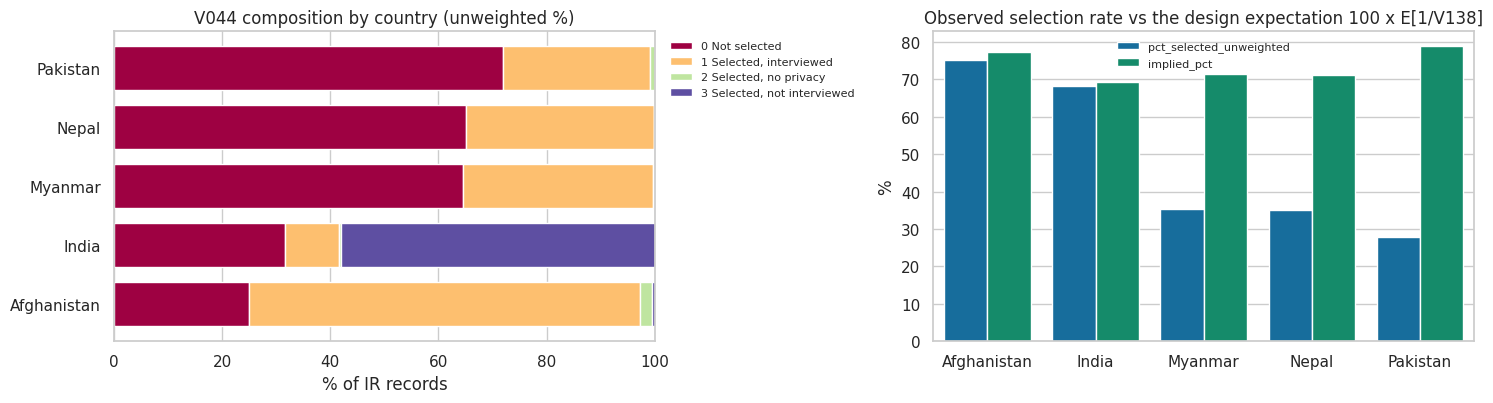

### P(selected for the DV module | number of eligible women in the household)

country,Afghanistan,India,Myanmar,Nepal,Pakistan
n_eligible_women,,,,,
1,99.099998,97.400002,49.099998,48.400002,35.200001
2,49.900002,49.500000,24.400000,24.900000,18.500000
3,33.799999,33.099998,17.100000,17.000000,12.300000
4,25.299999,24.900000,12.800000,13.600000,10.800000
5,20.299999,19.799999,9.300000,10.700000,9.900000
6,16.100000,16.400000,11.600000,NaN,2.000000
7,13.600000,13.800000,10.700000,NaN,NaN
8,NaN,12.900000,NaN,NaN,NaN
9,NaN,11.600000,NaN,NaN,NaN


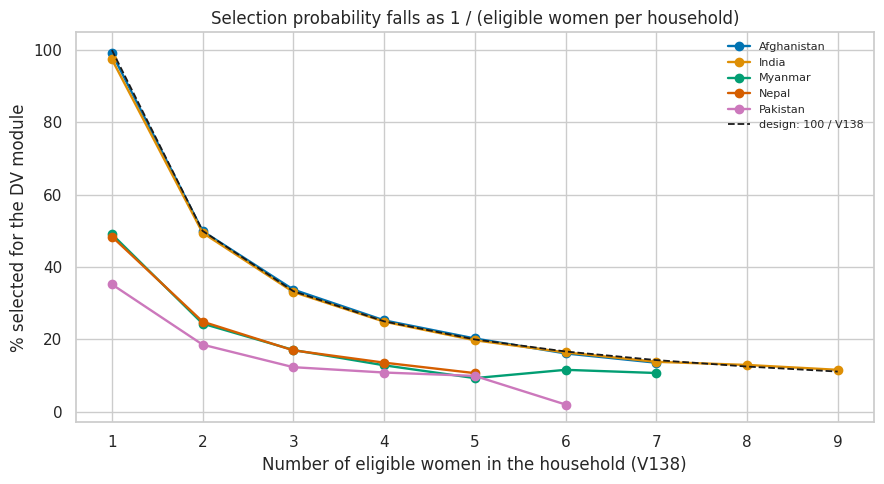

The observed curves track `100 / V138` scaled by the country's household sub-sampling fraction. **This is why the modelling in §17–§22 is framed as a design audit**: any predictive signal that survives after `V138` and country are already in the model is a genuine profile effect, not the one-woman-per-household rule.

### Selection rate by profile characteristic (with the mean of V138 alongside, because V138 drives the design)

country                                       Afghanistan      India  \
block                   category                                       
Age group               15-19                   61.180000  20.889999   
                        20-24                   67.220001  63.360001   
                        25-29                   75.180000  80.120003   
                        30-34                   80.959999  89.010002   
                        35-39                   84.430000  87.779999   
                        40-44                   79.250000  77.959999   
                        45-49                   73.129997  71.059998   
Education level         Higher                  79.440002  67.599998   
                        No education            74.720001  78.779999   
                        Primary                 77.400002  77.430000   
                        Secondary               77.040001  61.730000   
Eligible women (capped) 1                       99.059998  97.440002   
                        2                       49.930000  49.480000   
                        3                       33.770000  33.110001   
                        4                       25.270000  24.910000   
                        5+                      17.879999  18.590000   
Marital status          Divorced                50.000000  71.870003   
                        Living together               NaN        NaN   
                        Married                 75.400002  80.849998   
                        Never married                 NaN  31.940001   
                        Separated               70.000000  73.669998   
                        Widowed                 66.110001  74.989998   
Residence               Rural                   73.720001  68.360001   
                        Urban                   79.620003  68.269997   
Sex of household head   Female head             85.000000  67.809998   
                        Male head               75.000000  68.440002   
Wealth quintile         Middle                  74.199997  67.739998   
                        Poorer                  73.489998  68.709999   
                        Poorest                 76.379997  72.360001   
                        Richer                  74.730003  66.449997   
                        Richest                 77.879997  65.809998   
Wife-beating attitude   Justifies >=1 reason    75.199997  70.309998   
                        Justifies none          75.199997  67.970001   

country                                         Myanmar      Nepal   Pakistan  
block                   category                                               
Age group               15-19                 25.670000  25.820000  20.879999  
                        20-24                 32.750000  32.180000  25.540001  
                        25-29                 37.450001  39.689999  26.570000  
                        30-34                 40.130001  42.619999  29.440001  
                        35-39                 40.720001  37.360001  29.910000  
                        40-44                 36.770000  35.330002  28.780001  
                        45-49                 33.740002  35.330002  30.600000  
Education level         Higher                31.950001  29.629999  28.740000  
                        No education          37.369999  36.480000  28.389999  
                        Primary               37.959999  36.330002  27.480000  
                        Secondary             33.009998  33.209999  26.790001  
Eligible women (capped) 1                     49.090000  48.419998  35.220001  
                        2                     24.360001  24.910000  18.549999  
                        3                     17.070000  16.969999  12.320000  
                        4                     12.850000  13.580000  10.850000  
                        5+                     9.830000  10.340000   7.430000  
Marital status          Divorced       

/tmp/ipykernel_116/2961144224.py:146: UserWarning: The palette list has more values (10) than needed (5), which may not be intended.
  sns.barplot(data=sub, x="category", y="pct_selected", hue="country", ax=ax, palette=PALETTE)
/tmp/ipykernel_116/2961144224.py:146: UserWarning: The palette list has more values (10) than needed (5), which may not be intended.
  sns.barplot(data=sub, x="category", y="pct_selected", hue="country", ax=ax, palette=PALETTE)
/tmp/ipykernel_116/2961144224.py:146: UserWarning: The palette list has more values (10) than needed (5), which may not be intended.
  sns.barplot(data=sub, x="category", y="pct_selected", hue="country", ax=ax, palette=PALETTE)
/tmp/ipykernel_116/2961144224.py:146: UserWarning: The palette list has more values (10) than needed (5), which may not be intended.
  sns.barplot(data=sub, x="category", y="pct_selected", hue="country", ax=ax, palette=PALETTE)
/tmp/ipykernel_116/2961144224.py:146: UserWarning: The palette list has more values (10)

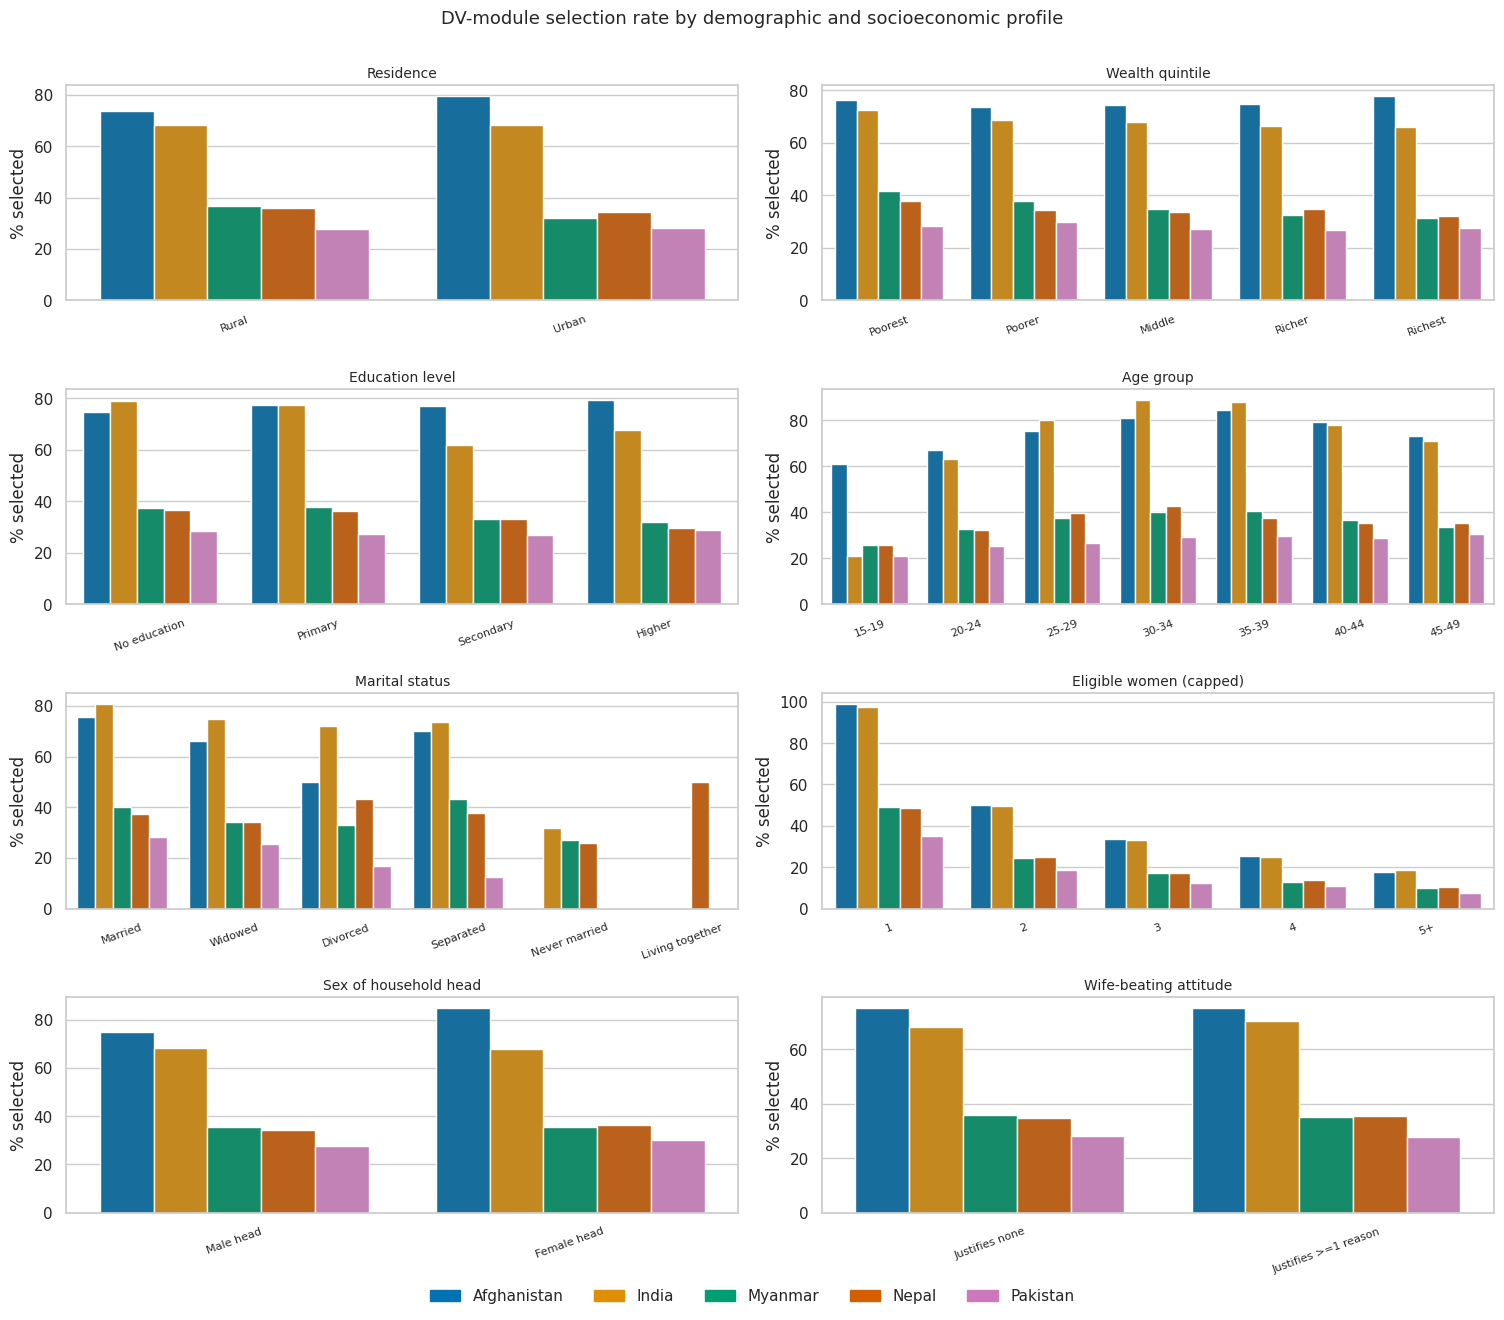

38953

In [39]:
# ================================================================================================
# RECODE SOURCE
#   * Individual Recode (IR) - XXIRnnFL - one record per interviewed woman 15-49
# WHAT THIS CELL USES: V044 (selected for the Domestic Violence module), V138 (number of eligible
#   women in the household) and the derived profile blocks.
# ================================================================================================
# 16h. DV-module selection (V044) EDA and the design relationship with V138

sel = ir_women[ir_women.country.isin(MODEL_COUNTRIES) & ir_women.y_selected.notna()].copy()
print(f"Selection-analysis universe: {len(sel):,} women in {sel.country.nunique()} countries "
      f"({', '.join(sorted(sel.country.unique()))})")

# --- 1. V044 distribution -------------------------------------------------------------------------
v044_rows = []
for country, g in sel.groupby("country", sort=True):
    total_u, total_w = len(g), g["w_ind"].sum()
    for code, label in {0: "0 Not selected", 1: "1 Selected, interviewed",
                        2: "2 Selected, no privacy", 3: "3 Selected, not interviewed"}.items():
        mask = g["V044"].eq(code)
        v044_rows.append({
            "country": country, "code": code, "V044": label,
            "unweighted_n": int(mask.sum()),
            "unweighted_pct": 100 * mask.sum() / total_u if total_u else np.nan,
            "weighted_pct": 100 * g.loc[mask, "w_ind"].sum() / total_w if total_w else np.nan,
        })
v044_distribution = pd.DataFrame(v044_rows)
display(Markdown("### V044 — Selected for the Domestic Violence module"))
display(v044_distribution.pivot_table(index="V044", columns="country", values="unweighted_pct",
                                     aggfunc="first").round(2))
v044_distribution.to_csv(OUTPUT_DIR / "ir_v044_distribution.csv", index=False)

selection_rates = summarise_groups(sel, "country", lambda g: {
    "unweighted_women": len(g),
    "n_selected": int(g.y_selected.sum()),
    "pct_selected_unweighted": 100 * g.y_selected.mean(),
    "pct_selected_weighted": weighted_share(g.y_selected, g.w_ind, 1),
    "pct_completed_of_selected": (100 * g.loc[g.y_selected.eq(1), "y_completed"].mean()
                                  if g.y_selected.eq(1).any() else np.nan),
    "mean_eligible_women": weighted_mean(g.n_eligible_women, g.w_ind),
    "implied_1_over_V138": weighted_mean(g.inv_eligible_women, g.w_ind),
})
display(Markdown("### Selection rate versus the design expectation E[1 / V138]"))
display(selection_rates.style.format({
    "unweighted_women": "{:,.0f}", "n_selected": "{:,.0f}",
    "pct_selected_unweighted": "{:.2f}", "pct_selected_weighted": "{:.2f}",
    "pct_completed_of_selected": "{:.2f}", "mean_eligible_women": "{:.2f}",
    "implied_1_over_V138": "{:.3f}",
}, na_rep="n/a"))
selection_rates.to_csv(OUTPUT_DIR / "ir_selection_rates.csv")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
wide = v044_distribution.pivot_table(index="country", columns="V044", values="unweighted_pct",
                                    aggfunc="first")
wide.plot(kind="barh", stacked=True, ax=axes[0], colormap="Spectral", width=0.75)
axes[0].set_title("V044 composition by country (unweighted %)")
axes[0].set_xlabel("% of IR records"); axes[0].set_ylabel(""); axes[0].set_xlim(0, 100)
axes[0].legend(bbox_to_anchor=(1.01, 1.0), loc="upper left", fontsize=8, frameon=False)

comp = selection_rates.reset_index()[["country", "pct_selected_unweighted", "implied_1_over_V138"]]
comp["implied_pct"] = 100 * comp.implied_1_over_V138
comp.melt(id_vars="country", value_vars=["pct_selected_unweighted", "implied_pct"],
          var_name="quantity", value_name="pct").pipe(
    lambda df: sns.barplot(data=df, x="country", y="pct", hue="quantity", ax=axes[1],
                           palette=[PALETTE[0], PALETTE[2]]))
axes[1].set_title("Observed selection rate vs the design expectation 100 x E[1/V138]")
axes[1].set_ylabel("%"); axes[1].set_xlabel("")
axes[1].legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

# --- 2. P(selected | V138): the mechanical core of the design -------------------------------------
v138_rows = []
for country, g in sel.groupby("country", sort=True):
    for k, gk in g[g.n_eligible_women.notna()].groupby("n_eligible_women"):
        if len(gk) < MIN_UNWEIGHTED_CELL:
            continue
        v138_rows.append({
            "country": country, "n_eligible_women": int(k), "n_women": len(gk),
            "pct_selected": 100 * gk.y_selected.mean(),
            "design_expectation_pct": 100 / k if k else np.nan,
        })
ir_v138_curve = pd.DataFrame(v138_rows)
display(Markdown("### P(selected for the DV module | number of eligible women in the household)"))
display(ir_v138_curve.pivot_table(index="n_eligible_women", columns="country",
                                 values="pct_selected", aggfunc="first").round(1))
ir_v138_curve.to_csv(OUTPUT_DIR / "ir_selection_by_eligible_women.csv", index=False)

plt.figure(figsize=(9, 5))
for i, (country, g) in enumerate(ir_v138_curve.groupby("country", sort=True)):
    plt.plot(g.n_eligible_women, g.pct_selected, marker="o", label=country,
             color=PALETTE[i % len(PALETTE)], linewidth=1.7)
grid = np.arange(1, int(ir_v138_curve.n_eligible_women.max()) + 1)
plt.plot(grid, 100 / grid, "k--", linewidth=1.3, label="design: 100 / V138")
plt.title("Selection probability falls as 1 / (eligible women per household)")
plt.xlabel("Number of eligible women in the household (V138)")
plt.ylabel("% selected for the DV module")
plt.xticks(grid); plt.legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()
display(Markdown(
    "The observed curves track `100 / V138` scaled by the country's household sub-sampling fraction. "
    "**This is why the modelling in §17–§22 is framed as a design audit**: any predictive signal that "
    "survives after `V138` and country are already in the model is a genuine profile effect, not the "
    "one-woman-per-household rule."))

# --- 3. bivariate selection rates across the profile blocks ---------------------------------------
SELECTION_BLOCKS = [
    ("urban", {0: "Rural", 1: "Urban"}, "Residence"),
    ("wealth_quintile", WEALTH, "Wealth quintile"),
    ("edu_level", EDUCATION, "Education level"),
    ("age_group", IR_AGE_GROUP, "Age group"),
    ("marital_status", IR_MARITAL, "Marital status"),
    ("eligible_women_capped", {1: "1", 2: "2", 3: "3", 4: "4", 5: "5+"}, "Eligible women (capped)"),
    ("female_head", {0: "Male head", 1: "Female head"}, "Sex of household head"),
    ("justifies_beating_any", {0: "Justifies none", 1: "Justifies >=1 reason"}, "Wife-beating attitude"),
]
block_rows = []
for variable, labels, title in SELECTION_BLOCKS:
    if variable not in sel.columns:
        continue
    for country, g in sel.groupby("country", sort=True):
        for code, label in labels.items():
            mask = g[variable].eq(code)
            if mask.sum() < MIN_UNWEIGHTED_CELL:
                continue
            lo, hi = wilson_ci(int(g.loc[mask, "y_selected"].sum()), int(mask.sum()))
            block_rows.append({
                "block": title, "variable": variable, "category": label,
                "country": country, "n_women": int(mask.sum()),
                "pct_selected": 100 * g.loc[mask, "y_selected"].mean(),
                "ci_low": 100 * lo, "ci_high": 100 * hi,
                "mean_eligible_women": float(g.loc[mask, "n_eligible_women"].mean()),
            })
ir_selection_by_block = pd.DataFrame(block_rows)
display(Markdown("### Selection rate by profile characteristic (with the mean of V138 alongside, "
                 "because V138 drives the design)"))
display(ir_selection_by_block.pivot_table(index=["block", "category"], columns="country",
                                         values="pct_selected", aggfunc="first").round(2))
ir_selection_by_block.to_csv(OUTPUT_DIR / "ir_selection_by_profile_block.csv", index=False)

blocks = list(ir_selection_by_block.block.unique())
ncols = 2
nrows = int(np.ceil(len(blocks) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(7.6 * ncols, 3.2 * nrows))
axes = np.atleast_1d(axes).ravel()
for ax, block in zip(axes, blocks):
    sub = ir_selection_by_block[ir_selection_by_block.block.eq(block)]
    sns.barplot(data=sub, x="category", y="pct_selected", hue="country", ax=ax, palette=PALETTE)
    ax.set_title(block, fontsize=10); ax.set_xlabel(""); ax.set_ylabel("% selected")
    ax.tick_params(axis="x", labelrotation=20, labelsize=8)
    ax.legend_.remove() if ax.get_legend() else None
for ax in axes[len(blocks):]:
    ax.axis("off")
handles = [plt.Rectangle((0, 0), 1, 1, color=PALETTE[i % len(PALETTE)])
           for i in range(sel.country.nunique())]
fig.legend(handles, sorted(sel.country.unique()), loc="lower center", frameon=False,
           ncol=min(6, sel.country.nunique()), bbox_to_anchor=(0.5, -0.02))
fig.suptitle("DV-module selection rate by demographic and socioeconomic profile", y=1.002, fontsize=13)
plt.tight_layout(); plt.show()
gc.collect()

### 16i. Curated DV-item registry — reconciliation with the label-discovered registry of §12

Section 12 built `dv_item_registry` by **searching the SAS labels** for violence keywords. That is the right way to *discover* items in an unfamiliar layout, but keyword matching has two known failure modes on the DHS DV module:

| Failure mode | Example |
|---|---|
| **Misses** — the label uses wording the pattern does not cover | `D103B` ("threatened with harm"), `D105J` ("arm twisted / hair pulled") |
| **Over-includes** — the label matches but the item is not a first-person current-partner experience | `D108` (a DHS-constructed composite of `D105H/I/K`), `D124`–`D127x` (violence by someone **other than** a partner), `D130A/B` (a **previous** husband), `D112` (violence **she** committed) |

The cell below keeps §12 untouched and instead **adds** an explicit, hand-curated registry (`DV_PLAN`, 40 items) and prints a side-by-side reconciliation. Both registries are exported, so the paper can cite exactly which items were used.

### Two coding rules that must not be simplified

DHS frequency items (`D101x`, `D103x`, `D105x`, `D130x`) are coded:

| Code | Meaning |
|---|---|
| 0 | Never |
| 1 | Often (in the last 12 months) |
| 2 | Sometimes (in the last 12 months) |
| 3 | Yes, but not in the last 12 months |
| **4** | **Yes, but frequency in the last 12 months is missing** |

- **Ever experienced** = `{1, 2, 3, 4}`
- **Experienced in the last 12 months** = `{1, 2, 4}`

Code `4` is a *yes*. Dropping it — the natural thing to do if the analyst only enumerates `0–3` — biases every "ever" estimate downwards. The prevalence table below therefore reports **both** definitions, and reports the number of code-4 records so the size of that correction is visible.

### Weight

Violence estimates use `D005 / 1 000 000`, restricted to `D005 > 0`. The individual weight `V005` is **wrong** for these items, because the DV module is a sub-sample.

In [40]:
# ================================================================================================
# RECODE SOURCE
#   * Individual Recode (IR) - XXIRnnFL - one record per interviewed woman 15-49
# WHAT THIS CELL USES: the curated DV_PLAN of 15b versus the label-discovered dv_item_registry of
#   section 12. Nothing in section 12 is modified - this cell only compares the two.
# ================================================================================================
# 16i-1. Reconciliation of the curated and auto-discovered DV item registries

curated = set(DV_PLAN.variable)
try:
    discovered = set(dv_item_registry.variable.str.upper())
    have_registry = True
except (NameError, AttributeError):
    discovered, have_registry = set(), False
    print("dv_item_registry from section 12 is unavailable in this run; showing the curated list only.")

reconcile_rows = []
for var in sorted(curated | discovered):
    plan_hit = DV_PLAN[DV_PLAN.variable.eq(var)]
    fielded_in = [m.country for _, m in ir_archives.iterrows()
                  if variable_status(m.stem, var) == "Available"]
    reconcile_rows.append({
        "variable": var,
        "in_curated_plan": var in curated,
        "in_label_registry": var in discovered,
        "domain": plan_hit.domain.iloc[0] if len(plan_hit) else "",
        "coding": plan_hit.coding.iloc[0] if len(plan_hit) else "",
        "description": (plan_hit.description.iloc[0] if len(plan_hit)
                        else label_of(ir_archives.stem.iloc[0], var)),
        "n_countries_fielded": len(fielded_in),
        "countries_fielded": ", ".join(fielded_in),
    })
dv_registry_reconciliation = pd.DataFrame(reconcile_rows)
dv_registry_reconciliation["status"] = np.select(
    [dv_registry_reconciliation.in_curated_plan & dv_registry_reconciliation.in_label_registry,
     dv_registry_reconciliation.in_curated_plan & ~dv_registry_reconciliation.in_label_registry,
     ~dv_registry_reconciliation.in_curated_plan & dv_registry_reconciliation.in_label_registry],
    ["both", "curated only (label search missed it)", "label search only (excluded by design)"],
    default="neither")

display(Markdown("### Curated vs label-discovered DV items"))
display(dv_registry_reconciliation[[
    "variable", "status", "domain", "coding", "n_countries_fielded", "description"]])
display(Markdown("### Reconciliation counts"))
display(dv_registry_reconciliation.status.value_counts().rename("n_items").to_frame())
if have_registry:
    print("Curated-only items (add these to any label-driven list):",
          ", ".join(dv_registry_reconciliation.loc[
              dv_registry_reconciliation.status.str.startswith("curated only"), "variable"]) or "none")
    print("Label-only items (kept out of the prevalence tables on purpose):",
          ", ".join(dv_registry_reconciliation.loc[
              dv_registry_reconciliation.status.str.startswith("label search only"), "variable"]) or "none")
dv_registry_reconciliation.to_csv(OUTPUT_DIR / "dv_registry_reconciliation.csv", index=False)

dv_item_registry from section 12 is unavailable in this run; showing the curated list only.


### Curated vs label-discovered DV items

,variable,status,domain,coding,n_countries_fielded,description
0,D101A,curated only (label search missed it),control,freq,5,Partner jealous if she talks with other men
1,D101B,curated only (label search missed it),control,freq,5,Partner accuses her of unfaithfulness
2,D101C,curated only (label search missed it),control,freq,5,Partner does not permit her to meet female fri...
3,D101D,curated only (label search missed it),control,freq,5,Partner limits her contact with family
4,D101E,curated only (label search missed it),control,freq,5,Partner insists on knowing where she is
5,D101F,curated only (label search missed it),control,freq,1,Partner does not trust her with money
6,D103A,curated only (label search missed it),emotional,freq,5,Ever humiliated by partner
7,D103B,curated only (label search missed it),emotional,freq,5,Ever threatened with harm by partner
8,D103C,curated only (label search missed it),emotional,freq,5,Ever insulted or made to feel bad by partner
9,D104,curated only (label search missed it),composite_dhs,bin,5,DHS composite: any emotional violence


### Reconciliation counts

,n_items
status,
curated only (label search missed it),40


DV sub-sample universe: 106,655 women with D005 > 0 in 5 countries


### Weighted 'ever experienced' prevalence of each curated DV item (weight = D005 / 1 000 000)

country                                                                        Afghanistan  \
domain            variable description                                                       
composite_dhs     D104     DHS composite: any emotional violence                 37.400002   
                  D106     DHS composite: any less severe physical violence      50.299999   
                  D107     DHS composite: any severe physical violence           17.799999   
                  D108     DHS composite: any sexual violence                     7.400000   
                  D111     DHS composite: any injury                             13.200000   
control           D101A    Partner jealous if she talks with other men           63.299999   
                  D101B    Partner accuses her of unfaithfulness                 26.900000   
                  D101C    Partner does not permit her to meet female friends    21.000000   
                  D101D    Partner limits her contact with family                11.900000   
                  D101E    Partner insists on knowing where she is               37.900002   
                  D101F    Partner does not trust her with money                       NaN   
emotional         D103A    Ever humiliated by partner                            33.599998   
                  D103B    Ever threatened with harm by partner                  15.000000   
                  D103C    Ever insulted or made to feel bad by partner          25.500000   
family_history    D121     Her father ever beat her mother                       48.900002   
fear              D129     Afraid of partner (never/sometimes/most of the ...    88.699997   
help_seeking      D119Y    Did not seek help from anyone                         79.199997   
                  D128     Ever told anyone about the violence                   19.799999   
her_violence      D112     Respondent ever physically hurt partner unprovoked     1.000000   
injury            D110A    Ever had bruises from partner's actions               23.000000   
                  D110B    Ever had eye injuries/sprains/dislocations/burns      12.900000   
                  D110D    Ever had wounds/broken bones/broken teeth/serio...     7.500000   
interview_privacy D122A    Interview interrupted: husband present                 7.200000   
                  D122B    Interview interrupted: other adult male present        6.100000   
                  D122C    Interview interrupted: adult female present           14.200000   
non_partner       D115Y    Nobody other than partner ever physically hurt her    89.500000   
partner_alcohol   D113     Partner drinks alcohol                                 0.700000   
                  D114     Frequency of partner being drunk                      90.699997   
physical_less     D105A    Ever pushed/shaken/had something thrown               41.099998   
                  D105B    Ever slapped                                          45.900002   
                  D105C    Ever punched with fist or hit with something ha...    22.299999   
                  D105J    Ever had arm twisted or hair pulled                   28.500000   
physical_severe   D105D    Ever kicked or dragged                                17.299999   
                  D105E    Ever strangled or burnt                                3.200000   
                  D105F    Ever threatened with knife/gun/other weapon            2.900000   
previous_partner  D130A    Previous husband ever hit/slapped/kicked/hurt her     27.900000   
                  D130B    Previous husband forced sex or sexual acts            12.900000   
sexual            D105H    Ever physically forced into unwanted sex               5.500000   
                  D105I    Ever forced into other unwanted sexual acts            3.900000   
                  D105K    Ever physically forced to perform unwanted sexu...     4.700000   

country                                            

### Records coded 4 ('yes, frequency in last 12 months missing') — these are **yes** answers that a 0-3 enumeration would silently drop

,items,total_code4_records
country,,
Afghanistan,20,257
India,21,0
Myanmar,20,0
Nepal,20,0
Pakistan,20,6


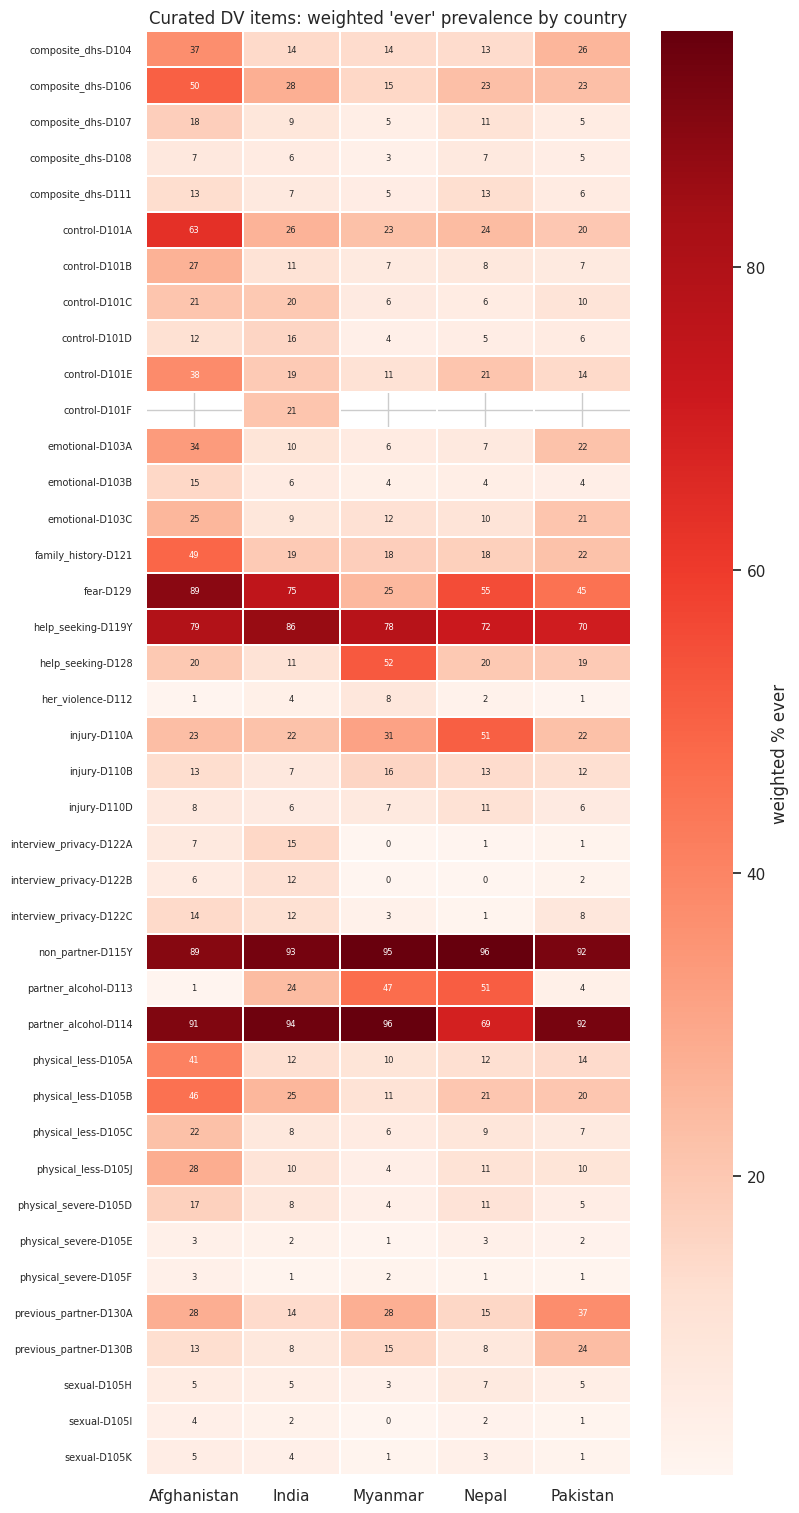

### DV domain summary (mean across the items of each domain)

country,Afghanistan,India,Myanmar,Nepal,Pakistan
domain,,,,,
composite_dhs,25.200001,12.800000,8.300000,13.400000,13.000000
control,32.200001,18.799999,10.100000,12.700000,11.400000
emotional,24.700001,8.000000,7.100000,7.300000,15.700000
family_history,48.900002,19.400000,18.000000,17.600000,21.900000
fear,88.699997,75.300003,25.100000,55.500000,45.400002
help_seeking,49.500000,48.500000,64.900002,45.900002,44.900002
her_violence,1.000000,3.600000,8.400000,2.200000,0.900000
injury,14.500000,11.800000,18.100000,25.100000,13.700000
interview_privacy,9.100000,12.900000,1.100000,0.700000,3.800000


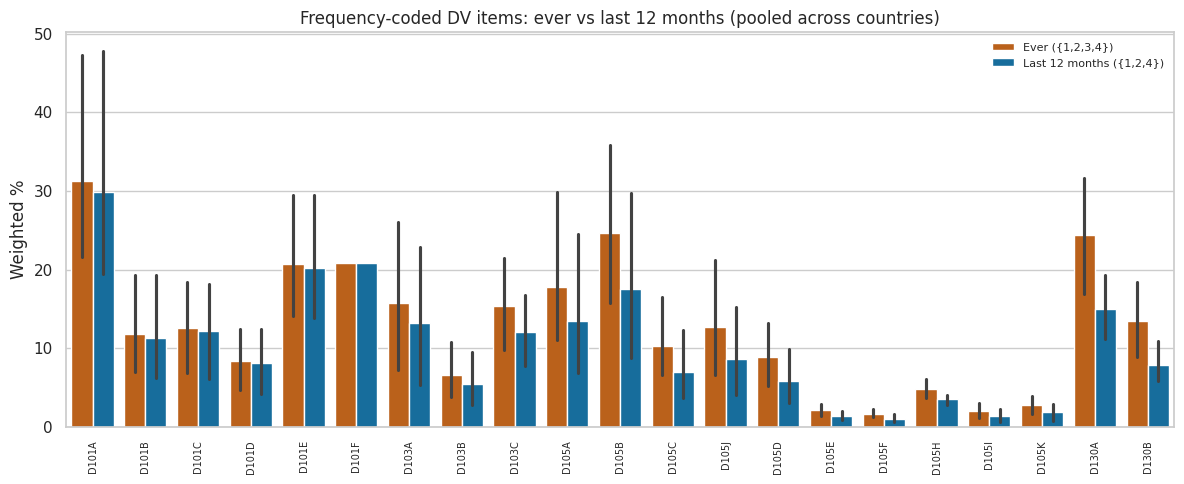

/tmp/ipykernel_116/4057185293.py:131: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ir_women[flag] = pd.concat(parts, axis=1).max(axis=1).astype("float32")
/tmp/ipykernel_116/4057185293.py:131: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ir_women[flag] = pd.concat(parts, axis=1).max(axis=1).astype("float32")
/tmp/ipykernel_116/4057185293.py:131: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once 

### Composite 'ever experienced' prevalence built from the curated items

country,Afghanistan,India,Myanmar,Nepal,Pakistan
flag,,,,,
any_control,70.900002,46.099998,29.100000,35.099998,28.100000
any_emotional,37.400002,14.000000,13.500000,13.400000,25.799999
any_injury,26.100000,24.600000,36.599998,52.599998,25.500000
any_ipv,55.500000,31.799999,20.900000,27.299999,33.500000
any_physical_less,50.299999,27.799999,14.900000,22.900000,22.799999
any_physical_severe,17.799999,8.700000,4.500000,10.800000,5.500000
any_sexual,7.400000,6.100000,3.000000,7.300000,4.800000


/tmp/ipykernel_116/4057185293.py:154: UserWarning: The palette list has more values (10) than needed (5), which may not be intended.
  sns.barplot(data=dv_composite_prevalence, x="flag", y="pct_ever", hue="country", palette=PALETTE)


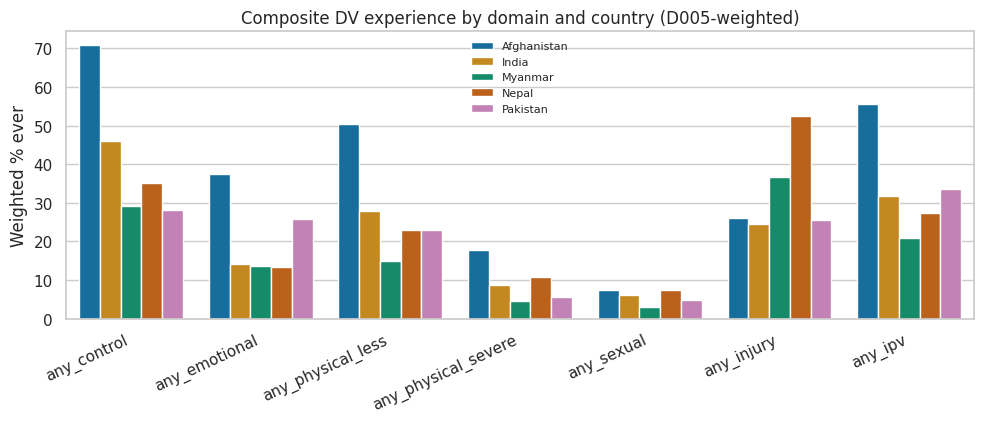

28413

In [41]:
# ================================================================================================
# RECODE SOURCE
#   * Individual Recode (IR) - XXIRnnFL - one record per interviewed woman 15-49
#     (domestic-violence sub-sample: rows with D005 > 0)
# WHAT THIS CELL USES: the curated D1xx items with the DV sub-sample weight D005 / 1 000 000.
# NOTE: DHS frequency codes -> ever = {1,2,3,4}; last 12 months = {1,2,4}. Code 4 is a YES.
# ================================================================================================
# 16i-2. Weighted prevalence of the curated DV items

EVER_CODES = {1, 2, 3, 4}
LAST12_CODES = {1, 2, 4}

dv_pool = ir_women[ir_women.country.isin(DV_PREVALENCE_COUNTRIES)].copy()
if "w_dv" in dv_pool.columns:
    dv_pool = dv_pool[dv_pool.w_dv.gt(0)]
print(f"DV sub-sample universe: {len(dv_pool):,} women with D005 > 0 in "
      f"{dv_pool.country.nunique()} countries")

prevalence_rows = []
for _, item in DV_PLAN.iterrows():
    var, coding = item.variable, item.coding
    for country, g in dv_pool.groupby("country", sort=True):
        if variable_status(g.stem.iloc[0], var) != "Available" or var not in g.columns:
            continue
        answered = g[g[var].notna()]
        if len(answered) < MIN_UNWEIGHTED_CELL:
            continue
        w = answered["w_dv"]
        total_w = w.sum()
        if coding == "freq":
            ever = answered[var].isin(EVER_CODES)
            last12 = answered[var].isin(LAST12_CODES)
            n_code4 = int(answered[var].eq(4).sum())
        elif coding == "bin":
            ever = answered[var].eq(1)
            last12 = pd.Series(False, index=answered.index)
            n_code4 = 0
        else:                                   # ordinal severity/frequency scale
            ever = answered[var].ge(1)
            last12 = pd.Series(False, index=answered.index)
            n_code4 = 0
        lo, hi = wilson_ci(int(ever.sum()), len(answered))
        prevalence_rows.append({
            "domain": item.domain, "variable": var, "description": item.description,
            "coding": coding, "country": country,
            "n_answered": len(answered),
            "pct_ever_weighted": 100 * w[ever].sum() / total_w if total_w else np.nan,
            "pct_ever_unweighted": 100 * ever.mean(),
            "ci_low": 100 * lo, "ci_high": 100 * hi,
            "pct_last12_weighted": (100 * w[last12].sum() / total_w
                                    if coding == "freq" and total_w else np.nan),
            "n_code4_freq_missing": n_code4,
            "effective_n": effective_n(w),
        })
dv_prevalence = pd.DataFrame(prevalence_rows)

if dv_prevalence.empty:
    print("No curated DV item is available in any archive; prevalence tables skipped.")
else:
    display(Markdown("### Weighted 'ever experienced' prevalence of each curated DV item "
                     "(weight = D005 / 1 000 000)"))
    display(dv_prevalence.pivot_table(index=["domain", "variable", "description"], columns="country",
                                     values="pct_ever_weighted", aggfunc="first").round(1))
    dv_prevalence.to_csv(OUTPUT_DIR / "dv_item_prevalence_curated.csv", index=False)

    code4 = dv_prevalence[dv_prevalence.coding.eq("freq")].groupby("country").agg(
        items=("variable", "nunique"),
        total_code4_records=("n_code4_freq_missing", "sum"))
    display(Markdown("### Records coded 4 ('yes, frequency in last 12 months missing') — these are "
                     "**yes** answers that a 0-3 enumeration would silently drop"))
    display(code4.style.format({"items": "{:,.0f}", "total_code4_records": "{:,.0f}"}))
    code4.to_csv(OUTPUT_DIR / "dv_code4_audit.csv")

    heat = dv_prevalence.pivot_table(index=["domain", "variable"], columns="country",
                                     values="pct_ever_weighted", aggfunc="first")
    plt.figure(figsize=(1.6 * max(4, heat.shape[1]), 0.32 * len(heat) + 2.5))
    sns.heatmap(heat, annot=True, fmt=".0f", annot_kws={"fontsize": 6}, cmap="Reds",
                linewidths=0.3, linecolor="white", cbar_kws={"label": "weighted % ever"})
    plt.title("Curated DV items: weighted 'ever' prevalence by country")
    plt.xlabel(""); plt.ylabel(""); plt.yticks(fontsize=7)
    plt.tight_layout(); plt.show()

    # --- domain-level summaries, ever vs last 12 months -------------------------------------------
    domain_rows = []
    for (domain, country), g in dv_prevalence.groupby(["domain", "country"]):
        domain_rows.append({
            "domain": domain, "country": country, "n_items": g.variable.nunique(),
            "mean_pct_ever": g.pct_ever_weighted.mean(),
            "max_pct_ever": g.pct_ever_weighted.max(),
            "mean_pct_last12": g.pct_last12_weighted.mean(),
        })
    dv_domain_summary = pd.DataFrame(domain_rows)
    display(Markdown("### DV domain summary (mean across the items of each domain)"))
    display(dv_domain_summary.pivot_table(index="domain", columns="country",
                                         values="mean_pct_ever", aggfunc="first").round(1))
    dv_domain_summary.to_csv(OUTPUT_DIR / "dv_domain_summary.csv", index=False)

    freq_items = dv_prevalence[dv_prevalence.coding.eq("freq") & dv_prevalence.pct_last12_weighted.notna()]
    if len(freq_items):
        plt.figure(figsize=(12, 5))
        plot_df = freq_items.melt(id_vars=["variable", "country"],
                                  value_vars=["pct_ever_weighted", "pct_last12_weighted"],
                                  var_name="window", value_name="pct")
        plot_df["window"] = plot_df.window.map({"pct_ever_weighted": "Ever ({1,2,3,4})",
                                                "pct_last12_weighted": "Last 12 months ({1,2,4})"})
        sns.barplot(data=plot_df, x="variable", y="pct", hue="window",
                    palette=[PALETTE[3], PALETTE[0]], errorbar=("ci", 95))
        plt.title("Frequency-coded DV items: ever vs last 12 months (pooled across countries)")
        plt.ylabel("Weighted %"); plt.xlabel("")
        plt.xticks(rotation=90, fontsize=7); plt.legend(fontsize=8, frameon=False)
        plt.tight_layout(); plt.show()

    # --- composite experience flags, added to ir_women --------------------------------------------
    DOMAIN_FLAGS = {
        "any_control": DV_PLAN.loc[DV_PLAN.domain.eq("control"), "variable"].tolist(),
        "any_emotional": DV_PLAN.loc[DV_PLAN.domain.eq("emotional"), "variable"].tolist(),
        "any_physical_less": DV_PLAN.loc[DV_PLAN.domain.eq("physical_less"), "variable"].tolist(),
        "any_physical_severe": DV_PLAN.loc[DV_PLAN.domain.eq("physical_severe"), "variable"].tolist(),
        "any_sexual": DV_PLAN.loc[DV_PLAN.domain.eq("sexual"), "variable"].tolist(),
        "any_injury": DV_PLAN.loc[DV_PLAN.domain.eq("injury"), "variable"].tolist(),
    }
    for flag, members in DOMAIN_FLAGS.items():
        present = [m for m in members if m in ir_women.columns]
        if not present:
            continue
        coding_by_var = dict(zip(DV_PLAN.variable, DV_PLAN.coding))
        parts = []
        for m in present:
            valid = EVER_CODES if coding_by_var[m] == "freq" else {1}
            parts.append(ir_women[m].isin(valid).where(ir_women[m].notna()))
        ir_women[flag] = pd.concat(parts, axis=1).max(axis=1).astype("float32")
    DV_EXPERIENCE_FLAGS = [f for f in DOMAIN_FLAGS if f in ir_women.columns]
    ir_women["any_ipv"] = (ir_women[[f for f in ["any_emotional", "any_physical_less",
                                                 "any_physical_severe", "any_sexual"]
                                     if f in ir_women.columns]]
                           .max(axis=1).astype("float32")) if DV_EXPERIENCE_FLAGS else np.nan

    flag_rows = []
    for country, g in ir_women[ir_women.country.isin(DV_PREVALENCE_COUNTRIES)].groupby("country"):
        g = g[g.w_dv.gt(0)] if "w_dv" in g.columns else g
        for flag in DV_EXPERIENCE_FLAGS + (["any_ipv"] if "any_ipv" in g.columns else []):
            keep = g[flag].notna()
            if keep.sum() < MIN_UNWEIGHTED_CELL:
                continue
            flag_rows.append({"country": country, "flag": flag, "n_answered": int(keep.sum()),
                              "pct_ever": weighted_share(g[flag], g["w_dv"], 1)})
    dv_composite_prevalence = pd.DataFrame(flag_rows)
    display(Markdown("### Composite 'ever experienced' prevalence built from the curated items"))
    display(dv_composite_prevalence.pivot_table(index="flag", columns="country", values="pct_ever",
                                               aggfunc="first").round(1))
    dv_composite_prevalence.to_csv(OUTPUT_DIR / "dv_composite_prevalence.csv", index=False)

    plt.figure(figsize=(10, 4.4))
    sns.barplot(data=dv_composite_prevalence, x="flag", y="pct_ever", hue="country", palette=PALETTE)
    plt.title("Composite DV experience by domain and country (D005-weighted)")
    plt.ylabel("Weighted % ever"); plt.xlabel("")
    plt.xticks(rotation=25, ha="right"); plt.legend(fontsize=8, frameon=False)
    plt.tight_layout(); plt.show()
gc.collect()

## 17. Building the modelling dataset (CSV) — one row per woman

**Recode used: Individual Recode (IR).** The household context columns (`V119`–`V161`, `V136`–`V152`, `V190`/`V191`) are the household characteristics **carried into the IR file by DHS**, so a single IR pass gives both the woman-level and the household-level half of the profile without a merge.

### Universe

| Rule | Reason |
|---|---|
| `country ∈ MODEL_COUNTRIES` | `V044` must be real, not `NA` — see the §15 audit |
| `y_selected` not missing | the target must exist |
| `V015 = 1` (completed interview) where available | non-completed records have no profile to model |

### Feature blocks

The design deliberately separates the blocks, because §20 fits **nested models** on them:

| Block | Purpose in the argument | Examples |
|---|---|---|
| `design` | the sampling mechanism | `n_eligible_women`, `inv_eligible_women`, `single_eligible_woman`, `hh_size` |
| `country` | cross-country variation | `country`, `survey_year` |
| `woman` | demographic profile | age, education, marital, fertility |
| `household` | socioeconomic profile | wealth, assets, dwelling quality, headship |
| `agency` | autonomy and connectivity | decision index, ownership, mobile, internet, media |
| `norms` | attitudes | wife-beating attitude items and index |
| `interaction` | explicit two-way products | wealth × education, urban × education, age × union, … |

### Two targets

| Target | Definition | Question it answers |
|---|---|---|
| `y_selected` | `V044 ∈ {1, 2, 3}` | which households/women the DV module **reached** |
| `y_completed` | `V044 = 1` | of those reached, which produced a **completed private interview** |

### Exported files

| File | Content |
|---|---|
| `ml_dataset_women_dv_selection.csv` | the modelling matrix (one row per woman, all blocks, both targets, `group_key`) |
| `ml_dataset_dictionary.csv` | every column with its block, type, coverage and description |
| `ml_dataset_country_summary.csv` | rows, positives, weighted totals and cluster counts per country |

`ML_CSV_MAX_ROWS` caps the exported CSV so the notebook does not try to write a multi-gigabyte file on Kaggle. The **in-memory** matrix used for training is never capped by it; when the cap bites, the CSV is a stratified sample and the code says so.

In [42]:
# ================================================================================================
# RECODE SOURCE
#   * Individual Recode (IR) - XXIRnnFL - one record per interviewed woman 15-49
#     (household characteristics come from the household block that DHS carries into the IR file)
# WHAT THIS CELL USES: ir_women + the derived features of 16b. Produces the ML matrix and the CSV.
# ================================================================================================
# 17a. Assemble the modelling matrix and write the CSV

ML_CSV_MAX_ROWS = 400_000          # cap for the exported CSV only, never for the in-memory matrix

FEATURE_BLOCKS = {
    "design": ["n_eligible_women", "inv_eligible_women", "single_eligible_woman",
               "eligible_women_capped", "hh_size", "n_children_under5", "crowding"],
    "country": ["survey_year"],
    "woman": ["age", "age_sq", "age_group", "adolescent", "edu_level", "edu_years",
              "edu_attainment", "no_education", "secondary_or_higher",
              "marital_status", "in_union", "ever_married", "never_married",
              "married_more_than_once", "living_with_partner", "polygynous_union",
              "age_at_cohabitation", "child_marriage", "years_since_union",
              "children_ever_born", "living_children", "currently_pregnant",
              "age_at_first_birth", "early_first_birth", "recent_birth", "nulliparous",
              "uses_contraception", "uses_modern_method",
              "partner_age", "spousal_age_gap", "large_age_gap", "partner_edu_level",
              "partner_edu_years", "spousal_edu_gap", "woman_better_educated"],
    "household": ["urban", "wealth_quintile", "wealth_score", "asset_count", "asset_index",
                  "improved_water", "improved_toilet", "open_defecation", "clean_cooking_fuel",
                  "dwelling_quality", "water_time_min", "water_on_premises",
                  "female_head", "head_age", "is_head_or_spouse"],
    "agency": ["currently_working", "worked_last_12m", "occupation_group",
               "partner_occupation_group", "earns_more_than_partner", "controls_own_earnings",
               "decision_index", "owns_house", "owns_land", "owns_asset_any",
               "healthcare_barrier_index", "health_insurance", "empowerment_index",
               "owns_mobile", "has_bank_account", "uses_internet", "connectivity_index",
               "reads_newspaper", "listens_radio", "watches_tv", "media_index", "heard_fp_media"],
    "norms": ["justifies_beating_count", "justifies_beating_any", "attitude_index",
              "V744A", "V744B", "V744C", "V744D", "V744E"],
}
CATEGORICAL_FEATURES = ["country", "region_key", "age_group", "edu_level", "edu_attainment",
                        "wealth_quintile", "marital_status", "occupation_group",
                        "partner_occupation_group", "eligible_women_capped"]

# --- 1. universe ---------------------------------------------------------------------------------
ml = ir_women[ir_women.country.isin(MODEL_COUNTRIES)].copy()
ml = ml[ml.y_selected.notna()]
if "V015" in ml.columns and ml.V015.notna().any():
    before = len(ml)
    ml = ml[ml.V015.eq(1) | ml.V015.isna()]
    print(f"Restricted to completed individual interviews (V015=1): {before:,} -> {len(ml):,} rows")

# --- 2. keep only features that are usable in EVERY modelling country -----------------------------
MIN_COVERAGE = 0.60
candidate_features = [f for block in FEATURE_BLOCKS.values() for f in block]
candidate_features = [f for f in dict.fromkeys(candidate_features) if f in ml.columns]
coverage_by_country = ml.groupby("country")[candidate_features].apply(lambda g: g.notna().mean())
POOLED_FEATURES = [f for f in candidate_features if coverage_by_country[f].min() >= MIN_COVERAGE]
DROPPED_FEATURES = [f for f in candidate_features if f not in POOLED_FEATURES]

feature_screen = pd.DataFrame({
    "feature": candidate_features,
    "block": [next(b for b, fs in FEATURE_BLOCKS.items() if f in fs) for f in candidate_features],
    "min_country_coverage": [coverage_by_country[f].min() for f in candidate_features],
    "pooled_coverage": [ml[f].notna().mean() for f in candidate_features],
    "kept": [f in POOLED_FEATURES for f in candidate_features],
}).sort_values(["kept", "min_country_coverage"])
display(Markdown(f"### Feature screen — a feature enters the pooled model only if every modelling "
                 f"country covers at least {MIN_COVERAGE:.0%} of its rows"))
display(feature_screen.style.format({"min_country_coverage": "{:.2f}", "pooled_coverage": "{:.2f}"}))
print(f"Kept {len(POOLED_FEATURES)} features; dropped {len(DROPPED_FEATURES)} for sparse "
      f"cross-country coverage: {DROPPED_FEATURES}")

# --- 3. explicit two-way interaction terms --------------------------------------------------------
INTERACTION_SPECS = [
    ("wealth_x_education", "wealth_quintile", "edu_years"),
    ("urban_x_education", "urban", "edu_years"),
    ("urban_x_wealth", "urban", "wealth_quintile"),
    ("age_x_union", "age", "in_union"),
    ("age_x_education", "age", "edu_years"),
    ("education_x_agency", "edu_years", "empowerment_index"),
    ("wealth_x_agency", "wealth_quintile", "empowerment_index"),
    ("norms_x_education", "attitude_index", "edu_years"),
    ("norms_x_wealth", "attitude_index", "wealth_quintile"),
    ("eligible_x_wealth", "n_eligible_women", "wealth_quintile"),
    ("eligible_x_urban", "n_eligible_women", "urban"),
    ("eligible_x_education", "n_eligible_women", "edu_years"),
    ("hhsize_x_eligible", "hh_size", "n_eligible_women"),
    ("children_x_agency", "children_ever_born", "empowerment_index"),
    ("agegap_x_agency", "spousal_age_gap", "empowerment_index"),
    ("femalehead_x_wealth", "female_head", "wealth_quintile"),
]
INTERACTION_FEATURES = []
for name, a, b in INTERACTION_SPECS:
    if a in ml.columns and b in ml.columns and a in POOLED_FEATURES and b in POOLED_FEATURES:
        ml[name] = (ml[a] * ml[b]).astype("float32")
        INTERACTION_FEATURES.append(name)
FEATURE_BLOCKS["interaction"] = INTERACTION_FEATURES
print(f"Added {len(INTERACTION_FEATURES)} explicit interaction terms: {INTERACTION_FEATURES}")

# --- 4. final column set --------------------------------------------------------------------------
NUMERIC_FEATURES = [f for f in POOLED_FEATURES + INTERACTION_FEATURES
                    if f not in CATEGORICAL_FEATURES]
MODEL_CATEGORICALS = [c for c in CATEGORICAL_FEATURES if c in ml.columns and
                      (c in POOLED_FEATURES or c in ("country", "region_key"))]
ML_FEATURES = NUMERIC_FEATURES + MODEL_CATEGORICALS
ML_META = ["country", "country_code", "survey", "stem", "group_key", "w_ind", "w_dv",
           "V044", "v044_label"]
ML_TARGETS = ["y_selected", "y_completed"]

ml_dataset = ml[[c for c in dict.fromkeys(ML_META + ML_TARGETS + ML_FEATURES) if c in ml.columns]].copy()
for c in MODEL_CATEGORICALS:
    if c not in ("country", "region_key"):
        ml_dataset[c] = ml_dataset[c].astype("float32")

BLOCK_OF_FEATURE = {}
for block, feats in FEATURE_BLOCKS.items():
    for f in feats:
        BLOCK_OF_FEATURE.setdefault(f, block)
BLOCK_OF_FEATURE.update({"country": "country", "region_key": "country"})

print(f"\nml_dataset: {ml_dataset.shape[0]:,} women x {ml_dataset.shape[1]:,} columns")
print(f"  numeric features     : {len(NUMERIC_FEATURES)}")
print(f"  categorical features : {len(MODEL_CATEGORICALS)} -> {MODEL_CATEGORICALS}")
print(f"  positives (y_selected): {int(ml_dataset.y_selected.sum()):,} "
      f"({100 * ml_dataset.y_selected.mean():.2f}%)")
print(f"  clusters (group_key)  : {ml_dataset.group_key.nunique():,}")

ml_country_summary = summarise_groups(ml_dataset, "country", lambda g: {
    "rows": len(g),
    "n_selected": int(g.y_selected.sum()),
    "pct_selected": 100 * g.y_selected.mean(),
    "n_completed": int(g.y_completed.sum()),
    "clusters": g.group_key.nunique(),
    "weighted_women": float(g.w_ind.sum()),
})
display(Markdown("### Modelling dataset by country"))
display(ml_country_summary.style.format({
    "rows": "{:,.0f}", "n_selected": "{:,.0f}", "pct_selected": "{:.2f}",
    "n_completed": "{:,.0f}", "clusters": "{:,.0f}", "weighted_women": "{:,.0f}"}))
ml_country_summary.to_csv(OUTPUT_DIR / "ml_dataset_country_summary.csv")

Restricted to completed individual interviews (V015=1): 796,374 -> 796,374 rows


### Feature screen — a feature enters the pooled model only if every modelling country covers at least 60% of its rows

,feature,block,min_country_coverage,pooled_coverage,kept
71,owns_mobile,agency,0.00,0.17,False
72,has_bank_account,agency,0.00,0.17,False
73,uses_internet,agency,0.00,0.17,False
74,connectivity_index,agency,0.00,0.17,False
62,earns_more_than_partner,agency,0.03,0.04,False
63,controls_own_earnings,agency,0.03,0.04,False
64,decision_index,agency,0.11,0.17,False
36,partner_age,woman,0.11,0.17,False
37,spousal_age_gap,woman,0.11,0.17,False
38,large_age_gap,woman,0.11,0.17,False


Kept 57 features; dropped 31 for sparse cross-country coverage: ['living_with_partner', 'partner_age', 'spousal_age_gap', 'large_age_gap', 'partner_edu_level', 'partner_edu_years', 'spousal_edu_gap', 'woman_better_educated', 'currently_working', 'worked_last_12m', 'occupation_group', 'partner_occupation_group', 'earns_more_than_partner', 'controls_own_earnings', 'decision_index', 'owns_house', 'owns_land', 'owns_asset_any', 'empowerment_index', 'owns_mobile', 'has_bank_account', 'uses_internet', 'connectivity_index', 'justifies_beating_count', 'justifies_beating_any', 'attitude_index', 'V744A', 'V744B', 'V744C', 'V744D', 'V744E']
Added 10 explicit interaction terms: ['wealth_x_education', 'urban_x_education', 'urban_x_wealth', 'age_x_union', 'age_x_education', 'eligible_x_wealth', 'eligible_x_urban', 'eligible_x_education', 'hhsize_x_eligible', 'femalehead_x_wealth']

ml_dataset: 796,374 women x 79 columns
  numeric features     : 61
  categorical features : 8 -> ['country', 'region_ke

### Modelling dataset by country

,rows,n_selected,pct_selected,n_completed,clusters,weighted_women
country,,,,,,
Afghanistan,"29,461","22,132",75.12,"21,324",956,"29,461"
India,"724,115","494,830",68.34,"72,320","30,161","724,115"
Myanmar,"12,885","4,563",35.41,"4,530",441,"12,885"
Nepal,"14,845","5,192",34.97,"5,178",476,"14,845"
Pakistan,"15,068","4,216",27.98,"4,085",561,"12,364"


In [43]:
# ================================================================================================
# RECODE SOURCE
#   * Individual Recode (IR) - XXIRnnFL - one record per interviewed woman 15-49
# WHAT THIS CELL USES: ml_dataset from 17a. Writes the analysis CSV and its data dictionary.
# ================================================================================================
# 17b. Data dictionary and CSV export

FEATURE_DESCRIPTIONS = {
    # design
    "n_eligible_women": "Eligible women 15-49 in the household (V138) - drives the DV sampling rule",
    "inv_eligible_women": "1 / V138 - the design selection probability within a chosen household",
    "single_eligible_woman": "Household has exactly one eligible woman (V138 = 1)",
    "eligible_women_capped": "V138 capped at 5, treated as a category",
    "hh_size": "Household members listed (V136)",
    "n_children_under5": "Children aged 5 and under in the household (V137)",
    "crowding": "Household members per eligible woman (V136 / V138)",
    "survey_year": "Mid-point year of fieldwork",
    # woman
    "age": "Respondent's current age (V012)",
    "age_sq": "Age squared - lets linear models bend",
    "age_group": "Five-year age group (V013)",
    "adolescent": "Aged under 20",
    "edu_level": "Highest education level (V106: 0 none .. 3 higher)",
    "edu_years": "Single years of education (V133, V107 fallback)",
    "edu_attainment": "Educational attainment (V149)",
    "no_education": "V106 = 0",
    "secondary_or_higher": "V106 >= 2",
    "marital_status": "Current marital status (V501)",
    "in_union": "Currently married or cohabiting (V502 = 1)",
    "ever_married": "Currently or formerly in union (V502 in {1,2})",
    "never_married": "Never in union (V502 = 0)",
    "married_more_than_once": "More than one union (V503 >= 2)",
    "living_with_partner": "Currently residing with husband/partner (V504)",
    "polygynous_union": "Has at least one co-wife (V505 >= 1)",
    "age_at_cohabitation": "Age at first cohabitation (V511)",
    "child_marriage": "First cohabitation before age 18",
    "years_since_union": "Years since first cohabitation (V012 - V511)",
    "children_ever_born": "Total children ever born (V201)",
    "living_children": "Living children (V218)",
    "currently_pregnant": "Currently pregnant (V213)",
    "age_at_first_birth": "Age at first birth (V212)",
    "early_first_birth": "First birth before age 20",
    "recent_birth": "At least one birth in the last three years (V238)",
    "nulliparous": "No children ever born",
    "uses_contraception": "Currently using any method (V313 >= 1)",
    "uses_modern_method": "Currently using a modern method (V313 = 3)",
    "partner_age": "Husband/partner's age (V730)",
    "spousal_age_gap": "Partner's age minus her age",
    "large_age_gap": "Partner at least 10 years older",
    "partner_edu_level": "Partner's education level (V701, V729 fallback)",
    "partner_edu_years": "Partner's years of education (V715)",
    "spousal_edu_gap": "Her years of education minus his",
    "woman_better_educated": "She has more years of education than her partner",
    # household
    "urban": "Urban residence (V025 = 1, V102 fallback)",
    "wealth_quintile": "DHS wealth index quintile (V190)",
    "wealth_score": "DHS wealth index factor score (V191 / 100 000)",
    "asset_count": "Count of eight household assets (V119-V125, V153)",
    "asset_index": "Mean of the eight household asset indicators",
    "improved_water": "Improved drinking-water source (V113)",
    "improved_toilet": "Improved, non-shared sanitation (V116)",
    "open_defecation": "Shared / open / no facility (V116)",
    "clean_cooking_fuel": "Electricity, LPG, gas, biogas or kerosene (V161)",
    "dwelling_quality": "Mean of finished floor, wall and roof (V127-V129)",
    "water_time_min": "Minutes to the water source (V115; 996 'on premises' recoded to 0)",
    "water_on_premises": "Water source on the premises",
    "female_head": "Household head is female (V151 = 2)",
    "head_age": "Age of the household head (V152)",
    "is_head_or_spouse": "She is the head or the head's wife (V150 in {1,2})",
    # agency
    "currently_working": "Currently working (V714)",
    "worked_last_12m": "Worked in the last 12 months (V731 >= 1)",
    "occupation_group": "Her occupation, grouped (V717)",
    "partner_occupation_group": "Partner's occupation, grouped (V705)",
    "earns_more_than_partner": "Earns more than her husband (V746 = 1)",
    "controls_own_earnings": "Decides alone or jointly how her earnings are used (V739)",
    "decision_index": "Mean of four household-decision indicators (V743A/B/D/F)",
    "owns_house": "Owns a house alone or jointly (V745A)",
    "owns_land": "Owns land alone or jointly (V745B)",
    "owns_asset_any": "Owns a house or land",
    "healthcare_barrier_index": "Mean of three big-problem barriers to care (V467B/C/D)",
    "health_insurance": "Covered by health insurance (V481)",
    "empowerment_index": "Mean of decisions, ownership, earnings control, phone and bank account",
    "owns_mobile": "Owns a mobile telephone (V169A)",
    "has_bank_account": "Has a bank or financial account (V170)",
    "uses_internet": "Has ever used the internet (V171A >= 1)",
    "connectivity_index": "Mean of phone, bank account and internet use",
    "reads_newspaper": "Reads a newspaper at least occasionally (V157 >= 1)",
    "listens_radio": "Listens to the radio at least occasionally (V158 >= 1)",
    "watches_tv": "Watches television at least occasionally (V159 >= 1)",
    "media_index": "Mean of the three media indicators",
    "heard_fp_media": "Heard family planning on radio, TV or in a newspaper (V384A-C)",
    # norms
    "justifies_beating_count": "Number of the five wife-beating reasons endorsed (V744A-E)",
    "justifies_beating_any": "Endorses at least one wife-beating reason",
    "attitude_index": "Mean of the five wife-beating attitude items",
    "V744A": "Beating justified: goes out without telling him",
    "V744B": "Beating justified: neglects the children",
    "V744C": "Beating justified: argues with him",
    "V744D": "Beating justified: refuses sex",
    "V744E": "Beating justified: burns the food",
    # identifiers, weights, targets
    "country": "Country of the IR archive",
    "country_code": "DHS two-letter country code",
    "survey": "Survey wave label",
    "stem": "IR archive stem (XXIRnnFL)",
    "region_key": "Country-specific region, prefixed by country code (V024 / V101)",
    "group_key": "Country + primary sampling unit - the cross-validation grouping key",
    "w_ind": "Woman's individual weight (V005 / 1 000 000)",
    "w_dv": "Domestic-violence sub-sample weight (D005 / 1 000 000)",
    "V044": "Raw DHS code: selected for the Domestic Violence module",
    "v044_label": "Readable label of V044",
    "y_selected": "TARGET: V044 in {1,2,3} - the household/woman was selected for the DV module",
    "y_completed": "TARGET: V044 = 1 - selected AND the DV interview was completed privately",
}
for name, _a, _b in INTERACTION_SPECS:
    FEATURE_DESCRIPTIONS.setdefault(name, f"Interaction term: product of {_a} and {_b}")

ROLE_OF = {**{c: "identifier" for c in ["country_code", "survey", "stem", "group_key", "V044",
                                        "v044_label"]},
           **{c: "weight" for c in ["w_ind", "w_dv"]},
           **{c: "target" for c in ML_TARGETS},
           **{c: "feature" for c in ML_FEATURES}}

dictionary_rows = []
for column in ml_dataset.columns:
    series = ml_dataset[column]
    dictionary_rows.append({
        "column": column,
        "role": ROLE_OF.get(column, "feature" if column in ML_FEATURES else "identifier"),
        "block": BLOCK_OF_FEATURE.get(column, "meta"),
        "dtype": str(series.dtype),
        "is_categorical": column in MODEL_CATEGORICALS,
        "n_unique": int(series.nunique(dropna=True)),
        "non_missing": int(series.notna().sum()),
        "coverage_pct": round(100 * series.notna().mean(), 2),
        "min": float(series.min()) if pd.api.types.is_numeric_dtype(series) else "",
        "max": float(series.max()) if pd.api.types.is_numeric_dtype(series) else "",
        "mean": round(float(series.mean()), 4) if pd.api.types.is_numeric_dtype(series) else "",
        "description": FEATURE_DESCRIPTIONS.get(column, ""),
    })
ml_dictionary = pd.DataFrame(dictionary_rows).sort_values(["role", "block", "column"])
display(Markdown("### Data dictionary of the modelling dataset"))
display(ml_dictionary)
ml_dictionary.to_csv(OUTPUT_DIR / "ml_dataset_dictionary.csv", index=False)

undocumented = ml_dictionary.loc[ml_dictionary.description.eq(""), "column"].tolist()
if undocumented:
    print("Columns without a description (add them to FEATURE_DESCRIPTIONS):", undocumented)

# --- CSV export ------------------------------------------------------------------------------------
ML_CSV_PATH = OUTPUT_DIR / "ml_dataset_women_dv_selection.csv"
if len(ml_dataset) > ML_CSV_MAX_ROWS:
    frac = ML_CSV_MAX_ROWS / len(ml_dataset)
    csv_frame = (ml_dataset.groupby(["country", "y_selected"], observed=True)
                 .sample(frac=frac, random_state=RANDOM_SEED)
                 .sort_index().reset_index(drop=True))
    csv_note = (f"STRATIFIED SAMPLE: {len(csv_frame):,} of {len(ml_dataset):,} rows "
                f"({frac:.1%}), stratified by country x y_selected, seed {RANDOM_SEED}. "
                f"The in-memory matrix used for training is the FULL {len(ml_dataset):,} rows.")
else:
    csv_frame = ml_dataset
    csv_note = f"FULL dataset: all {len(csv_frame):,} rows exported."
csv_frame.to_csv(ML_CSV_PATH, index=False)
print(f"\nWrote {ML_CSV_PATH}")
print(f"  {csv_note}")
print(f"  file size: {ML_CSV_PATH.stat().st_size / 1e6:,.1f} MB")

display(Markdown("### First rows of the exported modelling dataset"))
display(csv_frame.head(12))
display(Markdown(f"**Export note:** {csv_note}"))

# Reload check - proves the CSV round-trips into the same shape a downstream user would get.
reloaded = pd.read_csv(ML_CSV_PATH, nrows=5000)
print(f"\nRe-read check: {reloaded.shape[1]} columns, "
      f"{reloaded.y_selected.notna().sum():,} of {len(reloaded):,} sampled rows carry the target.")
del reloaded
gc.collect()

### Data dictionary of the modelling dataset

,column,role,block,dtype,is_categorical,n_unique,non_missing,coverage_pct,min,max,mean,description
56,health_insurance,feature,agency,float32,False,2,796311,99.99,0.0,1.0,0.2939,Covered by health insurance (V481)
55,healthcare_barrier_index,feature,agency,float32,False,5,796285,99.99,0.0,1.0,0.2311,Mean of three big-problem barriers to care (V4...
61,heard_fp_media,feature,agency,float32,False,2,796257,99.99,0.0,1.0,0.5978,"Heard family planning on radio, TV or in a new..."
58,listens_radio,feature,agency,float32,False,2,796344,100.00,0.0,1.0,0.1609,Listens to the radio at least occasionally (V1...
60,media_index,feature,agency,float32,False,5,796365,100.00,0.0,1.0,0.391,Mean of the three media indicators
57,reads_newspaper,feature,agency,float32,False,2,796290,99.99,0.0,1.0,0.3031,Reads a newspaper at least occasionally (V157 ...
59,watches_tv,feature,agency,float32,False,2,796316,99.99,0.0,1.0,0.709,Watches television at least occasionally (V159...
0,country,feature,country,object,True,5,796374,100.00,,,,Country of the IR archive
72,region_key,feature,country,object,True,100,796374,100.00,,,,"Country-specific region, prefixed by country c..."
17,survey_year,feature,country,int16,False,5,796374,100.00,2015.0,2022.0,2019.7498,Mid-point year of fieldwork



Wrote /kaggle/working/ml_dataset_women_dv_selection.csv
  STRATIFIED SAMPLE: 400,000 of 796,374 rows (50.2%), stratified by country x y_selected, seed 42. The in-memory matrix used for training is the FULL 796,374 rows.
  file size: 151.3 MB


### First rows of the exported modelling dataset

,country,country_code,survey,stem,group_key,w_ind,w_dv,V044,v044_label,y_selected,y_completed,n_eligible_women,inv_eligible_women,single_eligible_woman,hh_size,n_children_under5,crowding,survey_year,age,age_sq,adolescent,edu_years,no_education,secondary_or_higher,in_union,ever_married,never_married,married_more_than_once,polygynous_union,age_at_cohabitation,child_marriage,years_since_union,children_ever_born,living_children,currently_pregnant,age_at_first_birth,early_first_birth,recent_birth,nulliparous,uses_contraception,uses_modern_method,urban,wealth_score,asset_count,asset_index,improved_water,improved_toilet,open_defecation,clean_cooking_fuel,dwelling_quality,water_time_min,water_on_premises,female_head,head_age,is_head_or_spouse,healthcare_barrier_index,health_insurance,reads_newspaper,listens_radio,watches_tv,media_index,heard_fp_media,wealth_x_education,urban_x_education,urban_x_wealth,age_x_union,age_x_education,eligible_x_wealth,eligible_x_urban,eligible_x_education,hhsize_x_eligible,femalehead_x_wealth,region_key,age_group,edu_level,edu_attainment,wealth_quintile,marital_status,eligible_women_capped
0,Afghanistan,AF,2015,AFIR71FL,AF-1,5.194692,3.730029,1.0,"1 Selected, interviewed",1.0,1.0,1.0,1.0,1.0,5.0,3.0,5.0,2015,32.0,1024.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,27.0,0.0,5.0,3.0,3.0,0.0,27.0,0.0,1.0,0.0,1.0,1.0,1.0,1.06366,4.0,0.500,0.0,1.0,0.0,1.0,1.000000,5.0,0.0,0.0,35.0,1.0,0.000000,0.0,0.0,1.0,1.0,0.666667,0.0,0.0,0.0,5.0,32.0,0.0,5.0,1.0,0.0,5.0,0.0,AF-1,4.0,0.0,0.0,5.0,1.0,1.0
1,Afghanistan,AF,2015,AFIR71FL,AF-1,5.194692,3.730029,1.0,"1 Selected, interviewed",1.0,1.0,1.0,1.0,1.0,6.0,2.0,6.0,2015,23.0,529.0,0.0,11.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,20.0,0.0,3.0,2.0,2.0,0.0,21.0,0.0,1.0,0.0,1.0,1.0,1.0,0.86623,3.0,0.375,1.0,0.0,1.0,1.0,0.000000,3.0,0.0,0.0,26.0,1.0,0.666667,0.0,0.0,0.0,1.0,0.333333,1.0,55.0,11.0,5.0,23.0,253.0,5.0,1.0,11.0,6.0,0.0,AF-1,2.0,2.0,3.0,5.0,1.0,1.0
2,Afghanistan,AF,2015,AFIR71FL,AF-1,5.194692,3.730029,1.0,"1 Selected, interviewed",1.0,1.0,1.0,1.0,1.0,9.0,2.0,9.0,2015,32.0,1024.0,0.0,6.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,20.0,0.0,12.0,5.0,5.0,0.0,18.0,1.0,1.0,0.0,1.0,0.0,1.0,1.43062,4.0,0.500,1.0,0.0,1.0,1.0,0.666667,20.0,0.0,0.0,35.0,1.0,1.000000,0.0,0.0,1.0,1.0,0.666667,1.0,30.0,6.0,5.0,32.0,192.0,5.0,1.0,6.0,9.0,0.0,AF-1,4.0,1.0,2.0,5.0,1.0,1.0
3,Afghanistan,AF,2015,AFIR71FL,AF-1,5.194692,8.958298,1.0,"1 Selected, interviewed",1.0,1.0,2.0,0.5,0.0,10.0,1.0,5.0,2015,34.0,1156.0,0.0,13.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,21.0,0.0,13.0,3.0,3.0,1.0,22.0,0.0,1.0,0.0,0.0,0.0,1.0,1.10584,3.0,0.375,1.0,0.0,1.0,1.0,0.666667,10.0,0.0,0.0,38.0,1.0,0.000000,0.0,0.0,0.0,1.0,0.333333,0.0,65.0,13.0,5.0,34.0,442.0,10.0,2.0,26.0,20.0,0.0,AF-1,4.0,3.0,5.0,5.0,1.0,2.0
4,Afghanistan,AF,2015,AFIR71FL,AF-1,5.194692,3.730029,1.0,"1 Selected, interviewed",1.0,1.0,1.0,1.0,1.0,4.0,2.0,4.0,2015,24.0,576.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,8.0,1.0,16.0,3.0,2.0,0.0,17.0,1.0,1.0,0.0,0.0,0.0,1.0,0.74177,3.0,0.375,1.0,0.0,1.0,1.0,1.000000,5.0,0.0,0.0,28.0,1.0,0.666667,0.0,0.0,0.0,1.0,0.333333,0.0,0.0,0.0,4.0,24.0,0.0,4.0,1.0,0.0,4.0,0.0,AF-1,2.0,0.0,0.0,4.0,1.0,1.0
5,Afghanistan,AF,2015,AFIR71FL,AF-1,5.194692,NaN,0.0,0 Not selected,0.0,0.0,2.0,0.5,0.0,10.0,1.0,5.0,2015,21.0,441.0,0.0,3.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,19.0,0.0,2.0,1.0,1.0,0.0,20.0,0.0,1.0,0.0,1.0,0.0,1.0,1.30263,4.0,0.500,1.0,0.0,1.0,1.0,0.666667,9.0,0.0,0.0,75.0,0.0,0.000000,0.0,0.0,0.0,1.0,0.333333,1.0,15.0,3.0,5.0,21.0,63.0,10.0,2.0,6.0,20.0,0.0,AF-1,2.0,1.0,1.0,5.0,1.0,2.0
6,Afghanistan,AF,2015,AFIR71FL,AF-1,5.194692,3.730029,1.0,"1 Selected, interviewed",1.0,1.0,1.0,1.0,1.0,3.0,1.0,3.0,2015,24.0,576.0,0.0,12.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,20.0,0.0,4.0,1.0,1.0,0.0,21.0,0.0,1.0,0.0,1.0,1.0,1.0,1.42652,3.0,0.375,1.0,0.0,1.0,1.0,0.666667,10.0,0.0,0.0,30.0,1.0,0.000000,0.0,1.0,0.0,1.0,0.666667,1.0,60.0,12.0,5.0,24.0,288.0,5.0,1.0,12.0,3.0,0.0,AF-1,2.0,2.0,4.0,5.0,1.0,1.0
7,Afghanistan,AF,2015,AFIR71FL,AF-1,5.194692,NaN,2.0,"2 Selected, no privacy",1.0,0.0,2.0,0.5

**Export note:** STRATIFIED SAMPLE: 400,000 of 796,374 rows (50.2%), stratified by country x y_selected, seed 42. The in-memory matrix used for training is the FULL 796,374 rows.


Re-read check: 79 columns, 5,000 of 5,000 sampled rows carry the target.


17120

In [44]:
# ================================================================================================
# RECODE SOURCE
#   * No recode file is read here (machine-learning library imports and shared helpers only)
# WHAT THIS CELL USES: scikit-learn, plus XGBoost and LightGBM when the Kaggle image provides them.
# ================================================================================================
# 17c. Machine-learning imports, shared helpers and compute budget
import time

from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import (AdaBoostClassifier, ExtraTreesClassifier, GradientBoostingClassifier,
                              HistGradientBoostingClassifier, RandomForestClassifier)
from sklearn.impute import SimpleImputer
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score,
                             brier_score_loss, calinski_harabasz_score, classification_report,
                             confusion_matrix, f1_score, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score, roc_curve, silhouette_score)
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, cross_val_score
from sklearn.naive_bayes import BernoulliNB, GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import KBinsDiscretizer, OneHotEncoder, StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.tree import DecisionTreeClassifier, plot_tree

try:
    from xgboost import XGBClassifier
    HAS_XGBOOST = True
except ImportError:
    HAS_XGBOOST = False
try:
    from lightgbm import LGBMClassifier
    HAS_LIGHTGBM = True
except ImportError:
    HAS_LIGHTGBM = False
print(f"XGBoost available : {HAS_XGBOOST}")
print(f"LightGBM available: {HAS_LIGHTGBM}")

# --- compute budget -------------------------------------------------------------------------------
# The pooled matrix is dominated by India (about 700 000 women), so the expensive learners get a
# stratified subsample. Every table states the sample size actually used.
MODEL_SAMPLE_MAX = 300_000      # tree ensembles, linear models, naive Bayes
KERNEL_SAMPLE_MAX = 30_000      # SVC with an RBF kernel, KNN - both scale super-linearly
CLUSTER_SAMPLE_MAX = 200_000    # KMeans / GaussianMixture fitting
TEST_SIZE = 0.25
N_JOBS = -1


def subsample(frame, max_rows, stratify_on=("country", "y_selected"), seed=RANDOM_SEED):
    """Stratified subsample that keeps whole clusters together so group splits stay valid."""
    if len(frame) <= max_rows:
        return frame
    keys = [k for k in stratify_on if k in frame.columns]
    frac = max_rows / len(frame)
    clusters = (frame[["group_key"] + keys].drop_duplicates("group_key")
                .groupby(keys, observed=True).sample(frac=frac, random_state=seed))
    return frame[frame.group_key.isin(set(clusters.group_key))]


def build_preprocessor(numeric_features, categorical_features, scale=True):
    """Median-impute + optionally scale numerics; most-frequent-impute + one-hot categoricals."""
    numeric_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        numeric_steps.append(("scale", StandardScaler()))
    return ColumnTransformer(
        [("num", Pipeline(numeric_steps), numeric_features),
         ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                           ("onehot", OneHotEncoder(handle_unknown="ignore",
                                                    min_frequency=25, sparse_output=False))]),
          categorical_features)],
        remainder="drop", verbose_feature_names_out=False)


def expanded_feature_names(fitted_preprocessor):
    """Column names after imputation + one-hot expansion."""
    try:
        return list(fitted_preprocessor.get_feature_names_out())
    except Exception:
        return [f"f{i}" for i in range(fitted_preprocessor.transform_output_shape_[1])]


def positive_scores(estimator, X):
    """Probability of the positive class, or a decision function rescaled to [0, 1]."""
    if hasattr(estimator, "predict_proba"):
        return estimator.predict_proba(X)[:, 1]
    raw = estimator.decision_function(X)
    span = raw.max() - raw.min()
    return (raw - raw.min()) / span if span else np.zeros_like(raw)


def score_binary(y_true, y_pred, y_score, sample_weight=None):
    """The metric set reported for every model."""
    out = {
        "accuracy": accuracy_score(y_true, y_pred, sample_weight=sample_weight),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred, sample_weight=sample_weight),
        "precision": precision_score(y_true, y_pred, zero_division=0, sample_weight=sample_weight),
        "recall": recall_score(y_true, y_pred, zero_division=0, sample_weight=sample_weight),
        "f1": f1_score(y_true, y_pred, zero_division=0, sample_weight=sample_weight),
    }
    if len(np.unique(y_true)) > 1:
        out["roc_auc"] = roc_auc_score(y_true, y_score, sample_weight=sample_weight)
        out["pr_auc"] = average_precision_score(y_true, y_score, sample_weight=sample_weight)
        out["brier"] = brier_score_loss(y_true, np.clip(y_score, 0, 1), sample_weight=sample_weight)
    else:
        out.update({"roc_auc": np.nan, "pr_auc": np.nan, "brier": np.nan})
    out["positive_rate_true"] = float(np.mean(y_true))
    out["positive_rate_pred"] = float(np.mean(y_pred))
    return out


def group_holdout(frame, target="y_selected", test_size=TEST_SIZE, seed=RANDOM_SEED):
    """Cluster-aware train/test split: no primary sampling unit appears on both sides."""
    splitter = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
    train_idx, test_idx = next(splitter.split(frame, frame[target], groups=frame.group_key))
    return frame.iloc[train_idx].copy(), frame.iloc[test_idx].copy()


print(f"\nCompute budget: MODEL_SAMPLE_MAX={MODEL_SAMPLE_MAX:,}, "
      f"KERNEL_SAMPLE_MAX={KERNEL_SAMPLE_MAX:,}, CLUSTER_SAMPLE_MAX={CLUSTER_SAMPLE_MAX:,}, "
      f"TEST_SIZE={TEST_SIZE}")

XGBoost available : True
LightGBM available: True

Compute budget: MODEL_SAMPLE_MAX=300,000, KERNEL_SAMPLE_MAX=30,000, CLUSTER_SAMPLE_MAX=200,000, TEST_SIZE=0.25


## 18. Question part 1 — *What distinct profiles can be identified?* (PCA + unsupervised clustering)

**Recode used: Individual Recode (IR).**

The first clause of the research question is unsupervised: it asks what the *joint* structure of women's and households' characteristics looks like, before any reference to the DV module. Two complementary tools:

| Tool | What it gives |
|---|---|
| **PCA** | the continuous axes along which South Asian women differ, and how much variance each explains — the classic "modernisation / socioeconomic status" gradient usually dominates |
| **KMeans and Gaussian mixtures** | discrete **profiles** (clusters) that can be counted, cross-tabulated by country, and used as a categorical predictor |

### How the number of profiles is chosen

`K` is scanned over a range and judged on three criteria at once — inertia (elbow), silhouette on a subsample, and BIC from the Gaussian mixture. The chosen `K` is then **named** from its own centroid profile, so the clusters are interpretable rather than numbered.

### Why the clustering is fitted on the pooled sample

Fitting one model across all countries is what makes the cross-country comparison in §21 meaningful: a "poor rural low-education" profile has the same definition in Nepal as in Pakistan, so the country differences show up as **different mixes of the same profiles** rather than as different definitions. Every feature is standardised first, so no variable dominates through its units.

### What is deliberately excluded from the clustering

`n_eligible_women` and its transformations are **left out of the profile definition**. They are the sampling mechanism, not a socioeconomic characteristic; including them would let the design leak into the "profiles" and make §20's nested comparison circular.

Profile space: 51 numeric + 5 categorical features (design variables held out)
Fitting on 199,853 of 796,374 women (8,184 clusters)
Design matrix for the profile space: 199,853 x 79


### PCA explained variance

,component,explained_variance_ratio,cumulative
0,PC1,0.209,0.209
1,PC2,0.135,0.344
2,PC3,0.058,0.402
3,PC4,0.045,0.447
4,PC5,0.043,0.490
5,PC6,0.036,0.526
6,PC7,0.033,0.559
7,PC8,0.033,0.592
8,PC9,0.026,0.617
9,PC10,0.026,0.643


Components needed for 80% of the variance: 19


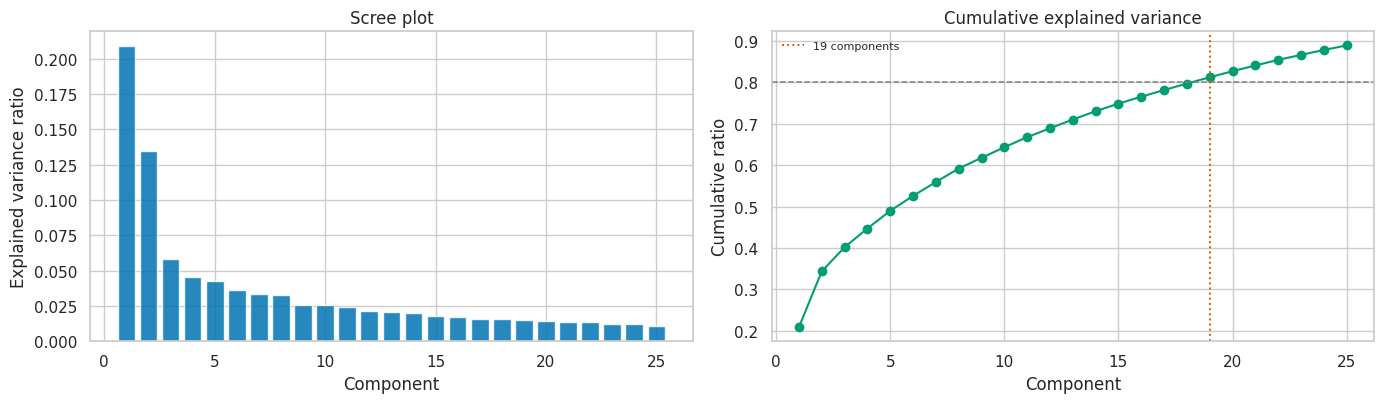

### Twelve strongest loadings on each of the first five components

component,PC1,PC2,PC3,PC4,PC5
feature,,,,,
adolescent,NaN,-0.188,NaN,NaN,NaN
age,NaN,0.205,NaN,0.210,-0.179
age_at_cohabitation,NaN,NaN,-0.347,0.338,NaN
age_at_first_birth,NaN,NaN,-0.312,0.371,NaN
age_sq,NaN,0.190,NaN,0.232,-0.197
age_x_education,NaN,0.213,-0.132,NaN,NaN
age_x_union,-0.204,0.214,NaN,NaN,NaN
asset_count,NaN,0.214,NaN,NaN,NaN
asset_index,NaN,0.214,NaN,NaN,NaN


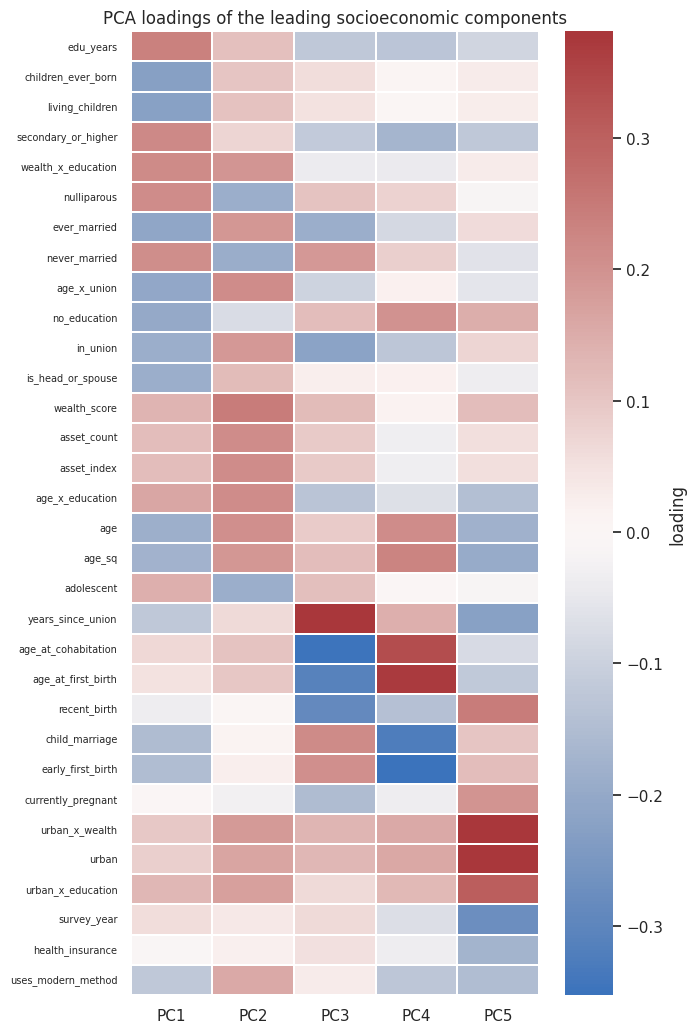

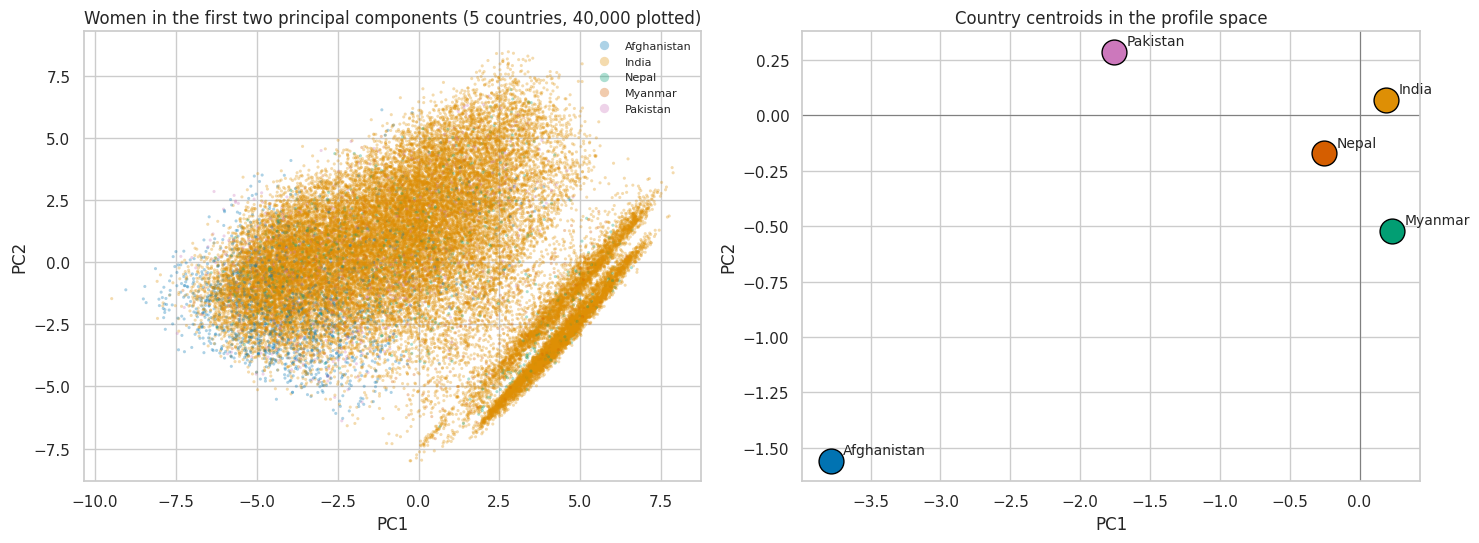

16013

In [45]:
# ================================================================================================
# RECODE SOURCE
#   * Individual Recode (IR) - XXIRnnFL - one record per interviewed woman 15-49
# WHAT THIS CELL USES: ml_dataset. PCA on the standardised socioeconomic feature space.
# NOTE: the design variables (V138 and its transforms) are excluded from the profile space on
#       purpose, so that section 20 can compare design-only against design+profile fairly.
# ================================================================================================
# 18a. PCA of the socioeconomic profile space

DESIGN_FEATURES = [f for f in FEATURE_BLOCKS["design"] if f in ml_dataset.columns]
PROFILE_NUMERIC = [f for f in NUMERIC_FEATURES
                   if f not in DESIGN_FEATURES and not f.startswith("eligible_")
                   and "eligible" not in f]
PROFILE_CATEGORICAL = [c for c in MODEL_CATEGORICALS
                       if c not in ("country", "region_key", "eligible_women_capped")]
print(f"Profile space: {len(PROFILE_NUMERIC)} numeric + {len(PROFILE_CATEGORICAL)} categorical "
      f"features (design variables held out)")

cluster_frame = subsample(ml_dataset, CLUSTER_SAMPLE_MAX)
print(f"Fitting on {len(cluster_frame):,} of {len(ml_dataset):,} women "
      f"({cluster_frame.group_key.nunique():,} clusters)")

profile_preprocessor = build_preprocessor(PROFILE_NUMERIC, PROFILE_CATEGORICAL, scale=True)
X_profile = profile_preprocessor.fit_transform(cluster_frame)
PROFILE_COLS = expanded_feature_names(profile_preprocessor)
print(f"Design matrix for the profile space: {X_profile.shape[0]:,} x {X_profile.shape[1]:,}")

pca_full = PCA(n_components=min(25, X_profile.shape[1]), random_state=RANDOM_SEED)
pca_scores = pca_full.fit_transform(X_profile)
explained = pd.DataFrame({
    "component": [f"PC{i + 1}" for i in range(pca_full.n_components_)],
    "explained_variance_ratio": pca_full.explained_variance_ratio_,
}).assign(cumulative=lambda x: x.explained_variance_ratio.cumsum())
display(Markdown("### PCA explained variance"))
display(explained.style.format({"explained_variance_ratio": "{:.3f}", "cumulative": "{:.3f}"}))
explained.to_csv(OUTPUT_DIR / "pca_explained_variance.csv", index=False)

N_PCA_COMPONENTS = int(np.searchsorted(explained.cumulative.to_numpy(), 0.80) + 1)
N_PCA_COMPONENTS = int(np.clip(N_PCA_COMPONENTS, 2, pca_full.n_components_))
print(f"Components needed for 80% of the variance: {N_PCA_COMPONENTS}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].bar(range(1, len(explained) + 1), explained.explained_variance_ratio,
            color=PALETTE[0], alpha=0.85)
axes[0].set_title("Scree plot"); axes[0].set_xlabel("Component")
axes[0].set_ylabel("Explained variance ratio")
axes[1].plot(range(1, len(explained) + 1), explained.cumulative, marker="o", color=PALETTE[2])
axes[1].axhline(0.80, color="grey", linestyle="--", linewidth=1.1)
axes[1].axvline(N_PCA_COMPONENTS, color=PALETTE[3], linestyle=":", linewidth=1.4,
                label=f"{N_PCA_COMPONENTS} components")
axes[1].set_title("Cumulative explained variance"); axes[1].set_xlabel("Component")
axes[1].set_ylabel("Cumulative ratio"); axes[1].legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

# --- what the leading components mean --------------------------------------------------------------
loadings = pd.DataFrame(pca_full.components_[:5].T, index=PROFILE_COLS,
                        columns=[f"PC{i + 1}" for i in range(5)])
top_loadings = pd.concat([
    loadings[pc].sort_values(key=np.abs, ascending=False).head(12).rename("loading")
    .to_frame().assign(component=pc).reset_index().rename(columns={"index": "feature"})
    for pc in loadings.columns], ignore_index=True)
display(Markdown("### Twelve strongest loadings on each of the first five components"))
display(top_loadings.pivot_table(index="feature", columns="component", values="loading",
                                aggfunc="first").round(3))
top_loadings.to_csv(OUTPUT_DIR / "pca_top_loadings.csv", index=False)

heat_features = top_loadings.feature.unique()
plt.figure(figsize=(7, 0.25 * len(heat_features) + 2.5))
sns.heatmap(loadings.loc[heat_features], cmap="vlag", center=0, annot=False,
            linewidths=0.2, linecolor="white", cbar_kws={"label": "loading"})
plt.title("PCA loadings of the leading socioeconomic components")
plt.xlabel(""); plt.ylabel(""); plt.yticks(fontsize=7)
plt.tight_layout(); plt.show()

# --- where the countries sit in the PCA space -------------------------------------------------------
pca_plot = pd.DataFrame({"PC1": pca_scores[:, 0], "PC2": pca_scores[:, 1],
                         "country": cluster_frame.country.to_numpy(),
                         "y_selected": cluster_frame.y_selected.to_numpy()})
plot_sample = pca_plot.sample(min(40_000, len(pca_plot)), random_state=RANDOM_SEED)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
sns.scatterplot(data=plot_sample, x="PC1", y="PC2", hue="country", s=5, alpha=0.32,
                palette=PALETTE[:plot_sample.country.nunique()], ax=axes[0], linewidth=0,
                rasterized=True)
axes[0].set_title(f"Women in the first two principal components "
                  f"({plot_sample.country.nunique()} countries, {len(plot_sample):,} plotted)")
axes[0].legend(markerscale=3, fontsize=8, frameon=False)
centroids = pca_plot.groupby("country")[["PC1", "PC2"]].mean()
for i, (country, row) in enumerate(centroids.iterrows()):
    axes[1].scatter(row.PC1, row.PC2, s=320, color=PALETTE[i % len(PALETTE)],
                    edgecolor="black", zorder=3)
    axes[1].annotate(country, (row.PC1, row.PC2), textcoords="offset points", xytext=(9, 5),
                     fontsize=10)
axes[1].axhline(0, color="grey", linewidth=0.8); axes[1].axvline(0, color="grey", linewidth=0.8)
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
axes[1].set_title("Country centroids in the profile space")
plt.tight_layout(); plt.show()
centroids.round(3).to_csv(OUTPUT_DIR / "pca_country_centroids.csv")
gc.collect()

  k= 2: inertia=     7,194,737  silhouette=+0.178  GMM BIC=      12,152,114
  k= 3: inertia=     6,114,128  silhouette=+0.191  GMM BIC=      11,998,562
  k= 4: inertia=     5,745,936  silhouette=+0.163  GMM BIC=      11,803,595
  k= 5: inertia=     5,472,999  silhouette=+0.153  GMM BIC=      11,757,239
  k= 6: inertia=     5,243,066  silhouette=+0.125  GMM BIC=      11,662,006
  k= 7: inertia=     5,051,433  silhouette=+0.122  GMM BIC=      11,581,527
  k= 8: inertia=     4,906,981  silhouette=+0.116  GMM BIC=      11,489,661
  k= 9: inertia=     4,777,350  silhouette=+0.117  GMM BIC=      11,415,429
  k=10: inertia=     4,611,001  silhouette=+0.121  GMM BIC=      11,336,306


### Choosing the number of profiles

,k,kmeans_inertia,silhouette,calinski_harabasz,gmm_bic,gmm_aic
0,2,"7,194,737",+0.178,"4,601","12,152,114","12,151,329"
1,3,"6,114,128",+0.191,"4,466","11,998,562","11,997,379"
2,4,"5,745,936",+0.163,"3,590","11,803,595","11,802,014"
3,5,"5,472,999",+0.153,"3,082","11,757,239","11,755,259"
4,6,"5,243,066",+0.125,"2,746","11,662,006","11,659,628"
5,7,"5,051,433",+0.122,"2,500","11,581,527","11,578,751"
6,8,"4,906,981",+0.116,"2,291","11,489,661","11,486,487"
7,9,"4,777,350",+0.117,"2,129","11,415,429","11,411,857"
8,10,"4,611,001",+0.121,"2,044","11,336,306","11,332,336"


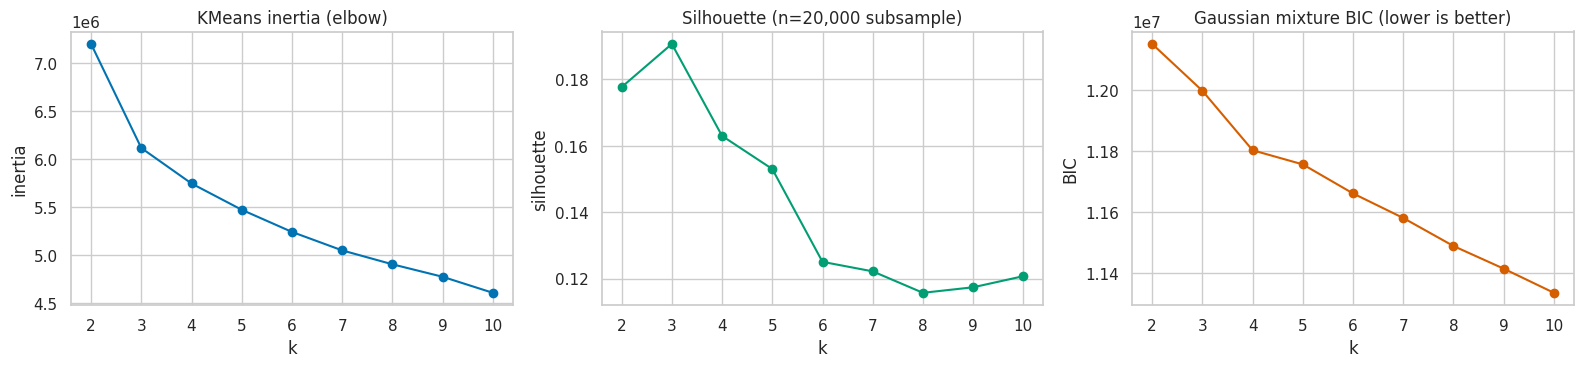


Silhouette prefers k=3; GMM BIC prefers k=10.
Profiles used for reporting: N_PROFILES = 6


/tmp/ipykernel_116/4247768686.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cluster_frame["profile_km"] = kmeans_model.labels_
/tmp/ipykernel_116/4247768686.py:65: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cluster_frame["profile_gmm"] = gmm_model.predict(Z)
/tmp/ipykernel_116/4247768686.py:66: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pyda

### KMeans profile x Gaussian-mixture component (row = KMeans)

profile_gmm,0,1,2,3,4,5
profile_km,,,,,,
0,24279,0,2390,6451,1506,5728
1,7,2,14046,5077,689,12890
2,1360,13,14942,16847,990,12551
3,14,20134,4128,3667,14,18
4,14866,0,2061,12579,2012,138
5,0,12313,6245,1874,3,19


Mean posterior confidence of the Gaussian-mixture assignment: 0.908


### Profile centroids in original units (KMeans)

,age,edu_years,secondary_or_higher,urban,wealth_quintile,wealth_score,asset_index,dwelling_quality,in_union,child_marriage,children_ever_born,media_index,female_head,hh_size,n_eligible_women,share_pct
profile_km,,,,,,,,,,,,,,,,
0,40.396999,2.054,0.125,0.201,2.775,-0.112,0.391,0.733,0.922,0.660,3.405,0.285,0.151,5.287,1.741,20.2
1,35.689999,11.481,0.957,0.717,4.412,10.513,0.555,0.927,0.959,0.165,1.913,0.598,0.154,5.299,1.560,16.4
2,27.865999,9.149,0.878,0.074,2.708,-0.456,0.392,0.707,0.969,0.286,1.618,0.411,0.152,5.735,1.586,23.4
3,18.934000,8.901,0.857,0.051,2.037,-5.115,0.314,0.600,0.012,0.471,0.004,0.368,0.174,5.710,2.339,14.0
4,32.382000,1.100,0.058,0.084,1.595,-8.450,0.240,0.432,0.937,0.468,3.197,0.139,0.148,6.287,1.459,15.8
5,21.035000,12.120,0.979,0.587,4.178,9.074,0.522,0.911,0.010,0.325,0.004,0.619,0.184,5.487,2.386,10.2


/tmp/ipykernel_116/4247768686.py:116: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cluster_frame["profile_name"] = cluster_frame.profile_km.map(PROFILE_NAMES)


### Named profiles

,profile,share_pct,n_women
0,P0: middle rural no/low-education high-parity,20.2,40354
1,P1: richer urban higher-education,16.4,32711
2,P2: middle rural secondary,23.4,46703
3,P3: poorer rural secondary never-married,14.0,27975
4,P4: poorer rural no/low-education high-parity,15.8,31656
5,P5: richer urban higher-education never-married,10.2,20454


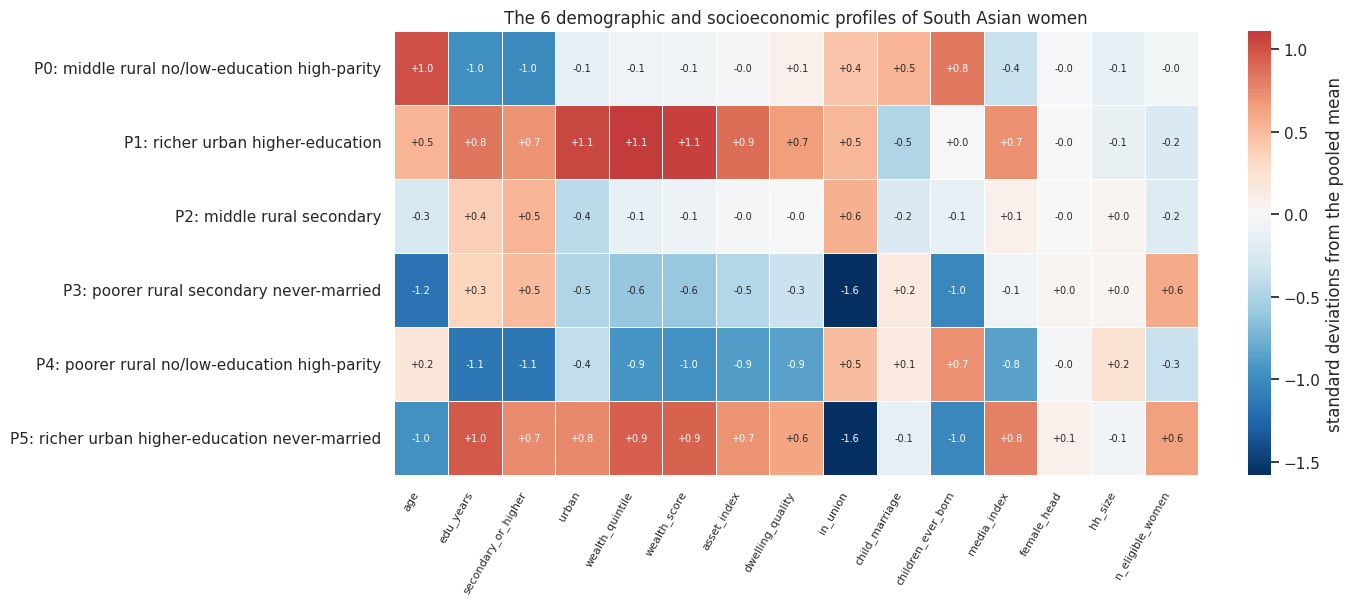

57860

In [46]:
# ================================================================================================
# RECODE SOURCE
#   * Individual Recode (IR) - XXIRnnFL - one record per interviewed woman 15-49
# WHAT THIS CELL USES: the PCA scores of 18a. KMeans and Gaussian-mixture profiles.
# ================================================================================================
# 18b. How many distinct profiles? KMeans, silhouette and Gaussian-mixture BIC

Z = pca_scores[:, :N_PCA_COMPONENTS]
K_RANGE = list(range(2, 11))
SILHOUETTE_SAMPLE = min(20_000, len(Z))
rng = np.random.default_rng(RANDOM_SEED)
sil_idx = rng.choice(len(Z), SILHOUETTE_SAMPLE, replace=False)

selection_rows = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_SEED)
    labels = km.fit_predict(Z)
    gm = GaussianMixture(n_components=k, covariance_type="diag", random_state=RANDOM_SEED,
                         max_iter=200, reg_covar=1e-5)
    gm.fit(Z)
    selection_rows.append({
        "k": k,
        "kmeans_inertia": float(km.inertia_),
        "silhouette": float(silhouette_score(Z[sil_idx], labels[sil_idx])),
        "calinski_harabasz": float(calinski_harabasz_score(Z[sil_idx], labels[sil_idx])),
        "gmm_bic": float(gm.bic(Z)),
        "gmm_aic": float(gm.aic(Z)),
    })
    print(f"  k={k:>2}: inertia={km.inertia_:>14,.0f}  silhouette={selection_rows[-1]['silhouette']:+.3f}  "
          f"GMM BIC={gm.bic(Z):>16,.0f}")

cluster_selection = pd.DataFrame(selection_rows)
display(Markdown("### Choosing the number of profiles"))
display(cluster_selection.style.format({
    "kmeans_inertia": "{:,.0f}", "silhouette": "{:+.3f}", "calinski_harabasz": "{:,.0f}",
    "gmm_bic": "{:,.0f}", "gmm_aic": "{:,.0f}"}))
cluster_selection.to_csv(OUTPUT_DIR / "cluster_k_selection.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.0))
axes[0].plot(cluster_selection.k, cluster_selection.kmeans_inertia, marker="o", color=PALETTE[0])
axes[0].set_title("KMeans inertia (elbow)"); axes[0].set_xlabel("k"); axes[0].set_ylabel("inertia")
axes[1].plot(cluster_selection.k, cluster_selection.silhouette, marker="o", color=PALETTE[2])
axes[1].set_title(f"Silhouette (n={SILHOUETTE_SAMPLE:,} subsample)")
axes[1].set_xlabel("k"); axes[1].set_ylabel("silhouette")
axes[2].plot(cluster_selection.k, cluster_selection.gmm_bic, marker="o", color=PALETTE[3])
axes[2].set_title("Gaussian mixture BIC (lower is better)")
axes[2].set_xlabel("k"); axes[2].set_ylabel("BIC")
for ax in axes:
    ax.set_xticks(K_RANGE)
plt.tight_layout(); plt.show()

BEST_K_SILHOUETTE = int(cluster_selection.loc[cluster_selection.silhouette.idxmax(), "k"])
BEST_K_BIC = int(cluster_selection.loc[cluster_selection.gmm_bic.idxmin(), "k"])
# A reporting choice: enough profiles to be substantively interesting, few enough to name and
# tabulate against five countries. The two statistical criteria are printed for transparency.
N_PROFILES = int(np.clip(BEST_K_SILHOUETTE if BEST_K_SILHOUETTE >= 4 else 6, 4, 8))
print(f"\nSilhouette prefers k={BEST_K_SILHOUETTE}; GMM BIC prefers k={BEST_K_BIC}.")
print(f"Profiles used for reporting: N_PROFILES = {N_PROFILES}")

# --- fit the reported models -----------------------------------------------------------------------
kmeans_model = KMeans(n_clusters=N_PROFILES, n_init=20, random_state=RANDOM_SEED).fit(Z)
gmm_model = GaussianMixture(n_components=N_PROFILES, covariance_type="diag",
                            random_state=RANDOM_SEED, max_iter=300, reg_covar=1e-5).fit(Z)
cluster_frame["profile_km"] = kmeans_model.labels_
cluster_frame["profile_gmm"] = gmm_model.predict(Z)
cluster_frame["profile_gmm_confidence"] = gmm_model.predict_proba(Z).max(axis=1)

agreement = pd.crosstab(cluster_frame.profile_km, cluster_frame.profile_gmm)
display(Markdown("### KMeans profile x Gaussian-mixture component (row = KMeans)"))
display(agreement)
print(f"Mean posterior confidence of the Gaussian-mixture assignment: "
      f"{cluster_frame.profile_gmm_confidence.mean():.3f}")

# --- describe each profile in original units -------------------------------------------------------
DESCRIBE_FEATURES = [f for f in [
    "age", "edu_years", "secondary_or_higher", "urban", "wealth_quintile", "wealth_score",
    "asset_index", "dwelling_quality", "connectivity_index", "in_union", "child_marriage",
    "children_ever_born", "spousal_age_gap", "spousal_edu_gap", "currently_working",
    "empowerment_index", "decision_index", "media_index", "attitude_index", "female_head",
    "hh_size", "n_eligible_women",
] if f in cluster_frame.columns]

profile_centres = (cluster_frame.groupby("profile_km")[DESCRIBE_FEATURES].mean().round(3))
profile_sizes = (cluster_frame.profile_km.value_counts(normalize=True).sort_index()
                 .mul(100).round(1).rename("share_pct"))
profile_summary = profile_centres.join(profile_sizes)
display(Markdown("### Profile centroids in original units (KMeans)"))
display(profile_summary)

# --- automatic, reproducible profile names ---------------------------------------------------------
def name_profile(row, medians):
    bits = []
    if "wealth_quintile" in row:
        bits.append({0: "poorest", 1: "poorer", 2: "middle", 3: "richer", 4: "richest"}[
            int(np.clip(round(row["wealth_quintile"]) - 1, 0, 4))])
    if "urban" in row:
        bits.append("urban" if row["urban"] >= 0.5 else "rural")
    if "edu_years" in row:
        bits.append("no/low-education" if row["edu_years"] < 5
                    else ("secondary" if row["edu_years"] < 11 else "higher-education"))
    if "in_union" in row and row["in_union"] < 0.5:
        bits.append("never-married")
    elif "children_ever_born" in row and row["children_ever_born"] >= medians["children_ever_born"] * 1.3:
        bits.append("high-parity")
    if "empowerment_index" in row and pd.notna(medians.get("empowerment_index")):
        if row["empowerment_index"] >= medians["empowerment_index"] * 1.25:
            bits.append("high-agency")
        elif row["empowerment_index"] <= medians["empowerment_index"] * 0.75:
            bits.append("low-agency")
    return " ".join(bits)


medians = cluster_frame[DESCRIBE_FEATURES].median()
PROFILE_NAMES = {int(k): f"P{int(k)}: {name_profile(row, medians)}"
                 for k, row in profile_centres.iterrows()}
cluster_frame["profile_name"] = cluster_frame.profile_km.map(PROFILE_NAMES)
display(Markdown("### Named profiles"))
display(pd.DataFrame({"profile": list(PROFILE_NAMES.values()),
                      "share_pct": profile_sizes.to_numpy(),
                      "n_women": cluster_frame.profile_km.value_counts().sort_index().to_numpy()}))
profile_summary.assign(profile_name=[PROFILE_NAMES[i] for i in profile_summary.index]) \
    .to_csv(OUTPUT_DIR / "profile_centroids.csv")

zscored = (profile_centres - cluster_frame[DESCRIBE_FEATURES].mean()) / \
          cluster_frame[DESCRIBE_FEATURES].std().replace(0, np.nan)
plt.figure(figsize=(0.75 * len(DESCRIBE_FEATURES) + 3, 0.62 * N_PROFILES + 2.5))
sns.heatmap(zscored.rename(index=PROFILE_NAMES), annot=True, fmt="+.1f",
            annot_kws={"fontsize": 7}, cmap="RdBu_r", center=0, linewidths=0.4,
            linecolor="white", cbar_kws={"label": "standard deviations from the pooled mean"})
plt.title(f"The {N_PROFILES} demographic and socioeconomic profiles of South Asian women")
plt.xlabel(""); plt.ylabel("")
plt.xticks(rotation=60, ha="right", fontsize=8)
plt.tight_layout(); plt.show()
gc.collect()

Assigned a profile to all 796,374 women (6 profiles in use)


### Profile mix by country (row %, unweighted)

profile_name,P0: middle rural no/low-education high-parity,P1: richer urban higher-education,P2: middle rural secondary,P3: poorer rural secondary never-married,P4: poorer rural no/low-education high-parity,P5: richer urban higher-education never-married
country,,,,,,
Afghanistan,8.6,3.2,4.8,0.1,83.0,0.2
India,20.7,17.2,24.3,14.5,12.4,10.9
Myanmar,10.0,13.2,18.0,18.6,26.1,14.2
Nepal,29.9,13.5,24.9,12.7,9.9,9.1
Pakistan,22.8,22.8,19.1,0.2,34.6,0.5


### Profile mix by country (row %, weighted by V005)

profile_name,P0: middle rural no/low-education high-parity,P1: richer urban higher-education,P2: middle rural secondary,P3: poorer rural secondary never-married,P4: poorer rural no/low-education high-parity,P5: richer urban higher-education never-married
country,,,,,,
Afghanistan,11.700000,4.3,5.4,0.1,78.099998,0.3
India,21.000000,20.9,22.5,12.5,11.400000,11.8
Myanmar,9.900000,12.9,17.9,19.5,25.400000,14.3
Nepal,28.700001,19.0,21.6,10.1,8.500000,12.2
Pakistan,22.600000,21.5,21.5,0.3,33.700001,0.4


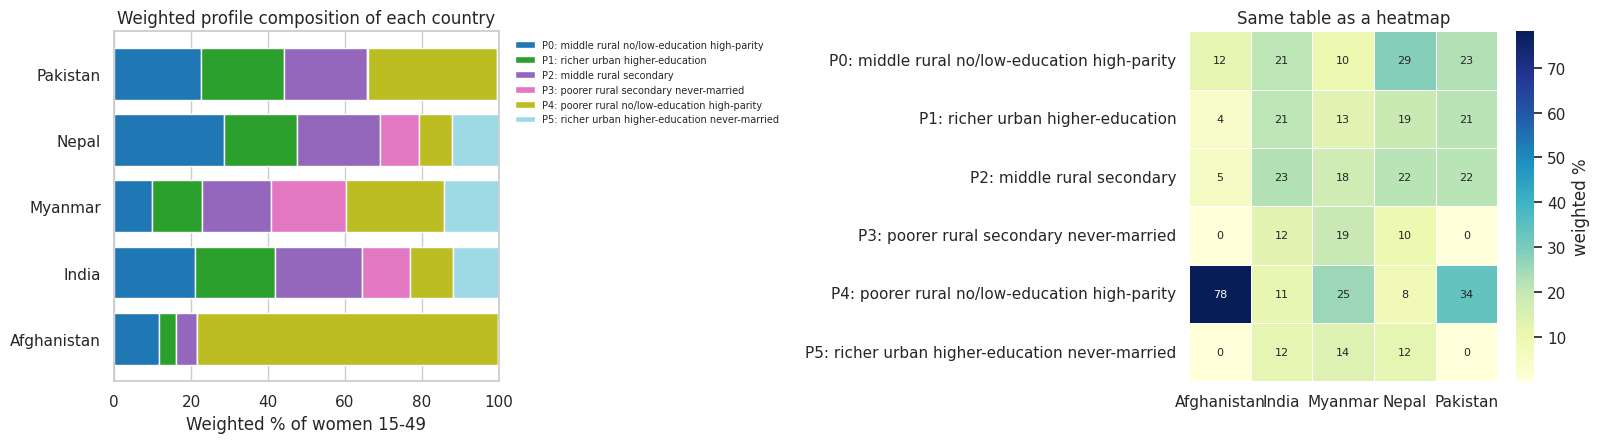

### DV-module selection rate by profile, against what the design alone predicts

,n_women,pct_of_sample,pct_selected,pct_selected_weighted,mean_eligible_women,expected_pct_from_design,excess_over_design_pp
profile_name,,,,,,,
P0: middle rural no/low-education high-parity,"161,304",20.3,75.00,75.04,1.73,70.96,+4.04
P1: richer urban higher-education,"132,868",16.7,78.75,79.48,1.56,77.69,+1.06
P2: middle rural secondary,"186,363",23.4,76.95,75.04,1.58,77.43,-0.49
P3: poorer rural secondary never-married,"109,529",13.8,28.00,25.50,2.33,50.21,-22.20
P4: poorer rural no/low-education high-parity,"123,990",15.6,81.05,81.21,1.46,81.48,-0.43
P5: richer urban higher-education never-married,"82,320",10.3,37.35,35.74,2.38,49.88,-12.52


### Selection rate by profile x country (cells with fewer than 25 women dropped)

country,Afghanistan,India,Myanmar,Nepal,Pakistan
profile_name,,,,,
P0: middle rural no/low-education high-parity,78.839996,77.459999,36.930000,36.580002,28.910000
P1: richer urban higher-education,81.620003,81.320000,36.410000,38.110001,29.020000
P2: middle rural secondary,69.389999,79.220001,38.330002,36.770000,24.580000
P3: poorer rural secondary never-married,44.830002,28.059999,27.520000,25.520000,20.590000
P4: poorer rural no/low-education high-parity,74.879997,87.879997,42.880001,41.110001,28.760000
P5: richer urban higher-education never-married,64.790001,37.779999,26.340000,26.680000,17.139999


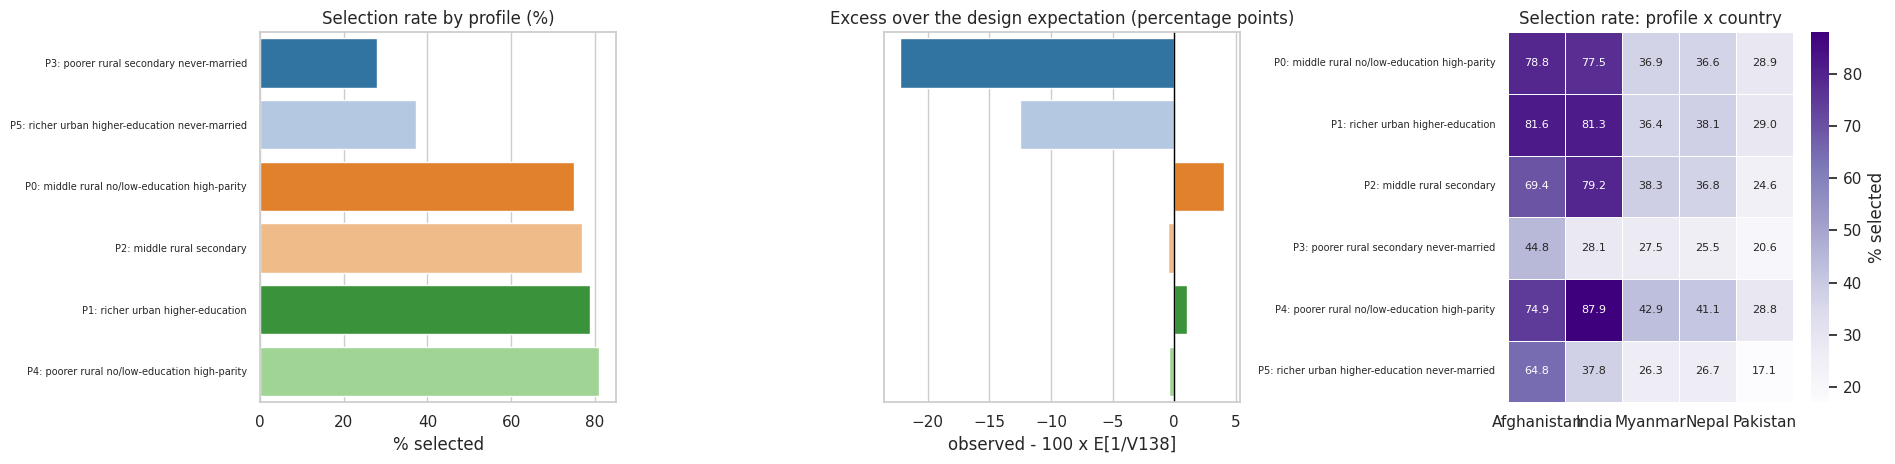

**How to read the middle panel.** A bar near zero means the profile's selection rate is exactly what the one-woman-per-household rule predicts from its household composition — no profile effect. A bar away from zero is the part of the story the supervised models in §19–§20 have to explain, and §20 tests whether it survives once `V138` and country are in the model.

11492

In [47]:
# ================================================================================================
# RECODE SOURCE
#   * Individual Recode (IR) - XXIRnnFL - one record per interviewed woman 15-49
# WHAT THIS CELL USES: the fitted profile pipeline of 18a/18b, applied to every row of ml_dataset.
# ================================================================================================
# 18c. Profiles x country, and the selection rate of each profile

# --- assign a profile to every woman, in chunks so the dense matrix never blows up ----------------
CHUNK = 150_000
profile_labels, pc1_all, pc2_all = [], [], []
for start in range(0, len(ml_dataset), CHUNK):
    block = ml_dataset.iloc[start:start + CHUNK]
    Zb = pca_full.transform(profile_preprocessor.transform(block))[:, :N_PCA_COMPONENTS]
    profile_labels.append(kmeans_model.predict(Zb))
    pc1_all.append(Zb[:, 0]); pc2_all.append(Zb[:, 1])
    del Zb
ml_dataset["profile_km"] = np.concatenate(profile_labels)
ml_dataset["profile_name"] = ml_dataset.profile_km.map(PROFILE_NAMES)
ml_dataset["pc1"] = np.concatenate(pc1_all).astype("float32")
ml_dataset["pc2"] = np.concatenate(pc2_all).astype("float32")
del profile_labels, pc1_all, pc2_all
gc.collect()
print(f"Assigned a profile to all {len(ml_dataset):,} women "
      f"({ml_dataset.profile_km.nunique()} profiles in use)")

# --- 1. profile mix by country ---------------------------------------------------------------------
profile_country = pd.crosstab(ml_dataset.country, ml_dataset.profile_name, normalize="index").mul(100)
display(Markdown("### Profile mix by country (row %, unweighted)"))
display(profile_country.round(1))
profile_country.round(2).to_csv(OUTPUT_DIR / "profile_mix_by_country_unweighted.csv")

weighted_mix = (ml_dataset.groupby(["country", "profile_name"])["w_ind"].sum().unstack(fill_value=0.0)
                .pipe(lambda df: df.div(df.sum(axis=1), axis=0) * 100))
display(Markdown("### Profile mix by country (row %, weighted by V005)"))
display(weighted_mix.round(1))
weighted_mix.round(2).to_csv(OUTPUT_DIR / "profile_mix_by_country_weighted.csv")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.6))
weighted_mix.plot(kind="barh", stacked=True, ax=axes[0], colormap="tab20", width=0.78)
axes[0].set_title("Weighted profile composition of each country")
axes[0].set_xlabel("Weighted % of women 15-49"); axes[0].set_ylabel(""); axes[0].set_xlim(0, 100)
axes[0].legend(bbox_to_anchor=(1.02, 1.0), loc="upper left", fontsize=7, frameon=False)
sns.heatmap(weighted_mix.T, annot=True, fmt=".0f", cmap="YlGnBu", linewidths=0.4,
            linecolor="white", ax=axes[1], cbar_kws={"label": "weighted %"},
            annot_kws={"fontsize": 8})
axes[1].set_title("Same table as a heatmap"); axes[1].set_xlabel(""); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

# --- 2. selection rate by profile, and by profile x country ----------------------------------------
profile_selection = summarise_groups(ml_dataset, "profile_name", lambda g: {
    "n_women": len(g),
    "pct_of_sample": 100 * len(g) / len(ml_dataset),
    "pct_selected": 100 * g.y_selected.mean(),
    "pct_selected_weighted": weighted_share(g.y_selected, g.w_ind, 1),
    "mean_eligible_women": g.n_eligible_women.mean(),
    "expected_pct_from_design": 100 * g.inv_eligible_women.mean(),
})
profile_selection["excess_over_design_pp"] = (profile_selection.pct_selected -
                                              profile_selection.expected_pct_from_design)
display(Markdown("### DV-module selection rate by profile, against what the design alone predicts"))
display(profile_selection.style.format({
    "n_women": "{:,.0f}", "pct_of_sample": "{:.1f}", "pct_selected": "{:.2f}",
    "pct_selected_weighted": "{:.2f}", "mean_eligible_women": "{:.2f}",
    "expected_pct_from_design": "{:.2f}", "excess_over_design_pp": "{:+.2f}"}))
profile_selection.to_csv(OUTPUT_DIR / "profile_selection_rates.csv")

profile_country_selection = summarise_groups(ml_dataset, ["country", "profile_name"], lambda g: {
    "n_women": len(g),
    "pct_selected": 100 * g.y_selected.mean(),
    "mean_eligible_women": g.n_eligible_women.mean(),
}).reset_index()
profile_country_selection = profile_country_selection[
    profile_country_selection.n_women.ge(MIN_UNWEIGHTED_CELL)]
display(Markdown(f"### Selection rate by profile x country "
                 f"(cells with fewer than {MIN_UNWEIGHTED_CELL} women dropped)"))
display(profile_country_selection.pivot_table(index="profile_name", columns="country",
                                             values="pct_selected", aggfunc="first").round(2))
profile_country_selection.to_csv(OUTPUT_DIR / "profile_country_selection.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
sel_plot = profile_selection.reset_index().sort_values("pct_selected")
sns.barplot(data=sel_plot, y="profile_name", x="pct_selected", ax=axes[0],
            hue="profile_name", palette="tab20", legend=False, dodge=False)
axes[0].set_title("Selection rate by profile (%)"); axes[0].set_xlabel("% selected")
axes[0].set_ylabel(""); axes[0].tick_params(axis="y", labelsize=7)
sns.barplot(data=sel_plot, y="profile_name", x="excess_over_design_pp", ax=axes[1],
            hue="profile_name", palette="tab20", legend=False, dodge=False)
axes[1].axvline(0, color="black", linewidth=1.0)
axes[1].set_title("Excess over the design expectation (percentage points)")
axes[1].set_xlabel("observed - 100 x E[1/V138]"); axes[1].set_ylabel("")
axes[1].set_yticklabels([])
pcs_heat = profile_country_selection.pivot_table(index="profile_name", columns="country",
                                                values="pct_selected", aggfunc="first")
sns.heatmap(pcs_heat, annot=True, fmt=".1f", cmap="Purples", linewidths=0.4, linecolor="white",
            ax=axes[2], cbar_kws={"label": "% selected"}, annot_kws={"fontsize": 8})
axes[2].set_title("Selection rate: profile x country"); axes[2].set_xlabel(""); axes[2].set_ylabel("")
axes[2].tick_params(axis="y", labelsize=7)
plt.tight_layout(); plt.show()

display(Markdown(
    "**How to read the middle panel.** A bar near zero means the profile's selection rate is exactly "
    "what the one-woman-per-household rule predicts from its household composition — no profile "
    "effect. A bar away from zero is the part of the story the supervised models in §19–§20 have to "
    "explain, and §20 tests whether it survives once `V138` and country are in the model."))
gc.collect()

## 19. Question part 4 — *Are profile combinations associated with DV-module selection?* (supervised models)

**Recode used: Individual Recode (IR).** Target `y_selected` = `V044 ∈ {1, 2, 3}`.

### The split

`GroupShuffleSplit` on `group_key` (country + primary sampling unit). This matters more than usual here: the DV sub-sample is drawn at the **household level within clusters**, so a random row-wise split would put neighbours of a selected woman in the training set and leak the cluster's sub-sample status into the test set. Splitting by PSU removes that path.

### The learners

| Family | Models | Why it is in the table |
|---|---|---|
| Baselines | majority-class, design-only logistic | the floor any real model must clear |
| Linear | Logistic regression (L2), Linear SVM | interpretable coefficients, odds ratios |
| Naive Bayes | Gaussian NB, Bernoulli NB | strong independence assumption — its gap to the trees measures how much of the signal *is* interaction |
| Trees | Decision tree (depth-limited, readable), Random forest, Extra trees | non-linear, interaction-capturing, feature importances |
| Boosting | AdaBoost, Gradient boosting, HistGradientBoosting, **XGBoost**, **LightGBM** | the accuracy ceiling on tabular data |
| Kernel / distance | SVC with an RBF kernel, K-nearest neighbours | fitted on a `KERNEL_SAMPLE_MAX` subsample — both scale super-linearly |
| Dimension reduction | PCA → logistic, PCA → linear SVM, LDA | tests whether the profile axes alone carry the signal |

XGBoost and LightGBM are imported behind `try/except`; if the image lacks them the table simply reports fewer rows and says so.

### Metrics

Accuracy is close to useless here — the positive rate is well below 50% in every country. The reported set is **ROC-AUC, PR-AUC, balanced accuracy, F1, precision, recall and the Brier score**, and each row records the sample size it was fitted on. PR-AUC is the honest headline for an imbalanced target.

### The interpretation trap this section is designed to avoid

A model that predicts `y_selected` well is **not** a finding about domestic violence. `V044` is a *sampling flag*. High accuracy here mostly reflects `1 / V138`. That is exactly why §20 refits the same learner on nested feature blocks: the quantity of interest is not AUC, it is **ΔAUC over the design-only model**.

In [48]:
# ================================================================================================
# RECODE SOURCE
#   * Individual Recode (IR) - XXIRnnFL - one record per interviewed woman 15-49
# WHAT THIS CELL USES: ml_dataset. Cluster-aware split, preprocessing, and the model zoo.
# ================================================================================================
# 19a. Train / test split and the model zoo

from sklearn.dummy import DummyClassifier

TARGET = "y_selected"
model_pool = subsample(ml_dataset, MODEL_SAMPLE_MAX)
train_df, test_df = group_holdout(model_pool, target=TARGET)
print(f"Model pool : {len(model_pool):,} women, {model_pool.group_key.nunique():,} clusters")
print(f"Train      : {len(train_df):,} women, {train_df.group_key.nunique():,} clusters, "
      f"{100 * train_df[TARGET].mean():.2f}% positive")
print(f"Test       : {len(test_df):,} women, {test_df.group_key.nunique():,} clusters, "
      f"{100 * test_df[TARGET].mean():.2f}% positive")
assert not (set(train_df.group_key) & set(test_df.group_key)), "cluster leakage between train and test"
print("No primary sampling unit appears in both splits.")

split_audit = pd.DataFrame({
    "split": ["train", "test"],
    "n_women": [len(train_df), len(test_df)],
    "n_clusters": [train_df.group_key.nunique(), test_df.group_key.nunique()],
    "pct_positive": [100 * train_df[TARGET].mean(), 100 * test_df[TARGET].mean()],
    "countries": [train_df.country.nunique(), test_df.country.nunique()],
})
display(Markdown("### Split audit"))
display(split_audit.style.format({"n_women": "{:,.0f}", "n_clusters": "{:,.0f}",
                                  "pct_positive": "{:.2f}"}))

ALL_NUMERIC = [f for f in NUMERIC_FEATURES if f in ml_dataset.columns]
ALL_CATEGORICAL = [c for c in MODEL_CATEGORICALS if c in ml_dataset.columns]
DESIGN_ONLY_NUMERIC = [f for f in DESIGN_FEATURES if f in ALL_NUMERIC]
DESIGN_ONLY_CATEGORICAL = [c for c in ["country", "eligible_women_capped"] if c in ALL_CATEGORICAL]
print(f"\nFeatures entering the pooled models: {len(ALL_NUMERIC)} numeric + "
      f"{len(ALL_CATEGORICAL)} categorical")
print(f"Design-only baseline uses: {DESIGN_ONLY_NUMERIC} + {DESIGN_ONLY_CATEGORICAL}")

y_train = train_df[TARGET].to_numpy()
y_test = test_df[TARGET].to_numpy()
POS_WEIGHT = float((y_train == 0).sum() / max((y_train == 1).sum(), 1))
print(f"Class imbalance: {100 * y_train.mean():.2f}% positive -> "
      f"scale_pos_weight = {POS_WEIGHT:.2f}")


def zoo_entry(name, estimator, family, scale=False, kernel=False, numeric=None, categorical=None):
    """One learner plus how it wants its inputs.

    scale     - standardise the numerics (linear, kernel, distance and PCA models need this)
    kernel    - fit on a KERNEL_SAMPLE_MAX subsample (super-linear learners)
    numeric   - restrict the numeric feature list (used for the design-only baseline)
    """
    return {"name": name, "estimator": estimator, "family": family, "scale": scale,
            "kernel": kernel,
            "numeric": ALL_NUMERIC if numeric is None else numeric,
            "categorical": ALL_CATEGORICAL if categorical is None else categorical}


MODEL_ZOO = [
    zoo_entry("Baseline: majority class",
              DummyClassifier(strategy="most_frequent"), "baseline"),
    zoo_entry("Baseline: stratified random",
              DummyClassifier(strategy="stratified", random_state=RANDOM_SEED), "baseline"),
    zoo_entry("Baseline: design only (V138 + country)",
              LogisticRegression(max_iter=3000, class_weight="balanced", n_jobs=N_JOBS),
              "baseline", scale=True,
              numeric=DESIGN_ONLY_NUMERIC, categorical=DESIGN_ONLY_CATEGORICAL),
    zoo_entry("Logistic regression (L2)",
              LogisticRegression(max_iter=3000, C=1.0, class_weight="balanced", n_jobs=N_JOBS),
              "linear", scale=True),
    zoo_entry("Linear SVM",
              LinearSVC(C=0.5, class_weight="balanced", dual="auto", max_iter=5000,
                        random_state=RANDOM_SEED), "linear", scale=True),
    zoo_entry("Linear discriminant analysis",
              LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto"), "linear", scale=True),
    zoo_entry("Gaussian naive Bayes", GaussianNB(), "naive_bayes", scale=True),
    zoo_entry("Bernoulli naive Bayes", BernoulliNB(alpha=1.0), "naive_bayes", scale=True),
    zoo_entry("Decision tree (depth 5, readable)",
              DecisionTreeClassifier(max_depth=5, min_samples_leaf=200, class_weight="balanced",
                                     random_state=RANDOM_SEED), "tree"),
    zoo_entry("Decision tree (tuned)",
              DecisionTreeClassifier(max_depth=12, min_samples_leaf=60, min_samples_split=200,
                                     class_weight="balanced", random_state=RANDOM_SEED), "tree"),
    zoo_entry("Random forest",
              RandomForestClassifier(n_estimators=400, max_depth=18, min_samples_leaf=25,
                                     class_weight="balanced_subsample", n_jobs=N_JOBS,
                                     random_state=RANDOM_SEED), "ensemble"),
    zoo_entry("Extra trees",
              ExtraTreesClassifier(n_estimators=400, max_depth=20, min_samples_leaf=25,
                                   class_weight="balanced_subsample", n_jobs=N_JOBS,
                                   random_state=RANDOM_SEED), "ensemble"),
    zoo_entry("AdaBoost",
              AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=3), n_estimators=200,
                                 learning_rate=0.5, random_state=RANDOM_SEED), "boosting"),
    zoo_entry("Gradient boosting",
              GradientBoostingClassifier(n_estimators=200, max_depth=4, learning_rate=0.08,
                                         subsample=0.8, random_state=RANDOM_SEED), "boosting"),
    zoo_entry("HistGradientBoosting",
              HistGradientBoostingClassifier(max_iter=350, learning_rate=0.07,
                                             max_leaf_nodes=63, l2_regularization=1.0,
                                             early_stopping=True, validation_fraction=0.12,
                                             random_state=RANDOM_SEED), "boosting"),
    zoo_entry("K-nearest neighbours (k=45)",
              KNeighborsClassifier(n_neighbors=45, weights="distance", n_jobs=N_JOBS),
              "distance", scale=True, kernel=True),
    zoo_entry("SVM (RBF kernel)",
              SVC(C=2.0, gamma="scale", class_weight="balanced", probability=False,
                  cache_size=600, random_state=RANDOM_SEED), "kernel", scale=True, kernel=True),
    zoo_entry(f"PCA({N_PCA_COMPONENTS}) -> logistic regression",
              Pipeline([("pca", PCA(n_components=N_PCA_COMPONENTS, random_state=RANDOM_SEED)),
                        ("clf", LogisticRegression(max_iter=3000, class_weight="balanced",
                                                   n_jobs=N_JOBS))]),
              "dimension_reduction", scale=True),
    zoo_entry(f"PCA({N_PCA_COMPONENTS}) -> linear SVM",
              Pipeline([("pca", PCA(n_components=N_PCA_COMPONENTS, random_state=RANDOM_SEED)),
                        ("clf", LinearSVC(C=0.5, class_weight="balanced", dual="auto",
                                          max_iter=5000, random_state=RANDOM_SEED))]),
              "dimension_reduction", scale=True),
    zoo_entry(f"PCA({N_PCA_COMPONENTS}) -> random forest",
              Pipeline([("pca", PCA(n_components=N_PCA_COMPONENTS, random_state=RANDOM_SEED)),
                        ("clf", RandomForestClassifier(n_estimators=300, max_depth=16,
                                                       min_samples_leaf=25,
                                                       class_weight="balanced_subsample",
                                                       n_jobs=N_JOBS,
                                                       random_state=RANDOM_SEED))]),
              "dimension_reduction", scale=True),
]
if HAS_XGBOOST:
    MODEL_ZOO.append(zoo_entry(
        "XGBoost",
        XGBClassifier(n_estimators=600, max_depth=7, learning_rate=0.06, subsample=0.85,
                      colsample_bytree=0.8, reg_lambda=1.5, min_child_weight=5,
                      scale_pos_weight=POS_WEIGHT, tree_method="hist", eval_metric="aucpr",
                      n_jobs=N_JOBS, random_state=RANDOM_SEED), "boosting"))
if HAS_LIGHTGBM:
    MODEL_ZOO.append(zoo_entry(
        "LightGBM",
        LGBMClassifier(n_estimators=700, num_leaves=63, learning_rate=0.05, subsample=0.85,
                       subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.5,
                       min_child_samples=40, class_weight="balanced", n_jobs=N_JOBS,
                       random_state=RANDOM_SEED, verbosity=-1), "boosting"))

print(f"\nModel zoo: {len(MODEL_ZOO)} learners")
if not HAS_XGBOOST:
    print("  (XGBoost is not installed in this image, so its row is absent from every table.)")
if not HAS_LIGHTGBM:
    print("  (LightGBM is not installed in this image, so its row is absent from every table.)")
display(pd.DataFrame([{"model": m["name"], "family": m["family"], "scaled_input": m["scale"],
                       "kernel_subsample": m["kernel"], "n_numeric": len(m["numeric"]),
                       "n_categorical": len(m["categorical"])} for m in MODEL_ZOO]))

Model pool : 300,100 women, 12,280 clusters
Train      : 225,132 women, 9,210 clusters, 66.70% positive
Test       : 74,968 women, 3,070 clusters, 66.70% positive
No primary sampling unit appears in both splits.


### Split audit

,split,n_women,n_clusters,pct_positive,countries
0,train,"225,132","9,210",66.70,5
1,test,"74,968","3,070",66.70,5



Features entering the pooled models: 61 numeric + 8 categorical
Design-only baseline uses: ['n_eligible_women', 'inv_eligible_women', 'single_eligible_woman', 'hh_size', 'n_children_under5', 'crowding'] + ['country', 'eligible_women_capped']
Class imbalance: 66.70% positive -> scale_pos_weight = 0.50

Model zoo: 22 learners


,model,family,scaled_input,kernel_subsample,n_numeric,n_categorical
0,Baseline: majority class,baseline,False,False,61,8
1,Baseline: stratified random,baseline,False,False,61,8
2,Baseline: design only (V138 + country),baseline,True,False,6,2
3,Logistic regression (L2),linear,True,False,61,8
4,Linear SVM,linear,True,False,61,8
5,Linear discriminant analysis,linear,True,False,61,8
6,Gaussian naive Bayes,naive_bayes,True,False,61,8
7,Bernoulli naive Bayes,naive_bayes,True,False,61,8
8,"Decision tree (depth 5, readable)",tree,False,False,61,8
9,Decision tree (tuned),tree,False,False,61,8


Training 22 models on 225,132 women (61 numeric + 8 categorical features)

  Baseline: majority class                     ROC-AUC 0.5000  PR-AUC 0.6670  F1 0.800  (0.0s on 225,132 rows)
  Baseline: stratified random                  ROC-AUC 0.5016  PR-AUC 0.6677  F1 0.668  (0.0s on 225,132 rows)
  Baseline: design only (V138 + country)       ROC-AUC 0.8475  PR-AUC 0.9203  F1 0.784  (1.9s on 225,132 rows)
  Logistic regression (L2)                     ROC-AUC 0.9022  PR-AUC 0.9547  F1 0.840  (13.9s on 225,132 rows)
  Linear SVM                                   ROC-AUC 0.9024  PR-AUC 0.9547  F1 0.835  (28.6s on 225,132 rows)
  Linear discriminant analysis                 ROC-AUC 0.9031  PR-AUC 0.9550  F1 0.860  (2.6s on 225,132 rows)
  Gaussian naive Bayes                         ROC-AUC 0.8535  PR-AUC 0.9116  F1 0.851  (0.7s on 225,132 rows)
  Bernoulli naive Bayes                        ROC-AUC 0.8649  PR-AUC 0.9317  F1 0.832  (0.5s on 225,132 rows)
  Decision tree (depth 5, readable)

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  LightGBM                                     ROC-AUC 0.9140  PR-AUC 0.9597  F1 0.840  (12.0s on 225,132 rows)


### Model comparison on the held-out clusters (target = `y_selected`, 74,968 women, 66.70% positive)

,model,family,roc_auc,pr_auc,f1,balanced_accuracy,precision,recall,accuracy,brier,n_train,n_features_in,fit_seconds
0,HistGradientBoosting,boosting,0.9167,0.9612,0.8612,0.8066,0.8802,0.8429,0.8187,0.1073,"225,132",199,19.4
1,Gradient boosting,boosting,0.9159,0.9608,0.8619,0.8018,0.8733,0.8509,0.8182,0.1080,"225,132",199,428.8
2,XGBoost,boosting,0.9154,0.9608,0.8397,0.8445,0.9647,0.7434,0.8107,0.1167,"225,132",199,21.7
3,Random forest,ensemble,0.9146,0.9602,0.8366,0.8433,0.9667,0.7374,0.8079,0.1178,"225,132",199,73.5
4,AdaBoost,boosting,0.9144,0.9601,0.8614,0.7946,0.8647,0.8581,0.8158,0.1359,"225,132",199,474.6
5,LightGBM,boosting,0.9140,0.9597,0.8402,0.8411,0.9576,0.7485,0.8102,0.1176,"225,132",199,12.0
6,Extra trees,ensemble,0.9124,0.9591,0.8321,0.8396,0.9659,0.7309,0.8033,0.1211,"225,132",199,95.1
7,Decision tree (tuned),tree,0.9126,0.9578,0.8366,0.8405,0.9614,0.7405,0.8071,0.1197,"225,132",199,5.1
8,Linear discriminant analysis,linear,0.9031,0.9550,0.8597,0.7751,0.8432,0.8769,0.8091,0.1232,"225,132",199,2.6
9,Logistic regression (L2),linear,0.9022,0.9547,0.8402,0.8222,0.9248,0.7698,0.8047,0.1267,"225,132",199,13.9



Best model by PR-AUC: HistGradientBoosting
  design-only baseline : ROC-AUC 0.8475  PR-AUC 0.9203
  best full model      : ROC-AUC 0.9167  PR-AUC 0.9612
  gain from the whole profile space: ROC-AUC +0.0692, PR-AUC +0.0409


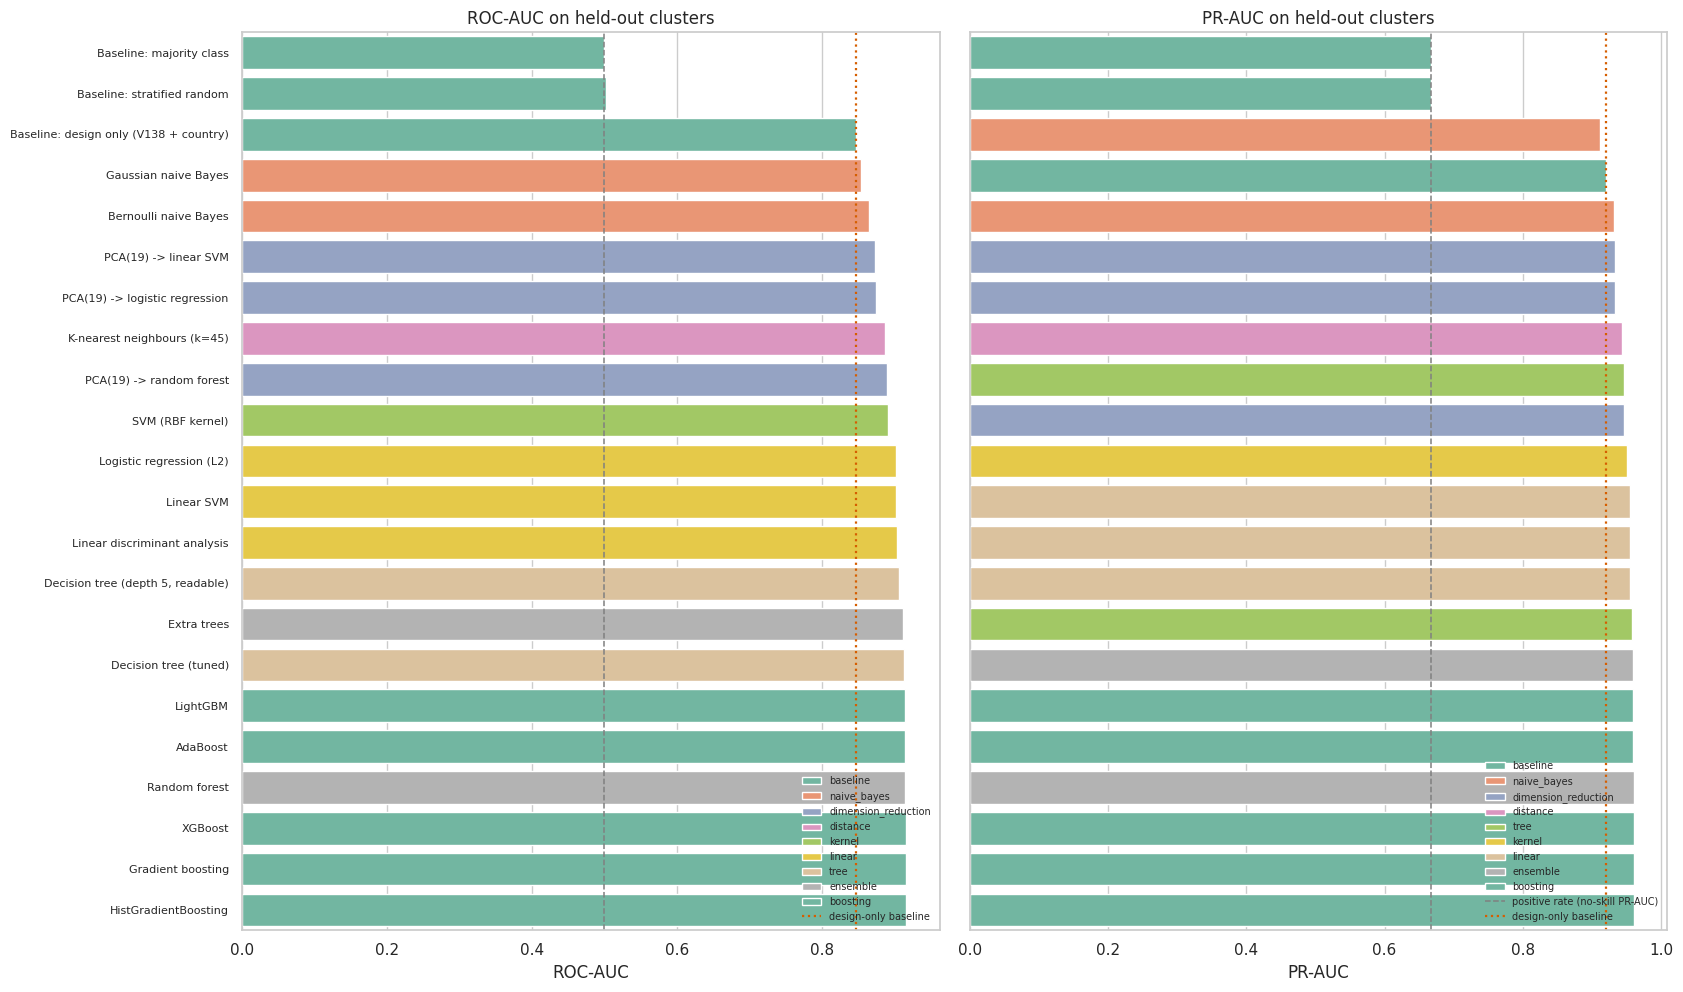

15603

In [49]:
# ================================================================================================
# RECODE SOURCE
#   * Individual Recode (IR) - XXIRnnFL - one record per interviewed woman 15-49
# WHAT THIS CELL USES: the train/test split of 19a. Fits every learner and scores it on the holdout.
# ================================================================================================
# 19b. Train every model and build the comparison table

def fit_and_score(spec, train, test, target=TARGET, label_prefix=""):
    """Fit one zoo entry on `train`, score it on `test`, and return the metric row + fitted objects."""
    tr = subsample(train, KERNEL_SAMPLE_MAX) if spec["kernel"] else train
    pre = build_preprocessor(spec["numeric"], spec["categorical"], scale=spec["scale"])
    Xtr = pre.fit_transform(tr)
    Xte = pre.transform(test)
    ytr = tr[target].to_numpy()
    yte = test[target].to_numpy()

    estimator = clone(spec["estimator"])
    t0 = time.perf_counter()
    estimator.fit(Xtr, ytr)
    fit_seconds = time.perf_counter() - t0

    y_pred = estimator.predict(Xte)
    y_score = positive_scores(estimator, Xte)
    row = {"model": label_prefix + spec["name"], "family": spec["family"],
           "n_train": len(tr), "n_test": len(test),
           "n_features_in": Xtr.shape[1], "fit_seconds": fit_seconds}
    row.update(score_binary(yte, y_pred, y_score))
    return row, estimator, pre, y_score, y_pred


results, fitted_models, fitted_preprocessors, holdout_scores = [], {}, {}, {}
print(f"Training {len(MODEL_ZOO)} models on {len(train_df):,} women "
      f"({len(ALL_NUMERIC)} numeric + {len(ALL_CATEGORICAL)} categorical features)\n")
for spec in MODEL_ZOO:
    try:
        row, estimator, pre, y_score, y_pred = fit_and_score(spec, train_df, test_df)
        results.append(row)
        fitted_models[spec["name"]] = estimator
        fitted_preprocessors[spec["name"]] = pre
        holdout_scores[spec["name"]] = (y_score, y_pred)
        print(f"  {spec['name']:<44s} ROC-AUC {row['roc_auc']:.4f}  PR-AUC {row['pr_auc']:.4f}  "
              f"F1 {row['f1']:.3f}  ({row['fit_seconds']:.1f}s on {row['n_train']:,} rows)")
    except Exception as exc:                                   # noqa: BLE001 - report, do not abort
        print(f"  {spec['name']:<44s} FAILED: {type(exc).__name__}: {exc}")
        results.append({"model": spec["name"], "family": spec["family"], "n_train": np.nan,
                        "n_test": len(test_df), "n_features_in": np.nan, "fit_seconds": np.nan,
                        "roc_auc": np.nan, "pr_auc": np.nan, "f1": np.nan,
                        "error": f"{type(exc).__name__}: {exc}"})

model_results = (pd.DataFrame(results)
                 .sort_values("pr_auc", ascending=False, na_position="last")
                 .reset_index(drop=True))
METRIC_COLS = ["roc_auc", "pr_auc", "f1", "balanced_accuracy", "precision", "recall",
               "accuracy", "brier"]
display(Markdown(f"### Model comparison on the held-out clusters "
                 f"(target = `{TARGET}`, {len(test_df):,} women, "
                 f"{100 * test_df[TARGET].mean():.2f}% positive)"))
display(model_results[["model", "family"] + METRIC_COLS + ["n_train", "n_features_in",
                                                           "fit_seconds"]]
        .style.format({**{c: "{:.4f}" for c in METRIC_COLS},
                       "n_train": "{:,.0f}", "n_features_in": "{:,.0f}", "fit_seconds": "{:.1f}"},
                      na_rep="-")
        .background_gradient(subset=["roc_auc", "pr_auc"], cmap="Greens"))
model_results.to_csv(OUTPUT_DIR / "model_comparison_y_selected.csv", index=False)

if "error" in model_results.columns and model_results.error.notna().any():
    display(Markdown("### Models that failed (reported, not hidden)"))
    display(model_results.loc[model_results.error.notna(), ["model", "error"]])

BEST_MODEL_NAME = model_results.loc[model_results.pr_auc.idxmax(), "model"]
BEST_MODEL = fitted_models[BEST_MODEL_NAME]
BEST_PREPROCESSOR = fitted_preprocessors[BEST_MODEL_NAME]
DESIGN_BASELINE_NAME = "Baseline: design only (V138 + country)"
design_pr = model_results.loc[model_results.model.eq(DESIGN_BASELINE_NAME), "pr_auc"]
design_roc = model_results.loc[model_results.model.eq(DESIGN_BASELINE_NAME), "roc_auc"]
print(f"\nBest model by PR-AUC: {BEST_MODEL_NAME}")
if len(design_pr):
    best = model_results.loc[model_results.pr_auc.idxmax()]
    print(f"  design-only baseline : ROC-AUC {design_roc.iloc[0]:.4f}  PR-AUC {design_pr.iloc[0]:.4f}")
    print(f"  best full model      : ROC-AUC {best.roc_auc:.4f}  PR-AUC {best.pr_auc:.4f}")
    print(f"  gain from the whole profile space: "
          f"ROC-AUC {best.roc_auc - design_roc.iloc[0]:+.4f}, "
          f"PR-AUC {best.pr_auc - design_pr.iloc[0]:+.4f}")

# --- family-level view -----------------------------------------------------------------------------
plot_results = model_results[model_results.pr_auc.notna()]
fig, axes = plt.subplots(1, 2, figsize=(17, 0.34 * len(plot_results) + 2.6))
sns.barplot(data=plot_results.sort_values("roc_auc"), y="model", x="roc_auc", hue="family",
            ax=axes[0], dodge=False, palette="Set2")
axes[0].axvline(0.5, color="grey", linestyle="--", linewidth=1.1)
if len(design_roc):
    axes[0].axvline(design_roc.iloc[0], color=PALETTE[3], linestyle=":", linewidth=1.6,
                    label="design-only baseline")
axes[0].set_title("ROC-AUC on held-out clusters"); axes[0].set_xlabel("ROC-AUC")
axes[0].set_ylabel(""); axes[0].tick_params(axis="y", labelsize=8)
axes[0].legend(fontsize=7, frameon=False, loc="lower right")
sns.barplot(data=plot_results.sort_values("pr_auc"), y="model", x="pr_auc", hue="family",
            ax=axes[1], dodge=False, palette="Set2")
axes[1].axvline(test_df[TARGET].mean(), color="grey", linestyle="--", linewidth=1.1,
                label="positive rate (no-skill PR-AUC)")
if len(design_pr):
    axes[1].axvline(design_pr.iloc[0], color=PALETTE[3], linestyle=":", linewidth=1.6,
                    label="design-only baseline")
axes[1].set_title("PR-AUC on held-out clusters"); axes[1].set_xlabel("PR-AUC")
axes[1].set_ylabel(""); axes[1].set_yticklabels([])
axes[1].legend(fontsize=7, frameon=False, loc="lower right")
plt.tight_layout(); plt.show()
gc.collect()

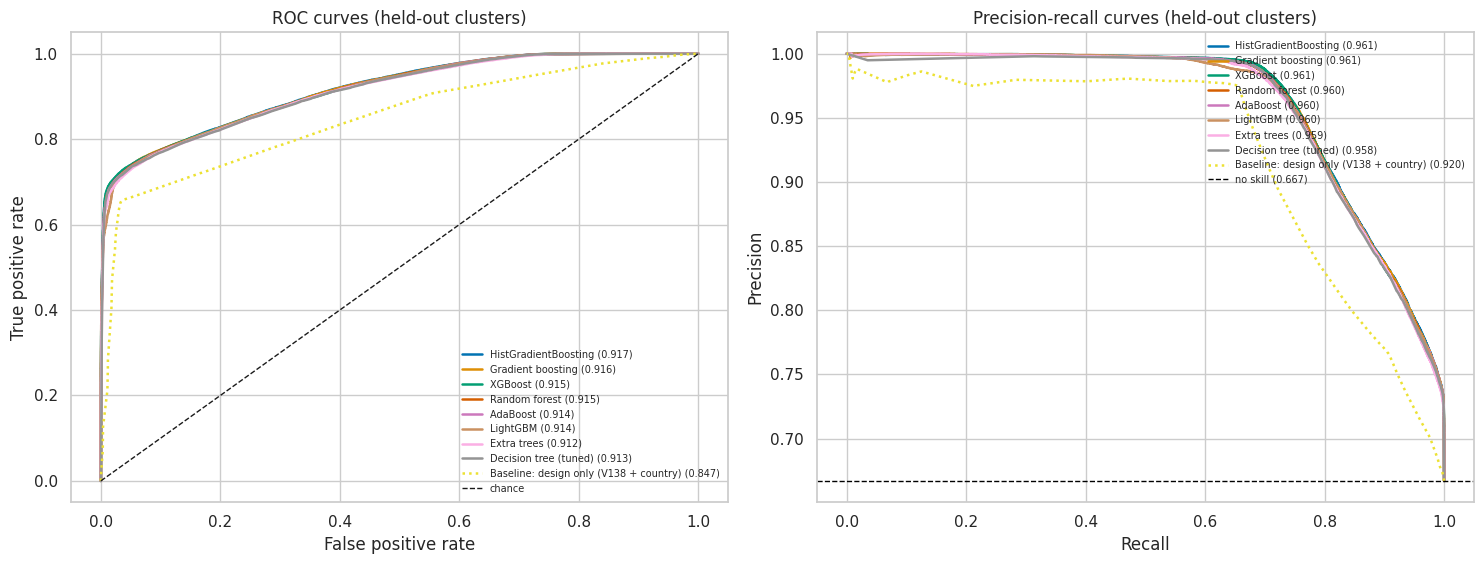

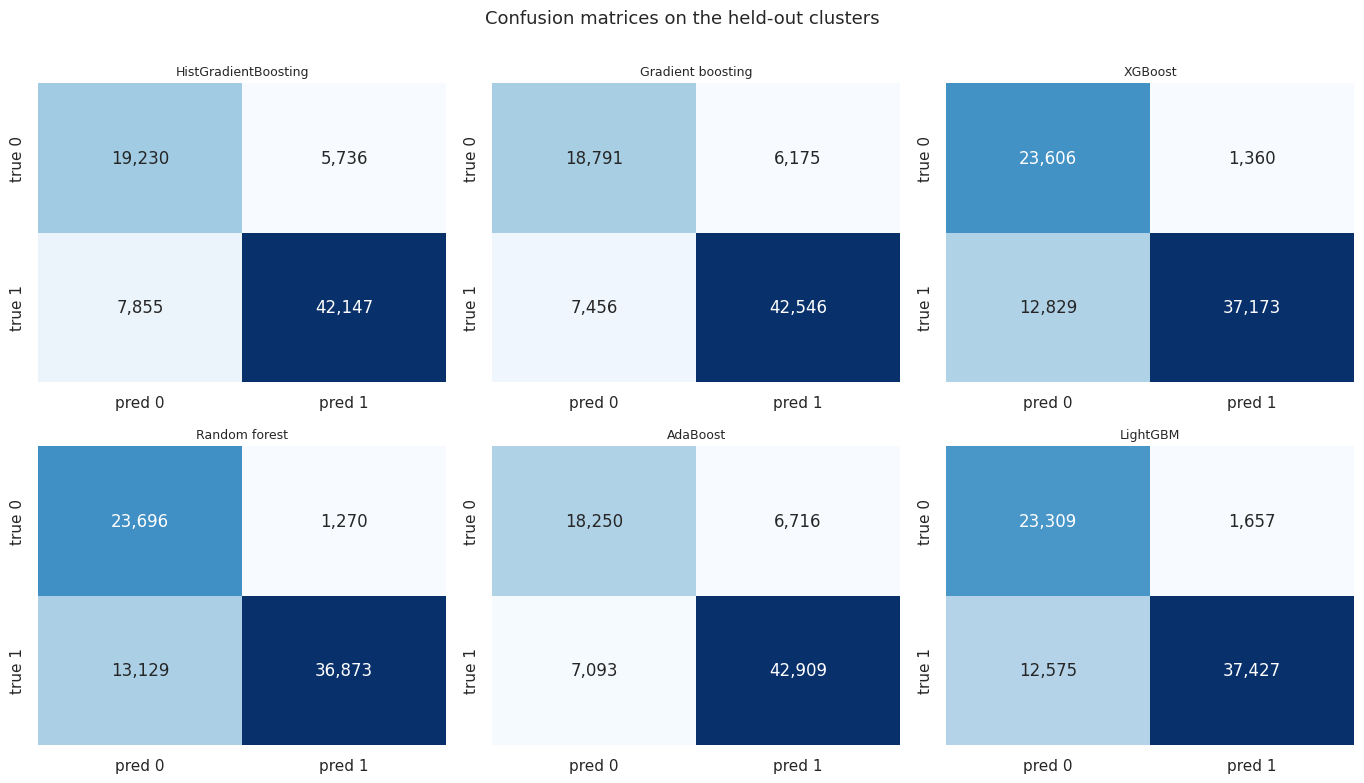

### Confusion-matrix breakdown

,model,true_negative,false_positive,false_negative,true_positive,specificity,sensitivity
0,HistGradientBoosting,"19,230","5,736","7,855","42,147",0.770,0.843
1,Gradient boosting,"18,791","6,175","7,456","42,546",0.753,0.851
2,XGBoost,"23,606","1,360","12,829","37,173",0.946,0.743
3,Random forest,"23,696","1,270","13,129","36,873",0.949,0.737
4,AdaBoost,"18,250","6,716","7,093","42,909",0.731,0.858
5,LightGBM,"23,309","1,657","12,575","37,427",0.934,0.749


### Classification report — HistGradientBoosting

              precision    recall  f1-score   support

not selected     0.7100    0.7702    0.7389     24966
    selected     0.8802    0.8429    0.8612     50002

    accuracy                         0.8187     74968
   macro avg     0.7951    0.8066    0.8000     74968
weighted avg     0.8235    0.8187    0.8204     74968



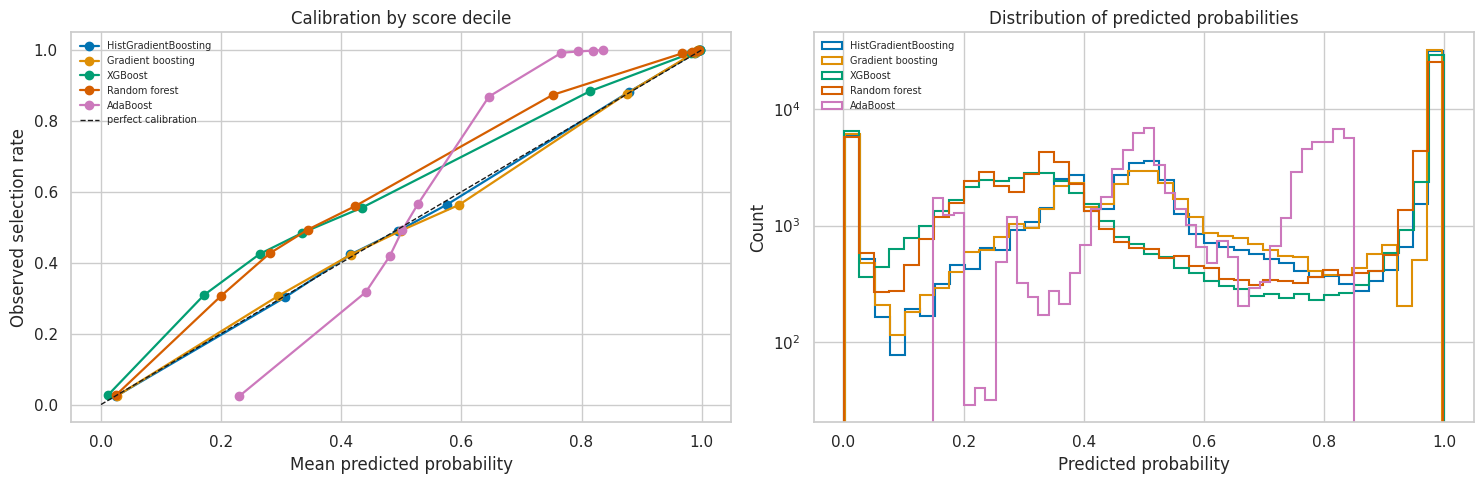

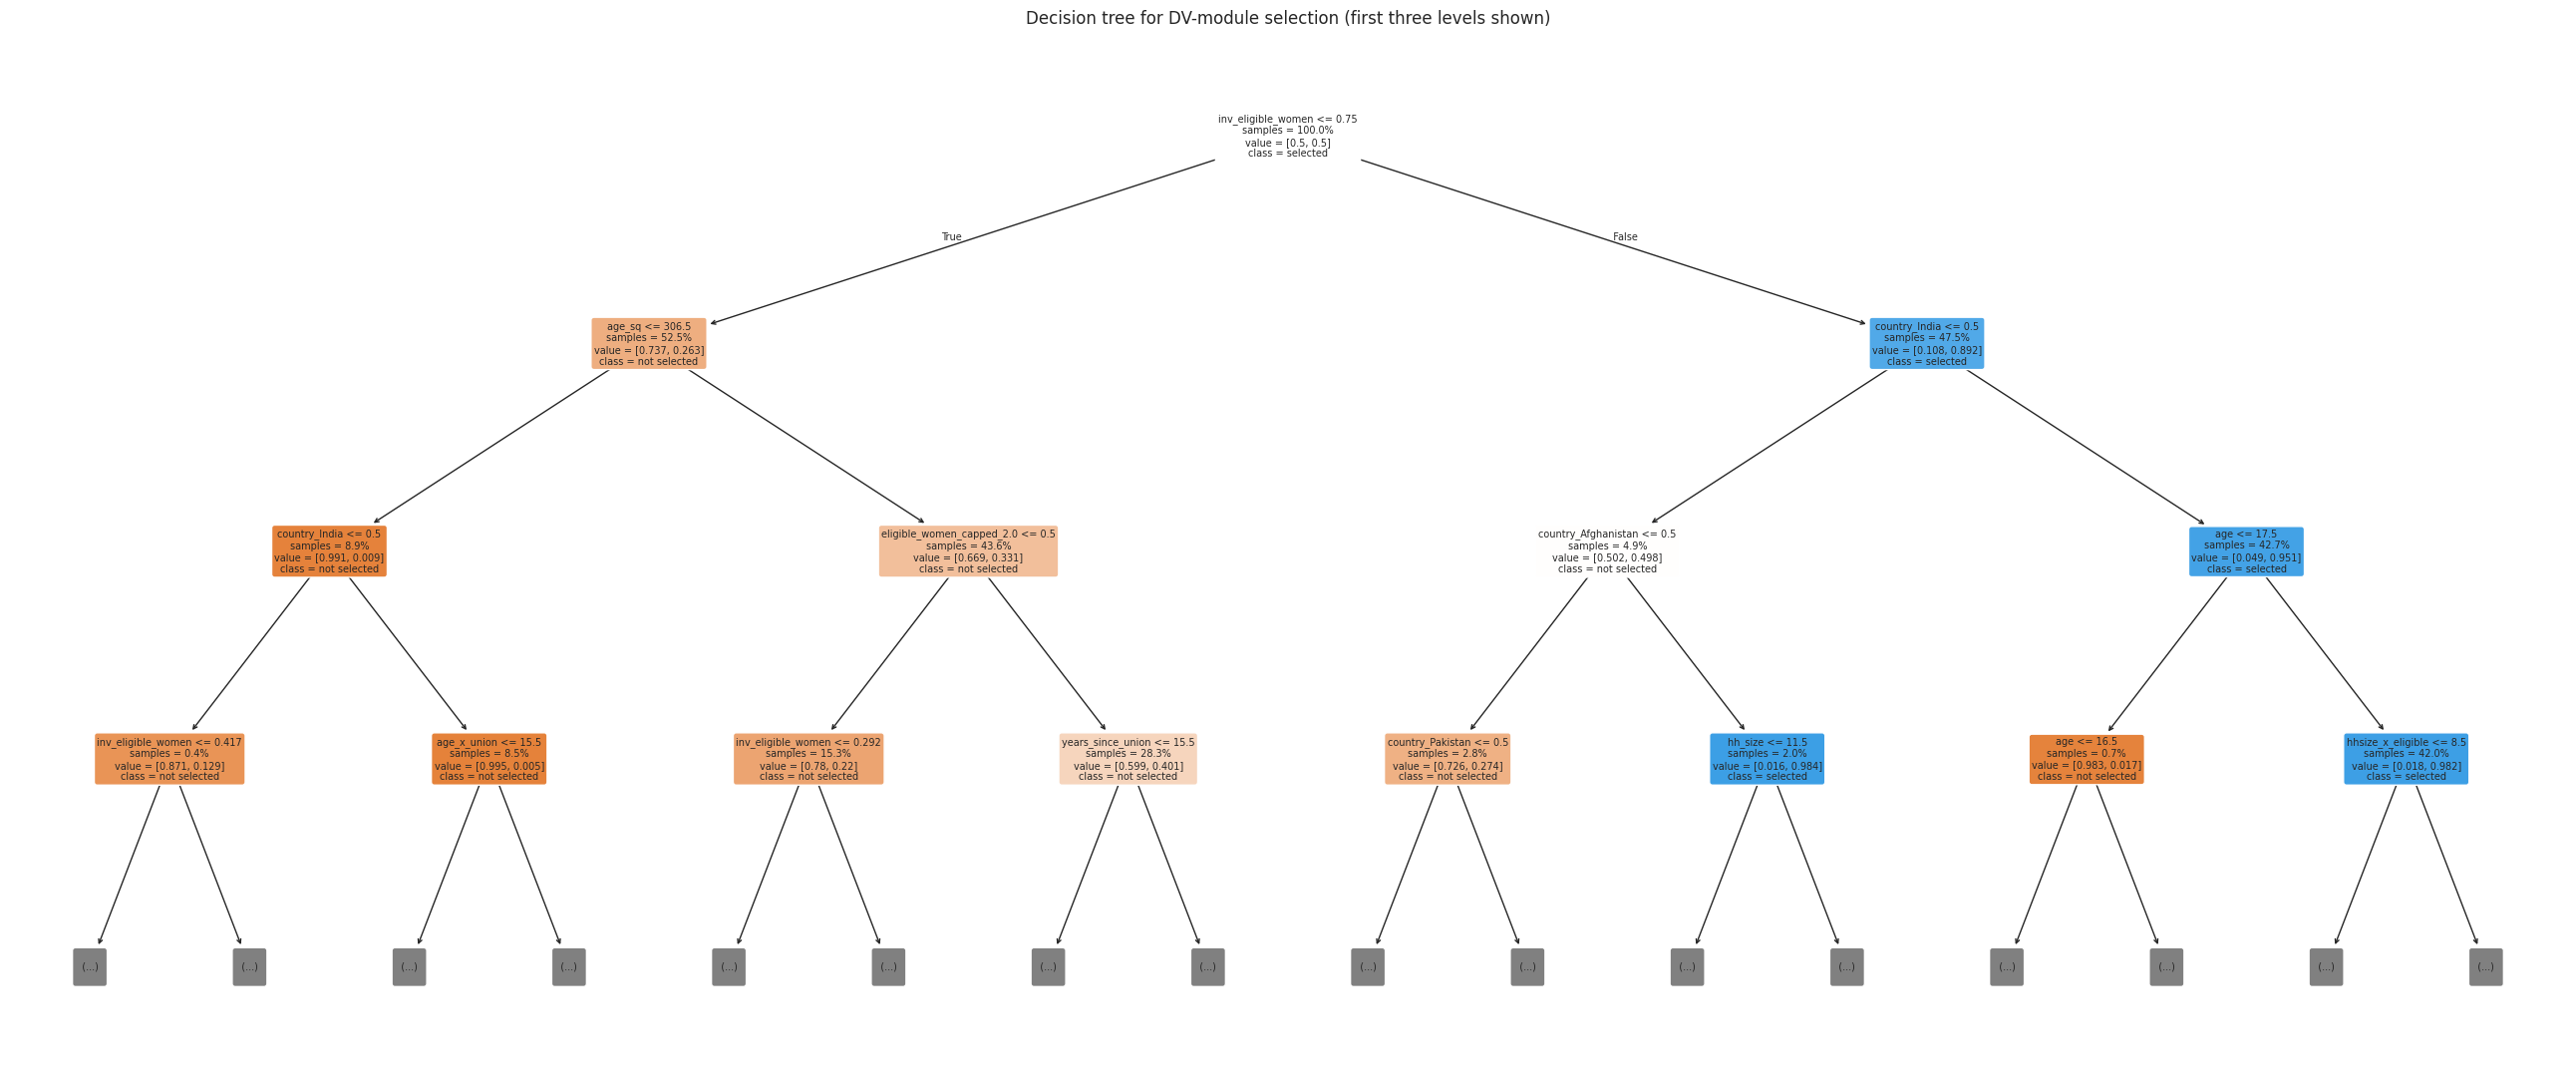

The root split is almost always on the number of eligible women in the household. That is the sampling design speaking, and it is the reason §20 measures profile contribution as a **gain over** the design-only model.

39410

In [50]:
# ================================================================================================
# RECODE SOURCE
#   * Individual Recode (IR) - XXIRnnFL - one record per interviewed woman 15-49
# WHAT THIS CELL USES: the fitted models and holdout scores of 19b.
# ================================================================================================
# 19c. ROC curves, precision-recall curves, confusion matrices and calibration

TOP_N_CURVES = 8
curve_models = (model_results[model_results.pr_auc.notna() &
                              model_results.model.isin(holdout_scores)]
                .nlargest(TOP_N_CURVES, "pr_auc").model.tolist())
if DESIGN_BASELINE_NAME in holdout_scores and DESIGN_BASELINE_NAME not in curve_models:
    curve_models.append(DESIGN_BASELINE_NAME)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
for i, name in enumerate(curve_models):
    y_score, _ = holdout_scores[name]
    fpr, tpr, _ = roc_curve(y_test, y_score)
    auc = model_results.loc[model_results.model.eq(name), "roc_auc"].iloc[0]
    style = ":" if name == DESIGN_BASELINE_NAME else "-"
    axes[0].plot(fpr, tpr, style, linewidth=1.8, color=PALETTE[i % len(PALETTE)],
                 label=f"{name} ({auc:.3f})")
    precision, recall, _ = precision_recall_curve(y_test, y_score)
    ap = model_results.loc[model_results.model.eq(name), "pr_auc"].iloc[0]
    axes[1].plot(recall, precision, style, linewidth=1.8, color=PALETTE[i % len(PALETTE)],
                 label=f"{name} ({ap:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", linewidth=1.0, label="chance")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curves (held-out clusters)")
axes[0].legend(fontsize=7, frameon=False, loc="lower right")
axes[1].axhline(y_test.mean(), color="black", linestyle="--", linewidth=1.0,
                label=f"no skill ({y_test.mean():.3f})")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall curves (held-out clusters)")
axes[1].legend(fontsize=7, frameon=False, loc="upper right")
plt.tight_layout(); plt.show()

# --- confusion matrices -----------------------------------------------------------------------------
CONFUSION_MODELS = [n for n in curve_models[:6]]
ncols = 3
nrows = int(np.ceil(len(CONFUSION_MODELS) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.6 * ncols, 3.9 * nrows))
axes = np.atleast_1d(axes).ravel()
confusion_rows = []
for ax, name in zip(axes, CONFUSION_MODELS):
    _, y_pred = holdout_scores[name]
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["pred 0", "pred 1"], yticklabels=["true 0", "true 1"])
    ax.set_title(name, fontsize=9)
    tn, fp, fn, tp = cm.ravel()
    confusion_rows.append({"model": name, "true_negative": tn, "false_positive": fp,
                           "false_negative": fn, "true_positive": tp,
                           "specificity": tn / (tn + fp) if (tn + fp) else np.nan,
                           "sensitivity": tp / (tp + fn) if (tp + fn) else np.nan})
for ax in axes[len(CONFUSION_MODELS):]:
    ax.axis("off")
fig.suptitle("Confusion matrices on the held-out clusters", y=1.002, fontsize=13)
plt.tight_layout(); plt.show()
confusion_table = pd.DataFrame(confusion_rows)
display(Markdown("### Confusion-matrix breakdown"))
display(confusion_table.style.format({
    "true_negative": "{:,.0f}", "false_positive": "{:,.0f}", "false_negative": "{:,.0f}",
    "true_positive": "{:,.0f}", "specificity": "{:.3f}", "sensitivity": "{:.3f}"}))
confusion_table.to_csv(OUTPUT_DIR / "model_confusion_matrices.csv", index=False)

display(Markdown(f"### Classification report — {BEST_MODEL_NAME}"))
print(classification_report(y_test, holdout_scores[BEST_MODEL_NAME][1],
                            target_names=["not selected", "selected"], digits=4, zero_division=0))

# --- calibration: does the predicted probability match the observed rate? --------------------------
prob_models = [n for n in curve_models
               if hasattr(fitted_models.get(n), "predict_proba")][:5]
if prob_models:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.0))
    calibration_rows = []
    for i, name in enumerate(prob_models):
        y_score, _ = holdout_scores[name]
        bins = pd.qcut(pd.Series(y_score), q=10, duplicates="drop", labels=False)
        table = (pd.DataFrame({"bin": bins, "score": y_score, "y": y_test})
                 .groupby("bin", observed=True)
                 .agg(mean_predicted=("score", "mean"), observed=("y", "mean"), n=("y", "size")))
        axes[0].plot(table.mean_predicted, table.observed, marker="o", linewidth=1.6,
                     color=PALETTE[i % len(PALETTE)], label=name)
        for _, r in table.iterrows():
            calibration_rows.append({"model": name, "mean_predicted": r.mean_predicted,
                                     "observed": r.observed, "n": int(r.n)})
        axes[1].hist(y_score, bins=40, histtype="step", linewidth=1.5,
                     color=PALETTE[i % len(PALETTE)], label=name)
    lims = [0, max(0.05, float(np.max([holdout_scores[n][0].max() for n in prob_models])))]
    axes[0].plot(lims, lims, "k--", linewidth=1.0, label="perfect calibration")
    axes[0].set_xlabel("Mean predicted probability"); axes[0].set_ylabel("Observed selection rate")
    axes[0].set_title("Calibration by score decile")
    axes[0].legend(fontsize=7, frameon=False)
    axes[1].set_xlabel("Predicted probability"); axes[1].set_ylabel("Count")
    axes[1].set_yscale("log"); axes[1].set_title("Distribution of predicted probabilities")
    axes[1].legend(fontsize=7, frameon=False)
    plt.tight_layout(); plt.show()
    pd.DataFrame(calibration_rows).to_csv(OUTPUT_DIR / "model_calibration.csv", index=False)

# --- the readable decision tree ---------------------------------------------------------------------
READABLE_TREE = "Decision tree (depth 5, readable)"
if READABLE_TREE in fitted_models:
    tree_features = expanded_feature_names(fitted_preprocessors[READABLE_TREE])
    plt.figure(figsize=(26, 11))
    plot_tree(fitted_models[READABLE_TREE], feature_names=tree_features,
              class_names=["not selected", "selected"], filled=True, rounded=True,
              max_depth=3, fontsize=7, proportion=True, impurity=False)
    plt.title("Decision tree for DV-module selection (first three levels shown)")
    plt.tight_layout(); plt.show()
    display(Markdown("The root split is almost always on the number of eligible women in the "
                     "household. That is the sampling design speaking, and it is the reason §20 "
                     "measures profile contribution as a **gain over** the design-only model."))
gc.collect()

## 20. Which feature blocks actually carry information? Nested design-vs-profile models

The previous section shows that a full model beats chance. That alone is not an answer to the research
question, because `V044` is a **sampling flag** whose value is largely determined by the design
identity

$$P(\text{woman selected}) \;=\; P(\text{household in the DV sub-sample}) \times \frac{1}{V138}$$

where `V138` is the number of eligible women in the household. A model given `V138` will score well
without learning anything about *profiles*. So the question has to be posed as a **nested comparison**:

> Once the design (`V138`) and the country are already in the model, does adding the woman's
> demographic block, the household's socioeconomic block, her agency block, her normative block, or
> the explicit interaction block move ROC-AUC and PR-AUC at all?

### The ladder

| Step | Features added | What a gain at this step would mean |
|---|---|---|
| 1 | `design` — `n_eligible_women`, `inv_eligible_women`, `single_eligible_woman` | The mechanical selection rule. Not a finding; the reference point. |
| 2 | `+ country` | Countries ran the module with different sub-sample fractions and coverage. |
| 3 | `+ woman` | Age, education, marital status, parity, work — the individual profile. |
| 4 | `+ household` | Wealth, assets, dwelling, crowding, headship, residence — the household profile. |
| 5 | `+ agency` | Decision-making, ownership, healthcare access, empowerment index. |
| 6 | `+ norms` | Attitudes justifying wife-beating, media exposure. |
| 7 | `+ interaction` | The 16 engineered products/ratios from §17a (wealth × education, urban × education, `V138` × wealth, …). |

Each step is trained on the **same clusters**, scored on the **same held-out clusters**, and uses the
**same learner**, so the only thing that changes is the feature set. The reported quantity is the
increment, ΔROC-AUC and ΔPR-AUC, over the step above it.

### Two learners, on purpose

* **Gradient-boosted trees** (HistGradientBoosting, and LightGBM when available) — can find
  interactions on their own, so a gain at step 7 tells us the *engineered* interactions add
  something a tree could not already recover.
* **Logistic regression** — additive by construction, so it is the honest test of whether the
  engineered interaction terms carry signal. Its coefficients are read as odds ratios in §20b.

### Interpretation guard

A ΔROC-AUC of, say, +0.004 from the whole profile space is a *substantive result*: it says the DHS
sub-sample is close to design-conditionally random with respect to who women are, which is exactly
what a valid probability sample should look like. A large gain would be the alarming outcome, not the
successful one. Both directions are reported plainly.

### Feature blocks entering the ladder

,block,n_features,features
0,design,7,"n_eligible_women, inv_eligible_women, single_eligible_woman, eligible_women_capped, hh_size, n_children_under5, crowding"
1,country,3,"survey_year, country, region_key"
2,woman,27,"age, age_sq, age_group, adolescent, edu_level, edu_years, edu_attainment, no_education, secondary_or_higher, marital_status, in_union, ever_married, never_married, married_more_than_once, polygynous_union, age_at_cohabitation, child_marriage, years_since_union, children_ever_born, living_children, currently_pregnant, age_at_first_birth, early_first_birth, recent_birth, nulliparous, uses_contraception, uses_modern_method"
3,household,15,"urban, wealth_quintile, wealth_score, asset_count, asset_index, improved_water, improved_toilet, open_defecation, clean_cooking_fuel, dwelling_quality, water_time_min, water_on_premises, female_head, head_age, is_head_or_spouse"
4,agency,7,"healthcare_barrier_index, health_insurance, reads_newspaper, listens_radio, watches_tv, media_index, heard_fp_media"
5,norms,0,
6,interaction,10,"wealth_x_education, urban_x_education, urban_x_wealth, age_x_union, age_x_education, eligible_x_wealth, eligible_x_urban, eligible_x_education, hhsize_x_eligible, femalehead_x_wealth"



HistGradientBoosting
  step 1  +design       ROC-AUC 0.8287  PR-AUC 0.8986  (7 features, 1.4s)
  step 2  +country      ROC-AUC 0.8516  PR-AUC 0.9250  (10 features, 8.6s)
  step 3  +woman        ROC-AUC 0.9161  PR-AUC 0.9609  (37 features, 18.0s)
  step 4  +household    ROC-AUC 0.9166  PR-AUC 0.9611  (52 features, 18.7s)
  step 5  +agency       ROC-AUC 0.9167  PR-AUC 0.9612  (59 features, 17.2s)
  step 6  +norms        ROC-AUC 0.9167  PR-AUC 0.9612  (59 features, 17.3s)
  step 7  +interaction  ROC-AUC 0.9165  PR-AUC 0.9611  (69 features, 21.6s)

Logistic regression
  step 1  +design       ROC-AUC 0.8264  PR-AUC 0.8962  (7 features, 0.4s)
  step 2  +country      ROC-AUC 0.8479  PR-AUC 0.9242  (10 features, 3.1s)
  step 3  +woman        ROC-AUC 0.9013  PR-AUC 0.9541  (37 features, 11.3s)
  step 4  +household    ROC-AUC 0.9020  PR-AUC 0.9546  (52 features, 12.4s)
  step 5  +agency       ROC-AUC 0.9021  PR-AUC 0.9546  (59 features, 11.9s)
  step 6  +norms        ROC-AUC 0.9021  PR-AUC 0.95

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  step 1  +design       ROC-AUC 0.8285  PR-AUC 0.9003  (7 features, 4.0s)


...

  step 6  +norms        ROC-AUC 0.9139  PR-AUC 0.9594  (59 features, 6.8s)


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  step 7  +interaction  ROC-AUC 0.9144  PR-AUC 0.9599  (69 features, 7.5s)


### The ladder — each row adds one block to the row above it (same clusters, same learner)

,learner,step,block_added,n_features_cumulative,roc_auc,delta_roc_auc,roc_auc_vs_design,pr_auc,delta_pr_auc,pr_auc_vs_design,f1,balanced_accuracy
0,HistGradientBoosting,1,design,7,0.8287,reference,+0.0000,0.8986,reference,+0.0000,0.7860,0.7939
1,HistGradientBoosting,2,country,10,0.8516,+0.0230,+0.0230,0.9250,+0.0264,+0.0264,0.7863,0.8070
2,HistGradientBoosting,3,woman,37,0.9161,+0.0645,+0.0875,0.9609,+0.0359,+0.0623,0.8605,0.8051
3,HistGradientBoosting,4,household,52,0.9166,+0.0005,+0.0880,0.9611,+0.0002,+0.0625,0.8619,0.8055
4,HistGradientBoosting,5,agency,59,0.9167,+0.0001,+0.0881,0.9612,+0.0001,+0.0625,0.8622,0.8056
5,HistGradientBoosting,6,norms,59,0.9167,+0.0000,+0.0881,0.9612,+0.0000,+0.0625,0.8622,0.8056
6,HistGradientBoosting,7,interaction,69,0.9165,-0.0002,+0.0879,0.9611,-0.0001,+0.0625,0.8614,0.8061
7,Logistic regression,1,design,7,0.8264,reference,+0.0000,0.8962,reference,+0.0000,0.7860,0.7940
8,Logistic regression,2,country,10,0.8479,+0.0216,+0.0216,0.9242,+0.0280,+0.0280,0.7849,0.8099
9,Logistic regression,3,woman,37,0.9013,+0.0534,+0.0750,0.9541,+0.0300,+0.0580,0.8396,0.8212


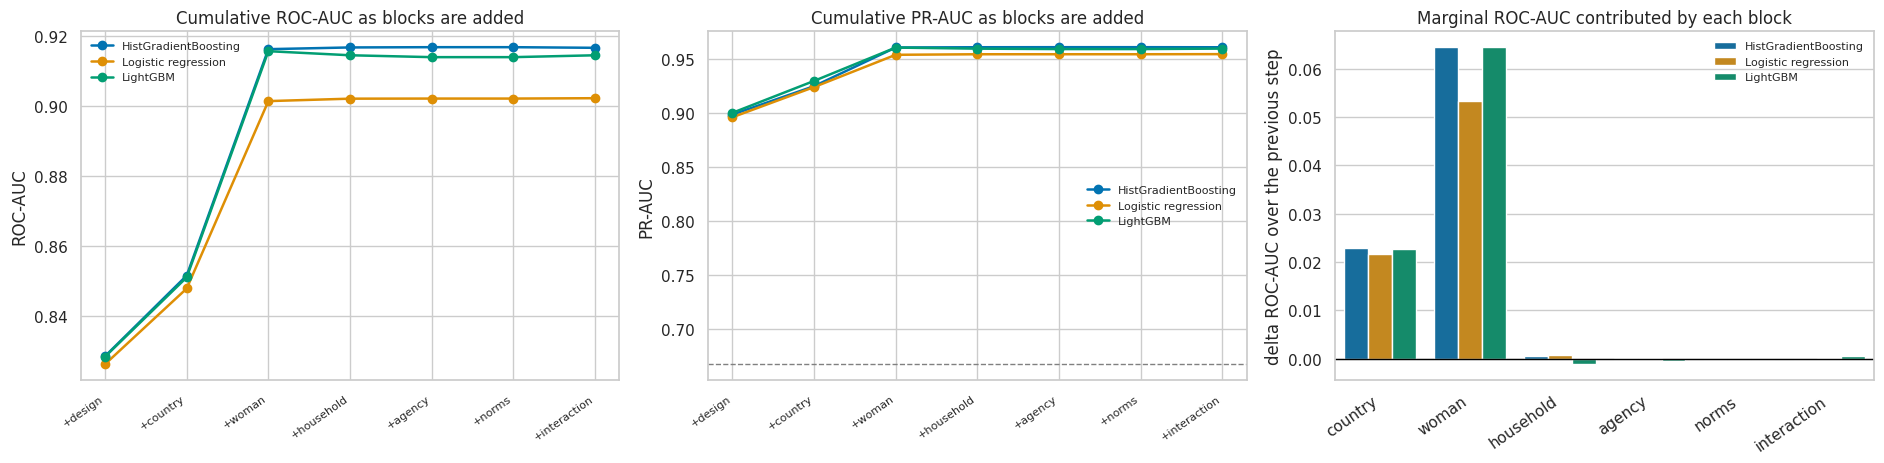

### Verdict: how much do profiles add once the design and country are known?

,learner,design_only_roc,design_plus_country_roc,full_model_roc,profile_gain_roc,design_plus_country_pr,full_model_pr,profile_gain_pr
0,HistGradientBoosting,0.8287,0.8516,0.9165,0.0649,0.9250,0.9611,0.0361
1,Logistic regression,0.8264,0.8479,0.9022,0.0542,0.9242,0.9547,0.0306
2,LightGBM,0.8285,0.8511,0.9144,0.0633,0.9299,0.9599,0.0300


**Mean profile gain in ROC-AUC across learners: +0.0608.** Profiles add a measurable amount over design + country. That is a differential-coverage signal: some kinds of women and households were more likely to end up in the DV sub-sample than the one-woman-per-household rule alone implies, and the block-level and feature-level attributions below say which kinds.

28715

In [51]:
# ================================================================================================
# RECODE SOURCE
#   * Individual Recode (IR) - XXIRnnFL - one record per interviewed woman 15-49
# WHAT THIS CELL USES: the same train/test clusters as 19a-19b, with the feature set grown one block
#                      at a time. Only the columns change between steps.
# ================================================================================================
# 20a. Nested feature-block models: what does each block add over the sampling design?

BLOCK_LADDER = ["design", "country", "woman", "household", "agency", "norms", "interaction"]

# The screen in 17a may have dropped columns, so resolve each block against what actually survived.
BLOCK_MEMBERS = {}
for block in BLOCK_LADDER:
    members = [f for f in FEATURE_BLOCKS.get(block, []) if f in ML_FEATURES]
    if block == "country":
        members = members + [c for c in ("country", "region_key") if c in ML_FEATURES]
    BLOCK_MEMBERS[block] = list(dict.fromkeys(members))

block_inventory = pd.DataFrame({
    "block": BLOCK_LADDER,
    "n_features": [len(BLOCK_MEMBERS[b]) for b in BLOCK_LADDER],
    "features": [", ".join(BLOCK_MEMBERS[b]) for b in BLOCK_LADDER],
})
display(Markdown("### Feature blocks entering the ladder"))
display(block_inventory.style.set_properties(subset=["features"], **{"white-space": "normal",
                                                                    "font-size": "8pt"}))

LADDER_LEARNERS = [
    ("HistGradientBoosting", HistGradientBoostingClassifier(
        max_iter=250, learning_rate=0.08, max_leaf_nodes=31, min_samples_leaf=40,
        l2_regularization=1.0, random_state=RANDOM_SEED), False),
    ("Logistic regression", LogisticRegression(
        max_iter=2000, C=1.0, class_weight="balanced", random_state=RANDOM_SEED), True),
]
if HAS_LIGHTGBM:
    LADDER_LEARNERS.append(("LightGBM", LGBMClassifier(
        n_estimators=400, learning_rate=0.06, num_leaves=63, min_child_samples=40,
        subsample=0.85, subsample_freq=1, colsample_bytree=0.85, reg_lambda=1.0,
        n_jobs=N_JOBS, random_state=RANDOM_SEED, verbose=-1), False))

ladder_rows = []
ladder_scores = {}
for learner_name, estimator, needs_scaling in LADDER_LEARNERS:
    print(f"\n{learner_name}")
    used_numeric, used_categorical = [], []
    for step, block in enumerate(BLOCK_LADDER, start=1):
        used_numeric += [f for f in BLOCK_MEMBERS[block] if f in NUMERIC_FEATURES]
        used_categorical += [f for f in BLOCK_MEMBERS[block] if f in MODEL_CATEGORICALS]
        used_numeric = list(dict.fromkeys(used_numeric))
        used_categorical = list(dict.fromkeys(used_categorical))
        if not used_numeric and not used_categorical:
            continue
        spec = {"name": f"{learner_name} | step {step}: +{block}", "estimator": estimator,
                "family": learner_name, "scale": needs_scaling, "kernel": False,
                "numeric": used_numeric, "categorical": used_categorical}
        try:
            row, _, _, y_score, _ = fit_and_score(spec, train_df, test_df)
        except Exception as exc:                                # noqa: BLE001 - report, do not abort
            print(f"  step {step:<2d} +{block:<12s} FAILED: {type(exc).__name__}: {exc}")
            continue
        row.update({"learner": learner_name, "step": step, "block_added": block,
                    "n_features_cumulative": len(used_numeric) + len(used_categorical)})
        ladder_rows.append(row)
        ladder_scores[(learner_name, block)] = y_score
        print(f"  step {step:<2d} +{block:<12s} ROC-AUC {row['roc_auc']:.4f}  "
              f"PR-AUC {row['pr_auc']:.4f}  ({row['n_features_cumulative']} features, "
              f"{row['fit_seconds']:.1f}s)")

ladder = pd.DataFrame(ladder_rows)
ladder["delta_roc_auc"] = ladder.groupby("learner")["roc_auc"].diff()
ladder["delta_pr_auc"] = ladder.groupby("learner")["pr_auc"].diff()
ladder["roc_auc_vs_design"] = ladder.roc_auc - ladder.groupby("learner")["roc_auc"].transform("first")
ladder["pr_auc_vs_design"] = ladder.pr_auc - ladder.groupby("learner")["pr_auc"].transform("first")

LADDER_COLS = ["learner", "step", "block_added", "n_features_cumulative", "roc_auc", "delta_roc_auc",
               "roc_auc_vs_design", "pr_auc", "delta_pr_auc", "pr_auc_vs_design", "f1",
               "balanced_accuracy"]
display(Markdown("### The ladder — each row adds one block to the row above it (same clusters, "
                 "same learner)"))
display(ladder[LADDER_COLS].style.format({
    "roc_auc": "{:.4f}", "pr_auc": "{:.4f}", "f1": "{:.4f}", "balanced_accuracy": "{:.4f}",
    "delta_roc_auc": "{:+.4f}", "delta_pr_auc": "{:+.4f}",
    "roc_auc_vs_design": "{:+.4f}", "pr_auc_vs_design": "{:+.4f}",
    "n_features_cumulative": "{:,.0f}"}, na_rep="reference")
    .background_gradient(subset=["delta_roc_auc", "delta_pr_auc"], cmap="RdYlGn", vmin=-0.02,
                         vmax=0.02))
ladder.to_csv(OUTPUT_DIR / "nested_block_ladder.csv", index=False)

# --- the ladder as a picture -----------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
for i, (learner, g) in enumerate(ladder.groupby("learner", sort=False)):
    axes[0].plot(g.step, g.roc_auc, marker="o", linewidth=1.8, color=PALETTE[i % len(PALETTE)],
                 label=learner)
    axes[1].plot(g.step, g.pr_auc, marker="o", linewidth=1.8, color=PALETTE[i % len(PALETTE)],
                 label=learner)
for ax, metric, title in ((axes[0], "ROC-AUC", "Cumulative ROC-AUC as blocks are added"),
                          (axes[1], "PR-AUC", "Cumulative PR-AUC as blocks are added")):
    ax.set_xticks(range(1, len(BLOCK_LADDER) + 1))
    ax.set_xticklabels([f"+{b}" for b in BLOCK_LADDER], rotation=35, ha="right", fontsize=8)
    ax.set_ylabel(metric); ax.set_xlabel(""); ax.set_title(title)
    ax.legend(fontsize=8, frameon=False)
axes[1].axhline(test_df[TARGET].mean(), color="grey", linestyle="--", linewidth=1.0)

waterfall = ladder[ladder.step.gt(1)]
sns.barplot(data=waterfall, x="block_added", y="delta_roc_auc", hue="learner", ax=axes[2],
            palette=PALETTE[:waterfall.learner.nunique()])
axes[2].axhline(0, color="black", linewidth=1.0)
axes[2].set_title("Marginal ROC-AUC contributed by each block")
axes[2].set_xlabel(""); axes[2].set_ylabel("delta ROC-AUC over the previous step")
axes[2].tick_params(axis="x", labelrotation=35)
for label in axes[2].get_xticklabels():
    label.set_ha("right")
axes[2].legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

# --- a one-line verdict per learner ----------------------------------------------------------------
display(Markdown("### Verdict: how much do profiles add once the design and country are known?"))
verdict_rows = []
for learner, g in ladder.groupby("learner", sort=False):
    g = g.set_index("block_added")
    base = g.loc["country"] if "country" in g.index else g.iloc[0]
    top = g.iloc[-1]
    verdict_rows.append({
        "learner": learner,
        "design_only_roc": g.iloc[0].roc_auc,
        "design_plus_country_roc": base.roc_auc,
        "full_model_roc": top.roc_auc,
        "profile_gain_roc": top.roc_auc - base.roc_auc,
        "design_plus_country_pr": base.pr_auc,
        "full_model_pr": top.pr_auc,
        "profile_gain_pr": top.pr_auc - base.pr_auc,
    })
verdict = pd.DataFrame(verdict_rows)
display(verdict.style.format({c: "{:.4f}" for c in verdict.columns if c != "learner"}))
verdict.to_csv(OUTPUT_DIR / "profile_gain_over_design.csv", index=False)

mean_gain = verdict.profile_gain_roc.mean()
if abs(mean_gain) < 0.01:
    reading = ("The whole profile space moves ROC-AUC by less than 0.01 over design + country. "
               "Read that as evidence that DHS sub-sample assignment is close to "
               "design-conditionally random with respect to who women are — the sample behaves as a "
               "probability sample should.")
elif mean_gain > 0:
    reading = ("Profiles add a measurable amount over design + country. That is a differential-"
               "coverage signal: some kinds of women and households were more likely to end up in "
               "the DV sub-sample than the one-woman-per-household rule alone implies, and the "
               "block-level and feature-level attributions below say which kinds.")
else:
    reading = ("Adding profile blocks does not improve, and may slightly degrade, held-out "
               "performance — the extra columns are noise relative to the design variables.")
display(Markdown(f"**Mean profile gain in ROC-AUC across learners: {mean_gain:+.4f}.** {reading}"))
gc.collect()

### Top 30 features by mean impurity importance across all tree/boosting models

,mean_importance,max_importance,n_models,block
feature,,,,
inv_eligible_women,0.2695,0.6837,8,design
single_eligible_woman,0.0878,0.2491,8,design
country,0.0831,0.1416,8,country
n_eligible_women,0.0780,0.2512,8,design
eligible_women_capped,0.0698,0.2192,8,design
age_sq,0.0537,0.1047,8,woman
age,0.0527,0.0887,8,woman
hhsize_x_eligible,0.0264,0.0851,8,interaction
years_since_union,0.0259,0.0551,8,woman


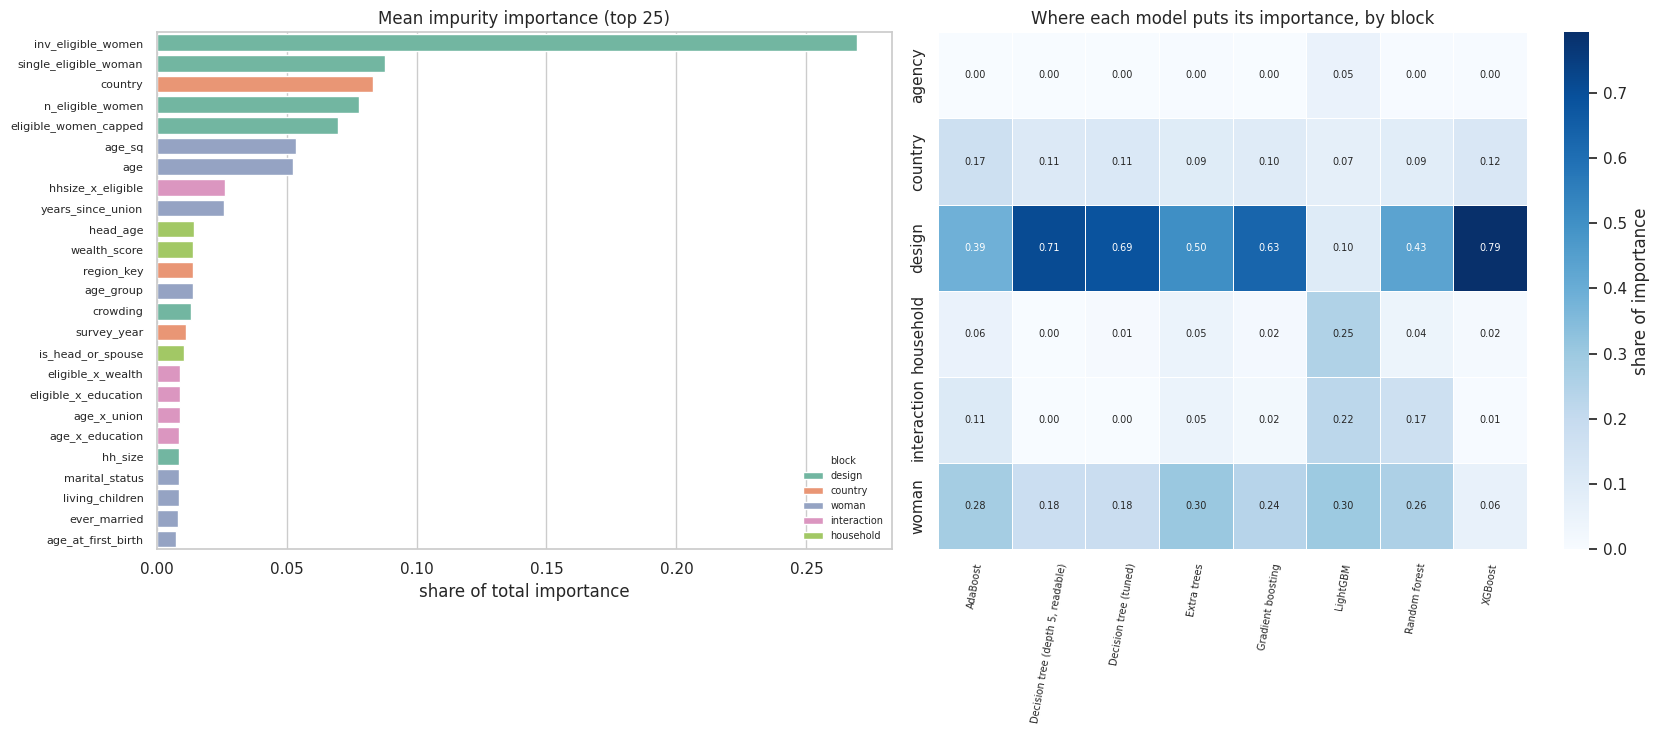

Permutation importance for 'HistGradientBoosting' on 40,141 held-out women x 199 expanded columns x 5 repeats


### Permutation importance — how much ROC-AUC is lost when one column is shuffled (HistGradientBoosting)

,expanded_feature,drop_in_roc_auc,std,feature,block
0,n_eligible_women,+0.09709,0.00130,n_eligible_women,design
7,age,+0.09133,0.00112,age,woman
62,country_India,+0.04209,0.00063,country,country
59,hhsize_x_eligible,+0.00511,0.00047,hhsize_x_eligible,interaction
6,survey_year,+0.00317,0.00010,survey_year,country
20,years_since_union,+0.00241,0.00011,years_since_union,woman
43,is_head_or_spouse,+0.00198,0.00025,is_head_or_spouse,household
3,hh_size,+0.00168,0.00007,hh_size,design
21,children_ever_born,+0.00129,0.00013,children_ever_born,woman
22,living_children,+0.00127,0.00022,living_children,woman


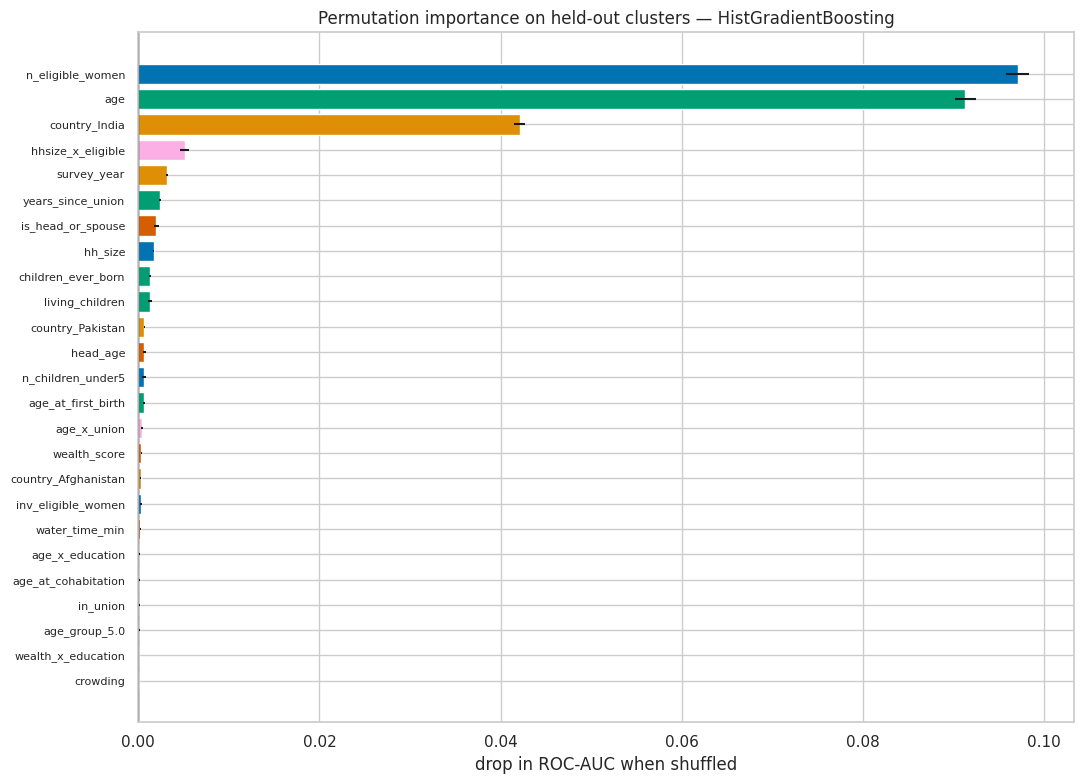

### Permutation importance aggregated to blocks

,total_drop,max_drop,n_columns
block,,,
design,+0.09972,+0.09709,11
woman,+0.09721,+0.09133,46
country,+0.04622,+0.04209,106
interaction,+0.00570,+0.00511,10
household,+0.00319,+0.00198,19
agency,+0.00010,+0.00003,7


### Logistic-regression odds ratios for DV-module selection
Numeric predictors are standardised, so each odds ratio is the multiplicative change in the odds of selection for a **one-standard-deviation** increase; one-hot columns are relative to the imputed reference category.

,expanded_feature,block,coefficient,odds_ratio_per_sd
7,age,woman,+7.4724,1758.756
8,age_sq,woman,-5.9743,0.003
62,country_India,country,+2.1329,8.439
65,country_Pakistan,country,-1.9746,0.139
61,country_Afghanistan,country,+1.7238,5.606
63,country_Myanmar,country,-1.5798,0.206
167,age_group_2.0,woman,+1.4115,4.102
171,age_group_6.0,woman,-0.8499,0.427
64,country_Nepal,country,-0.8309,0.436
2,single_eligible_woman,design,+0.6724,1.959


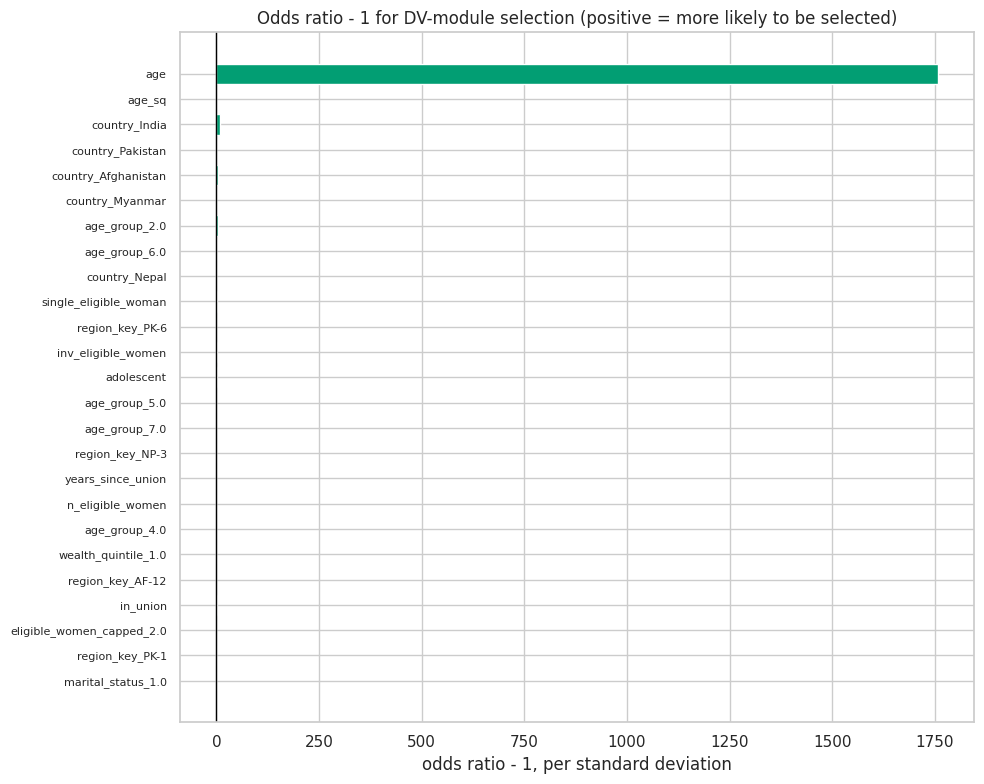

12728

In [52]:
# ================================================================================================
# RECODE SOURCE
#   * Individual Recode (IR) - XXIRnnFL - one record per interviewed woman 15-49
# WHAT THIS CELL USES: models fitted in 19b, scored for importance on the held-out clusters.
# ================================================================================================
# 20b. Feature-level attribution: impurity importance, permutation importance, odds ratios

PERM_SAMPLE_MAX = 40_000      # permutation importance is O(n_features x n_repeats) model calls
PERM_REPEATS = 5
BASE_FEATURES = NUMERIC_FEATURES + MODEL_CATEGORICALS


def base_feature_of(expanded_name):
    """Map a post-one-hot column name back to the model feature it came from."""
    if expanded_name in BASE_FEATURES:
        return expanded_name
    candidates = [f for f in BASE_FEATURES if expanded_name.startswith(f + "_")]
    return max(candidates, key=len) if candidates else expanded_name


def block_of(expanded_name):
    return BLOCK_OF_FEATURE.get(base_feature_of(expanded_name), "other")


# --- 1. built-in importances from every tree / boosting model that exposes them --------------------
importance_frames = []
for name, estimator in fitted_models.items():
    if not hasattr(estimator, "feature_importances_"):
        continue
    names = expanded_feature_names(fitted_preprocessors[name])
    values = np.asarray(estimator.feature_importances_, dtype=float)
    if len(names) != len(values):
        continue
    total = values.sum()
    importance_frames.append(pd.DataFrame({
        "model": name, "expanded_feature": names,
        "importance": values / total if total else values}))

if importance_frames:
    tree_importance = pd.concat(importance_frames, ignore_index=True)
    tree_importance["feature"] = tree_importance.expanded_feature.map(base_feature_of)
    tree_importance["block"] = tree_importance.expanded_feature.map(block_of)
    tree_importance.to_csv(OUTPUT_DIR / "model_impurity_importance.csv", index=False)

    by_feature = (tree_importance.groupby(["model", "feature"], as_index=False)["importance"].sum())
    mean_importance = (by_feature.groupby("feature")
                       .agg(mean_importance=("importance", "mean"),
                            max_importance=("importance", "max"),
                            n_models=("model", "nunique"))
                       .sort_values("mean_importance", ascending=False))
    mean_importance["block"] = mean_importance.index.map(lambda f: BLOCK_OF_FEATURE.get(f, "other"))
    display(Markdown("### Top 30 features by mean impurity importance across all tree/boosting "
                     "models"))
    display(mean_importance.head(30).style.format({
        "mean_importance": "{:.4f}", "max_importance": "{:.4f}", "n_models": "{:,.0f}"})
        .background_gradient(subset=["mean_importance"], cmap="Blues"))
    mean_importance.to_csv(OUTPUT_DIR / "mean_feature_importance.csv")

    fig, axes = plt.subplots(1, 2, figsize=(17, 7.5))
    top = mean_importance.head(25).reset_index()
    sns.barplot(data=top, y="feature", x="mean_importance", hue="block", ax=axes[0],
                dodge=False, palette="Set2")
    axes[0].set_title("Mean impurity importance (top 25)")
    axes[0].set_xlabel("share of total importance"); axes[0].set_ylabel("")
    axes[0].tick_params(axis="y", labelsize=8)
    axes[0].legend(fontsize=7, frameon=False, title="block", title_fontsize=7)

    block_importance = (tree_importance.groupby(["model", "block"], as_index=False)["importance"].sum()
                        .pivot(index="block", columns="model", values="importance"))
    sns.heatmap(block_importance, annot=True, fmt=".2f", cmap="Blues", linewidths=0.4,
                linecolor="white", ax=axes[1], cbar_kws={"label": "share of importance"},
                annot_kws={"fontsize": 7})
    axes[1].set_title("Where each model puts its importance, by block")
    axes[1].set_xlabel(""); axes[1].set_ylabel("")
    axes[1].tick_params(axis="x", labelrotation=80, labelsize=7)
    plt.tight_layout(); plt.show()
    block_importance.to_csv(OUTPUT_DIR / "block_level_importance.csv")
else:
    print("No fitted model exposes feature_importances_; skipping the impurity-importance panel.")

# --- 2. permutation importance on the holdout for the best model ----------------------------------
# Kernel and distance learners cost one full pairwise pass per shuffle, so if the winner happens to
# be one of those the attribution runs on the best non-kernel model instead. The table says which.
KERNEL_MODELS = {s["name"] for s in MODEL_ZOO if s["kernel"]}
ATTRIBUTION_NAME = BEST_MODEL_NAME
if BEST_MODEL_NAME in KERNEL_MODELS:
    eligible = model_results[model_results.pr_auc.notna() &
                             ~model_results.model.isin(KERNEL_MODELS) &
                             model_results.model.isin(fitted_models)]
    if len(eligible):
        ATTRIBUTION_NAME = eligible.loc[eligible.pr_auc.idxmax(), "model"]
        print(f"'{BEST_MODEL_NAME}' is a kernel/distance learner; attributing "
              f"'{ATTRIBUTION_NAME}' instead.")
ATTRIBUTION_MODEL = fitted_models[ATTRIBUTION_NAME]
ATTRIBUTION_PREPROCESSOR = fitted_preprocessors[ATTRIBUTION_NAME]

perm_test = subsample(test_df, PERM_SAMPLE_MAX)
Xperm = ATTRIBUTION_PREPROCESSOR.transform(perm_test)
yperm = perm_test[TARGET].to_numpy()
perm_names = expanded_feature_names(ATTRIBUTION_PREPROCESSOR)
print(f"Permutation importance for '{ATTRIBUTION_NAME}' on {len(perm_test):,} held-out women "
      f"x {Xperm.shape[1]} expanded columns x {PERM_REPEATS} repeats")
perm = permutation_importance(ATTRIBUTION_MODEL, Xperm, yperm, scoring="roc_auc",
                              n_repeats=PERM_REPEATS, random_state=RANDOM_SEED, n_jobs=N_JOBS)
perm_importance = (pd.DataFrame({
    "expanded_feature": perm_names,
    "drop_in_roc_auc": perm.importances_mean,
    "std": perm.importances_std})
    .assign(feature=lambda d: d.expanded_feature.map(base_feature_of),
            block=lambda d: d.expanded_feature.map(block_of))
    .sort_values("drop_in_roc_auc", ascending=False))
display(Markdown(f"### Permutation importance — how much ROC-AUC is lost when one column is shuffled "
                 f"({ATTRIBUTION_NAME})"))
display(perm_importance.head(30).style.format({"drop_in_roc_auc": "{:+.5f}", "std": "{:.5f}"})
        .background_gradient(subset=["drop_in_roc_auc"], cmap="Reds"))
perm_importance.to_csv(OUTPUT_DIR / "permutation_importance_best_model.csv", index=False)

BLOCK_ORDER = ["design", "country", "woman", "household", "agency", "norms", "interaction", "other"]
BLOCK_COLOUR = {b: PALETTE[i % len(PALETTE)] for i, b in enumerate(BLOCK_ORDER)}

plt.figure(figsize=(11, 8))
top_perm = perm_importance.head(25).iloc[::-1]
plt.barh(top_perm.expanded_feature, top_perm.drop_in_roc_auc, xerr=top_perm["std"],
         color=[BLOCK_COLOUR.get(b, PALETTE[-1]) for b in top_perm.block])
plt.axvline(0, color="black", linewidth=1.0)
plt.title(f"Permutation importance on held-out clusters — {ATTRIBUTION_NAME}")
plt.xlabel("drop in ROC-AUC when shuffled"); plt.yticks(fontsize=8)
plt.tight_layout(); plt.show()

perm_by_block = (perm_importance.groupby("block")
                 .agg(total_drop=("drop_in_roc_auc", "sum"),
                      max_drop=("drop_in_roc_auc", "max"),
                      n_columns=("expanded_feature", "size"))
                 .sort_values("total_drop", ascending=False))
display(Markdown("### Permutation importance aggregated to blocks"))
display(perm_by_block.style.format({"total_drop": "{:+.5f}", "max_drop": "{:+.5f}",
                                    "n_columns": "{:,.0f}"}))
perm_by_block.to_csv(OUTPUT_DIR / "permutation_importance_by_block.csv")

# --- 3. logistic-regression coefficients as odds ratios --------------------------------------------
LOGIT_NAME = "Logistic regression (L2)"
if LOGIT_NAME in fitted_models and hasattr(fitted_models[LOGIT_NAME], "coef_"):
    logit = fitted_models[LOGIT_NAME]
    logit_names = expanded_feature_names(fitted_preprocessors[LOGIT_NAME])
    coefs = logit.coef_.ravel()
    odds = pd.DataFrame({
        "expanded_feature": logit_names,
        "coefficient": coefs,
        "odds_ratio_per_sd": np.exp(coefs),
        "abs_coefficient": np.abs(coefs)})
    odds["feature"] = odds.expanded_feature.map(base_feature_of)
    odds["block"] = odds.expanded_feature.map(block_of)
    odds = odds.sort_values("abs_coefficient", ascending=False)
    display(Markdown("### Logistic-regression odds ratios for DV-module selection\n"
                     "Numeric predictors are standardised, so each odds ratio is the multiplicative "
                     "change in the odds of selection for a **one-standard-deviation** increase; "
                     "one-hot columns are relative to the imputed reference category."))
    display(odds.head(35)[["expanded_feature", "block", "coefficient", "odds_ratio_per_sd"]]
            .style.format({"coefficient": "{:+.4f}", "odds_ratio_per_sd": "{:.3f}"})
            .background_gradient(subset=["coefficient"], cmap="coolwarm",
                                 vmin=-float(np.abs(coefs).max()), vmax=float(np.abs(coefs).max())))
    odds.to_csv(OUTPUT_DIR / "logistic_odds_ratios.csv", index=False)

    plt.figure(figsize=(10, 8))
    show = odds.head(25).iloc[::-1]
    colours = [PALETTE[2] if c > 0 else PALETTE[3] for c in show.coefficient]
    plt.barh(show.expanded_feature, show.odds_ratio_per_sd - 1.0, color=colours)
    plt.axvline(0, color="black", linewidth=1.0)
    plt.title("Odds ratio - 1 for DV-module selection (positive = more likely to be selected)")
    plt.xlabel("odds ratio - 1, per standard deviation"); plt.yticks(fontsize=8)
    plt.tight_layout(); plt.show()
else:
    print(f"'{LOGIT_NAME}' is not in fitted_models; skipping the odds-ratio panel.")
gc.collect()

Pairs skipped because a column is not in the model matrix: [('empowerment_index', 'edu_years'), ('attitude_index', 'wealth_score')]
Two-way partial dependence for 'HistGradientBoosting' on 8,016 held-out women, 6 pairs, 12x12 grid


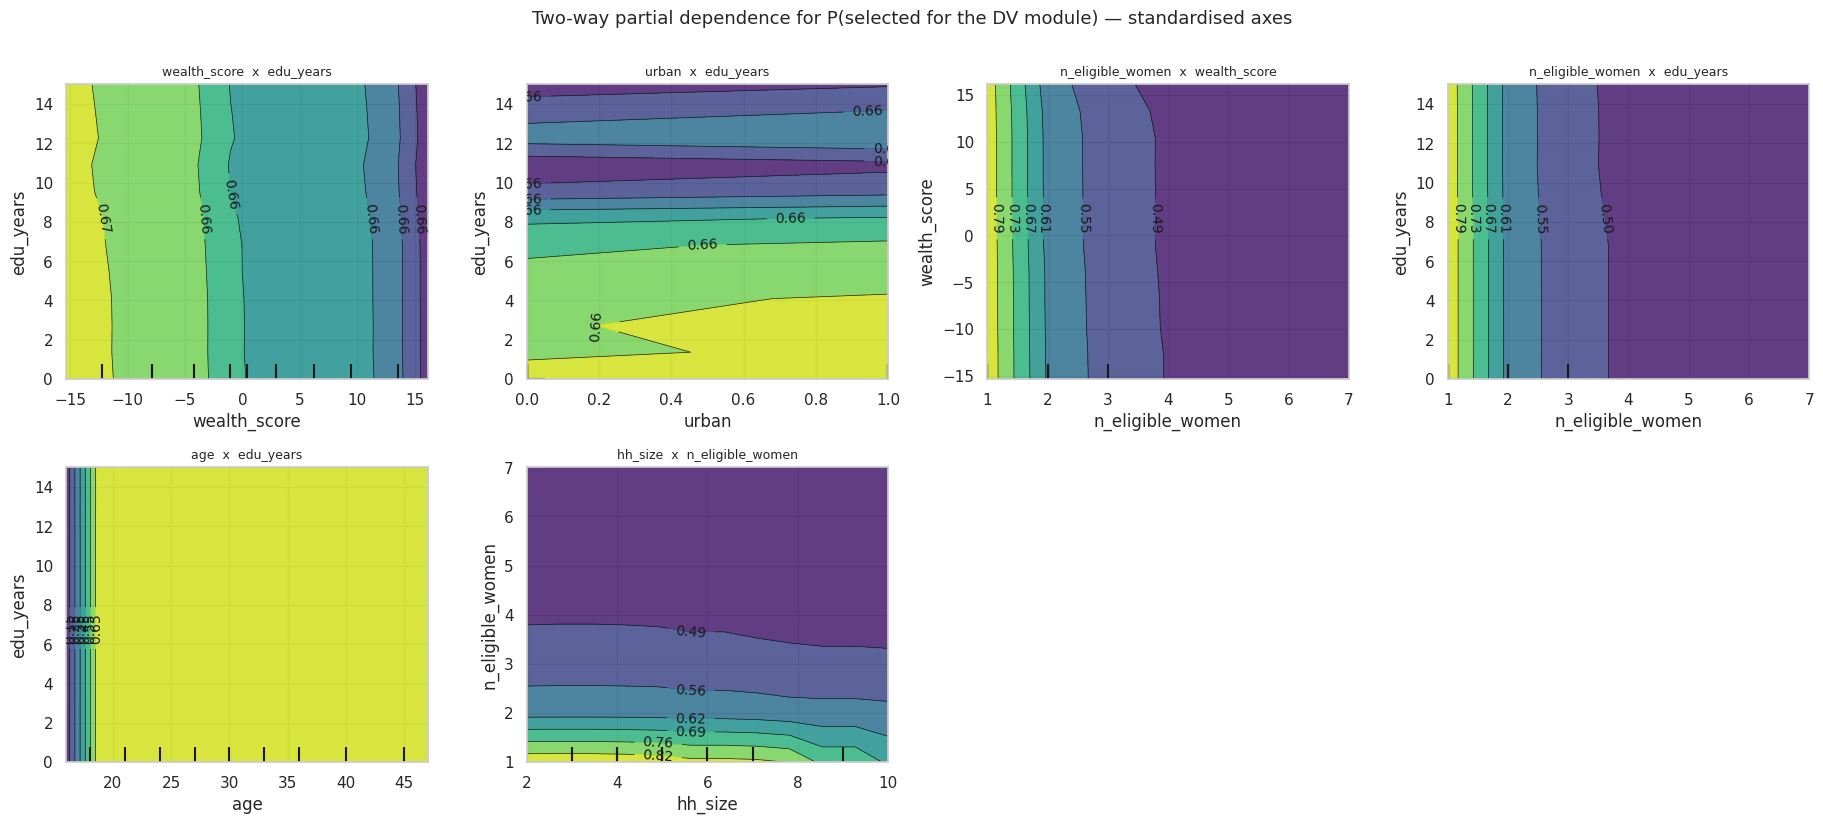

Flat, parallel contours mean the two characteristics act additively — no interaction. Curved or twisted contours are where a *combination* of characteristics, not either one alone, shifts the selection probability. Axes are on the standardised scale used by the fitted preprocessor.

  urban: scikit-learn raised ValueError, so the brute-force curve was computed directly on 2 grid points.


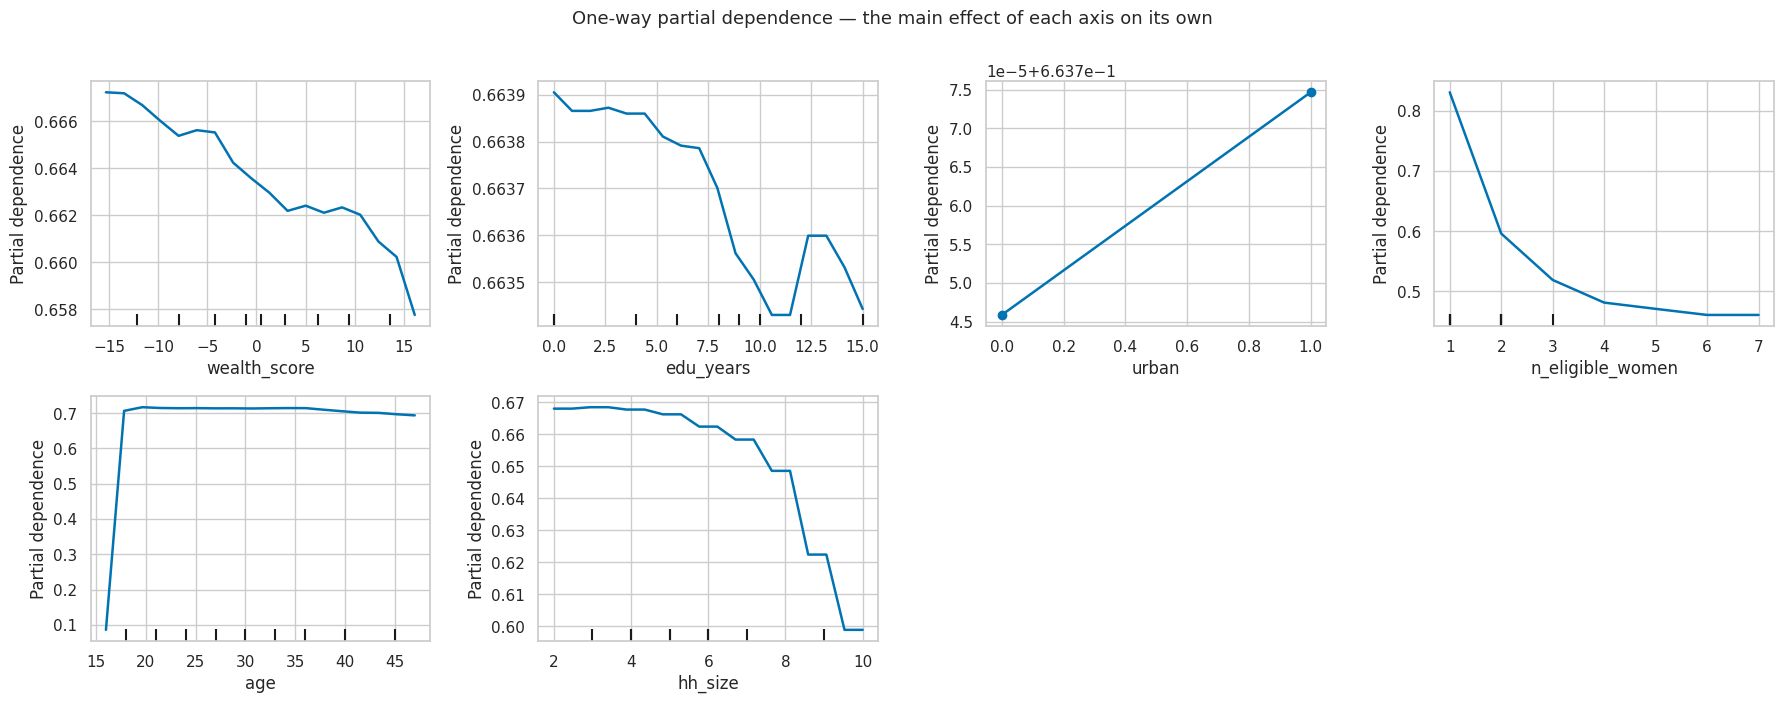

/tmp/ipykernel_116/3853011358.py:172: RuntimeWarning: overflow encountered in exp
  "ci_high": np.exp(coefficients + 1.96 * standard_errors),


### Interaction logit — 10 engineered products alongside 11 main effects (n = 149,892 training women, standardised inputs)

,term,coefficient,odds_ratio,ci_low,ci_high,z,p_value,significant_5pct
14,age_x_union,-1.4221,0.2412,0.2259,0.2576,-42.47,0.00e+00,True
18,eligible_x_education,+0.2184,1.2441,1.1881,1.3028,+9.29,1.52e-20,True
11,wealth_x_education,+0.2111,1.2350,1.1697,1.3040,+7.61,2.74e-14,True
16,eligible_x_wealth,-0.2155,0.8061,0.7565,0.8590,-6.65,2.90e-11,True
17,eligible_x_urban,+0.0807,1.0840,1.0415,1.1282,+3.95,7.72e-05,True
13,urban_x_wealth,-0.1048,0.9005,0.8503,0.9536,-3.58,3.40e-04,True
12,urban_x_education,+0.0432,1.0442,1.0078,1.0819,+2.39,1.69e-02,True
15,age_x_education,+0.0431,1.0441,0.9879,1.1034,+1.53,1.27e-01,False
19,hhsize_x_eligible,+0.0399,1.0407,0.9880,1.0962,+1.50,1.33e-01,False
20,femalehead_x_wealth,+0.0020,1.0020,0.9693,1.0358,+0.12,9.07e-01,False


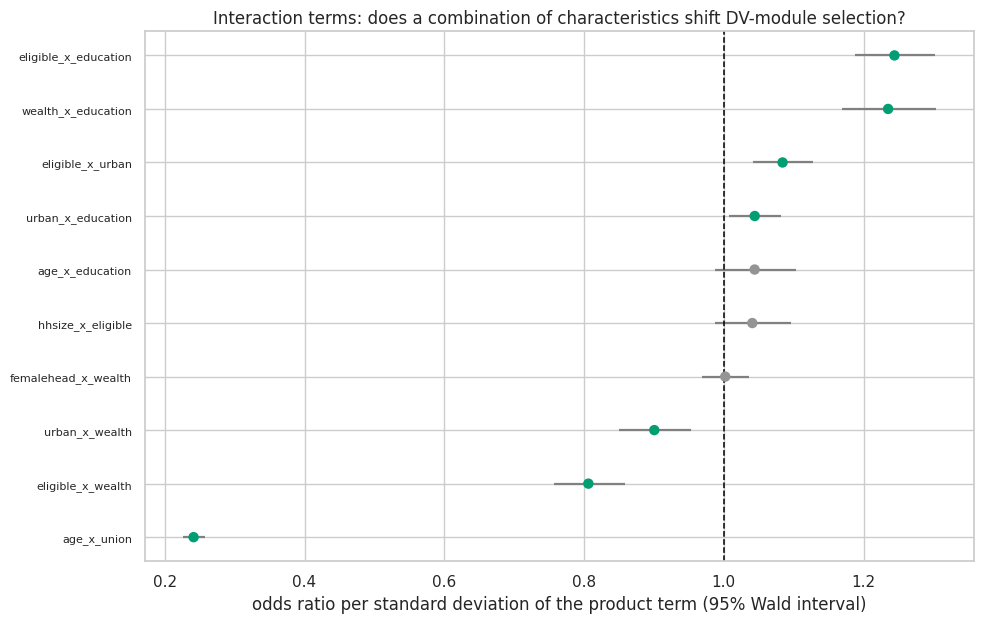

**7 of 10 interaction terms are significant at the 5% level.** With 149,892 training rows, even a substantively tiny interaction reaches significance, so the odds ratio itself — how far from 1.0 the point estimate sits — is the quantity to read, not the p-value. Terms built on `n_eligible_women` are expected to be significant: they are products with the design variable.

### Held-out test of the interaction block, same learner both times

,model,roc_auc,pr_auc,f1,balanced_accuracy,n_features_in
0,Interaction logit: main effects only,0.8883,0.9468,0.8531,0.7735,16
1,Interaction logit: + products,0.8910,0.9476,0.8551,0.7694,26


Adding the 10 product terms to an additive logit changes ROC-AUC by +0.0027 and PR-AUC by +0.0008 on the held-out clusters.


54764

In [53]:
# ================================================================================================
# RECODE SOURCE
#   * Individual Recode (IR) - XXIRnnFL - one record per interviewed woman 15-49
# WHAT THIS CELL USES: the held-out clusters, plus a purpose-built interaction logit on the training
#                      clusters. Answers the "how do these profiles interact?" half of the question.
# ================================================================================================
# 20c. Interactions: two-way partial dependence, and interaction odds ratios with Wald intervals

PDP_SAMPLE_MAX = 8_000
PDP_GRID = 12
LOGIT_INFERENCE_MAX = 150_000

# --- 1. two-way partial dependence on the numeric axes of interest --------------------------------
PDP_PAIRS = [
    ("wealth_score", "edu_years"),
    ("urban", "edu_years"),
    ("n_eligible_women", "wealth_score"),
    ("n_eligible_women", "edu_years"),
    ("empowerment_index", "edu_years"),
    ("attitude_index", "wealth_score"),
    ("age", "edu_years"),
    ("hh_size", "n_eligible_women"),
]
pdp_names = expanded_feature_names(ATTRIBUTION_PREPROCESSOR)
pdp_index = {name: i for i, name in enumerate(pdp_names)}
usable_pairs = [(a, b) for a, b in PDP_PAIRS if a in pdp_index and b in pdp_index]
skipped_pairs = [(a, b) for a, b in PDP_PAIRS if (a, b) not in usable_pairs]
if skipped_pairs:
    print(f"Pairs skipped because a column is not in the model matrix: {skipped_pairs}")

pdp_frame = subsample(test_df, PDP_SAMPLE_MAX)
X_pdp = ATTRIBUTION_PREPROCESSOR.transform(pdp_frame)
print(f"Two-way partial dependence for '{ATTRIBUTION_NAME}' on {len(pdp_frame):,} held-out women, "
      f"{len(usable_pairs)} pairs, {PDP_GRID}x{PDP_GRID} grid")

if usable_pairs:
    ncols = 4
    nrows = int(np.ceil(len(usable_pairs) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.6 * ncols, 4.1 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, (a, b) in zip(axes, usable_pairs):
        try:
            PartialDependenceDisplay.from_estimator(
                ATTRIBUTION_MODEL, X_pdp, features=[(pdp_index[a], pdp_index[b])],
                feature_names=pdp_names, grid_resolution=PDP_GRID, method="brute",
                ax=ax, contour_kw={"cmap": "viridis", "alpha": 0.85})
            ax.set_title(f"{a}  x  {b}", fontsize=9)
        except Exception as exc:                                # noqa: BLE001 - report, do not abort
            ax.axis("off")
            ax.set_title(f"{a} x {b}\nfailed: {type(exc).__name__}", fontsize=7)
    for ax in axes[len(usable_pairs):]:
        ax.axis("off")
    fig.suptitle("Two-way partial dependence for P(selected for the DV module) — standardised axes",
                 y=1.003, fontsize=13)
    plt.tight_layout(); plt.show()
    display(Markdown(
        "Flat, parallel contours mean the two characteristics act additively — no interaction. "
        "Curved or twisted contours are where a *combination* of characteristics, not either one "
        "alone, shifts the selection probability. Axes are on the standardised scale used by the "
        "fitted preprocessor."))

# --- 2. one-way partial dependence for the same axes, as a reference ------------------------------
# One panel at a time, each guarded, for two reasons:
#   * a single batched from_estimator() call over all eight axes is computed inside one joblib fan-out,
#     so one awkward column takes the whole figure down with it; and
#   * scikit-learn's brute-force partial dependence mis-reads the shape of its own output when the
#     fitted estimator exposes only decision_function (Linear SVM, SVC) and the axis is binary, so
#     its grid holds exactly two points. The two grid points are then mistaken for the two classes,
#     the "positive class" row is sliced out to a scalar, and the final reshape raises
#         ValueError: cannot reshape array of size 1 into shape (2)
#     Every binary column on this list trips it - urban above all - and which learner wins §19b
#     decides whether it fires at all, so the cell must not depend on the winner having predict_proba.
# The fallback computes the same quantity from its definition: put every sample at one grid value of
# the column in turn and average the model's positive-class score. Where scikit-learn also succeeds
# the two curves coincide, and the print says which panels were drawn the second way.

def pd_response(model, matrix):
    """The score that partial dependence averages: P(selected), or the decision function."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(matrix)[:, 1]
    return np.asarray(model.decision_function(matrix), dtype=float).ravel()


def one_way_partial_dependence(model, matrix, column, grid_resolution):
    """Brute-force one-way partial dependence for one column of a dense design matrix."""
    matrix = np.asarray(matrix)
    uniques = np.unique(matrix[:, column])
    if uniques.size < 2:
        raise ValueError("the column is constant on this sample, so it has no partial dependence")
    if uniques.size <= grid_resolution:
        axis_grid = uniques                    # binary and other low-resolution columns, as sklearn
    else:
        low, high = np.percentile(matrix[:, column], [5, 95])
        axis_grid = np.linspace(low, high, grid_resolution)
    scratch = matrix.astype(float, copy=True)
    axis_curve = np.empty(axis_grid.size, dtype=float)
    for i, value in enumerate(axis_grid):
        scratch[:, column] = value
        axis_curve[i] = float(np.mean(pd_response(model, scratch)))
    return axis_grid, axis_curve


one_way = [pdp_index[f] for f in dict.fromkeys([f for pair in usable_pairs for f in pair])][:8]
if one_way:
    fig, axes = plt.subplots(2, 4, figsize=(18, 7))
    for ax, axis_column in zip(axes.ravel(), one_way):
        axis_label = pdp_names[axis_column]
        try:
            PartialDependenceDisplay.from_estimator(
                ATTRIBUTION_MODEL, X_pdp, features=[axis_column], feature_names=pdp_names,
                grid_resolution=PDP_GRID + 6, method="brute", ax=ax,
                line_kw={"color": PALETTE[0], "linewidth": 1.8})
        except Exception as exc:                            # noqa: BLE001 - fall back, do not abort
            try:
                axis_grid, axis_curve = one_way_partial_dependence(
                    ATTRIBUTION_MODEL, X_pdp, axis_column, PDP_GRID + 6)
                ax.clear()
                ax.plot(axis_grid, axis_curve, color=PALETTE[0], linewidth=1.8,
                        marker="o" if axis_grid.size <= 4 else None)
                ax.set_xlabel(axis_label); ax.set_ylabel("Partial dependence")
                print(f"  {axis_label}: scikit-learn raised {type(exc).__name__}, so the "
                      f"brute-force curve was computed directly on {axis_grid.size} grid points.")
            except Exception as inner:                      # noqa: BLE001 - report, do not abort
                ax.clear(); ax.axis("off")
                ax.set_title(f"{axis_label}\nfailed: {type(inner).__name__}", fontsize=7)
    for ax in axes.ravel()[len(one_way):]:
        ax.axis("off")
    fig.suptitle("One-way partial dependence — the main effect of each axis on its own",
                 y=1.002, fontsize=13)
    plt.tight_layout(); plt.show()

# --- 3. an explicit interaction logit with Wald confidence intervals ------------------------------
# C = 1e6 makes the L2 penalty numerically irrelevant, which keeps the coefficients interpretable
# while staying compatible with every scikit-learn version. Unweighted, so the observed information
# matrix gives honest standard errors. Main effects and the engineered products enter together.
INTERACTION_MAIN_EFFECTS = [f for f in
                            ["n_eligible_women", "inv_eligible_women", "hh_size", "urban",
                             "wealth_score", "wealth_quintile", "edu_years", "age",
                             "empowerment_index", "attitude_index", "children_ever_born",
                             "spousal_age_gap", "female_head", "in_union"]
                            if f in ml_dataset.columns]
INTERACTION_TERMS = [f for f in INTERACTION_FEATURES if f in ml_dataset.columns]
LOGIT_NUMERIC = list(dict.fromkeys(INTERACTION_MAIN_EFFECTS + INTERACTION_TERMS))
LOGIT_CATEGORICAL = [c for c in ["country"] if c in ml_dataset.columns]

logit_train = subsample(train_df, LOGIT_INFERENCE_MAX)
logit_pre = build_preprocessor(LOGIT_NUMERIC, LOGIT_CATEGORICAL, scale=True)
X_logit = logit_pre.fit_transform(logit_train)
logit_cols = expanded_feature_names(logit_pre)
y_logit = logit_train[TARGET].to_numpy()

interaction_logit = LogisticRegression(C=1e6, max_iter=4000)
interaction_logit.fit(X_logit, y_logit)

# Wald standard errors from the observed information matrix of the fitted logit.
p_hat = interaction_logit.predict_proba(X_logit)[:, 1]
Xd = np.column_stack([np.ones(len(X_logit)), X_logit])
W = np.clip(p_hat * (1.0 - p_hat), 1e-8, None)
information = Xd.T @ (Xd * W[:, None])
covariance = np.linalg.pinv(information + 1e-8 * np.eye(information.shape[0]))
standard_errors = np.sqrt(np.clip(np.diag(covariance)[1:], 0, None))

coefficients = interaction_logit.coef_.ravel()
z_stats = np.divide(coefficients, standard_errors,
                    out=np.zeros_like(coefficients), where=standard_errors > 0)
interaction_table = pd.DataFrame({
    "term": logit_cols,
    "coefficient": coefficients,
    "std_error": standard_errors,
    "odds_ratio": np.exp(coefficients),
    "ci_low": np.exp(coefficients - 1.96 * standard_errors),
    "ci_high": np.exp(coefficients + 1.96 * standard_errors),
    "z": z_stats,
})
interaction_table["p_value"] = [math.erfc(abs(z) / math.sqrt(2.0)) for z in interaction_table.z]
interaction_table["kind"] = np.where(interaction_table.term.isin(INTERACTION_TERMS),
                                     "interaction", "main effect / country")
interaction_table["significant_5pct"] = interaction_table.p_value.lt(0.05)
interaction_table = interaction_table.sort_values("p_value")

display(Markdown(f"### Interaction logit — {len(INTERACTION_TERMS)} engineered products alongside "
                 f"{len(INTERACTION_MAIN_EFFECTS)} main effects "
                 f"(n = {len(logit_train):,} training women, standardised inputs)"))
display(interaction_table[interaction_table.kind.eq("interaction")]
        [["term", "coefficient", "odds_ratio", "ci_low", "ci_high", "z", "p_value",
          "significant_5pct"]]
        .style.format({"coefficient": "{:+.4f}", "odds_ratio": "{:.4f}", "ci_low": "{:.4f}",
                       "ci_high": "{:.4f}", "z": "{:+.2f}", "p_value": "{:.2e}"})
        .background_gradient(subset=["coefficient"], cmap="coolwarm"))
interaction_table.to_csv(OUTPUT_DIR / "interaction_logit_odds_ratios.csv", index=False)

inter_only = interaction_table[interaction_table.kind.eq("interaction")].sort_values("coefficient")
if len(inter_only):
    plt.figure(figsize=(10, 0.42 * len(inter_only) + 2.2))
    y_pos = np.arange(len(inter_only))
    plt.hlines(y_pos, inter_only.ci_low, inter_only.ci_high, color="grey", linewidth=1.6)
    plt.scatter(inter_only.odds_ratio, y_pos, s=42,
                c=[PALETTE[2] if s else PALETTE[7 % len(PALETTE)]
                   for s in inter_only.significant_5pct], zorder=3)
    plt.axvline(1.0, color="black", linestyle="--", linewidth=1.1)
    plt.yticks(y_pos, inter_only.term, fontsize=8)
    plt.xlabel("odds ratio per standard deviation of the product term (95% Wald interval)")
    plt.title("Interaction terms: does a combination of characteristics shift DV-module selection?")
    plt.tight_layout(); plt.show()

n_sig = int(inter_only.significant_5pct.sum())
display(Markdown(
    f"**{n_sig} of {len(inter_only)} interaction terms are significant at the 5% level.** With "
    f"{len(logit_train):,} training rows, even a substantively tiny interaction reaches significance, "
    f"so the odds ratio itself — how far from 1.0 the point estimate sits — is the quantity to read, "
    f"not the p-value. Terms built on `n_eligible_women` are expected to be significant: they are "
    f"products with the design variable."))

# --- 4. does dropping the interaction block cost held-out performance? ----------------------------
main_only_spec = {"name": "Interaction logit: main effects only", "family": "linear",
                  "estimator": LogisticRegression(C=1e6, max_iter=4000),
                  "scale": True, "kernel": False,
                  "numeric": INTERACTION_MAIN_EFFECTS, "categorical": LOGIT_CATEGORICAL}
with_inter_spec = {**main_only_spec, "name": "Interaction logit: + products",
                   "numeric": LOGIT_NUMERIC}
interaction_test_rows = []
for spec in (main_only_spec, with_inter_spec):
    try:
        row, _, _, _, _ = fit_and_score(spec, train_df, test_df)
        interaction_test_rows.append(row)
    except Exception as exc:                                    # noqa: BLE001 - report, do not abort
        print(f"  {spec['name']} FAILED: {type(exc).__name__}: {exc}")
if len(interaction_test_rows) == 2:
    interaction_gain = pd.DataFrame(interaction_test_rows)[
        ["model", "roc_auc", "pr_auc", "f1", "balanced_accuracy", "n_features_in"]]
    display(Markdown("### Held-out test of the interaction block, same learner both times"))
    display(interaction_gain.style.format({"roc_auc": "{:.4f}", "pr_auc": "{:.4f}", "f1": "{:.4f}",
                                           "balanced_accuracy": "{:.4f}",
                                           "n_features_in": "{:,.0f}"}))
    d_roc = interaction_gain.roc_auc.iloc[1] - interaction_gain.roc_auc.iloc[0]
    d_pr = interaction_gain.pr_auc.iloc[1] - interaction_gain.pr_auc.iloc[0]
    print(f"Adding the {len(INTERACTION_TERMS)} product terms to an additive logit changes "
          f"ROC-AUC by {d_roc:+.4f} and PR-AUC by {d_pr:+.4f} on the held-out clusters.")
    interaction_gain.to_csv(OUTPUT_DIR / "interaction_block_holdout_gain.csv", index=False)
del X_logit, Xd, information, covariance, X_pdp
gc.collect()

## 21. Cross-country variation: are the profiles that matter the same everywhere?

The pooled models of §19–§20 answer the question on average across South Asia. That average can hide
two very different situations:

1. **One regime.** The same characteristics matter in the same direction in every country, and the
   country dummy only shifts the base rate. If so, a model trained on four countries should transfer
   cleanly to the fifth.
2. **Country-specific regimes.** Each survey ran the DV module its own way — different sub-sample
   fractions, different field seasons, different regional coverage — so the profile that predicts
   selection in Nepal is not the profile that predicts it in India. If so, transfer fails even when
   the pooled model looks fine.

Two experiments separate these.

### 21a. One model per country

Every country in `MODEL_COUNTRIES` gets its own cluster-aware split, its own model, and its own
holdout score, using the identical learner and identical feature set. What varies is only the data.
The output is:

* a per-country performance table (with each country's positive rate, so the PR-AUC is readable),
* a per-country design-only baseline, so the **profile gain is computed within each country**,
* a heatmap of the top features by country, which shows directly whether the same characteristics
  surface everywhere.

Sample size differs enormously — India contributes roughly 700 000 women, Myanmar under 13 000 — so
each country's row reports its own `n_train`, and small-sample countries are read with that in mind.

### 21b. Leave-one-country-out transfer

Train on all countries except one, test on the held-out country entirely. Compare against the
within-country model from 21a:

| Outcome | Reading |
|---|---|
| Transfer ≈ within-country | The selection mechanism is common to South Asia. |
| Transfer ≪ within-country | The mechanism is country-specific; pooled coefficients are an artefact of mixing surveys. |
| Transfer ≈ chance | Nothing generalises — the pooled result was driven by between-country differences in base rates, not by profiles. |

This is a harder test than a random split, because it removes every cluster, every region and every
survey-specific coding quirk of the target country from the training data at once.

Per-country learner: LightGBM, 61 numeric + 7 categorical features (country dropped - it is constant within each fit)


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  Afghanistan  ROC-AUC 0.8713 (design 0.8746, gain -0.0033)  PR-AUC 0.9559  n_train 21,845


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  India        ROC-AUC 0.9196 (design 0.8486, gain +0.0710)  PR-AUC 0.9642  n_train 90,519


...

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  Pakistan     ROC-AUC 0.6102 (design 0.6268, gain -0.0166)  PR-AUC 0.3501  n_train 11,301


### One model per country — identical learner (LightGBM) and identical features, only the data changes

,country,n_train,n_test,clusters_train,clusters_test,pct_positive_test,roc_auc,pr_auc,f1,balanced_accuracy,design_roc_auc,design_pr_auc,profile_gain_roc,profile_gain_pr,mean_eligible_women
1,India,"90,519","30,171","3,748","1,250",67.91,0.9196,0.9642,0.8485,0.8437,0.8486,0.9247,+0.0710,+0.0395,1.80
0,Afghanistan,"21,845","7,616",717,239,72.77,0.8713,0.9559,0.8338,0.8232,0.8746,0.9558,-0.0033,+0.0001,1.62
4,Pakistan,"11,301","3,767",420,141,28.17,0.6102,0.3501,0.3586,0.5545,0.6268,0.3517,-0.0166,-0.0016,1.57
3,Nepal,"11,105","3,740",357,119,34.63,0.6331,0.4518,0.4802,0.5954,0.6642,0.4706,-0.0311,-0.0189,1.73
2,Myanmar,"9,486","3,399",330,111,34.63,0.6427,0.4590,0.4755,0.5964,0.6771,0.4906,-0.0344,-0.0316,1.76


/tmp/ipykernel_116/3192625164.py:115: UserWarning: The palette list has more values (10) than needed (5), which may not be intended.
  sns.barplot(data=country_models, x="country", y="profile_gain_roc", ax=axes[1],


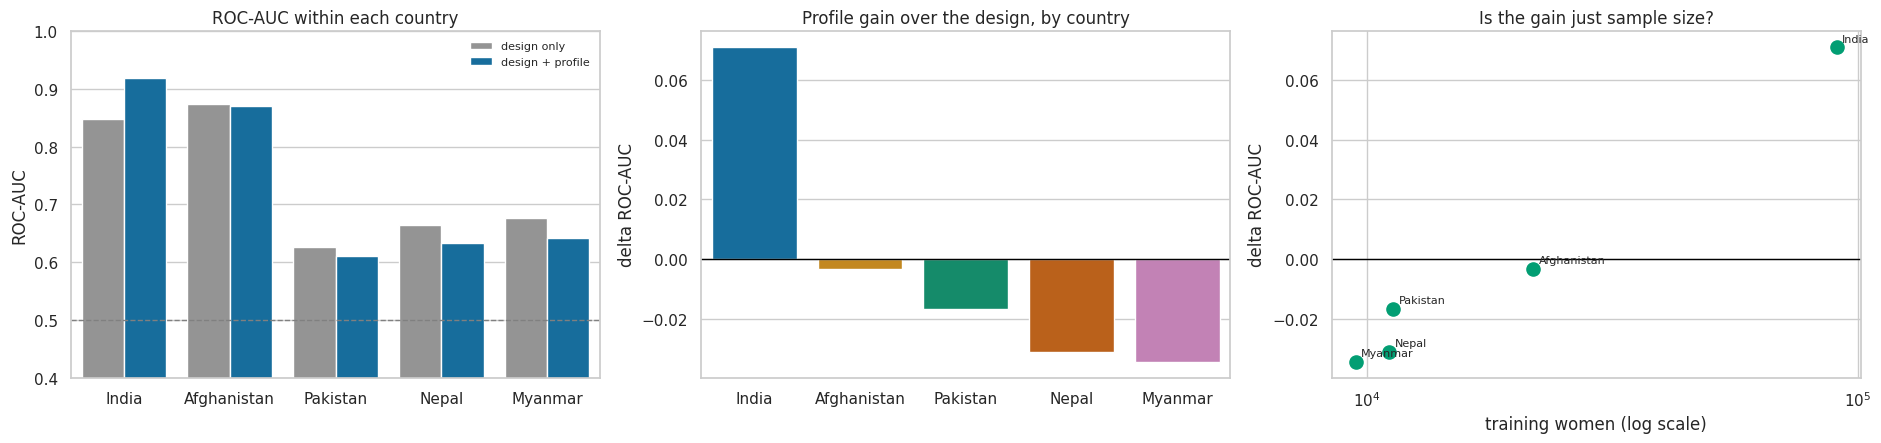

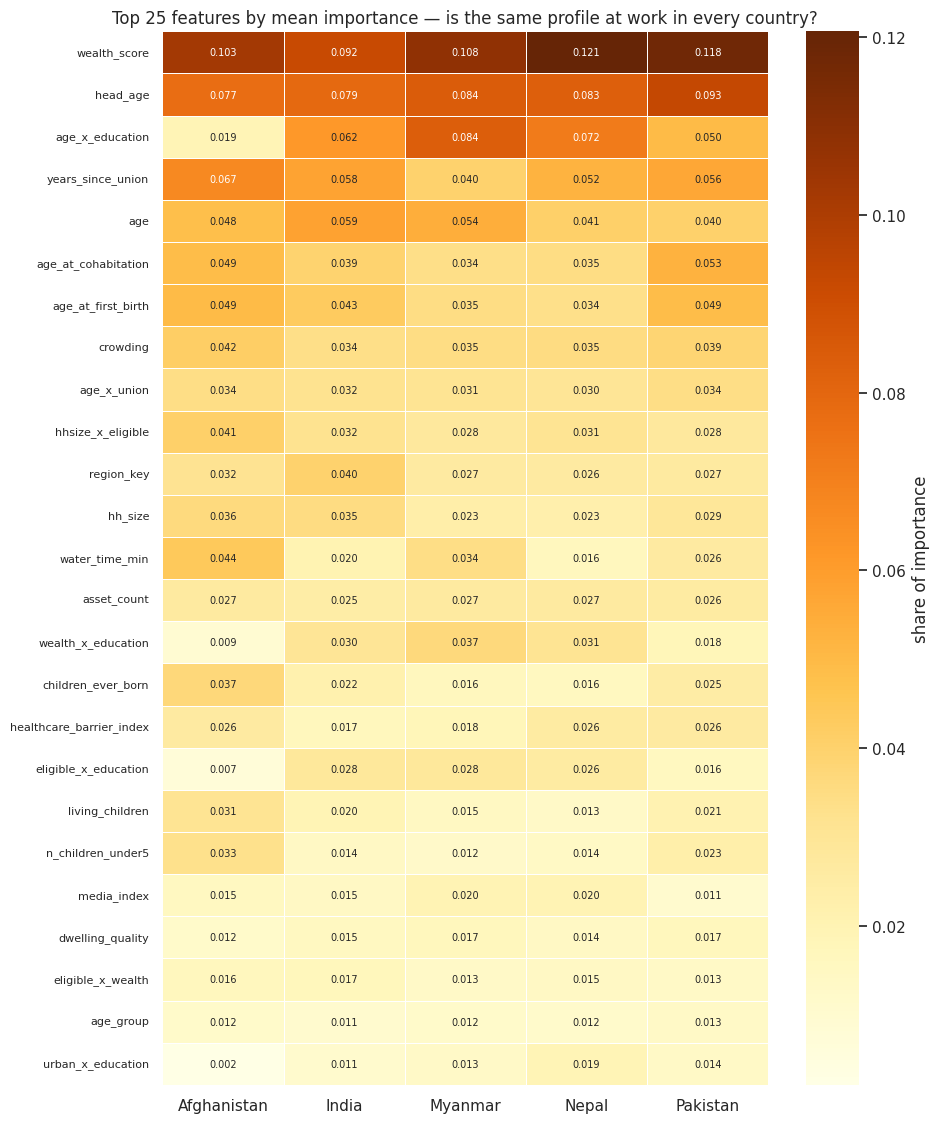

### Spearman correlation between countries' importance rankings
High values mean the countries agree about which characteristics matter; low or negative values mean the mechanism differs by survey.

country,Afghanistan,India,Myanmar,Nepal,Pakistan
country,,,,,
Afghanistan,1.000000,0.700000,0.590000,0.580000,0.840000
India,0.700000,1.000000,0.880000,0.890000,0.890000
Myanmar,0.590000,0.880000,1.000000,0.920000,0.790000
Nepal,0.580000,0.890000,0.920000,1.000000,0.830000
Pakistan,0.840000,0.890000,0.790000,0.830000,1.000000


Mean off-diagonal rank correlation: 0.791


13905

In [54]:
# ================================================================================================
# RECODE SOURCE
#   * Individual Recode (IR) - XXIRnnFL - one record per interviewed woman 15-49
# WHAT THIS CELL USES: ml_dataset split country by country. Same learner and features every time.
# ================================================================================================
# 21a. One model per country

COUNTRY_SAMPLE_MAX = 120_000        # per country, so India does not dominate the wall clock


def country_learner():
    """The learner used for every per-country and leave-one-out fit, so only the data varies."""
    if HAS_LIGHTGBM:
        return LGBMClassifier(n_estimators=400, num_leaves=63, learning_rate=0.06, subsample=0.85,
                              subsample_freq=1, colsample_bytree=0.85, reg_lambda=1.0,
                              min_child_samples=40, class_weight="balanced", n_jobs=N_JOBS,
                              random_state=RANDOM_SEED, verbosity=-1)
    return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.07, max_leaf_nodes=63,
                                          l2_regularization=1.0, min_samples_leaf=40,
                                          random_state=RANDOM_SEED)


COUNTRY_LEARNER_NAME = "LightGBM" if HAS_LIGHTGBM else "HistGradientBoosting"
# Country itself is meaningless inside a single-country model, so it leaves the feature set here.
WITHIN_NUMERIC = [f for f in ALL_NUMERIC]
WITHIN_CATEGORICAL = [c for c in ALL_CATEGORICAL if c not in ("country",)]
WITHIN_DESIGN_NUMERIC = [f for f in DESIGN_ONLY_NUMERIC]
WITHIN_DESIGN_CATEGORICAL = [c for c in DESIGN_ONLY_CATEGORICAL if c != "country"]
print(f"Per-country learner: {COUNTRY_LEARNER_NAME}, "
      f"{len(WITHIN_NUMERIC)} numeric + {len(WITHIN_CATEGORICAL)} categorical features "
      f"(country dropped - it is constant within each fit)")

country_rows, country_importances = [], []
for country in sorted(ml_dataset.country.unique()):
    block = ml_dataset[ml_dataset.country.eq(country)]
    block = subsample(block, COUNTRY_SAMPLE_MAX, stratify_on=("y_selected",))
    if block.y_selected.nunique() < 2 or block.group_key.nunique() < 20:
        print(f"  {country:<12s} skipped: {len(block):,} rows, "
              f"{block.group_key.nunique()} clusters, "
              f"{block.y_selected.nunique()} distinct target values")
        continue
    tr, te = group_holdout(block, target=TARGET)
    if te.y_selected.nunique() < 2 or tr.y_selected.nunique() < 2:
        print(f"  {country:<12s} skipped: a split side has only one class")
        continue

    full_spec = {"name": f"{COUNTRY_LEARNER_NAME} ({country})", "estimator": country_learner(),
                 "family": "per_country", "scale": False, "kernel": False,
                 "numeric": WITHIN_NUMERIC, "categorical": WITHIN_CATEGORICAL}
    design_spec = {"name": f"design only ({country})", "family": "per_country_baseline",
                   "estimator": LogisticRegression(max_iter=3000, class_weight="balanced"),
                   "scale": True, "kernel": False,
                   "numeric": WITHIN_DESIGN_NUMERIC, "categorical": WITHIN_DESIGN_CATEGORICAL}
    try:
        full_row, estimator, pre, _, _ = fit_and_score(full_spec, tr, te)
        design_row, _, _, _, _ = fit_and_score(design_spec, tr, te)
    except Exception as exc:                                    # noqa: BLE001 - report, do not abort
        print(f"  {country:<12s} FAILED: {type(exc).__name__}: {exc}")
        continue

    country_rows.append({
        "country": country,
        "n_train": full_row["n_train"], "n_test": full_row["n_test"],
        "clusters_train": tr.group_key.nunique(), "clusters_test": te.group_key.nunique(),
        "pct_positive_test": 100 * te[TARGET].mean(),
        "roc_auc": full_row["roc_auc"], "pr_auc": full_row["pr_auc"],
        "f1": full_row["f1"], "balanced_accuracy": full_row["balanced_accuracy"],
        "design_roc_auc": design_row["roc_auc"], "design_pr_auc": design_row["pr_auc"],
        "profile_gain_roc": full_row["roc_auc"] - design_row["roc_auc"],
        "profile_gain_pr": full_row["pr_auc"] - design_row["pr_auc"],
        "mean_eligible_women": block.n_eligible_women.mean(),
    })
    print(f"  {country:<12s} ROC-AUC {full_row['roc_auc']:.4f} (design {design_row['roc_auc']:.4f}, "
          f"gain {full_row['roc_auc'] - design_row['roc_auc']:+.4f})  "
          f"PR-AUC {full_row['pr_auc']:.4f}  n_train {full_row['n_train']:,}")

    if hasattr(estimator, "feature_importances_"):
        names = expanded_feature_names(pre)
        values = np.asarray(estimator.feature_importances_, dtype=float)
        if len(names) == len(values) and values.sum() > 0:
            imp = pd.DataFrame({"country": country, "expanded_feature": names,
                                "importance": values / values.sum()})
            imp["feature"] = imp.expanded_feature.map(base_feature_of)
            country_importances.append(imp.groupby(["country", "feature"], as_index=False)
                                       ["importance"].sum())

country_models = pd.DataFrame(country_rows).sort_values("profile_gain_roc", ascending=False) \
    if country_rows else pd.DataFrame(columns=["country", "n_train", "n_test", "clusters_train",
                                               "clusters_test", "pct_positive_test", "roc_auc",
                                               "pr_auc", "f1", "balanced_accuracy",
                                               "design_roc_auc", "design_pr_auc",
                                               "profile_gain_roc", "profile_gain_pr",
                                               "mean_eligible_women"])
display(Markdown(f"### One model per country — identical learner ({COUNTRY_LEARNER_NAME}) and "
                 f"identical features, only the data changes"))
display(country_models.style.format({
    "n_train": "{:,.0f}", "n_test": "{:,.0f}", "clusters_train": "{:,.0f}",
    "clusters_test": "{:,.0f}", "pct_positive_test": "{:.2f}", "roc_auc": "{:.4f}",
    "pr_auc": "{:.4f}", "f1": "{:.4f}", "balanced_accuracy": "{:.4f}",
    "design_roc_auc": "{:.4f}", "design_pr_auc": "{:.4f}", "profile_gain_roc": "{:+.4f}",
    "profile_gain_pr": "{:+.4f}", "mean_eligible_women": "{:.2f}"})
    .background_gradient(subset=["profile_gain_roc"], cmap="RdYlGn", vmin=-0.05, vmax=0.05))
country_models.to_csv(OUTPUT_DIR / "per_country_models.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(19, 4.6))
plot_df = country_models.melt(id_vars="country", value_vars=["design_roc_auc", "roc_auc"],
                              var_name="model", value_name="value")
plot_df["model"] = plot_df.model.map({"design_roc_auc": "design only", "roc_auc": "design + profile"})
sns.barplot(data=plot_df, x="country", y="value", hue="model", ax=axes[0],
            palette=[PALETTE[7 % len(PALETTE)], PALETTE[0]])
axes[0].axhline(0.5, color="grey", linestyle="--", linewidth=1.0)
axes[0].set_ylim(0.4, 1.0); axes[0].set_title("ROC-AUC within each country")
axes[0].set_xlabel(""); axes[0].set_ylabel("ROC-AUC"); axes[0].legend(fontsize=8, frameon=False)

sns.barplot(data=country_models, x="country", y="profile_gain_roc", ax=axes[1],
            hue="country", palette=PALETTE, legend=False, dodge=False)
axes[1].axhline(0, color="black", linewidth=1.0)
axes[1].set_title("Profile gain over the design, by country")
axes[1].set_xlabel(""); axes[1].set_ylabel("delta ROC-AUC")

axes[2].scatter(country_models.n_train, country_models.profile_gain_roc, s=90, color=PALETTE[2])
for _, r in country_models.iterrows():
    axes[2].annotate(r.country, (r.n_train, r.profile_gain_roc), fontsize=8,
                     xytext=(4, 4), textcoords="offset points")
axes[2].axhline(0, color="black", linewidth=1.0)
axes[2].set_xscale("log")
axes[2].set_title("Is the gain just sample size?")
axes[2].set_xlabel("training women (log scale)"); axes[2].set_ylabel("delta ROC-AUC")
plt.tight_layout(); plt.show()

# --- which features surface in which country? -----------------------------------------------------
if country_importances:
    country_importance = pd.concat(country_importances, ignore_index=True)
    country_importance.to_csv(OUTPUT_DIR / "per_country_feature_importance.csv", index=False)
    wide = country_importance.pivot(index="feature", columns="country", values="importance").fillna(0)
    top_features = wide.mean(axis=1).nlargest(25).index
    plt.figure(figsize=(1.9 * max(4, wide.shape[1]), 0.36 * len(top_features) + 2.4))
    sns.heatmap(wide.loc[top_features], annot=True, fmt=".3f", cmap="YlOrBr", linewidths=0.4,
                linecolor="white", cbar_kws={"label": "share of importance"},
                annot_kws={"fontsize": 7})
    plt.title("Top 25 features by mean importance — is the same profile at work in every country?")
    plt.xlabel(""); plt.ylabel(""); plt.yticks(fontsize=8)
    plt.tight_layout(); plt.show()

    rank_corr = wide.loc[top_features].corr(method="spearman")
    display(Markdown("### Spearman correlation between countries' importance rankings\n"
                     "High values mean the countries agree about which characteristics matter; low "
                     "or negative values mean the mechanism differs by survey."))
    display(rank_corr.round(2).style.background_gradient(cmap="RdBu_r", vmin=-1, vmax=1))
    rank_corr.round(4).to_csv(OUTPUT_DIR / "per_country_importance_rank_correlation.csv")
    print(f"Mean off-diagonal rank correlation: "
          f"{rank_corr.where(~np.eye(len(rank_corr), dtype=bool)).stack().mean():.3f}")
gc.collect()

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  hold out Afghanistan  transfer ROC-AUC 0.8719 (design 0.8834)  PR-AUC 0.9592  trained on 200,844 women from 4 countries


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  hold out India        transfer ROC-AUC 0.8374 (design 0.8444)  PR-AUC 0.9227  trained on 72,259 women from 4 countries


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


...

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  hold out Pakistan     transfer ROC-AUC 0.6219 (design 0.6203)  PR-AUC 0.3512  trained on 199,911 women from 4 countries


### Leave-one-country-out transfer — every cluster, region and survey quirk of the target country is absent from training

,held_out_country,n_train,n_test,train_countries,pct_positive_test,transfer_roc_auc,transfer_pr_auc,transfer_design_roc_auc,within_country_roc_auc,within_country_pr_auc,transfer_penalty_roc,transfer_penalty_pr,transfer_gain_over_design
0,Afghanistan,"200,844","29,461",4,75.12,0.8719,0.9592,0.8834,0.8713,0.9559,+0.0006,+0.0033,-0.0116
1,India,"72,259","120,690",4,68.14,0.8374,0.9227,0.8444,0.9196,0.9642,-0.0822,-0.0415,-0.0070
2,Myanmar,"199,803","12,885",4,35.41,0.6668,0.4808,0.6733,0.6427,0.4590,+0.0242,+0.0218,-0.0065
3,Nepal,"199,934","14,845",4,34.97,0.6484,0.4632,0.6628,0.6331,0.4518,+0.0154,+0.0115,-0.0144
4,Pakistan,"199,911","15,068",4,27.98,0.6219,0.3512,0.6203,0.6102,0.3501,+0.0117,+0.0011,+0.0017


/tmp/ipykernel_116/3731161582.py:91: UserWarning: The palette list has more values (10) than needed (5), which may not be intended.
  sns.barplot(data=loco, x="held_out_country", y="transfer_penalty_roc", ax=axes[1],
/tmp/ipykernel_116/3731161582.py:97: UserWarning: The palette list has more values (10) than needed (5), which may not be intended.
  sns.barplot(data=loco, x="held_out_country", y="transfer_gain_over_design", ax=axes[2],


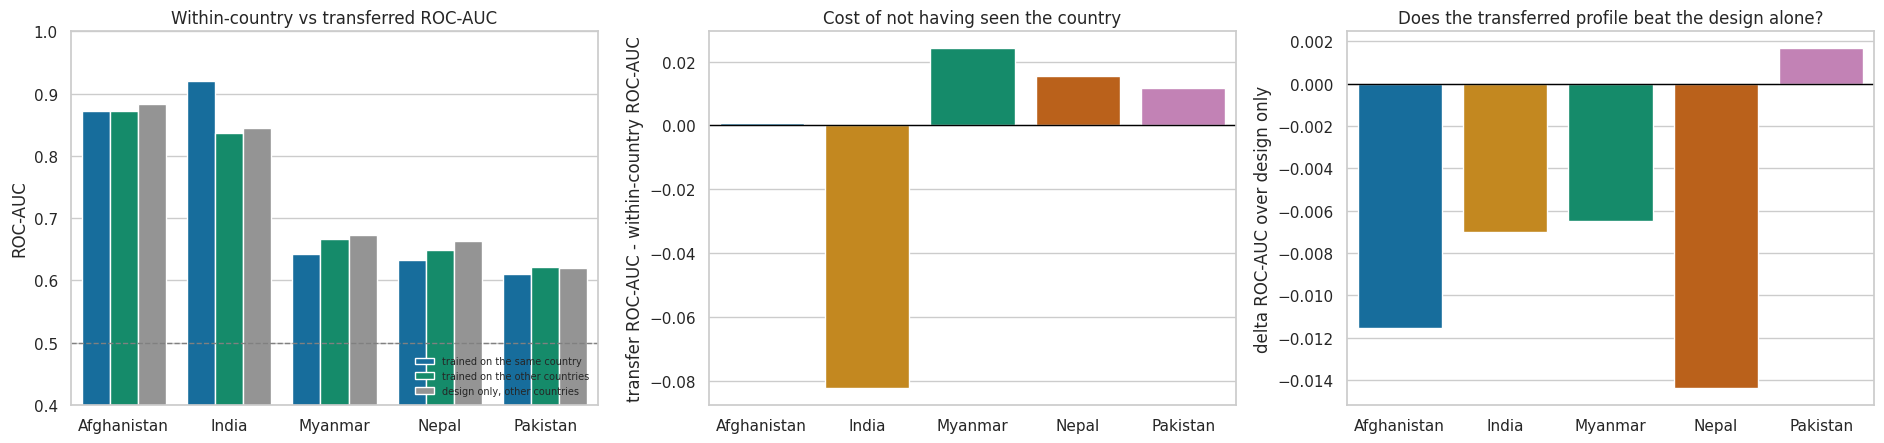

**Mean transfer penalty -0.0061 ROC-AUC; mean transferred gain over design -0.0076.** Transferred models barely improve on the design alone, which says the pooled signal is carried by the design variables and by between-country differences in base rates rather than by any transportable profile.

14573

In [55]:
# ================================================================================================
# RECODE SOURCE
#   * Individual Recode (IR) - XXIRnnFL - one record per interviewed woman 15-49
# WHAT THIS CELL USES: ml_dataset, trained on N-1 countries and tested on the country left out.
# ================================================================================================
# 21b. Leave-one-country-out transfer

LOCO_TRAIN_MAX = 200_000
LOCO_TEST_MAX = 120_000

loco_rows = []
for held_out in sorted(ml_dataset.country.unique()):
    train_pool = ml_dataset[~ml_dataset.country.eq(held_out)]
    test_pool = ml_dataset[ml_dataset.country.eq(held_out)]
    if train_pool.y_selected.nunique() < 2 or test_pool.y_selected.nunique() < 2:
        print(f"  hold out {held_out:<12s} skipped: one side has a single class")
        continue
    tr = subsample(train_pool, LOCO_TRAIN_MAX)
    te = subsample(test_pool, LOCO_TEST_MAX, stratify_on=("y_selected",))

    # Country is dropped on purpose: the held-out country's dummy is unseen at training time, so
    # keeping it would only feed the model an all-zero column and invite a false sense of transfer.
    spec = {"name": f"{COUNTRY_LEARNER_NAME} (trained without {held_out})",
            "estimator": country_learner(), "family": "leave_one_country_out",
            "scale": False, "kernel": False,
            "numeric": WITHIN_NUMERIC, "categorical": WITHIN_CATEGORICAL}
    design_spec = {"name": f"design only (trained without {held_out})",
                   "estimator": LogisticRegression(max_iter=3000, class_weight="balanced"),
                   "family": "leave_one_country_out_baseline", "scale": True, "kernel": False,
                   "numeric": WITHIN_DESIGN_NUMERIC, "categorical": WITHIN_DESIGN_CATEGORICAL}
    try:
        row, _, _, _, _ = fit_and_score(spec, tr, te)
        design_row, _, _, _, _ = fit_and_score(design_spec, tr, te)
    except Exception as exc:                                    # noqa: BLE001 - report, do not abort
        print(f"  hold out {held_out:<12s} FAILED: {type(exc).__name__}: {exc}")
        continue

    within = country_models[country_models.country.eq(held_out)]
    loco_rows.append({
        "held_out_country": held_out,
        "n_train": row["n_train"], "n_test": row["n_test"],
        "train_countries": train_pool.country.nunique(),
        "pct_positive_test": 100 * te[TARGET].mean(),
        "transfer_roc_auc": row["roc_auc"], "transfer_pr_auc": row["pr_auc"],
        "transfer_design_roc_auc": design_row["roc_auc"],
        "within_country_roc_auc": within.roc_auc.iloc[0] if len(within) else np.nan,
        "within_country_pr_auc": within.pr_auc.iloc[0] if len(within) else np.nan,
    })
    print(f"  hold out {held_out:<12s} transfer ROC-AUC {row['roc_auc']:.4f} "
          f"(design {design_row['roc_auc']:.4f})  PR-AUC {row['pr_auc']:.4f}  "
          f"trained on {row['n_train']:,} women from {train_pool.country.nunique()} countries")

loco = pd.DataFrame(loco_rows)
if loco.empty:                          # keeps the schema so the panels below degrade quietly
    loco = pd.DataFrame(columns=["held_out_country", "n_train", "n_test", "train_countries",
                                 "pct_positive_test", "transfer_roc_auc", "transfer_pr_auc",
                                 "transfer_design_roc_auc", "within_country_roc_auc",
                                 "within_country_pr_auc"])
    print("No leave-one-country-out fit succeeded; the tables below are empty by construction.")
loco["transfer_penalty_roc"] = loco.transfer_roc_auc - loco.within_country_roc_auc
loco["transfer_penalty_pr"] = loco.transfer_pr_auc - loco.within_country_pr_auc
loco["transfer_gain_over_design"] = loco.transfer_roc_auc - loco.transfer_design_roc_auc

display(Markdown("### Leave-one-country-out transfer — every cluster, region and survey quirk of the "
                 "target country is absent from training"))
display(loco.style.format({
    "n_train": "{:,.0f}", "n_test": "{:,.0f}", "train_countries": "{:,.0f}",
    "pct_positive_test": "{:.2f}", "transfer_roc_auc": "{:.4f}", "transfer_pr_auc": "{:.4f}",
    "transfer_design_roc_auc": "{:.4f}", "within_country_roc_auc": "{:.4f}",
    "within_country_pr_auc": "{:.4f}", "transfer_penalty_roc": "{:+.4f}",
    "transfer_penalty_pr": "{:+.4f}", "transfer_gain_over_design": "{:+.4f}"}, na_rep="-")
    .background_gradient(subset=["transfer_penalty_roc"], cmap="RdYlGn", vmin=-0.15, vmax=0.05))
loco.to_csv(OUTPUT_DIR / "leave_one_country_out.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(19, 4.6))
compare = loco.melt(id_vars="held_out_country",
                    value_vars=["within_country_roc_auc", "transfer_roc_auc",
                                "transfer_design_roc_auc"],
                    var_name="setting", value_name="roc_auc")
compare["setting"] = compare.setting.map({
    "within_country_roc_auc": "trained on the same country",
    "transfer_roc_auc": "trained on the other countries",
    "transfer_design_roc_auc": "design only, other countries"})
sns.barplot(data=compare, x="held_out_country", y="roc_auc", hue="setting", ax=axes[0],
            palette=[PALETTE[0], PALETTE[2], PALETTE[7 % len(PALETTE)]])
axes[0].axhline(0.5, color="grey", linestyle="--", linewidth=1.0)
axes[0].set_ylim(0.4, 1.0); axes[0].set_title("Within-country vs transferred ROC-AUC")
axes[0].set_xlabel(""); axes[0].set_ylabel("ROC-AUC")
axes[0].legend(fontsize=7, frameon=False, loc="lower right")

sns.barplot(data=loco, x="held_out_country", y="transfer_penalty_roc", ax=axes[1],
            hue="held_out_country", palette=PALETTE, legend=False, dodge=False)
axes[1].axhline(0, color="black", linewidth=1.0)
axes[1].set_title("Cost of not having seen the country")
axes[1].set_xlabel(""); axes[1].set_ylabel("transfer ROC-AUC - within-country ROC-AUC")

sns.barplot(data=loco, x="held_out_country", y="transfer_gain_over_design", ax=axes[2],
            hue="held_out_country", palette=PALETTE, legend=False, dodge=False)
axes[2].axhline(0, color="black", linewidth=1.0)
axes[2].set_title("Does the transferred profile beat the design alone?")
axes[2].set_xlabel(""); axes[2].set_ylabel("delta ROC-AUC over design only")
plt.tight_layout(); plt.show()

mean_penalty = loco.transfer_penalty_roc.mean()
mean_transfer_gain = loco.transfer_gain_over_design.mean()
if np.isfinite(mean_penalty) and mean_penalty > -0.02 and mean_transfer_gain > 0.01:
    verdict_text = ("Transfer holds up and still beats the design-only model, so the profile "
                    "structure behind DV-module selection is largely **common across South Asia**.")
elif np.isfinite(mean_penalty) and mean_penalty <= -0.02:
    verdict_text = ("Held-out countries lose a noticeable amount of discrimination, so a meaningful "
                    "part of what the pooled model learned is **survey-specific** rather than a "
                    "shared South Asian pattern.")
else:
    verdict_text = ("Transferred models barely improve on the design alone, which says the pooled "
                    "signal is carried by the design variables and by between-country differences in "
                    "base rates rather than by any transportable profile.")
display(Markdown(f"**Mean transfer penalty {mean_penalty:+.4f} ROC-AUC; mean transferred gain over "
                 f"design {mean_transfer_gain:+.4f}.** {verdict_text}"))
gc.collect()

## 22. The second target: selected is not the same as interviewed

`V044` distinguishes three ways a selected woman can fail to produce a DV interview:

| `V044` | Meaning | In `y_selected` | In `y_completed` |
|---|---|---|---|
| 0 | not selected for the module | 0 | 0 |
| 1 | selected **and interviewed** | 1 | **1** |
| 2 | selected, but **privacy was not possible** | 1 | 0 |
| 3 | selected, but **not interviewed** for another reason | 1 | 0 |

So two different questions live in the same variable:

* **`y_selected`** (§19–§21) — a question about the *sampling design*. Who was put into the DV
  sub-sample?
* **`y_completed`** — a question about *fieldwork*. Of those put in, whose interview actually
  happened?

The second is the one with real substantive risk. Codes 2 and 3 are not random: privacy is harder to
obtain in a crowded house, in a joint family, where the woman is not the head or the head's spouse.
If those same conditions correlate with violence, then every DV prevalence estimate published from
these surveys carries a selection bias in a **knowable direction**, and the profile of the missing
women is exactly what this section estimates.

Two models are fitted:

1. **Unconditional** — `y_completed` over the whole modelling universe. Mostly recovers the design,
   because you cannot be interviewed if you were never selected.
2. **Conditional** — `interview_completed` restricted to `V044 ∈ {1, 2, 3}`, i.e. **among the
   selected only**. Here the design variable `V138` is no longer the story; whatever predicts
   completion is a fieldwork and household-context effect. This is the model to read.

Both are scored on cluster-disjoint holdouts, and the conditional model's positive class is
"interview happened", so a *negative* coefficient marks a profile that was disproportionately lost.

Selected for the DV module: 530,933 women (66.67% of the modelling universe)


### Of the women selected for the module, what share produced an interview?

,n_selected,pct_interviewed,pct_no_privacy,pct_not_interviewed,pct_interviewed_weighted
country,,,,,
Afghanistan,"22,132",96.35,3.02,0.63,95.72
India,"494,830",14.62,0.48,84.91,14.56
Myanmar,"4,563",99.28,0.55,0.18,99.25
Nepal,"5,192",99.73,0.12,0.15,99.76
Pakistan,"4,216",96.89,3.06,0.05,97.60


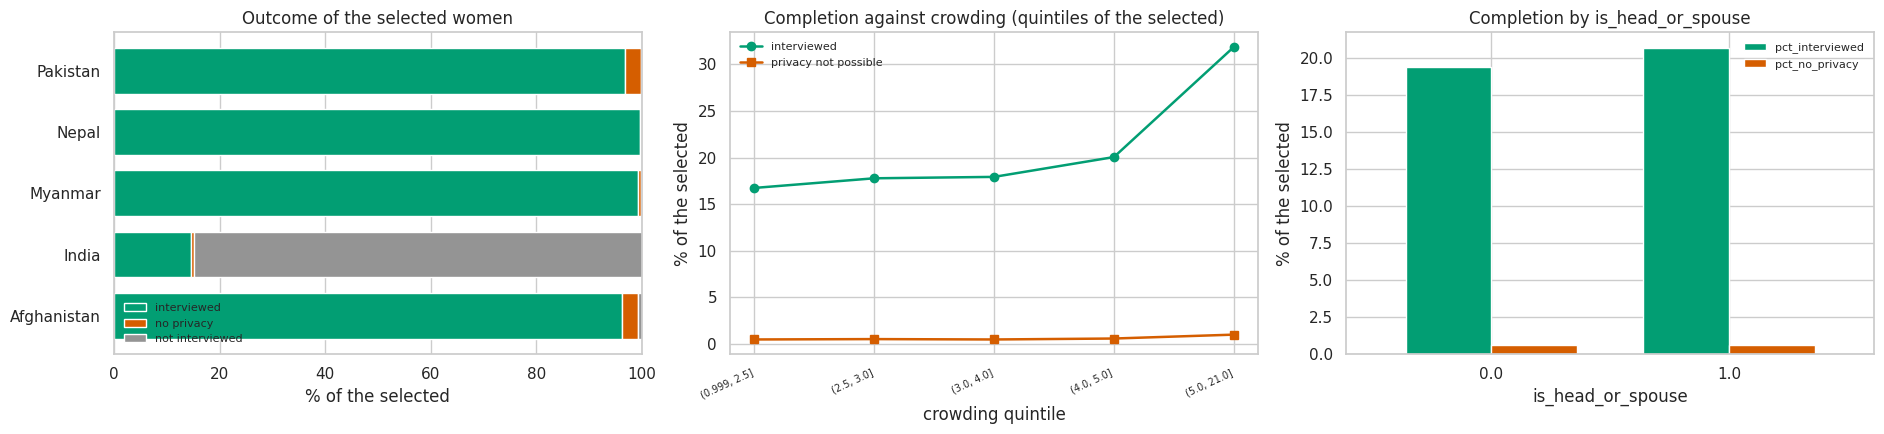

  y_completed  | Logistic regression      ROC-AUC 0.7350  PR-AUC 0.4340
  y_completed  | Random forest            ROC-AUC 0.7377  PR-AUC 0.4367


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  y_completed  | LightGBM                 ROC-AUC 0.7332  PR-AUC 0.4317

Conditional universe: 300,119 selected women, 20.37% interviewed, 18,417 clusters
  train 224,952 / test 75,167, 20.55% positive in the holdout
  interviewed | selected | Logistic regression ROC-AUC 0.6607  PR-AUC 0.5307
  interviewed | selected | Random forest   ROC-AUC 0.6600  PR-AUC 0.5272


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  interviewed | selected | LightGBM        ROC-AUC 0.6638  PR-AUC 0.5330


### The two secondary targets side by side

,target,model,roc_auc,pr_auc,f1,balanced_accuracy,positive_rate_true,n_train
0,y_completed (all women),Logistic regression,0.7350,0.4340,0.3459,0.6527,0.1406,"225,132"
1,y_completed (all women),Random forest,0.7377,0.4367,0.3476,0.6518,0.1406,"225,132"
2,y_completed (all women),LightGBM,0.7332,0.4317,0.3506,0.6461,0.1406,"225,132"
3,interviewed | selected,Logistic regression,0.6607,0.5307,0.4846,0.6603,0.2055,"224,952"
4,interviewed | selected,Random forest,0.6600,0.5272,0.4852,0.6605,0.2055,"224,952"
5,interviewed | selected,LightGBM,0.6638,0.5330,0.4749,0.6579,0.2055,"224,952"


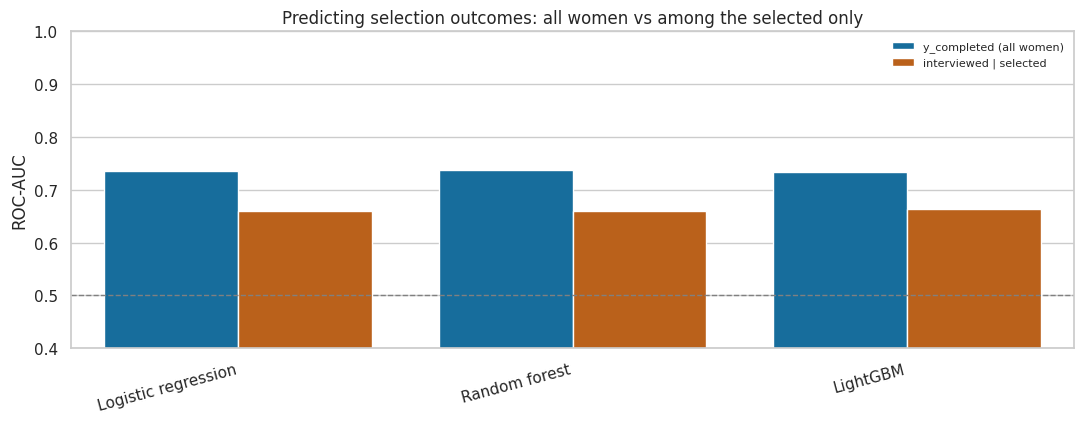

### Among the selected women, what predicts that the interview happened?
An odds ratio **below 1** marks a characteristic over-represented among the women who were selected but never interviewed — the profile that DV prevalence estimates from these surveys are missing.

,term,block,coefficient,odds_ratio_completion
62,country_India,country,-4.4027,0.012
64,country_Nepal,country,+3.6208,37.366
63,country_Myanmar,country,+1.8996,6.683
66,region_key_AF-1,country,-1.7388,0.176
68,region_key_AF-11,country,-1.6250,0.197
87,region_key_AF-3,country,-1.0293,0.357
188,marital_status_1.0,woman,+1.0272,2.793
162,region_key_PK-6,country,-0.9716,0.378
74,region_key_AF-17,country,+0.9367,2.551
160,region_key_PK-4,country,-0.8909,0.410


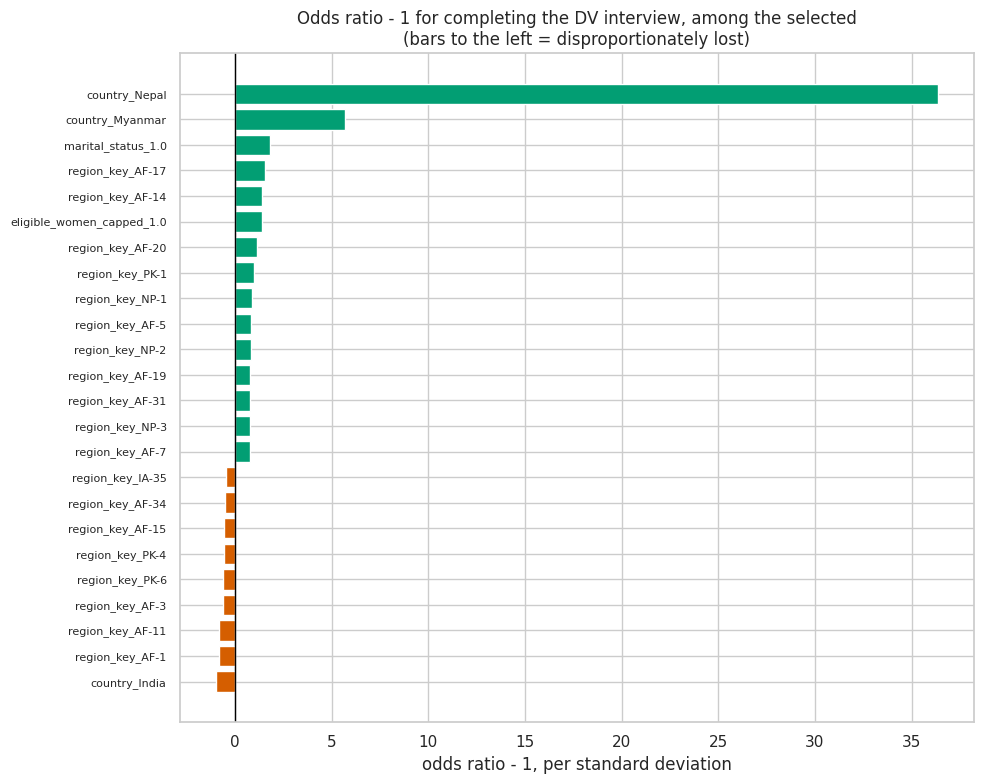

**0.60% of selected women could not be interviewed because privacy was not possible.** That is the single most consequential non-random loss in a DHS DV module: it is concentrated in exactly the household conditions — crowding, joint families, a woman who is neither head nor head's spouse — under which a woman is also least able to answer safely. Every prevalence figure in §16i should be read as an estimate for the households where a private interview was achievable.

18411

In [56]:
# ================================================================================================
# RECODE SOURCE
#   * Individual Recode (IR) - XXIRnnFL - one record per interviewed woman 15-49
#     (V044 = 1 interviewed / 2 no privacy / 3 not interviewed, among the selected)
# WHAT THIS CELL USES: ml_dataset, first for y_completed, then restricted to the selected women only.
# ================================================================================================
# 22a. Second target - who actually got a DV interview, and who was lost to privacy or non-response

SECOND_TARGET_LEARNERS = [
    ("Logistic regression", LogisticRegression(max_iter=3000, C=1.0, class_weight="balanced"), True),
    ("Random forest", RandomForestClassifier(n_estimators=300, max_depth=16, min_samples_leaf=25,
                                             class_weight="balanced_subsample", n_jobs=N_JOBS,
                                             random_state=RANDOM_SEED), False),
    (COUNTRY_LEARNER_NAME, country_learner(), False),
]

# --- 1. descriptive: what happened to the selected women? -----------------------------------------
selected_pool = ml_dataset[ml_dataset.V044.isin([1, 2, 3])].copy()
selected_pool["interview_completed"] = selected_pool.V044.eq(1).astype("int8")
print(f"Selected for the DV module: {len(selected_pool):,} women "
      f"({100 * len(selected_pool) / len(ml_dataset):.2f}% of the modelling universe)")

outcome_mix = summarise_groups(ml_dataset[ml_dataset.V044.isin([1, 2, 3])], "country", lambda g: {
    "n_selected": len(g),
    "pct_interviewed": 100 * g.V044.eq(1).mean(),
    "pct_no_privacy": 100 * g.V044.eq(2).mean(),
    "pct_not_interviewed": 100 * g.V044.eq(3).mean(),
    "pct_interviewed_weighted": weighted_share(g.V044.eq(1).astype("float32"), g.w_ind, 1),
})
display(Markdown("### Of the women selected for the module, what share produced an interview?"))
display(outcome_mix.style.format({
    "n_selected": "{:,.0f}", "pct_interviewed": "{:.2f}", "pct_no_privacy": "{:.2f}",
    "pct_not_interviewed": "{:.2f}", "pct_interviewed_weighted": "{:.2f}"}))
outcome_mix.to_csv(OUTPUT_DIR / "selected_interview_outcome_by_country.csv")

fig, axes = plt.subplots(1, 3, figsize=(19, 4.5))
outcome_mix[["pct_interviewed", "pct_no_privacy", "pct_not_interviewed"]].plot(
    kind="barh", stacked=True, ax=axes[0], width=0.75,
    color=[PALETTE[2], PALETTE[3], PALETTE[7 % len(PALETTE)]])
axes[0].set_title("Outcome of the selected women"); axes[0].set_xlabel("% of the selected")
axes[0].set_ylabel(""); axes[0].set_xlim(0, 100)
axes[0].legend(["interviewed", "no privacy", "not interviewed"], fontsize=8, frameon=False,
               loc="lower left")

crowd_feature = "crowding" if "crowding" in selected_pool.columns else "hh_size"
if crowd_feature in selected_pool.columns:
    bins = pd.qcut(selected_pool[crowd_feature], q=5, duplicates="drop")
    privacy_by_crowding = summarise_groups(
        selected_pool.assign(**{f"{crowd_feature}_q": bins}), f"{crowd_feature}_q", lambda g: {
            "n": len(g),
            "pct_interviewed": 100 * g.interview_completed.mean(),
            "pct_no_privacy": 100 * g.V044.eq(2).mean()})
    privacy_by_crowding = privacy_by_crowding[privacy_by_crowding.n.ge(MIN_UNWEIGHTED_CELL)]
    axes[1].plot(range(len(privacy_by_crowding)), privacy_by_crowding.pct_interviewed,
                 marker="o", color=PALETTE[2], linewidth=1.8, label="interviewed")
    axes[1].plot(range(len(privacy_by_crowding)), privacy_by_crowding.pct_no_privacy,
                 marker="s", color=PALETTE[3], linewidth=1.8, label="privacy not possible")
    axes[1].set_xticks(range(len(privacy_by_crowding)))
    axes[1].set_xticklabels([str(i) for i in privacy_by_crowding.index], rotation=25, ha="right",
                            fontsize=7)
    axes[1].set_title(f"Completion against {crowd_feature} (quintiles of the selected)")
    axes[1].set_xlabel(f"{crowd_feature} quintile"); axes[1].set_ylabel("% of the selected")
    axes[1].legend(fontsize=8, frameon=False)
    privacy_by_crowding.to_csv(OUTPUT_DIR / "privacy_by_crowding.csv")

role_feature = "is_head_or_spouse" if "is_head_or_spouse" in selected_pool.columns else "female_head"
if role_feature in selected_pool.columns:
    role_table = summarise_groups(selected_pool[selected_pool[role_feature].notna()],
                                  role_feature, lambda g: {
                                      "n": len(g),
                                      "pct_interviewed": 100 * g.interview_completed.mean(),
                                      "pct_no_privacy": 100 * g.V044.eq(2).mean()})
    role_table.plot(kind="bar", y=["pct_interviewed", "pct_no_privacy"], ax=axes[2],
                    color=[PALETTE[2], PALETTE[3]], width=0.72, legend=True)
    axes[2].set_title(f"Completion by {role_feature}")
    axes[2].set_xlabel(role_feature); axes[2].set_ylabel("% of the selected")
    axes[2].tick_params(axis="x", labelrotation=0)
    axes[2].legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

# --- 2. unconditional model for y_completed --------------------------------------------------------
second_rows = []
for learner_name, estimator, needs_scaling in SECOND_TARGET_LEARNERS:
    spec = {"name": learner_name, "estimator": estimator, "family": "y_completed (all women)",
            "scale": needs_scaling, "kernel": False,
            "numeric": ALL_NUMERIC, "categorical": ALL_CATEGORICAL}
    try:
        row, _, _, _, _ = fit_and_score(spec, train_df, test_df, target="y_completed")
        row["target"] = "y_completed (all women)"
        second_rows.append(row)
        print(f"  y_completed  | {learner_name:<24s} ROC-AUC {row['roc_auc']:.4f}  "
              f"PR-AUC {row['pr_auc']:.4f}")
    except Exception as exc:                                    # noqa: BLE001 - report, do not abort
        print(f"  y_completed  | {learner_name:<24s} FAILED: {type(exc).__name__}: {exc}")

# --- 3. conditional model: interviewed | selected --------------------------------------------------
# Among the selected only, so V138 no longer drives the outcome. Country stays in - fieldwork
# protocols differ by survey - but the design block is now just household context.
cond_pool = subsample(selected_pool, MODEL_SAMPLE_MAX, stratify_on=("country", "interview_completed"))
cond_train, cond_test = group_holdout(cond_pool, target="interview_completed")
print(f"\nConditional universe: {len(cond_pool):,} selected women, "
      f"{100 * cond_pool.interview_completed.mean():.2f}% interviewed, "
      f"{cond_pool.group_key.nunique():,} clusters")
print(f"  train {len(cond_train):,} / test {len(cond_test):,}, "
      f"{100 * cond_test.interview_completed.mean():.2f}% positive in the holdout")

cond_fitted, cond_pres = {}, {}
if cond_test.interview_completed.nunique() > 1 and len(cond_train) >= 500:
    for learner_name, estimator, needs_scaling in SECOND_TARGET_LEARNERS:
        spec = {"name": learner_name, "estimator": estimator,
                "family": "interviewed | selected", "scale": needs_scaling, "kernel": False,
                "numeric": ALL_NUMERIC, "categorical": ALL_CATEGORICAL}
        try:
            row, est, pre, _, _ = fit_and_score(spec, cond_train, cond_test,
                                                target="interview_completed")
            row["target"] = "interviewed | selected"
            second_rows.append(row)
            cond_fitted[learner_name] = est
            cond_pres[learner_name] = pre
            print(f"  interviewed | selected | {learner_name:<15s} ROC-AUC {row['roc_auc']:.4f}  "
                  f"PR-AUC {row['pr_auc']:.4f}")
        except Exception as exc:                                # noqa: BLE001 - report, do not abort
            print(f"  interviewed | selected | {learner_name:<15s} FAILED: "
                  f"{type(exc).__name__}: {exc}")
else:
    print("  Conditional model skipped: not enough variation among the selected women.")

second_target_results = pd.DataFrame(second_rows)
if not second_target_results.empty:
    display(Markdown("### The two secondary targets side by side"))
    display(second_target_results[["target", "model", "roc_auc", "pr_auc", "f1",
                                   "balanced_accuracy", "positive_rate_true", "n_train"]]
            .style.format({"roc_auc": "{:.4f}", "pr_auc": "{:.4f}", "f1": "{:.4f}",
                           "balanced_accuracy": "{:.4f}", "positive_rate_true": "{:.4f}",
                           "n_train": "{:,.0f}"})
            .background_gradient(subset=["roc_auc"], cmap="Greens"))
    second_target_results.to_csv(OUTPUT_DIR / "second_target_results.csv", index=False)

    plt.figure(figsize=(11, 4.4))
    sns.barplot(data=second_target_results, x="model", y="roc_auc", hue="target",
                palette=[PALETTE[0], PALETTE[3]])
    plt.axhline(0.5, color="grey", linestyle="--", linewidth=1.0)
    plt.title("Predicting selection outcomes: all women vs among the selected only")
    plt.ylabel("ROC-AUC"); plt.xlabel(""); plt.ylim(0.4, 1.0)
    plt.xticks(rotation=15, ha="right"); plt.legend(fontsize=8, frameon=False)
    plt.tight_layout(); plt.show()

# --- 4. who is lost? odds ratios from the conditional logit ---------------------------------------
if "Logistic regression" in cond_fitted:
    cond_logit = cond_fitted["Logistic regression"]
    cond_names = expanded_feature_names(cond_pres["Logistic regression"])
    cond_coefs = cond_logit.coef_.ravel()
    lost_profile = pd.DataFrame({
        "term": cond_names,
        "coefficient": cond_coefs,
        "odds_ratio_completion": np.exp(cond_coefs),
        "abs_coefficient": np.abs(cond_coefs)})
    lost_profile["feature"] = lost_profile.term.map(base_feature_of)
    lost_profile["block"] = lost_profile.term.map(block_of)
    lost_profile = lost_profile.sort_values("abs_coefficient", ascending=False)
    display(Markdown("### Among the selected women, what predicts that the interview happened?\n"
                     "An odds ratio **below 1** marks a characteristic over-represented among the "
                     "women who were selected but never interviewed — the profile that DV prevalence "
                     "estimates from these surveys are missing."))
    display(lost_profile.head(30)[["term", "block", "coefficient", "odds_ratio_completion"]]
            .style.format({"coefficient": "{:+.4f}", "odds_ratio_completion": "{:.3f}"})
            .background_gradient(subset=["coefficient"], cmap="coolwarm",
                                 vmin=-float(np.abs(cond_coefs).max()),
                                 vmax=float(np.abs(cond_coefs).max())))
    lost_profile.to_csv(OUTPUT_DIR / "conditional_completion_odds_ratios.csv", index=False)

    plt.figure(figsize=(10, 8))
    show = lost_profile.head(24).sort_values("coefficient")
    plt.barh(show.term, show.odds_ratio_completion - 1.0,
             color=[PALETTE[2] if c > 0 else PALETTE[3] for c in show.coefficient])
    plt.axvline(0, color="black", linewidth=1.0)
    plt.title("Odds ratio - 1 for completing the DV interview, among the selected\n"
              "(bars to the left = disproportionately lost)")
    plt.xlabel("odds ratio - 1, per standard deviation"); plt.yticks(fontsize=8)
    plt.tight_layout(); plt.show()

    NO_PRIVACY_SHARE = 100 * selected_pool.V044.eq(2).mean()
    display(Markdown(
        f"**{NO_PRIVACY_SHARE:.2f}% of selected women could not be interviewed because privacy was "
        f"not possible.** That is the single most consequential non-random loss in a DHS DV module: "
        f"it is concentrated in exactly the household conditions — crowding, joint families, a woman "
        f"who is neither head nor head's spouse — under which a woman is also least able to answer "
        f"safely. Every prevalence figure in §16i should be read as an estimate for the households "
        f"where a private interview was achievable."))
gc.collect()

## 23. Synthesis — answering the research question

> **What distinct demographic and socioeconomic profiles of women and households can be identified
> across South Asian countries, how do these profiles interact, and to what extent are their
> combinations associated with household selection for the DHS domestic-violence module?**

The question has four parts, and each has been given its own machinery rather than being answered by
one number:

| Part | Where it was answered | The instrument |
|---|---|---|
| **1. Profiles** | §18a–§18b | PCA on the pooled, design-free feature space, then KMeans and a Gaussian mixture over the retained components, with K chosen by silhouette and BIC rather than by hand. |
| **2. Interactions** | §20c | 16 engineered two-way products, two-way partial dependence on the fitted model, and an interaction logit with Wald intervals — plus a held-out test of whether the products add anything an additive model cannot get. |
| **3. Cross-country variation** | §18c, §21a, §21b | Weighted profile mix per country, one model per country with its own design baseline, importance-rank agreement between countries, and leave-one-country-out transfer. |
| **4. DV-module selection** | §16h, §19, §20a, §22 | Bivariate selection rates against the design expectation, the full model zoo, the nested block ladder measured as ΔAUC over design + country, and the split of `V044` into *selected* and *interviewed*. |

### What the design forces us to conclude

`V044` is a **sampling flag**, so the honest form of part 4 is not "how well can we predict
selection" but "**how much does knowing a woman's profile add to what the sampling rule already
tells us**". Under the DHS design,

$$P(\text{selected}) = P(\text{household in the DV sub-sample}) \times \frac{1}{V138},$$

so a near-zero profile gain over the design-only model is the *expected and reassuring* result: it
means the DV sub-sample is close to design-conditionally random with respect to who women are. A
large gain would be the finding that undermines published prevalence estimates.

The one place where a profile effect is both expected and consequential is **§22's conditional
model** — completion *given* selection. There the design has already done its work, and anything the
model finds is fieldwork reality: privacy that could not be obtained, women who could not be
revisited.

### What the cell below prints

A single consolidated answer assembled from the objects computed above — the profile list, the
interaction verdict, the cross-country verdict, the selection verdict — followed by a manifest of
every CSV written to `OUTPUT_DIR`, so the numbers quoted in a write-up can be traced back to the
table that produced them.

In [57]:
# ================================================================================================
# RECODE SOURCE
#   * Individual Recode (IR) - XXIRnnFL - one record per interviewed woman 15-49
#     (with the household block DHS carries into the IR file; HR and PR results come from Part I)
# WHAT THIS CELL USES: every table built above. Writes nothing new to disk except the manifest.
# ================================================================================================
# 23a. Consolidated answer to the research question, plus the export manifest

SECTION_RULE = "=" * 100


def section(title):
    print(f"\n{SECTION_RULE}\n{title}\n{SECTION_RULE}")


section("RESEARCH QUESTION")
print("What distinct demographic and socioeconomic profiles of women and households can be")
print("identified across South Asian countries, how do these profiles interact, and to what extent")
print("are their combinations associated with household selection for the DHS domestic-violence")
print("module?")

# --- Part 1: the profiles -------------------------------------------------------------------------
section("PART 1 - PROFILES")
print(f"Feature space : {len(PROFILE_NUMERIC)} numeric + {len(PROFILE_CATEGORICAL)} categorical "
      f"characteristics, design variables deliberately excluded")
print(f"PCA           : {N_PCA_COMPONENTS} components retained "
      f"({100 * explained.cumulative.iloc[N_PCA_COMPONENTS - 1]:.1f}% of variance)")
print(f"K selection   : silhouette best at k={BEST_K_SILHOUETTE}, GMM BIC best at k={BEST_K_BIC}, "
      f"K used = {N_PROFILES}")
print(f"Fitted on     : {len(cluster_frame):,} women; assigned to all {len(ml_dataset):,}\n")
for code in sorted(PROFILE_NAMES):
    share = 100 * (ml_dataset.profile_km == code).mean()
    sel = profile_selection.loc[PROFILE_NAMES[code], "pct_selected"] \
        if PROFILE_NAMES[code] in profile_selection.index else np.nan
    excess = profile_selection.loc[PROFILE_NAMES[code], "excess_over_design_pp"] \
        if PROFILE_NAMES[code] in profile_selection.index else np.nan
    print(f"  {PROFILE_NAMES[code]:<58s} {share:5.1f}% of women   "
          f"selected {sel:5.2f}%   vs design {excess:+5.2f} pp")

dominant = (ml_dataset.groupby("country", observed=True)["profile_name"]
            .agg(lambda s: s.value_counts().idxmax()))
print("\nMost common profile in each country:")
for country, name in dominant.items():
    print(f"  {country:<12s} {name}")

# --- Part 2: interactions -------------------------------------------------------------------------
section("PART 2 - INTERACTIONS")
if "inter_only" in globals() and len(inter_only):
    strongest = inter_only.reindex(inter_only.coefficient.abs().sort_values(ascending=False).index)
    print(f"{len(inter_only)} engineered two-way products were tested; "
          f"{int(inter_only.significant_5pct.sum())} reach the 5% level "
          f"(n = {len(logit_train):,}, so read the size, not the p-value).")
    print("\nLargest interaction effects, as odds ratios per standard deviation of the product:")
    for _, r in strongest.head(8).iterrows():
        direction = "raises" if r.odds_ratio > 1 else "lowers"
        print(f"  {r.term:<28s} OR {r.odds_ratio:6.3f}  [{r.ci_low:.3f}, {r.ci_high:.3f}]  "
              f"{direction} the odds of selection")
if "interaction_gain" in globals() and len(interaction_gain) == 2:
    d_roc = interaction_gain.roc_auc.iloc[1] - interaction_gain.roc_auc.iloc[0]
    d_pr = interaction_gain.pr_auc.iloc[1] - interaction_gain.pr_auc.iloc[0]
    print(f"\nHeld-out test: adding the products to an additive logit moves ROC-AUC {d_roc:+.4f} "
          f"and PR-AUC {d_pr:+.4f}.")
    print("  -> " + ("the interactions carry information the additive model cannot reach."
                     if d_roc > 0.002 else
                     "the interactions add essentially nothing beyond the main effects, so the "
                     "profile characteristics act additively here."))
if "ladder" in globals() and "interaction" in set(ladder.block_added):
    inter_step = ladder[ladder.block_added.eq("interaction")]
    print("\nSame conclusion from the block ladder:")
    for _, r in inter_step.iterrows():
        print(f"  {r.learner:<24s} delta ROC-AUC {r.delta_roc_auc:+.4f}, "
              f"delta PR-AUC {r.delta_pr_auc:+.4f} from the interaction block")

# --- Part 3: cross-country variation --------------------------------------------------------------
section("PART 3 - CROSS-COUNTRY VARIATION")
print(f"Countries modelled: {', '.join(sorted(ml_dataset.country.unique()))}")
print(f"Countries with a fielded DV module but excluded from modelling: "
      f"{sorted(set(DV_PREVALENCE_COUNTRIES) - set(MODEL_COUNTRIES)) or 'none'}")
if "country_models" in globals() and len(country_models):
    print("\nWithin-country models (identical learner and features):")
    for _, r in country_models.iterrows():
        print(f"  {r.country:<12s} ROC-AUC {r.roc_auc:.4f}  design {r.design_roc_auc:.4f}  "
              f"profile gain {r.profile_gain_roc:+.4f}  (n_train {r.n_train:,.0f})")
    print(f"\nProfile gain ranges from {country_models.profile_gain_roc.min():+.4f} to "
          f"{country_models.profile_gain_roc.max():+.4f} ROC-AUC across countries.")
if "rank_corr" in globals():
    off_diag = rank_corr.where(~np.eye(len(rank_corr), dtype=bool)).stack()
    print(f"Countries' importance rankings agree at Spearman rho = {off_diag.mean():.3f} on average "
          f"(range {off_diag.min():.3f} to {off_diag.max():.3f}).")
if "loco" in globals() and len(loco):
    print(f"\nLeave-one-country-out transfer penalty: mean {loco.transfer_penalty_roc.mean():+.4f} "
          f"ROC-AUC; transferred gain over design {loco.transfer_gain_over_design.mean():+.4f}.")
if "weighted_mix" in globals():
    spread = (weighted_mix.max(axis=0) - weighted_mix.min(axis=0)).sort_values(ascending=False)
    print("\nProfiles whose weighted share varies most between countries (percentage points):")
    for name, gap in spread.head(4).items():
        print(f"  {name:<58s} {gap:5.1f} pp")

# --- Part 4: DV-module selection ------------------------------------------------------------------
section("PART 4 - ASSOCIATION WITH DV-MODULE SELECTION")
print(f"Universe      : {len(ml_dataset):,} women 15-49 in {ml_dataset.country.nunique()} countries")
print(f"Selected      : {int(ml_dataset.y_selected.sum()):,} "
      f"({100 * ml_dataset.y_selected.mean():.2f}%)")
print(f"Interviewed   : {int(ml_dataset.y_completed.sum()):,} "
      f"({100 * ml_dataset.y_completed.mean():.2f}%)")
print(f"Design rule   : P(selected) = P(household in the DV sub-sample) x 1 / V138, "
      f"mean V138 = {ml_dataset.n_eligible_women.mean():.2f}")
if "model_results" in globals() and len(model_results):
    print(f"\nBest of {int(model_results.pr_auc.notna().sum())} learners: {BEST_MODEL_NAME}")
    best_row = model_results.loc[model_results.pr_auc.idxmax()]
    print(f"  ROC-AUC {best_row.roc_auc:.4f}, PR-AUC {best_row.pr_auc:.4f} on held-out clusters "
          f"(no-skill PR-AUC = {test_df[TARGET].mean():.4f})")
if "verdict" in globals() and len(verdict):
    print("\nThe number that answers part 4 - gain over design + country:")
    for _, r in verdict.iterrows():
        print(f"  {r.learner:<24s} design+country ROC-AUC {r.design_plus_country_roc:.4f} -> "
              f"full {r.full_model_roc:.4f}   profile gain {r.profile_gain_roc:+.4f}")
    mean_gain = verdict.profile_gain_roc.mean()
    print(f"\n  Mean profile gain: {mean_gain:+.4f} ROC-AUC.")
    if abs(mean_gain) < 0.01:
        print("  -> Profiles are at most weakly associated with selection once the design and country")
        print("     are known. DHS DV sub-sample assignment behaves as a probability sample should:")
        print("     it is the household's number of eligible women, not who the woman is, that")
        print("     decides selection.")
    else:
        print("  -> Profiles are associated with selection beyond the design. The permutation and")
        print("     odds-ratio tables in 20b/20c name which characteristics carry that association,")
        print("     and it should be treated as differential coverage of the DV sub-sample.")
if "perm_by_block" in globals() and len(perm_by_block):
    print("\nPermutation importance by block (drop in ROC-AUC when the block is shuffled):")
    for block, r in perm_by_block.iterrows():
        print(f"  {block:<14s} total {r.total_drop:+.5f}   largest single column {r.max_drop:+.5f}")
if "second_target_results" in globals() and len(second_target_results):
    cond = second_target_results[second_target_results.target.eq("interviewed | selected")]
    if len(cond):
        print(f"\nAmong the SELECTED women, predicting whether the interview happened reaches "
              f"ROC-AUC {cond.roc_auc.max():.4f}.")
        print("  This is the substantively important selection effect: the design is already fixed,")
        print("  so it is fieldwork - privacy and non-response - that removes a non-random group.")
if "NO_PRIVACY_SHARE" in globals():
    print(f"  Privacy could not be obtained for {NO_PRIVACY_SHARE:.2f}% of the selected women.")

# --- limits, stated plainly -----------------------------------------------------------------------
section("LIMITS OF THIS ANALYSIS")
limits = [
    "V044 is a sampling flag, not an experience of violence. Nothing here estimates who is abused.",
    "Profiles are descriptive clusters in a PCA space, not latent classes with a measurement model.",
    "Selection is a household-level event; women in the same household share it, so cluster-aware "
    "splitting is necessary but does not fully remove within-household dependence.",
    f"Sample sizes are extremely unequal (India dominates), and the compute budget subsamples: "
    f"MODEL_SAMPLE_MAX={MODEL_SAMPLE_MAX:,}, KERNEL_SAMPLE_MAX={KERNEL_SAMPLE_MAX:,}. Every table "
    f"reports the n it used.",
    f"Countries excluded from modelling for a missing or unfielded V044: "
    f"{sorted(set(ir_structure.country) - set(MODEL_COUNTRIES)) if 'ir_structure' in globals() else 'n/a'}.",
    "Model metrics are unweighted. Survey weights are used for every descriptive estimate but are "
    "not applied to the learners, so predictive performance describes the sample, not the population.",
]
for i, item in enumerate(limits, start=1):
    print(f"{i}. {item}")

# --- export manifest ------------------------------------------------------------------------------
section("EXPORT MANIFEST")
exports = sorted(Path(OUTPUT_DIR).glob("*.csv"))
manifest = pd.DataFrame({
    "file": [p.name for p in exports],
    "size_kb": [round(p.stat().st_size / 1024, 1) for p in exports],
})
print(f"{len(manifest)} CSV files written to {OUTPUT_DIR}")
display(manifest)
manifest.to_csv(Path(OUTPUT_DIR) / "_manifest.csv", index=False)
print("\nAnalysis complete: Part I (HR + PR recodes, sections 1-13) and Part II (IR recode, "
      "sections 14-23).")


RESEARCH QUESTION
What distinct demographic and socioeconomic profiles of women and households can be
identified across South Asian countries, how do these profiles interact, and to what extent
are their combinations associated with household selection for the DHS domestic-violence
module?

PART 1 - PROFILES
Feature space : 51 numeric + 5 categorical characteristics, design variables deliberately excluded
PCA           : 19 components retained (81.2% of variance)
K selection   : silhouette best at k=3, GMM BIC best at k=10, K used = 6
Fitted on     : 199,853 women; assigned to all 796,374

  P0: middle rural no/low-education high-parity               20.3% of women   selected 75.00%   vs design +4.04 pp
  P1: richer urban higher-education                           16.7% of women   selected 78.75%   vs design +1.06 pp
  P2: middle rural secondary                                  23.4% of women   selected 76.95%   vs design -0.49 pp
  P3: poorer rural secondary never-married            

,file,size_kb
0,analysis_missingness.csv,3.7
1,archive_inventory.csv,1.3
2,block_level_importance.csv,1.1
3,cluster_k_selection.csv,0.9
4,complete_data_dictionary.csv,5148.4
5,conditional_completion_odds_ratios.csv,18.7
6,country_wise_DV_domain_comparison.csv,4.0
7,country_wise_DV_items_answered_distribution.csv,2.2
8,country_wise_DV_question_answer_dashboard.csv,16.0
9,country_wise_female_field_completeness.csv,1.3



Analysis complete: Part I (HR + PR recodes, sections 1-13) and Part II (IR recode, sections 14-23).
